# TOR PDF Extractor → JSON (VS Code lokal / Windows)

**Persiapan (sekali saja):** Python 3.10–3.12, VS Code + ekstensi **Python** & **Jupyter**; virtual environment `python -m venv .venv` lalu pilih
kernel **.venv** (kanan atas). Tesseract terpasang di `C:\Program Files\Tesseract-OCR\` dengan bahasa **Indonesian (ind)**. Deskripsi gambar
dengan VLM Qwen3-VL-2B (bagian 23) opsional: butuh GPU NVIDIA (≥ 8 GB VRAM) + PyTorch CUDA.

**Urutan pakai:**
1. Bagian **0** — pasang paket (sekali), *Restart* kernel, cek Tesseract & GPU.
2. Bagian **1–23** — definisi (tidak memproses apa pun): jalankan semua.
3. Bagian **24** — salin PDF ke `samples/` → ekstrak semua → deskripsi gambar VLM (opsional) → statistik panjang → zip. Hasil di `output_json/`.

Folder kerja = folder notebook. Riwayat perubahan: `CHANGELOG.md`.

## 0. Setup lokal
Pasang paket Python (tanpa `apt-get`), lalu periksa Tesseract (lokasi + bahasa `ind`) dan GPU.

In [1]:
# Paket inti (sekali saja). Setelah selesai: Restart kernel (toolbar notebook), lalu lanjut ke sel berikutnya.
%pip install -q pdfplumber pypdfium2 pillow numpy opencv-python-headless pytesseract pandas tabulate lxml matplotlib

# OPSIONAL — hanya untuk deskripsi gambar VLM Qwen3-VL-2B (bagian 23) dengan GPU NVIDIA. Hapus tanda # lalu jalankan:
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124     # sesuaikan cu121/cu124/cu126 dengan driver
# %pip install -U "transformers>=4.57" accelerate
# Statistik panjang dengan tokenizer model (bagian 24.4) cukup: %pip install transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, subprocess, shutil
TESSERACT_CMD = r"C:\Program Files\Tesseract-OCR\tesseract.exe"      # lokasi tesseract.exe di komputer Anda
if not os.path.isfile(TESSERACT_CMD) and shutil.which("tesseract"):
    TESSERACT_CMD = shutil.which("tesseract")
print("tesseract:", TESSERACT_CMD, "" if os.path.isfile(TESSERACT_CMD) else "← TIDAK DITEMUKAN, periksa path di atas")
try:
    langs = subprocess.run([TESSERACT_CMD, "--list-langs"], capture_output=True, text=True).stdout.splitlines()[1:]   # baris 1 = judul
    print("bahasa:", langs)
    if "ind" not in langs:
        print("⚠ bahasa 'ind' belum terpasang → unduh ind.traineddata dari https://github.com/tesseract-ocr/tessdata ke",
              os.path.join(os.path.dirname(TESSERACT_CMD), "tessdata"), "(butuh hak administrator), atau jalankan ulang installer dan centang Indonesian.")
except Exception as e:
    print("tesseract tidak bisa dijalankan:", e)
try:
    import torch
    print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
          else "TIDAK ADA (VLM bagian 23 dilewati otomatis; ekstraksi Tier 0 + Tesseract tetap jalan)")
except Exception as e:
    print("PyTorch belum terpasang — hanya diperlukan untuk VLM:", repr(e)[:120])

tesseract: C:\Program Files\Tesseract-OCR\tesseract.exe 
bahasa: ['eng', 'ind', 'osd']
PyTorch 2.11.0+cpu | GPU: TIDAK ADA (VLM bagian 23 dilewati otomatis; ekstraksi Tier 0 + Tesseract tetap jalan)


# Pustaka ekstraktor
Ekstraktor dokumen **TOR/KAK** berformat **PDF** → **JSON detail** (sumber kebenaran) + keluaran turunan:
laporan HTML, format LLM lama (per section), **checklist berbasis aturan** 25 butir, dan **LLM2** (isi bagian I.M.1–I.R yang judulnya ditemukan,
untuk dinilai kelogisannya oleh model).

| Bagian | Isi |
|---|---|
| 1–5 | konfigurasi, model data, utilitas, aset, kata & baris |
| 6–13 | deteksi: tabel, figure, tanda tangan, gabung tabel lintas halaman, alur teks, formulir label : nilai, OCR scan, watermark |
| 14–15 | pipeline utama `extract_pdf` & validasi |
| 16–22 | keluaran: HTML, format LLM lama, checklist, outline & LLM2, diagnostik, `extract_folder` |
| 23 | deskripsi gambar dengan VLM Qwen3-VL-2B, opsional (GPU) |
| 24 | jalankan |

Dependensi berlisensi permisif (boleh komersial): pdfplumber/pdfminer.six (MIT), pypdfium2 (Apache-2.0/BSD), Pillow, numpy, OpenCV (Apache-2.0),
pytesseract/Tesseract (Apache-2.0), pandas + tabulate + lxml. PyMuPDF tidak dipakai (AGPL). Riwayat perubahan: `CHANGELOG.md`.

## 1. Import & konfigurasi
Semua ambang yang bisa di-*tuning* ada di `CFG`. Satuan geometri: **poin PDF (1/72 inci)**, titik asal kiri-atas (konvensi pdfplumber).
`EXTRACTOR_VERSION` dicetak di `explain_page` dan disimpan di setiap keluaran.

In [3]:
import io, re, json, hashlib, datetime, math, statistics, importlib.util
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Optional, Tuple, Dict, Any

import numpy as np
import bisect
import difflib
import pdfplumber
import pypdfium2 as pdfium
from PIL import Image
from pdfminer.pdftypes import resolve1

SCHEMA_VERSION = "1.1"
EXTRACTOR_VERSION = "2026-11-18.biaya-v23.1"        # dicetak di explain_page & disimpan di output agar jelas versi mana yang berjalan

CFG = {
    "render_dpi": 200,               # render halaman untuk crop aset
    "scanned_min_chars": 40,         # < ini karakter native -> halaman dianggap scan (diserahkan ke OCR, langkah 4)
    "table_settings": {              # pdfplumber.find_tables; tepi 'rect' tipis ikut dihitung sebagai garis
        "vertical_strategy": "lines", "horizontal_strategy": "lines",
        "snap_tolerance": 3, "join_tolerance": 3, "edge_min_length": 3, "intersection_tolerance": 3,
    },
    "edge_slant_tol": 1.5,           # garis dengan selisih koordinat <= ini (pt) tetap dianggap lurus (pembulatan koordinat)
    "edge_link_gap": 7.0,            # garis yang berjarak <= ini (pt) dianggap satu struktur (kandidat tabel)
    "grid_tol": 3.0,                 # toleransi pengelompokan garis grid (pt)
    "wall_frac": 0.6,                # tepi sel dianggap berdinding bila >= 60% panjangnya tertutup garis
    "align_gap": 4.0,                # baris sejajar kolom tabel dihitung bila jaraknya <= ini x tinggi baris dari tabel
    "carry_min_bottom": 0.6,         # tabel yang berakhir di bawah 60% tinggi halaman dianggap bisa berlanjut ke halaman berikutnya
    "sig_min_conf": 0.6,             # tanda tangan dengan keyakinan di bawah ini ditandai needs_review
    "debug": False,                  # True = simpan catatan diagnostik per halaman (pages[i]["debug"])
    "edge_tol": 2.5,                 # toleransi pengelompokan tepi sel (pt)
    "box_min_words": 6,              # kotak <=2 sel dengan >= kata ini dianalisis sebagai kotak-tanpa-garis-dalam
    "ws_min_rows": 3,                # minimal baris bermulti-kolom agar dianggap tabel (whitespace)
    "ws_gap_chars": 2.0,             # lebar celah kolom minimal (x lebar karakter median)
    "ws_min_gap_pt": 6.0,            # ... dan minimal sekian pt
    "ws_allow_frac": 0.08,           # fraksi baris yang boleh 'melintasi' celah (judul/colspan)
    "xpage_bottom": 0.55, "xpage_top": 0.45, "xpage_col_tol": 0.04, "xpage_col_tight": 0.012,   # tabel lintas halaman
    "rule_max_pt": 6.0,              # persegi berisi PATTERN / gelap setebal <= ini (dan panjang >= 4x tebal) = garis tebal/ganda tabel
    "sliver_col_pt": 10.0,           # kolom tabel bergaris selebar <= ini (dan <= setengah median) yang tak pernah jadi sel tersendiri → dilebur
    "scanned_image_ratio": 0.5,      # halaman scan = sedikit teks DAN gambar yang menutup >= 50% halaman
    "rule_min_width": 80,            # garis horizontal minimal selebar ini (pt) dianggap garis tabel
    "margin_top": 0.08, "margin_bottom": 0.07,                         # zona kop/kaki halaman (proporsi tinggi)
    # --- figure ---
    "min_image_pt": (20, 15),        # gambar raster lebih kecil dari ini diabaikan
    "page_bg_ratio": 0.85,           # gambar >= 85% halaman = latar halaman/scan, bukan figure
    "fig_gap": 6.0,                  # jarak maks antar primitif vektor agar satu klaster
    "fig_min_prims": 6, "fig_min_curves": 3, "fig_min_size": (40, 25),
    "cell_fig_min_size": (8, 3),     # figure di dalam sel tabel (mis. tanda tangan vektor) boleh lebih kecil
    "fig_pad": (28, 24, 10, 18),     # (kiri, atas, kanan, bawah) area label sumbu/legenda yang ikut disembunyikan
    "fig_label_max_chars": 40,
    "fig_connector_len": 60.0,       # garis tipis / kotak kosong sepanjang ini = "penghubung": hanya ikut klaster yang ukurannya sebanding, tidak boleh merangkai klaster
    "fig_connector_ratio": 1.3,      # penghubung ikut klaster bila panjangnya <= rasio ini x bentang inti klaster (+ 2*fig_gap)
    "prim_in_table_frac": 0.6,       # primitif dianggap milik tabel bila >= porsi ini berada di area tabel (bukan hanya titik tengah)
    "mask_tokens": True,             # token samaran "[MASKED …]" digabung & dipersempit selebar 1 karakter di posisi awalnya (tidak meluber ke kolom lain)
    "mask_token_text": None,         # None = teks token dipertahankan; mis. "X" = teks token diganti (nama/NIP tersamar lalu tak terdeteksi sebagai nama)
    "word_visible_contrast": 60,     # selisih persentil 3–97 (skala abu 0–255) pada kotak kata: di bawah ini kata tertutup (mask) → tidak pernah diambil
    "fig_text_prose_min_words": 5,   # baris "prosa" di dalam figure: >= 5 kata dan >= 30 karakter
    "fig_text_review_words": 30,     # figure berisi >= sekian kata → review
    "fig_large_ratio": 0.5,          # figure >= 50% luas halaman → review
    "text_image_ink_in_words": 0.8,  # gambar raster dengan >= 80% tintanya di bawah kotak kata native = "gambar teks" (bukan figure)
    "text_image_pad_pt": 1.5,        # kotak kata diperlebar sekian pt (pergeseran kecil antara gambar dan text layer)
    # --- formulir label : nilai (9a) ---
    "unsigned_min_gap": 28.0, "unsigned_max_gap": 120.0,   # slot tanda tangan kosong: ruang kosong jabatan→nama (pt)
    "unsigned_max_ink": 0.003,       # ruang berisi objek PDF tetapi tinta tampak < 0,3% = kosong (gambar putih / tanda tangan dihapus)
    "kv_empty_max_words": 4,         # 'Label :' tanpa nilai hanya kv bila labelnya <= 4 kata (lebih panjang = kalimat pengantar "… berikut:")
    "kv_min_rows": 2,                # minimal rekaman berpemisah sejajar
    "kv_sep_tol": 4.0,               # toleransi x pemisah antar baris (pt)
    "kv_label_tol": 8.0,             # toleransi x awal label (pt)
    "kv_val_tol": 4.0,               # baris lanjutan nilai harus mulai >= x awal nilai - toleransi ini
    "kv_cont_gap": 1.2,              # jarak vertikal maks baris lanjutan nilai (x tinggi baris)
    "kv_label_gap": 0.9,             # jarak vertikal maks baris lanjutan label (lebih ketat)
    "kv_label_wrap_fill": 0.6,       # baris label dianggap terbungkus bila baris sebelumnya mengisi >= 60% lebar kolom label
    "kv_max_row_gap": 3.0,           # jarak vertikal maks antar rekaman (x tinggi baris); lebih jauh = formulir baru
    "page_fig_words_ratio": 0.25, "page_fig_words_min": 15,   # >= 25% (dan >= 15) kata halaman berada di figure.text → peringatan halaman + review
    # --- watermark (9c) ---
    "watermark": True,               # False = matikan deteksi watermark
    "wm_axis_tol_deg": 5.0,          # karakter dengan sudut > 5° dari sumbu (0/90/180/270) = diagonal
    "wm_diag_min_size": 14.0,        # ... dan ukuran >= ini (pt)
    "wm_char_min_size": 36.0, "wm_char_big_ratio": 2.5,   # karakter tegak raksasa (>= max(36, 2.5 x ukuran median)) ...
    "wm_light_lum": 0.6,             # ... dan berwarna terang (luminans >= 0.6) = watermark
    "wm_min_chars": 3,               # minimal karakter watermark per halaman
    "wm_min_obj_pt": 10.0,           # kurva lebih kecil dari ini (pt) tidak dinilai
    "wm_ink_level": 235,             # piksel < ini (0–255) dihitung tinta
    "wm_min_ink_px": 40,
    "wm_faded_median": 165,          # tinta pudar: median >= 165 ...
    "wm_faded_dark": 0.15,           # ... dan porsi piksel gelap (< 110) <= 15%
    "wm_group_gap": 20.0,            # jarak kurva pudar agar satu kelompok watermark (pt)
    "wm_min_area": 0.04,             # kelompok/gambar watermark minimal 4% luas halaman ...
    "wm_min_chars_over": 3,          # ... dan menumpuk >= 3 karakter teks
    "wm_big_area": 0.12,             # ... atau seluas >= 12% halaman
    "sig_cert_names": False,         # True: nama dari kamus /Sig & sertifikat (subjek/penerbit) disimpan di meta tanda tangan digital — data TERSEMBUNYI, bisa nama asli dokumen tersamar
    "llm_sig_table_max_rows": 8,     # tabel berisi tanda tangan dengan <= sekian baris = tabel blok tanda tangan → hanya ringkasan keberadaan
    "llm_long_chars": 6000,
    "llm2_long_tokens": 4096,        # pratinjau HTML LLM2: bagian lebih panjang dari ini (perkiraan token) ditandai
    "scribble_min_diag": 3,          # v22.5: grid "mirip grafik" yang memuat >= sekian garis MIRING = penutup/coretan tanda tangan → bukan tabel
    "vector_figures": False,         # False: gambar VEKTOR (grafik/diagram dari garis & bidang berwarna) tidak dijadikan figure — TOR asli hampir tak pernah
                                     #   memakainya dan header/sel berwarna sering salah terbaca sebagai grafik. Kurva vektor tetap diperiksa sebagai tanda
                                     #   tangan/penutup; gambar RASTER tetap figure (aset); halaman scan tidak terpengaruh. True = perilaku lama.          # laporan HTML format LLM: context lebih panjang dari ini ditandai (pertimbangkan chunking)
    "llm_category": "TOR",           # nilai "category" pada keluaran format LLM (bisa diganti per pemanggilan to_llm_records(category=...))
    "asset_subdir": "assets",
}

BOLD_RE = re.compile(r"bold|black|heavy|semibold|demi", re.I)
CAPTION_RE = re.compile(r"^\s*(gambar|grafik|diagram|bagan|chart|figure|fig\.?)\s*\d+", re.I)
MARKER_RE = re.compile(r"^(\d{1,2}[\.\)]|[a-zA-Z][\.\)]|[-•●▪*])$")
SIG_LABEL_RE = re.compile(r"tanda\s*tangan|\bt\.?t\.?d\b|ditandatangani|mengetahui|menyetujui|disetujui|disahkan|penanggung\s*jawab|pejabat\s*pembuat\s*komitmen|"
                          r"\bppk\b|kuasa\s*pengguna\s*anggaran|\bkpa\b|pengguna\s*anggaran|disusun\s*oleh|dibuat\s*oleh|pembuat\s+(tor|kak)|ketua\s+tim", re.I)
NIP_RE = re.compile(r"\bNIP\b\.?\s*[:.]?\s*(\d[\d\s]{9,24}\d)", re.I)
TTE_RE = re.compile(r"ditandatangani\s+secara\s+elektronik|tanda\s*tangan\s*elektronik|\bTTE\b|sertifikat\s+elektronik|\bBSrE\b|badan\s+siber\s+dan\s+sandi\s+negara|"
                    r"dokumen\s+ini\s+telah\s+ditandatangani|digitally\s+signed|electronically\s+signed", re.I)
DATEPLACE_RE = re.compile(r"^\s*[A-Z][A-Za-z .]{2,30},\s*\d{1,2}\s+\w+\s+\d{4}")
_PLACE_HEAD_RE = re.compile(r"^\s*(?P<place>[A-Z][A-Za-z .'-]{2,30}?)\s*,\s*(?P<rest>.*)$")
_ROLE_WORD_RE = re.compile(r"\b(kepala|ketua|direktur|sekretaris|pejabat|koordinator|kasubb?ag|kabag|kasubdit|kasi|deputi|asisten|inspektur|plt|plh|"
                           r"a\.?\s?n\.?|menteri|wakil|staf|anggota|kuasa|bendahara|penanggung|pengguna|tim|camat|lurah|bupati|wali\s*kota|gubernur|rektor|"
                           r"dekan|pimpinan|manajer|manager|kabid|kepala\s+bidang|pembuat|penyusun|pelaksana|mengetahui|menyetujui|disetujui|disusun|dibuat)\b", re.I)
_MONTHS_RE = re.compile(r"\b(januari|februari|maret|april|mei|juni|juli|agustus|september|oktober|nopember|november|desember|jan|feb|mar|apr|jun|jul|agu|agt|"
                        r"sep|okt|nov|des)\b", re.I)


def place_line(text: str) -> Optional[dict]:
    """Baris "Kota, tanggal" di atas tanda tangan, termasuk yang tanggalnya belum diisi / disamarkan ("Yogyakarta,", "Yogyakarta,      Oktober 2026",
    "Yogyakarta, 2026", "Yogyakarta, [MASKED DATA]"). Bukan jabatan ("Kepala Pusat,", "Mengetahui,"). → {place, date?} atau None."""
    m = _PLACE_HEAD_RE.match(text or "")
    if not m: return None
    place, rest = m.group("place").strip(), m.group("rest").strip()
    if _ROLE_WORD_RE.search(place) or SIG_LABEL_RE.search(place) or len(place.split()) > 3: return None
    if rest and not (re.search(r"\b(19|20)\d{2}\b", rest) or _MONTHS_RE.search(rest) or re.search(r"mask", rest, re.I)
                     or re.fullmatch(r"[\s._…\-/0-9]*", rest)):
        return None
    out = {"place": place}
    dm = re.search(r"\d{1,2}\s+\w+\s+\d{4}", rest)
    if dm: out["date"] = dm.group(0)
    return out
PAGE_NUM_RE = re.compile(r"^\s*(hal(aman)?\.?\s*)?-?\s*\d+\s*-?(\s*(dari|/|of)\s*\d+)?\s*$", re.I)

## 2. Model data & skema JSON
- `Cell`: sel tabel `(r, c, rowspan, colspan, text)`; `fill` = warna latar (bar jadwal), `assets` = gambar di dalam sel.
- `Block`: elemen dokumen berurutan — `heading`, `paragraph`, `textbox`, `table`, `figure`, `signature`, `page_image`.
- Setiap blok membawa metadata proses: `source` (native/ocr/vlm), `tier`, `method`, `confidence`, `needs_review`. Kunci berawalan `_` internal (tidak ditulis).

In [4]:
@dataclass
class Cell:
    r: int
    c: int
    rowspan: int = 1
    colspan: int = 1
    text: str = ""
    header: bool = False
    fill: Optional[str] = None
    assets: List[str] = field(default_factory=list)

    def to_dict(self):
        d = {"r": self.r, "c": self.c}
        if self.rowspan > 1: d["rowspan"] = self.rowspan
        if self.colspan > 1: d["colspan"] = self.colspan
        d["text"] = self.text
        if self.header: d["header"] = True
        if self.fill: d["fill"] = self.fill
        if self.assets: d["assets"] = self.assets
        return d


@dataclass
class Block:
    type: str                                   # heading | paragraph | textbox | table | figure | page_image
    page: int
    bbox: Optional[Tuple[float, float, float, float]] = None   # (x0, top, x1, bottom) dalam pt
    text: str = ""
    level: Optional[int] = None
    section: Optional[str] = None               # nama section kanonik checklist (heading)
    kv: Optional[dict] = None                   # pasangan "Label : Nilai" pada paragraf
    cells: Optional[List[Cell]] = None
    n_rows: Optional[int] = None
    n_cols: Optional[int] = None
    header_rows: Optional[int] = None
    pages: Optional[List[int]] = None
    parts: Optional[List[dict]] = None          # potongan tabel per halaman [{page,bbox}]
    col_edges: Optional[List[float]] = None
    figure_kind: Optional[str] = None
    asset: Optional[str] = None
    caption: Optional[str] = None
    signature_kind: Optional[str] = None        # handwritten | electronic_qr | electronic_text | digital_field
    signer: Optional[dict] = None               # {role, name, nip} dari teks di sekitar tanda tangan
    cell_ref: Optional[dict] = None             # bila tanda tangan berada di sel tabel: {table, r, c}
    id: str = ""
    meta: Dict[str, Any] = field(default_factory=dict)   # kunci berawalan "_" = internal, tidak ditulis

    def to_dict(self):
        d = {"id": self.id, "type": self.type, "page": self.page}
        if self.pages and len(self.pages) > 1: d["pages"] = self.pages
        if self.bbox: d["bbox"] = [round(float(v), 1) for v in self.bbox]
        if self.parts and len(self.parts) > 1:
            d["parts"] = [{"page": p["page"], "bbox": [round(float(v), 1) for v in p["bbox"]]} for p in self.parts]
        for k in ("level", "section", "kv", "n_rows", "n_cols", "header_rows", "figure_kind", "asset", "caption", "signature_kind", "signer"):
            v = getattr(self, k)
            if v not in (None, "", []): d[k] = v
        if self.type in ("heading", "paragraph", "textbox", "signature", "figure") and self.text: d["text"] = self.text
        if self.cell_ref: d["cell"] = self.cell_ref
        if self.col_edges: d["col_edges"] = [round(float(v), 1) for v in self.col_edges]
        for k, v in self.meta.items():
            if not k.startswith("_") and v not in (None, [], {}): d[k] = v
        if self.cells is not None: d["cells"] = [c.to_dict() for c in self.cells]
        return d


@dataclass
class PageCtx:
    page: Any                      # pdfplumber page
    pno: int                       # 1-based
    W: float
    H: float
    pdfium_page: Any
    assets: "AssetManager"
    words: List[dict] = field(default_factory=list)
    warnings: List[str] = field(default_factory=list)
    frames: List[tuple] = field(default_factory=list)   # bingkai yang isinya dilepas ke alur teks
    debug: List[str] = field(default_factory=list)
    _render: Optional[Image.Image] = None
    _gray: Optional[Any] = None
    watermark: Optional[dict] = None
    text_images: int = 0
    ocr_info: Optional[dict] = None
    page_asset: Optional[str] = None
    _ocr_words: Optional[list] = None
    acct: Dict[str, int] = field(default_factory=dict)   # akuntansi kata halaman (lihat text_accounting)
    shade_areas: list = field(default_factory=list)      # area kolom waktu tabel kandidat jadwal (gambar warna polos di sini = arsiran sel)

    def warn(self, msg): self.warnings.append(msg)

    def render(self) -> Image.Image:
        if self._render is None:
            self._render = self.pdfium_page.render(scale=CFG["render_dpi"] / 72).to_pil().convert("RGB")
        return self._render

    def crop(self, bbox, pad=2) -> Image.Image:
        im = self.render(); s = im.width / self.W
        ox, oy = self.page.bbox[0], self.page.bbox[1]
        x0, t, x1, b = bbox
        box = (max(0, int((x0 - ox - pad) * s)), max(0, int((t - oy - pad) * s)),
               min(im.width, int(math.ceil((x1 - ox + pad) * s))), min(im.height, int(math.ceil((b - oy + pad) * s))))
        return im.crop(box)

## 3. Utilitas: teks, geometri, warna, kamus section TOR
Pembersihan teks, operasi bbox, konversi warna, pola nama bagian TOR (`SECTION_PATTERNS`), dan `heading_info` (judul dari pola penomoran +
tebal/ukuran font). Level di sini hanya perkiraan awal; level hierarki yang dipakai keluaran LLM2 & checklist berasal dari `build_outline` (bagian 20).

In [5]:
def clean(s) -> str:
    if s is None: return ""
    s = str(s).replace("\u00a0", " ").replace("\u200b", "").replace("\t", " ")
    s = re.sub(r"[ ]{2,}", " ", s)
    s = re.sub(r"\n{3,}", "\n\n", s)
    return s.strip()


def norm_key(s: str) -> str:
    return re.sub(r"\W+", "", (s or "").lower())


def bb_w(b): return b[2] - b[0]
def bb_h(b): return b[3] - b[1]
def bb_area(b): return max(0.0, bb_w(b)) * max(0.0, bb_h(b))
def bb_center(b): return ((b[0] + b[2]) / 2, (b[1] + b[3]) / 2)
def bb_union(a, b): return (min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3]))


def bb_inter_area(a, b):
    w = min(a[2], b[2]) - max(a[0], b[0]); h = min(a[3], b[3]) - max(a[1], b[1])
    return w * h if w > 0 and h > 0 else 0.0


def pt_in(b, x, y, slack=0.0):
    return b[0] - slack <= x <= b[2] + slack and b[1] - slack <= y <= b[3] + slack


def to_hex(color) -> Optional[str]:
    if color is None or isinstance(color, str): return None
    try: c = [float(x) for x in color]
    except Exception: return None
    if len(c) == 1: r = g = b = c[0]
    elif len(c) == 3: r, g, b = c
    elif len(c) == 4:
        C, M, Y, K = c; r, g, b = (1 - C) * (1 - K), (1 - M) * (1 - K), (1 - Y) * (1 - K)
    else: return None
    return "#%02x%02x%02x" % tuple(int(round(max(0, min(1, v)) * 255)) for v in (r, g, b))


def is_white(hx: Optional[str]) -> bool:
    return hx is None or all(int(hx[i:i + 2], 16) >= 0xFA for i in (1, 3, 5))


SECTION_PATTERNS = [   # urutan: yang lebih spesifik dulu
    ("Indikator Kinerja Program", r"indikator\s+kinerja\s+program|\bikp\b"),
    ("Indikator Kinerja Kegiatan", r"indikator\s+kinerja\s+kegiatan|\bikk\b"),
    ("Sasaran Program", r"sasaran\s+program"), ("Sasaran Kegiatan", r"sasaran\s+kegiatan"),
    ("Klasifikasi Rincian Output", r"klasifikasi\s+rincian\s+output|\bkro\b"),
    ("Volume Rincian Output", r"volume\s+(rincian\s+)?output|volume\s+ro\b"),
    ("Satuan Rincian Output", r"satuan\s+(rincian\s+)?output|satuan\s+ro\b"),
    ("Rincian Output", r"rincian\s+output|^\W*ro\W*$"),
    ("Kementerian/Lembaga", r"kementerian\s*/\s*lembaga|kementerian\s+negara\s*/\s*lembaga"),
    ("Unit Eselon I/II", r"unit\s+eselon|eselon\s+i"),
    ("Program", r"^\W*program\b"), ("Kegiatan", r"^\W*kegiatan\b"),
    ("Latar Belakang", r"latar\s+belakang"), ("Dasar Hukum", r"dasar\s+hukum"),
    ("Gambaran Umum", r"gambaran\s+umum"), ("Penerima Manfaat", r"penerima\s+manfaat"),
    ("Strategi Pencapaian Keluaran", r"strategi\s+pencapaian"), ("Metode Pelaksanaan", r"metode\s+pelaksanaan"),
    ("Tahapan dan Waktu Pelaksanaan", r"tahapan(\s+dan)?\s+waktu|tahapan\s+pelaksanaan|jadwal\s+pelaksanaan|work\s*-?\s*plan"),
    ("Kurun Waktu Pencapaian Keluaran", r"kurun\s+waktu"),
    ("Biaya yang Diperlukan", r"biaya\s+yang\s+diperlukan|rincian\s+anggaran\s+biaya|\brab\b"),
    ("Manajemen Risiko", r"manajemen\s+risiko|manajemen\s+resiko"),
    ("Penanggung Jawab", r"penanggung\s*jawab"), ("NIP", r"\bnip\b"),
]
_SEC_RE = [(n, re.compile(p, re.I)) for n, p in SECTION_PATTERNS]
NARRATIVE_SECTIONS = {"Latar Belakang", "Dasar Hukum", "Gambaran Umum", "Penerima Manfaat",
                      "Strategi Pencapaian Keluaran", "Metode Pelaksanaan", "Tahapan dan Waktu Pelaksanaan",
                      "Kurun Waktu Pencapaian Keluaran", "Biaya yang Diperlukan", "Manajemen Risiko"}


def match_section(text: str) -> Optional[str]:
    t = clean(text)
    for name, rx in _SEC_RE:
        if rx.search(t): return name
    return None


NUM_RE = re.compile(r"^\s*(?P<num>([IVX]{1,5}|[A-Z]|\d{1,2}(\.\d{1,2})*|[a-z]))[\.\)]\s+(?P<rest>.+)$")
LIST_START = re.compile(r"^\s*([-•●▪*]|\d{1,2}[\.\)]|[a-zA-Z][\.\)]|[IVX]{1,4}\.)(\s+|$)")   # "2." sendirian (isi item disamarkan/dihapus) juga item
KV_RE = re.compile(r"^(?P<k>[A-Za-z][A-Za-z0-9 /\.\-\(\)&]{1,60}?)\s*:\s*(?P<v>.*)$")
NIP_ANY_RE = re.compile(r"\bN\.?\s?I\.?\s?P\b\.?")          # label NIP, dengan atau tanpa angka (angka bisa disamarkan / tertutup)


NIP_VAL_RE = re.compile(r"\bN\.?\s?I\.?\s?P\b\.?\s*[:.]?\s*(?P<v>.*)$")


def nip_value(text: str) -> Optional[str]:
    """Nilai setelah label NIP: angka (spasi dibuang) atau teks apa adanya bila disamarkan (mis. '[MASKED DATA-NIP-31]'). None bila kosong."""
    m = NIP_VAL_RE.search(text or "")
    if not m: return None
    v = m.group("v").strip()
    if not v or re.fullmatch(r"[.\-_\s…]*", v): return None                    # "NIP. ........" = kolom NIP kosong
    return re.sub(r"\s+", "", v) if re.fullmatch(r"[\d\s]{10,30}", v) else v


def kv_match(text: str):
    """Pasangan 'Label : Nilai' sebaris. BUKAN kv: baris yang diawali huruf kecil (lanjutan kalimat) atau kalimat pengantar berakhiran ':'
    tanpa nilai ("… adalah sebagai berikut:")."""
    m = KV_RE.match(text or "")
    if not m or not m.group("k")[:1].isupper(): return None
    if not m.group("v").strip() and len(m.group("k").split()) > CFG.get("kv_empty_max_words", 4): return None
    return m


def heading_info(text: str, bold: bool = False, size_ratio: float = 1.0) -> Optional[int]:
    """Level heading (1-4) atau None. Memakai pola penomoran/section + sinyal font (tebal, ukuran)."""
    t = clean(text)
    if not t or len(t) > 90 or t.endswith((";", ",")): return None
    sec = match_section(t); nm = NUM_RE.match(t)
    if nm and sec in NARRATIVE_SECTIONS and len(nm.group("rest")) < 60:
        num = nm.group("num")
        if re.fullmatch(r"[IVX]+|[A-Z]", num): return 2
        if re.fullmatch(r"\d+(\.\d+)*", num): return 3 if "." not in num else 4
        return 4
    if sec in NARRATIVE_SECTIONS and len(t) < 50 and (t.isupper() or t.rstrip(":").istitle()): return 2
    if t.isupper() and len(t.split()) <= 8 and re.search(r"(TERM OF REFERENCE|KERANGKA ACUAN|\bTOR\b|\bKAK\b)", t): return 1
    if size_ratio >= 1.35 and len(t) <= 80 and not t.endswith(":"): return 1
    if bold and nm and len(t) <= 70 and size_ratio >= 1.0: return 3 if not re.fullmatch(r"[IVX]+|[A-Z]", nm.group("num")) else 2
    return None

## 4. Manajemen aset
Setiap figure disimpan sebagai PNG bernama deterministik `p{halaman}_{jenis}{urut}.png`, dedup berdasarkan hash isi (logo berulang → 1 file).
Penyimpanan diverifikasi; kegagalan dicatat ke `warnings`.

In [6]:
class AssetManager:
    def __init__(self, doc_stem: str, out_dir: str = "output_json"):
        self.rel_base = f"{CFG['asset_subdir']}/{re.sub(r'[^A-Za-z0-9_.-]', '_', doc_stem)}"
        self.root = Path(out_dir)
        self.dir = self.root / self.rel_base
        self.dir.mkdir(parents=True, exist_ok=True)
        self._by_hash: Dict[str, str] = {}
        self._n: Dict[Tuple[int, str], int] = {}
        self.items: List[dict] = []
        self.errors: List[str] = []

    def save(self, img: Image.Image, page: int, kind: str) -> Optional[str]:
        try:
            buf = io.BytesIO(); img.convert("RGB").save(buf, "PNG", compress_level=6)         # tanpa optimize=True: 10x lebih cepat pada citra scan ber-noise
            data = buf.getvalue(); h = hashlib.sha1(data).hexdigest()
            if h in self._by_hash: return self._by_hash[h]
            n = self._n.get((page, kind), 0) + 1; self._n[(page, kind)] = n
            name = f"p{page:02d}_{kind}{n:02d}.png"
            path = self.dir / name; path.write_bytes(data)
            if not path.exists() or path.stat().st_size == 0: raise IOError("file aset kosong / tidak tertulis")
            rel = f"{self.rel_base}/{name}"
            self._by_hash[h] = rel
            self.items.append({"path": rel, "page": page, "kind": kind, "sha1": h, "size": list(img.size)})
            return rel
        except Exception as e:
            self.errors.append(f"p{page} {kind}: gagal simpan aset ({e!r})")
            return None

    def discard(self, rel: Optional[str]) -> None:
        """Hapus aset yang batal dipakai (file + catatan)."""
        if not rel: return
        self.items = [x for x in self.items if x["path"] != rel]
        self._by_hash = {h: r for h, r in self._by_hash.items() if r != rel}
        try: (self.root / rel).unlink()
        except Exception: pass

## 5. Kata & baris
Semua modul bekerja dari satu daftar kata per halaman (koordinat + font). Kata yang sudah dipakai (sel tabel, figure, formulir) ditandai agar tidak
muncul dua kali di alur teks. Teks di bawah kotak penutup (mask) tidak pernah diambil.

**Token samaran `[MASKED …]`**: potongan token di baris yang sama digabung menjadi satu kata selebar satu karakter di posisi awalnya, sehingga
token selalu ikut sel tempat ia dimulai (tidak meluber ke kolom tetangga). `CFG["mask_token_text"] = "X"` mengganti teksnya; `CFG["mask_tokens"] = False` mematikan.

In [7]:
def page_words(page) -> List[dict]:
    ws = page.extract_words(x_tolerance=2, y_tolerance=2, keep_blank_chars=False, use_text_flow=False,
                            extra_attrs=["fontname", "size"])
    out = []
    for w in ws:
        t = clean(w["text"].replace("\u00ad", "-"))          # soft hyphen yang DIGAMBAR = tanda hubung tampak (mis. "[MASKED DATA-NIP-16]")
        if t:
            out.append({"text": t, "x0": w["x0"], "x1": w["x1"], "top": w["top"], "bottom": w["bottom"],
                        "bold": bool(BOLD_RE.search(w.get("fontname") or "")), "size": float(w.get("size") or 0), "used": False,
                        **({"conf": w["conf"]} if "conf" in w else {})})
    return collapse_mask_tokens(out)


MASK_OPEN_RE = re.compile(r"\[\s*MASKED\b", re.I)


def collapse_mask_tokens(words: List[dict]) -> List[dict]:
    """Token samaran "[MASKED …]" (disisipkan alat penyamaran: font lain, sering lebih lebar dari teks asli) bisa MELUBER keluar sel dan
    melewati garis kolom, sehingga potongannya ("DATA]") jatuh ke kolom tetangga. Di sini potongan-potongan token pada baris yang sama
    digabung menjadi SATU kata dan lebarnya dipersempit menjadi selebar satu karakter di posisi awalnya ("seolah-olah X"): token selalu
    ikut sel / kolom tempat ia DIMULAI, dan tidak lagi melintasi celah kolom tabel tanpa garis. Teks token dipertahankan (penanda bahwa
    data disamarkan; dipakai deteksi nama/NIP tersamar) kecuali CFG["mask_token_text"] diisi (mis. "X"). Lebar asli disimpan di
    x1_full (dipakai uji visibilitas kata). Token tanpa ']' penutup di baris yang sama dibiarkan apa adanya."""
    if not CFG.get("mask_tokens", True) or not any(MASK_OPEN_RE.search(w["text"]) for w in words): return words
    def cy(w): return (w["top"] + w["bottom"]) / 2
    used: set = set(); repl: Dict[int, List[dict]] = {}
    for i, w in enumerate(words):                                                  # lintasan 1: tentukan rantai potongan setiap token
        if i in used: continue
        m = MASK_OPEN_RE.search(w["text"])
        if not m: continue
        k, n = m.start(), max(1, len(w["text"])); span = w["x1"] - w["x0"]; h = w["bottom"] - w["top"]
        x_start = w["x0"] + span * k / n
        chain, cur = [i], w
        while "]" not in cur["text"][(k if cur is w else 0):] and len(chain) <= 8:     # sambung potongan berikutnya di baris yang sama
            gap_max = 1.2 * max(cur.get("size") or h, h)
            nxt = [(j, v) for j, v in enumerate(words) if j not in used and j not in chain and abs(cy(v) - cy(cur)) < 0.6 * max(h, v["bottom"] - v["top"])
                   and -1.0 <= v["x0"] - cur["x1"] <= gap_max]
            if not nxt: break
            j, cur = min(nxt, key=lambda t: t[1]["x0"]); chain.append(j)
        parts = [w["text"][k:]] + [words[j]["text"] for j in chain[1:]]
        if "]" not in " ".join(parts): continue                                    # tak tertutup → biarkan apa adanya
        new: List[dict] = []
        if k > 0 and w["text"][:k].strip():                                        # "laporan[MASKED" → "laporan" + token
            new.append({**w, "text": w["text"][:k].rstrip(), "x1": x_start})
        token = " ".join(parts)
        if CFG.get("mask_token_text"):
            token = CFG["mask_token_text"] + token[token.rindex("]") + 1:]
        ch = max(1.0, 0.6 * (w.get("size") or h))
        new.append({**w, "text": token, "x0": x_start, "x1": x_start + ch, "x1_full": max(words[j]["x1"] for j in chain), "mask_token": True})
        repl[i] = new; used.update(chain)
    out: List[dict] = []
    for i, w in enumerate(words):                                                  # lintasan 2: susun ulang, urutan asli dipertahankan
        if i in repl: out += repl[i]
        elif i not in used: out.append(w)
    return out


def words_to_lines(words: List[dict]) -> List[dict]:
    ws = sorted(words, key=lambda w: ((w["top"] + w["bottom"]) / 2, w["x0"]))
    lines: List[dict] = []
    for w in ws:
        cy, h = (w["top"] + w["bottom"]) / 2, w["bottom"] - w["top"]
        for ln in reversed(lines[-3:]):
            if abs(ln["cy"] - cy) < 0.5 * max(h, ln["h"]):
                ln["words"].append(w); n = len(ln["words"])
                ln["cy"] = (ln["cy"] * (n - 1) + cy) / n; ln["h"] = max(ln["h"], h); break
        else:
            lines.append({"cy": cy, "h": h, "words": [w]})
    for ln in lines:
        ln["words"].sort(key=lambda w: w["x0"])
        ws_ = ln["words"]
        ln["x0"] = min(w["x0"] for w in ws_); ln["x1"] = max(w["x1"] for w in ws_)
        ln["top"] = min(w["top"] for w in ws_); ln["bottom"] = max(w["bottom"] for w in ws_)
        ln["text"] = " ".join(w["text"] for w in ws_)
        nch = sum(len(w["text"]) for w in ws_) or 1
        ln["bold"] = sum(len(w["text"]) for w in ws_ if w["bold"]) / nch >= 0.6
        ln["size"] = max(w["size"] for w in ws_)
    return sorted(lines, key=lambda l: l["top"])


def words_in_box(words, box, slack=1.0, unused_only=False):
    out = []
    for w in words:
        if unused_only and w["used"]: continue
        if pt_in(box, (w["x0"] + w["x1"]) / 2, (w["top"] + w["bottom"]) / 2, slack): out.append(w)
    return out


def cell_text(words: List[dict]) -> str:
    """Gabungkan kata dalam sel: baris terlipat (wrap) digabung spasi; baris berawalan bullet / berakhiran ':' ';' dipisah newline."""
    lines = words_to_lines(words)
    out = ""
    for i, ln in enumerate(lines):
        if i == 0: out = ln["text"]
        elif LIST_START.match(ln["text"]) or lines[i - 1]["text"].rstrip().endswith((":", ";")): out += "\n" + ln["text"]
        else: out += " " + ln["text"]
    return clean(out)

## 6. Tabel (Tier 0)
Tabel disimpan sebagai daftar sel dengan `rowspan`/`colspan`, sehingga sel gabungan tersimpan apa adanya; setiap posisi grid tertutup tepat satu sel.
- **6.1 Tabel bergaris**: garis → tepi → grid; sel tanpa "dinding" di antaranya digabung.
- **6.2 Tabel dari keselarasan whitespace**: bingkai tanpa garis dalam, dan tabel yang hanya bergaris horizontal.
- **6.3 Orkestrasi** per halaman, termasuk penolakan "tabel palsu" (grid dari grafik).
- **6.4 Perluasan & tabel lanjutan**: baris tanpa garis yang sejajar kolom tabel bergaris.

In [8]:
def _cluster1d(vals, tol):
    vals = sorted(vals); groups = []
    for v in vals:
        if groups and v - groups[-1][-1] <= tol: groups[-1].append(v)
        else: groups.append([v])
    return [float(np.mean(g)) for g in groups]


def _rect_like(c) -> bool:
    """Path (curve) yang semua titiknya jatuh di sudut kotak pembatasnya = persegi panjang yang digambar sebagai path (mis. latar sel dari Word/Skia).
    pdfplumber menamainya `curve`; secara semantik ia sama dengan rect berisi warna, BUKAN bentuk grafik."""
    pts = c.get("pts") or []
    if len(pts) < 4: return False
    x0, x1, tp, bt = c["x0"], c["x1"], c["top"], c["bottom"]
    return all((abs(x - x0) <= 0.6 or abs(x - x1) <= 0.6) and (abs(y - tp) <= 0.6 or abs(y - bt) <= 0.6) for x, y in pts)


def _roundrect_like(c) -> bool:
    """Kotak bersudut bulat (path): semua titik jangkar berada di tepi kotak pembatas DAN ada sisi lurus panjang mendatar & tegak.
    Lingkaran juga menyentuh keempat tepi, tetapi tidak punya sisi lurus; goresan tangan punya titik di bagian dalam."""
    pts = c.get("pts") or []
    if len(pts) < 6: return False
    x0, x1, tp, bt = c["x0"], c["x1"], c["top"], c["bottom"]; w, h = x1 - x0, bt - tp
    if w < 6 or h < 6: return False
    if not all(min(abs(x - x0), abs(x - x1), abs(y - tp), abs(y - bt)) <= 0.8 for x, y in pts): return False
    hx = max((abs(b[0] - a[0]) for a, b in zip(pts, pts[1:]) if abs(a[1] - b[1]) <= 0.6), default=0.0)
    vy = max((abs(b[1] - a[1]) for a, b in zip(pts, pts[1:]) if abs(a[0] - b[0]) <= 0.6), default=0.0)
    return hx >= 0.5 * w and vy >= 0.5 * h


def _merge_strips(fills):
    """Strip tipis berwarna sama yang saling menempel dan membentuk persegi panjang utuh (latar yang digambar per potongan) → satu fill."""
    thin = [f for f in fills if min(bb_w(f[0]), bb_h(f[0])) < 6]; rest = [f for f in fills if min(bb_w(f[0]), bb_h(f[0])) >= 6]
    if len(thin) < 2 or len(thin) > 400: return fills
    merged = True
    while merged:
        merged = False
        for i in range(len(thin)):
            for j in range(i + 1, len(thin)):
                (a, ha), (b, hb) = thin[i], thin[j]
                if ha != hb or a[2] < b[0] - 0.8 or b[2] < a[0] - 0.8 or a[3] < b[1] - 0.8 or b[3] < a[1] - 0.8: continue
                u = bb_union(a, b)
                if bb_area(u) <= 1.05 * (bb_area(a) + bb_area(b) - bb_inter_area(a, b)):          # gabungannya tetap persegi panjang utuh
                    thin[i] = (u, ha); del thin[j]; merged = True; break
            if merged: break
    return rest + thin


def collect_fills(page):
    fills = []
    for r in list(page.rects) + [c for c in page.curves if _rect_like(c)]:
        if not r.get("fill"): continue
        hx = to_hex(r.get("non_stroking_color"))
        if is_white(hx): continue
        bb = (r["x0"], r["top"], r["x1"], r["bottom"])
        if min(bb_w(bb), bb_h(bb)) < 2: continue          # garis tebal yang digambar sebagai rect
        fills.append((bb, hx))
    return _merge_strips(fills)


def cell_fill(box, fills, limit_area=None) -> Optional[str]:
    """Warna latar sel = rect terisi terkecil yang menutup >= 60% sel (rect bisa membentang beberapa sel, mis. bar Gantt)."""
    best, best_area = None, 1e18
    ca = bb_area(box)
    for bb, hx in fills:
        if limit_area and bb_area(bb) >= 0.9 * limit_area: continue      # latar seluruh tabel
        if ca > 0 and bb_inter_area(box, bb) / ca >= 0.6 and bb_area(bb) < best_area: best, best_area = hx, bb_area(bb)
    return best


def _is_numericish(t): return bool(re.fullmatch(r"[\d\.\,\s%Rp\-/]+", t or "")) and any(ch.isdigit() for ch in (t or ""))


def detect_headers(cells: List[Cell], n_rows, n_cols, words_by_cell) -> Tuple[int, str]:
    """Baris header di bagian atas: sel BERTEKS bertulisan tebal ATAU berlatar warna header; fallback heuristik baris pertama.
    Bila semua baris (≥ 2) memenuhi syarat header, tabel dianggap TANPA header (tulisan tebal/warna di seluruh tabel bukan penanda header).
    Di bawah header pertama, baris kelompok selebar seluruh tabel dan baris berwarna tanpa tulisan tebal (header di atasnya tebal tanpa warna)
    adalah DATA, bukan header lanjutan (mis. baris judul kelompok kegiatan berlatar hijau di tabel jadwal).
    Warna pada sel KOSONG (bar jadwal/Gantt, sel berwarna data) bukan bukti header (baris Gantt dengan sel bulan berwarna adalah data).
    Bila header pertama berlatar warna, baris berikutnya hanya header bila sel berteksnya berlatar warna yang SAMA dan tidak ada warna lain.
    Di bawah baris header berlabel waktu (deret >= 3 kolom 1..53 / nama bulan), baris yang sel-sel kolom waktunya KOSONG adalah baris kelompok
    (mis. "051 | <komponen>" berlatar sama dengan header), bukan header lanjutan (v22.1)."""
    def row_cells(r): return [c for c in cells if c.r == r]
    def is_bold(c):
        ws = words_by_cell.get((c.r, c.c), [])
        return bool(ws) and sum(w["bold"] for w in ws) / len(ws) >= 0.8
    palette: set = set()
    def time_cols(r) -> set:
        """Kolom berlabel waktu pada baris r: deret >= 3 sel berturut-turut (colspan 1) berlabel 1..53 / nama bulan / B1, M2, …"""
        ks = sorted(c.c for c in row_cells(r) if c.colspan == 1 and _time_key(c.text) is not None); runs: List[List[int]] = []
        for k in ks:
            if runs and k == runs[-1][-1] + 1: runs[-1].append(k)
            else: runs.append([k])
        return {k for run in runs if len(run) >= 3 for k in run}
    def row_flag(r):
        rc = row_cells(r); tc = [c for c in rc if c.text]
        if not tc: return False                                         # baris tanpa teks (hanya bar berwarna) bukan header
        if r > 0:
            under = [c for c in rc if c.c in time_cols(r - 1)]
            if len(under) >= 3 and not any(c.text for c in under): return False   # sel waktu kosong di bawah label waktu = baris kelompok/data
        if any(c.fill and not c.text for c in rc) and any(c.text and not c.fill for c in rc):
            return False                                                # warna hanya di sel kosong, teks tanpa latar = pola baris data
        if r > 0 and len(rc) == 1 and rc[0].colspan >= n_cols: return False   # baris kelompok selebar tabel di bawah header = data
        fills = {c.fill for c in rc if c.fill}
        if palette:                                                     # header sebelumnya berwarna: header lanjutan harus berwarna sama
            return not (fills - palette) and sum(bool(c.fill) for c in tc) / len(tc) >= 0.6
        if r > 0 and not any(is_bold(c) for c in tc): return False      # header di atasnya tebal tanpa warna: baris berwarna tanpa tulisan tebal = data
        return sum(is_bold(c) or bool(c.fill) for c in tc) / len(tc) >= 0.6
    hdr = 0
    while hdr < n_rows and row_flag(hdr):
        palette |= {c.fill for c in row_cells(hdr) if c.fill and c.text}
        hdr += 1
    src = "font_or_fill"
    if hdr == 0 and n_rows >= 3 and n_cols >= 3:      # heuristik lemah, ditandai agar bisa dievaluasi
        row0 = [c for c in cells if c.r == 0]
        body = [c for c in cells if c.r > 0]
        if (row0 and all(c.text for c in row0) and not any(_is_numericish(c.text) or re.fullmatch(r"\W*", c.text) for c in row0)
                and any(_is_numericish(c.text) for c in body) and all(len(c.text) < 60 for c in row0)):
            hdr, src = 1, "first_row_heuristic"
    for c in cells:                                    # perluas bila sel header menjulur ke bawah (rowspan)
        if c.r < hdr and c.r + c.rowspan > hdr: hdr = c.r + c.rowspan
    if hdr >= n_rows and n_rows > 1: hdr = 0          # SEMUA baris "header" (mis. tabel identitas yang seluruhnya tebal) = tidak ada header
    return hdr, (src if hdr else "none")

### 6.1 Tabel bergaris: garis → tepi → grid dari "dinding" antar sel
1. `collect_edges`: line, persegi tipis terisi, tepi persegi, segmen path → tepi horizontal/vertikal (toleran kemiringan ≤ 1,5 pt), digabung.
   Garis/tepi berwarna putih di atas latar putih (tidak tampak) diabaikan; garis putih di atas sel berwarna tetap dipakai. Persegi tipis yang
   berada di dalam bidang berwarna SAMA (arsiran paragraf Word di dalam sel berarsir) bukan garis. Persegi berisi pattern (garis ganda/tebal Word,
   warna "PatternN") atau gelap setebal <= 6 pt dan panjang >= 4x tebalnya = garis tebal (v21.11); potongan per sel yang bersambung disatukan
   dulu sebelum syarat panjang diuji (v21.12).
2. `edge_components`: tepi yang berdekatan = satu struktur; ≥ 2 horizontal & ≥ 2 vertikal = kandidat tabel.
3. `grid_from_edges`: koordinat garis di-*cluster* → grid halus; dua sel bertetangga dipisah bila ada **dinding** (garis menutup ≥ 60% tepi bersama),
   sel tanpa dinding digabung (union-find) = sel gabungan. Komponen dipaksa persegi panjang → grid selalu valid. Juga mencatat petunjuk untuk
   `extend_table` (garis vertikal yang melewati garis horizontal terluar, kolom yang terbuka di tepi).

In [9]:
def _union_iv(iv, gap=2.0):
    out: List[List[float]] = []
    for a, b in sorted(iv):
        if out and a <= out[-1][1] + gap: out[-1][1] = max(out[-1][1], b)
        else: out.append([a, b])
    return out


def _merge_axis(segs, o):
    """segs = [(pos, a, b)]: gabungkan segmen sejajar yang posisinya <= 1,5 pt dan ujungnya bersambung (celah <= 3 pt)."""
    segs = sorted(segs); out = []; i = 0
    while i < len(segs):
        j = i
        while j + 1 < len(segs) and segs[j + 1][0] - segs[j][0] <= 1.5: j += 1
        grp = segs[i:j + 1]; pos = float(np.mean([g[0] for g in grp]))
        for a, b in _union_iv([(g[1], g[2]) for g in grp], gap=3.0): out.append({"o": o, "pos": pos, "a": a, "b": b})
        i = j + 1
    return out


def _white_paint(color) -> bool:
    """Warna cat yang DIKETAHUI putih (warna tak tercatat = hitam bawaan PDF, bukan putih). Abu-abu bisa tercatat sebagai angka tunggal
    (DeviceGray, mis. 1.0 = putih) — bukan tuple."""
    if isinstance(color, (int, float)): return float(color) >= 0.98
    hx = to_hex(color); return hx is not None and is_white(hx)


def _paint_vals(c) -> Optional[tuple]:
    """Warna → tuple angka; None bila bukan warna angka (pattern tercatat sebagai NAMA, mis. 'R12' / 'P0', atau tuple berisi nama)."""
    if isinstance(c, (int, float)): return (float(c),)
    if isinstance(c, (list, tuple)):
        try: return tuple(float(x) for x in c)
        except (TypeError, ValueError): return None
    return None


def _same_paint(a, b) -> bool:
    """Dua warna isi sama (angka tunggal atau tuple; toleransi pembulatan). Pattern (nama) hanya sama dengan pattern bernama sama (v22.2: dulu
    nama 'R12' dipecah per huruf lalu float('R') → halaman gagal diproses dan keluar kosong)."""
    if a is None or b is None: return False
    ta, tb = _paint_vals(a), _paint_vals(b)
    if ta is None or tb is None: return ta is None and tb is None and str(a) == str(b)
    return bool(ta) and len(ta) == len(tb) and all(abs(x - y) <= 0.01 for x, y in zip(ta, tb))


def _rule_paint(color) -> bool:
    """Isi persegi yang layak menjadi GARIS TEBAL: pattern (garis ganda/tebal Word tercatat sebagai warna "PatternN", bukan angka) atau gelap
    (semua kanal <= 0,3). Abu-abu muda / warna arsiran bukan garis."""
    if color is None: return False
    if isinstance(color, (int, float)): return float(color) <= 0.3
    try: vals = [float(x) for x in color] if isinstance(color, (list, tuple)) else None
    except (TypeError, ValueError): return True                                      # tuple berisi nama pattern
    if vals is None: return True                                                     # nama pattern (str / PSLiteral)
    if len(vals) == 4: return max(vals[:3]) >= 0.7 or vals[3] >= 0.7                 # CMYK gelap
    return bool(vals) and max(vals) <= 0.3


def _shading_inside(r: dict, rects: List[dict]) -> bool:
    """Persegi tipis berisi warna yang seluruhnya berada DI DALAM bidang lain berwarna SAMA = arsiran paragraf/teks di dalam sel berarsir
    (Word menggambar arsiran paragraf kosong sebagai persegi selebar sel dikurangi bantalan ±5 pt, setinggi satu baris) — tidak tampak,
    bukan garis tabel. Di kolom sempit lebarnya bisa < 2,5 pt sehingga dulu terbaca sebagai garis vertikal (kolom dobel)."""
    x0, tp, x1, bt = r["x0"], r["top"], r["x1"], r["bottom"]; col = r.get("non_stroking_color"); e = 0.6
    return any(o is not r and o.get("fill") and _same_paint(o.get("non_stroking_color"), col)
               and o["x0"] <= x0 + e and o["x1"] >= x1 - e and o["top"] <= tp + e and o["bottom"] >= bt - e
               and (o["x1"] - o["x0"]) * (o["bottom"] - o["top"]) > 2 * max(1e-6, (x1 - x0) * (bt - tp)) for o in rects)


def _colored_bg(page) -> List[tuple]:
    """Bidang berwarna (bukan putih, bukan garis tipis) di halaman: latar tempat garis putih justru TAMPAK."""
    return [(r["x0"], r["top"], r["x1"], r["bottom"]) for r in page.rects if r.get("fill") and not _white_paint(r.get("non_stroking_color"))
            and r["x1"] - r["x0"] > 2.5 and r["bottom"] - r["top"] > 2.5]


def _paint_hidden(o: dict, bg: List[tuple]) -> bool:
    """Objek vektor yang tidak tampak: semua catnya (isi & garis tepi) putih dan tidak berada di atas bidang berwarna. Mis. garis putih tabel
    Word "tanpa garis" dan kotak penutup putih alat penyamaran — bukan tepi tabel dan bukan figure."""
    fill, stroke = bool(o.get("fill")), bool(o.get("stroke", True))
    if not fill and not stroke: return False
    if fill and not _white_paint(o.get("non_stroking_color")): return False
    if stroke and not _white_paint(o.get("stroking_color")): return False
    x0, tp, x1, bt = o["x0"], o["top"], o["x1"], o["bottom"]; pad = 1.5
    return not any(min(x1 + pad, b[2]) > max(x0 - pad, b[0]) and min(bt + pad, b[3]) > max(tp - pad, b[1]) for b in bg)


def collect_edges(page) -> List[dict]:
    tol = CFG["edge_slant_tol"]; seg_h: list = []; seg_v: list = []
    bg = _colored_bg(page)          # garis putih di atas latar putih tidak tampak → bukan tepi; di atas sel berwarna tetap tepi
    thick_h: List[tuple] = []; thick_v: List[tuple] = []
    def add(x0, y0, x1, y1):
        dx, dy = abs(x1 - x0), abs(y1 - y0)
        if dy <= tol and dx >= 3: seg_h.append(((y0 + y1) / 2, min(x0, x1), max(x0, x1)))
        elif dx <= tol and dy >= 3: seg_v.append(((x0 + x1) / 2, min(y0, y1), max(y0, y1)))
    for l in page.lines:
        if _paint_hidden(l, bg): continue
        add(l["x0"], l["top"], l["x1"], l["bottom"])
    for r in page.rects:
        if _paint_hidden(r, bg): continue
        x0, tp, x1, bt = r["x0"], r["top"], r["x1"], r["bottom"]; w, h = x1 - x0, bt - tp
        if (h <= 2.5 or w <= 2.5) and r.get("fill") and _shading_inside(r, page.rects): continue      # arsiran paragraf di dalam sel berarsir
        if h <= 2.5 and w >= 3: seg_h.append(((tp + bt) / 2, x0, x1))               # persegi tipis terisi = garis horizontal
        elif w <= 2.5 and h >= 3: seg_v.append(((x0 + x1) / 2, tp, bt))
        elif r.get("stroke") and w >= 3 and h >= 3:                                  # persegi bergaris tepi = 4 garis
            add(x0, tp, x1, tp); add(x0, bt, x1, bt); add(x0, tp, x0, bt); add(x1, tp, x1, bt); continue
        if r.get("fill") and _rule_paint(r.get("non_stroking_color")):              # bahan garis TEBAL/ganda (pattern / gelap, <= 6 pt)
            if 2.5 < h <= CFG["rule_max_pt"]: thick_h.append((tp, bt, x0, x1, w > 2.5))
            if 2.5 < w <= CFG["rule_max_pt"]: thick_v.append((x0, x1, tp, bt, h > 2.5))
    for c in page.curves:
        if _paint_hidden(c, bg): continue
        pts = c.get("pts") or []
        for (xa, ya), (xb, yb) in zip(pts, pts[1:]): add(xa, ya, xb, yb)
    # garis tebal Word digambar PER SEL (potongan pattern selebar sel + potongan hitam 0,6 pt di persilangan): potongan sejajar yang bersambung
    # disatukan dulu, baru syarat panjang >= 4x tebal diuji pada sambungannya (kolom sempit tidak lagi menggagalkan garis)
    for items, out in ((thick_h, seg_h), (thick_v, seg_v)):
        for a0, a1, b0, b1 in _rule_runs(items):
            if b1 - b0 >= 4 * (a1 - a0): out.append(((a0 + a1) / 2, b0, b1))
    return _merge_axis(seg_h, "h") + _merge_axis(seg_v, "v")


def _rule_runs(items: List[tuple]) -> List[tuple]:
    """items = (a0, a1, b0, b1, panjang?) — a = sumbu tebal, b = sumbu panjang. Potongan dengan tepi tebal sama (±0,4 pt) yang bersambung
    (celah <= 1 pt) → satu garis; garis yang hanya terdiri dari potongan sempit (persilangan) diabaikan. Return [(a0, a1, b0, b1)]."""
    out: List[tuple] = []
    for it in sorted(items, key=lambda t: (round(t[0], 1), round(t[1], 1), t[2])):
        for g in out:
            if abs(g[0] - it[0]) <= 0.4 and abs(g[1] - it[1]) <= 0.4 and it[2] <= g[3] + 1.0 and it[3] >= g[2] - 1.0:
                g[2], g[3], g[4] = min(g[2], it[2]), max(g[3], it[3]), g[4] or it[4]; break
        else: out.append([it[0], it[1], it[2], it[3], it[4]])
    return [(g[0], g[1], g[2], g[3]) for g in out if g[4]]


def _ebox(e):
    return (e["a"], e["pos"], e["b"], e["pos"]) if e["o"] == "h" else (e["pos"], e["a"], e["pos"], e["b"])


def edge_components(edges: List[dict]) -> List[List[dict]]:
    groups = _cluster_transitive([{"bbox": _ebox(e), "e": e} for e in edges], CFG["edge_link_gap"])
    return [[p["e"] for p in g] for g in groups]


def _rect_split(cs: set):
    """Pecah himpunan sel menjadi persegi panjang. Return (daftar (r0,c0,r1,c1), apakah_dipecah)."""
    r0 = min(r for r, _ in cs); r1 = max(r for r, _ in cs); c0 = min(c for _, c in cs); c1 = max(c for _, c in cs)
    if len(cs) == (r1 - r0 + 1) * (c1 - c0 + 1): return [(r0, c0, r1, c1)], False
    left = set(cs); out = []
    for (r, c) in sorted(cs):
        if (r, c) not in left: continue
        cc = c
        while (r, cc + 1) in left: cc += 1
        rr = r
        while all((rr + 1, k) in left for k in range(c, cc + 1)): rr += 1
        for i in range(r, rr + 1):
            for k in range(c, cc + 1): left.discard((i, k))
        out.append((r, c, rr, cc))
    return out, True


def grid_from_edges(edges: List[dict]):
    """Return (xs, ys, specs, warnings) atau None. specs = [{r,c,rowspan,colspan,box}] menutup grid persis satu kali."""
    tol = CFG["grid_tol"]
    xs = _cluster1d([e["pos"] for e in edges if e["o"] == "v"], tol)
    ys = _cluster1d([e["pos"] for e in edges if e["o"] == "h"], tol)
    if len(xs) < 2 or len(ys) < 2: return None
    near = lambda arr, v: int(np.argmin([abs(v - c) for c in arr]))
    vcov: List[list] = [[] for _ in xs]; hcov: List[list] = [[] for _ in ys]
    for e in edges:
        (vcov[near(xs, e["pos"])] if e["o"] == "v" else hcov[near(ys, e["pos"])]).append((e["a"], e["b"]))
    vcov = [_union_iv(v) for v in vcov]; hcov = [_union_iv(h) for h in hcov]
    cover = lambda iv, a, b: sum(max(0.0, min(e_, b) - max(s_, a)) for s_, e_ in iv)
    n_r, n_c = len(ys) - 1, len(xs) - 1; frac = CFG["wall_frac"]
    wall_v = np.zeros((n_r, n_c + 1), bool)          # wall_v[i, k]: dinding vertikal pada garis xs[k] di baris i
    wall_h = np.zeros((n_r + 1, n_c), bool)          # wall_h[k, j]: dinding horizontal pada garis ys[k] di kolom j
    for i in range(n_r):
        for k in range(1, n_c): wall_v[i, k] = cover(vcov[k], ys[i], ys[i + 1]) >= frac * (ys[i + 1] - ys[i])
    for k in range(1, n_r):
        for j in range(n_c): wall_h[k, j] = cover(hcov[k], xs[j], xs[j + 1]) >= frac * (xs[j + 1] - xs[j])
    parent = list(range(n_r * n_c))
    def find(a):
        while parent[a] != a: parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for i in range(n_r):
        for j in range(n_c):
            if j + 1 < n_c and not wall_v[i, j + 1]: parent[find(i * n_c + j)] = find(i * n_c + j + 1)
            if i + 1 < n_r and not wall_h[i + 1, j]: parent[find(i * n_c + j)] = find((i + 1) * n_c + j)
    used_c = [True] + [bool(wall_v[:, k].any()) for k in range(1, n_c)] + [True]       # garis grid yang tak pernah jadi dinding dibuang
    used_r = [True] + [bool(wall_h[k, :].any()) for k in range(1, n_r)] + [True]
    cj = [sum(used_c[1:j + 1]) for j in range(n_c)]; ri = [sum(used_r[1:i + 1]) for i in range(n_r)]
    xs2 = [xs[k] for k in range(n_c + 1) if used_c[k]]; ys2 = [ys[k] for k in range(n_r + 1) if used_r[k]]
    comps: Dict[int, set] = {}
    for i in range(n_r):
        for j in range(n_c): comps.setdefault(find(i * n_c + j), set()).add((ri[i], cj[j]))
    specs, warns = [], []
    for cs in comps.values():
        rects, split = _rect_split(cs)
        if split: warns.append("sel tak persegi dipecah menjadi persegi panjang")
        for (r0, c0, r1, c1) in rects:
            specs.append({"r": r0, "c": c0, "rowspan": r1 - r0 + 1, "colspan": c1 - c0 + 1,
                          "box": (xs2[c0], ys2[r0], xs2[c1 + 1], ys2[r1 + 1])})
    # petunjuk perluasan: garis vertikal yang memanjang melewati garis horizontal teratas/terbawah (garis atas / pemisah header tidak ada)
    vt = [e for e in edges if e["o"] == "v"]
    above = [e["a"] for e in vt if e["a"] < ys2[0] - 6]; below = [e["b"] for e in vt if e["b"] > ys2[-1] + 6]
    need_v = max(2, 0.5 * len(xs2))
    hints = {"v_top": float(np.median(above)) if len(above) >= need_v else None,
             "v_bot": float(np.median(below)) if len(below) >= need_v else None,
             "open_top": [j for j in range(len(xs2) - 1) if cover(hcov[0], xs2[j], xs2[j + 1]) < frac * (xs2[j + 1] - xs2[j])],
             "open_bot": [j for j in range(len(xs2) - 1) if cover(hcov[-1], xs2[j], xs2[j + 1]) < frac * (xs2[j + 1] - xs2[j])]}
    return xs2, ys2, sorted(specs, key=lambda s: (s["r"], s["c"])), sorted(set(warns)), hints


def _render_cell_fill(ctx: PageCtx, box) -> Optional[str]:
    """Halaman scan: warna latar sel diambil langsung dari citra (bagian dalam sel, tanpa garis): median warna bila mayoritas piksel seragam
    dan tidak putih. Lebih andal daripada memecah wilayah isian menjadi persegi (isian sel bertetangga sering menyatu)."""
    x0, y0, x1, y1 = box
    if x1 - x0 < 6 or y1 - y0 < 5: return None
    try: a = np.asarray(ctx.crop((x0 + 2.5, y0 + 2.5, x1 - 2.5, y1 - 2.5), pad=0).convert("RGB")).reshape(-1, 3).astype(np.float32)
    except Exception: return None
    if a.shape[0] < 20: return None
    med = np.median(a, axis=0)
    if float((np.abs(a - med).max(axis=1) < 28).mean()) < 0.7: return None              # bukan latar seragam (teks/gambar dominan)
    hx = "#%02x%02x%02x" % tuple(min(255, int(round(v / 8.0) * 8)) for v in med)        # dibulatkan: derau pindai tidak membuat warna sel berbeda-beda
    return None if is_white(hx) or float(med.min()) >= 238 else hx


def _time_candidate_cols(cells: List[Cell], hdr: int, xs, n_rows: int, n_cols: int) -> Optional[Tuple[int, int]]:
    """Kolom waktu [a, b) tabel yang MUNGKIN jadwal: (1) baris header terbawah memuat deret >= 3 label waktu (1..53, nama bulan, B1, …), atau
    (2) tanpa header (lanjutan dari halaman sebelumnya): >= 6 kolom sempit berurutan (<= 45 pt, lebar seragam) yang hampir tanpa teks."""
    if n_cols < 4: return None
    best = (0, 0)
    if hdr:
        row = {c.c: c for c in cells if c.r + c.rowspan == hdr}                    # sel yang tepi bawahnya = batas bawah header
        keys = [(_time_key(row[k].text) if k in row and row[k].colspan == 1 else None) for k in range(n_cols)]
        i = 0
        while i < n_cols:
            if keys[i] is None: i += 1; continue
            j = i
            while j < n_cols and keys[j] is not None: j += 1
            if j - i > best[1] - best[0]: best = (i, j)
            i = j
        return best if best[1] - best[0] >= 3 else None
    wd = [xs[k + 1] - xs[k] for k in range(n_cols)]
    txt = {k: sum(1 for c in cells if c.c == k and c.colspan == 1 and c.text) for k in range(n_cols)}
    ok = [wd[k] <= 45 and txt[k] <= max(1, 0.2 * n_rows) for k in range(n_cols)]
    i = 0
    while i < n_cols:
        if not ok[i]: i += 1; continue
        j = i
        while j < n_cols and ok[j] and abs(wd[j] - wd[i]) <= 0.35 * wd[i]: j += 1
        if j - i > best[1] - best[0]: best = (i, j)
        i = max(j, i + 1)
    return best if best[1] - best[0] >= 6 else None


def _collapse_sliver_cols(cells: List[Cell], xs: List[float]) -> Tuple[List[float], int]:
    """Kolom TIPIS yang tidak pernah menjadi sel tersendiri (setiap sel yang menutupnya juga menutup kolom tetangga) = sisa garis vertikal yang
    tidak segaris antar baris (mis. batas "Uraian" di header 6 pt dari batas di badan tabel). Kolom itu dilebur ke tetangganya: colspan
    dikurangi, tepi yang lebih jarang dipakai sel dibuang. Return (tepi kolom baru, jumlah kolom dilebur)."""
    xs = list(xs); n_done = 0
    while len(xs) - 1 >= 3:
        n = len(xs) - 1; widths = [xs[i + 1] - xs[i] for i in range(n)]; lim = min(CFG["sliver_col_pt"], 0.5 * float(np.median(widths)))
        k = next((k for k in range(n) if widths[k] <= lim and (cov := [c for c in cells if c.c <= k < c.c + c.colspan])
                  and all(c.colspan >= 2 for c in cov)), None)
        if k is None: break
        use = lambda e: sum(1 for c in cells if c.c == e or c.c + c.colspan == e)
        drop = k if use(k) < use(k + 1) else k + 1
        drop = min(max(drop, 1), n - 1)
        for c in cells:
            if c.c > k: c.c -= 1
            elif c.c <= k < c.c + c.colspan: c.colspan -= 1
        del xs[drop]; n_done += 1
    return xs, n_done


def table_block_from_grid(ctx: PageCtx, grid, tbbox, fills=None) -> Block:
    xs, ys, specs, warns, hints = grid
    n_rows, n_cols = len(ys) - 1, len(xs) - 1
    owner = np.full((n_rows, n_cols), -1, int)
    for k, s in enumerate(specs): owner[s["r"]:s["r"] + s["rowspan"], s["c"]:s["c"] + s["colspan"]] = k
    buckets: List[List[dict]] = [[] for _ in specs]
    for w in ctx.words:                                    # tiap kata dimiliki tepat satu sel (berdasar titik tengahnya)
        if w["used"]: continue
        cx, cy = (w["x0"] + w["x1"]) / 2, (w["top"] + w["bottom"]) / 2
        if not pt_in(tbbox, cx, cy, 1.0): continue
        c = min(max(bisect.bisect_right(xs, cx) - 1, 0), n_cols - 1); r = min(max(bisect.bisect_right(ys, cy) - 1, 0), n_rows - 1)
        buckets[owner[r, c]].append(w)
    cells, words_by_cell = [], {}
    for k, s in enumerate(specs):
        ws = buckets[k]
        fl = _render_cell_fill(ctx, s["box"]) if ctx.ocr_info is not None else cell_fill(s["box"], fills or [], bb_area(tbbox) if n_rows > 1 else None)   # tabel 1 baris: fill seluas tabel = warna sel
        cells.append(Cell(s["r"], s["c"], s["rowspan"], s["colspan"], cell_text(ws), fill=fl))
        for w in ws: w["used"] = True
    xs, n_sl = _collapse_sliver_cols(cells, xs)
    if n_sl:
        n_cols = len(xs) - 1; warns = list(warns) + [f"{n_sl} kolom tipis (garis vertikal tidak segaris antar baris) dilebur"]
        ctx.debug.append(f"tabel @{[round(v) for v in tbbox]}: {n_sl} kolom tipis dilebur → {n_cols} kolom")
    for c, (k, s) in zip(cells, enumerate(specs)): words_by_cell[(c.r, c.c)] = buckets[k]
    hdr, hsrc = detect_headers(cells, n_rows, n_cols, words_by_cell)
    for c in cells:
        if c.r < hdr: c.header = True
    tcols = _time_candidate_cols(cells, hdr, xs, n_rows, n_cols)
    if tcols is not None and ctx.ocr_info is None:
        a, b = tcols                                             # arsiran sel yang tidak terbaca sebagai rect berwarna (poligon berundak, gambar,
        ctx.shade_areas.append((xs[a], ys[hdr], xs[b], ys[-1]))  # spot color/pattern, …) → warna diambil dari TAMPILAN halaman
        n_r = 0
        for k, s_ in enumerate(specs):
            c = cells[k]
            if c.r >= hdr and a <= c.c and c.c + c.colspan <= b and not c.text and c.fill is None:
                c.fill = _render_cell_fill(ctx, s_["box"]); n_r += bool(c.fill)
        if n_r: ctx.debug.append(f"tabel kandidat jadwal @{[round(v) for v in tbbox]}: {n_r} sel waktu berwarna dibaca dari tampilan halaman")
    nonempty = sum(bool(c.text) for c in cells)
    conf = round(min(1.0, 0.6 + 0.4 * nonempty / max(1, len(cells)) - 0.1 * len(warns)), 2)
    return Block("table", ctx.pno, tuple(tbbox), cells=cells, n_rows=n_rows, n_cols=n_cols, header_rows=hdr,
                 pages=[ctx.pno], parts=[{"page": ctx.pno, "bbox": tuple(tbbox)}], col_edges=xs,
                 meta={"source": "native", "tier": 0, "method": "ruled", "confidence": conf, "grid_valid": True,
                       "header_source": hsrc, "warnings": warns, "_W": ctx.W, "_row_edges": ys,
                       "_v_top": hints["v_top"], "_v_bot": hints["v_bot"], "_open_top": hints["open_top"], "_open_bot": hints["open_bot"]})

### 6.2 Tabel dari keselarasan whitespace
Dua kasus: (1) **bingkai 1 sel** berisi baris berkolom, (2) **tabel yang hanya bergaris horizontal** (`detect_rule_tables`, boleh tanpa garis bawah bila berlanjut ke halaman berikut).
- Batas kolom = celah yang konsisten kosong di hampir semua baris (histogram cakupan x); teks yang melintasi batas = `colspan`.
- Ruang di antara dua garis = satu *band*; band header dipaksa satu baris (teks sel terlipat & terpusat vertikal menyatu).
- Tabel bernomor: rekaman baru hanya dimulai oleh kode di kolom pertama (`index_key`: 1 · 1. · 1.2 · R1 · R-1 · A.1 · KR01 · I, II · a., b.);
  baris lain = lanjutan rekaman. Penanda daftar ("1.", "a.", "-") bukan kolom; tabel 2 sel (label | isi) diperlakukan sebagai tabel bergaris biasa.

In [10]:
def _min_gap(lines) -> float:
    char_w = float(np.median([(w["x1"] - w["x0"]) / max(1, len(w["text"])) for l in lines for w in l["words"]]))
    return max(CFG["ws_gap_chars"] * char_w, CFG["ws_min_gap_pt"])


def _line_segments(ln, min_gap):
    """Segmen teks dalam satu baris: kata dipisah celah >= min_gap = segmen berbeda (kandidat sel berbeda)."""
    segs: List[List[float]] = []
    for w in ln["words"]:
        if segs and w["x0"] - segs[-1][1] < min_gap: segs[-1][1] = max(segs[-1][1], w["x1"])
        else: segs.append([w["x0"], w["x1"]])
    # "1.   Teks" / "-   Teks" (nomor/bullet + indentasi gantung) = butir daftar, BUKAN dua kolom
    if len(segs) == 2 and MARKER_RE.match(ln["words"][0]["text"]) and abs(segs[0][1] - ln["words"][0]["x1"]) < 0.5:
        segs = [[segs[0][0], segs[1][1]]]
    return segs


def split_box_content(words: List[dict]) -> List[dict]:
    """Pecah isi sebuah bingkai (kotak luar) menjadi kelompok berurutan:
      - 'table': baris-baris tabular (>= 2 segmen) + baris lanjutan (wrap) yang sejajar dengan segmen di atasnya,
      - 'text' : sisanya (judul, heading, paragraf) — TIDAK dijadikan tabel, dilepas ke alur teks biasa.
    Baris lanjutan = rapat dengan baris di atasnya, sejajar dengan awal sebuah segmen, dan berakhir sebelum segmen berikutnya
    (sehingga paragraf di bawah tabel, yang melebar melewati kolom, tidak ikut tertelan)."""
    lines = words_to_lines(words)
    if not lines: return []
    mg = _min_gap(lines); groups: List[dict] = []; last_segs = None
    for i, ln in enumerate(lines):
        segs = _line_segments(ln, mg); cur = groups[-1] if groups else None
        if len(segs) >= 2:
            if cur and cur["kind"] == "table": cur["lines"].append(ln)
            else: groups.append({"kind": "table", "lines": [ln]})
            last_segs = segs; continue
        prev = lines[i - 1] if i else None
        cont = False
        if cur and cur["kind"] == "table" and prev is not None and last_segs and (ln["top"] - prev["bottom"]) <= 0.9 * ln["h"]:
            for j, (sx0, sx1) in enumerate(last_segs):
                nxt = last_segs[j + 1][0] if j + 1 < len(last_segs) else float("inf")
                if sx0 - 4 <= ln["x0"] <= sx1 + 4 and ln["x1"] <= nxt - 2: cont = True; break
        if cont: cur["lines"].append(ln)
        elif cur and cur["kind"] == "text": cur["lines"].append(ln)
        else: groups.append({"kind": "text", "lines": [ln]})
    for g in groups:                                   # kelompok tabel terlalu pendek → teks
        if g["kind"] == "table" and sum(len(_line_segments(l, mg)) >= 2 for l in g["lines"]) < CFG["ws_min_rows"]: g["kind"] = "text"
    merged: List[dict] = []
    for g in groups:
        if merged and merged[-1]["kind"] == "text" and g["kind"] == "text": merged[-1]["lines"] += g["lines"]
        else: merged.append(g)
    return merged


_ROMAN = {"I": 1, "V": 5, "X": 10, "L": 50, "C": 100}


def index_key(text: str) -> Optional[Tuple[str, int]]:
    """Kode rekaman di kolom pertama tabel → (awalan, nomor), atau None. Dikenali: 1 · 1. · 1) · 1.2 · R1 · R-1 · A.1 · KR01 · I · II. · a. · b)
    (awalan + nomor urut: R1, R2, R3 → ('R', 1), ('R', 2), …; romawi & huruf dihitung sebagai nomor)."""
    t = (text or "").strip()
    m = re.fullmatch(r"([A-Za-z]{0,3}[-.]?(?:\d{1,3}\.)*)(\d{1,3})[.)]?", t)
    if m: return m.group(1).upper(), int(m.group(2))
    m = re.fullmatch(r"([IVXLC]{1,6})[.)]?", t)
    if m:
        v = [_ROMAN[ch] for ch in m.group(1)]
        return "#roman", sum(-a if i + 1 < len(v) and a < v[i + 1] else a for i, a in enumerate(v))
    m = re.fullmatch(r"([a-z])[.)]", t)
    if m: return "#alpha", ord(m.group(1)) - 96
    return None


def index_sequence_ok(keys: List[Tuple[str, int]]) -> bool:
    """>= 70% pasangan berurutan melanjutkan nomor (awalan sama, nomor + 1) atau memulai kelompok baru (awalan berubah, nomor 1)."""
    if len(keys) < 2: return False
    ok = sum(1 for (pa, a), (pb, b) in zip(keys, keys[1:]) if (pa == pb and b == a + 1) or (pa != pb and b == 1))
    return ok >= 0.7 * (len(keys) - 1)


def whitespace_table(ctx: PageCtx, words: List[dict], region, bands=None, min_rows=None, method="box_whitespace", fixed_bounds=None,
                     index_hint: bool = False, why: Optional[list] = None) -> Optional[Block]:
    """bands = [(y_atas, y_bawah), ...] di antara garis horizontal berurutan (untuk tabel yang hanya bergaris horizontal).
    Band header (pertama) / semua band (bila >= 3) dipaksa menjadi SATU baris: teks sel yang terpusat vertikal dan terlipat
    (mis. \"SUMBER\" / \"DAYA\" dengan label lain di tengahnya) jadi satu sel, tidak pecah per baris visual."""
    need = min_rows or CFG["ws_min_rows"]
    def _no(msg):                                  # catat alasan penolakan (dipakai explain_page)
        if why is not None: why.append(msg)
        return None
    lines = words_to_lines(words)
    if len(lines) < need: return _no(f"hanya {len(lines)} baris teks (perlu >= {need})")
    min_gap = _min_gap(lines)
    x_lo = min(l["x0"] for l in lines); x_hi = max(l["x1"] for l in lines)
    n = int(math.ceil(x_hi - x_lo)) + 2
    if fixed_bounds is not None:           # kolom sudah diketahui → segmen = kolom (bukan jarak kosong; kolom berdempetan tetap terpisah)
        _fb = list(fixed_bounds); n_segments = lambda ln: len({bisect.bisect_right(_fb, (w["x0"] + w["x1"]) / 2) for w in ln["words"]})
    else: n_segments = lambda ln: len(_line_segments(ln, min_gap))
    voting = [l for l in lines if n_segments(l) >= 2]   # hanya baris tabular yang menentukan batas kolom;
    hdr_band = bool(bands) and len(bands) >= 2                                   # ada band header di antara garis → header sendiri sudah menentukan kolom
    if len(voting) < (1 if hdr_band else need): return _no(f"baris berkolom hanya {len(voting)}")    # judul / baris gabungan / lanjutan teks tidak ikut memilih
    if fixed_bounds is not None:           # kolom diwarisi dari tabel di dekatnya (tabel lanjutan / baris tanpa garis di atas-bawah grid)
        gaps = list(fixed_bounds)
    else:
        cover = np.zeros(n, int)
        for l in voting:
            for w in l["words"]: cover[int(w["x0"] - x_lo):int(math.ceil(w["x1"] - x_lo)) + 1] += 1
        allow = max(int(CFG["ws_allow_frac"] * len(voting)), 1 if len(voting) >= 4 else 0)   # toleransi: judul / sel yang menjangkau beberapa kolom
        occ = np.where(cover > allow)[0]
        if len(occ) < 2: return _no("tidak ada posisi terisi yang cukup untuk menentukan kolom")
        gaps, start = [], None
        for x in range(int(occ[0]), int(occ[-1]) + 1):
            if cover[x] <= allow:
                start = x if start is None else start
            else:
                if start is not None and x - start >= min_gap: gaps.append(x_lo + (start + x) / 2)
                start = None
        # celah ketat: blok teks (dipisah ruang benar-benar kosong >= min_gap) yang terisi >= 2 baris = kolom, walau jarang terisi
        # (mis. kolom "No" yang hanya berisi angka di awal tiap rekaman panjang — toleransi di atas menganggapnya kosong)
        blocks_, s0 = [], None
        for x in range(n):
            if cover[x] > 0 and s0 is None: s0 = x
            if (cover[x] == 0 or x == n - 1) and s0 is not None:
                e0 = x if cover[x] == 0 else x + 1
                if blocks_ and s0 - blocks_[-1][1] < min_gap: blocks_[-1][1] = e0; blocks_[-1][2] = max(blocks_[-1][2], int(cover[s0:e0].max()))
                else: blocks_.append([s0, e0, int(cover[s0:e0].max())])
                s0 = None
        kept = [b_ for b_ in blocks_ if b_[2] >= 2]
        strict = [x_lo + (a_[1] + b_[0]) / 2 for a_, b_ in zip(kept, kept[1:])]
        merged_g: List[float] = []                    # celah dalam "lembah" yang sama (tak ada posisi terisi > toleransi di antaranya) = satu batas
        for g_ in sorted(set(gaps + strict)):
            if merged_g and cover[int(merged_g[-1] - x_lo):int(g_ - x_lo) + 1].max() <= allow:
                if g_ in strict: merged_g[-1] = g_      # utamakan celah ketat (benar-benar kosong)
                continue
            merged_g.append(g_)
        gaps = merged_g
    if not gaps: return _no("tidak ada celah kolom yang stabil")
    bounds = [x_lo - 1] + gaps + [x_hi + 1]; ncol = len(bounds) - 1
    col_of = lambda w: max(0, min(ncol - 1, int(np.searchsorted(bounds, (w["x0"] + w["x1"]) / 2) - 1)))
    # kolom indeks ("No": 1, 2, 3...) → baris yang kolom pertamanya kosong & rapat dengan baris di atasnya = lanjutan teks (wrap),
    # berapa pun jumlah kolom yang ikut terlipat
    firsts = [l["words"][0]["text"] for l in lines if col_of(l["words"][0]) == 0]
    nums = [k_ for k_ in (index_key(s_) for s_ in firsts) if k_ is not None]          # 1, 2 · R1, R2 · I, II · a., b. · 1.1, 1.2
    seq_ok = index_sequence_ok(nums)
    has_index = (seq_ok and len(nums) >= 0.5 * len(firsts)) or (index_hint and len(nums) >= 1 and len(nums) >= 0.5 * len(firsts))
    forced = ({0} if len(bands) == 2 else set(range(len(bands))) if len(bands) >= 3 else set()) if bands else set()
    band_of = lambda ln: next((k for k, (ya, yb) in enumerate(bands or []) if ya <= (ln["top"] + ln["bottom"]) / 2 <= yb), None)
    units: List[dict] = []                      # tiap unit = satu baris paksa (band) atau satu baris visual biasa
    for ln in lines:
        k = band_of(ln)
        if k in forced:
            if units and units[-1].get("forced") == k: units[-1]["lines"].append(ln)
            else: units.append({"forced": k, "lines": [ln]})
        else: units.append({"forced": None, "band": k, "lines": [ln]})
    # jarak vertikal antar baris visual: bila jelas bimodal (jarak kecil = baris terlipat dalam satu sel; jarak besar = pindah rekaman),
    # ambang di antaranya menentukan batas rekaman — tidak bergantung pada ada/tidaknya kolom nomor
    gl: List[float] = []; _pl = None; _pb = None
    for u in units:
        if u["forced"] is not None: _pl = None; continue
        if _pl is not None and u["band"] == _pb: gl.append(max(0.0, u["lines"][0]["top"] - _pl["bottom"]))
        _pl, _pb = u["lines"][0], u["band"]
    thr = None
    if len(gl) >= 6:
        g = sorted(gl); best = None
        for i in range(len(g) - 1):
            ratio = (g[i + 1] + 0.5) / (g[i] + 0.5)
            if ratio >= 1.8 and (best is None or ratio > best[0]): best = (ratio, i)
        hmed = float(np.median([l["h"] for l in lines]))
        if best and best[1] + 1 >= 0.25 * len(g) and g[best[1]] <= 0.9 * hmed: thr = (g[best[1]] + g[best[1] + 1]) / 2
    rows = []   # tiap baris: {"segs": [[c0, c1, text, words]], "top","bottom","h","band","forced"}
    for u in units:
        if u["forced"] is not None:             # band = satu baris; kata dikelompokkan per kolom
            bycol: Dict[int, List[dict]] = {}
            for ln in u["lines"]:
                for w in ln["words"]: bycol.setdefault(col_of(w), []).append(w)
            segs = [[c, c, cell_text(ws), ws] for c, ws in sorted(bycol.items())]
            rows.append({"segs": segs, "top": min(l["top"] for l in u["lines"]), "bottom": max(l["bottom"] for l in u["lines"]),
                         "h": max(l["h"] for l in u["lines"]), "band": u["forced"], "forced": True})
            continue
        ln = u["lines"][0]; segs = []
        for w in ln["words"]:
            c = col_of(w)
            if segs and (c == segs[-1][1] or (fixed_bounds is None and c > segs[-1][1] and w["x0"] - segs[-1][3][-1]["x1"] < 0.7 * min_gap)):
                segs[-1][1] = max(segs[-1][1], c); segs[-1][3].append(w)
            else:
                segs.append([c, c, "", [w]])
        for s in segs: s[2] = " ".join(w["text"] for w in s[3])
        row = {"segs": segs, "top": ln["top"], "bottom": ln["bottom"], "h": ln["h"], "band": u["band"], "forced": False}
        prev = rows[-1] if rows else None
        same = prev is not None and not prev["forced"] and prev["band"] == u["band"]
        # lanjutan teks (wrap): jika jarak vertikal bimodal → jarak <= ambang = lanjutan (kecuali baris bernomor baru); selain itu aturan lama:
        # (a) baris non-tabular (1 segmen) yang rapat dengan baris di atasnya, mis. "(KRO)" di bawah "Klasifikasi Rincian Output";
        # (b) baris dengan kolom pertama kosong (tabel berkolom "No": berapa pun kolom yang ikut terlipat; selain itu <= separuh kolom)
        starts_new = has_index and segs[0][0] == 0 and index_key(ln["words"][0]["text"]) is not None
        if has_index:                       # tabel bernomor: rekaman baru HANYA dimulai oleh nomor di kolom pertama (jarak hanya batas kewajaran)
            is_cont = same and not starts_new and (ln["top"] - prev["bottom"]) <= 3.5 * ln["h"]
        elif thr is not None: is_cont = same and (ln["top"] - prev["bottom"]) <= thr
        else:
            tight = same and (ln["top"] - prev["bottom"]) <= 0.9 * ln["h"]
            is_cont = tight and (n_segments(ln) < 2 or (segs[0][0] != 0 and (has_index or len(segs) <= max(1, ncol // 2))))
        if is_cont:
            for s in segs:                              # lanjutan teks (wrap) → gabung ke sel di atasnya
                tgt = next((p for p in prev["segs"] if p[0] <= s[0] <= p[1]), None)
                if tgt:                                 # butir daftar baru ("2. ...") atau baris setelah ":" / ";" dipisah newline
                    sep = "\n" if (LIST_START.match(s[2]) or tgt[2].rstrip().endswith((":", ";"))) else " "
                    tgt[2] += sep + s[2]; tgt[3].extend(s[3])
                else: prev["segs"].append(s)
            prev["bottom"] = ln["bottom"]
        else:
            rows.append(row)
    # baris awal yang merupakan sambungan rekaman halaman sebelumnya (tabel bernomor, kolom nomor kosong) tidak dihitung sebagai baris lemah
    lead = 1 if (has_index and rows and not rows[0]["forced"] and rows[0]["segs"] and rows[0]["segs"][0][0] != 0) else 0
    multi = sum(len(r["segs"]) >= 2 for r in rows[lead:]); n_eval = max(1, len(rows) - lead); real_multi = multi
    # header berkolom jelas (>= 3 sel, band di antara garis) menentukan kolom: baris isi yang hanya berisi SATU sel sah (kolom lain memang kosong)
    hdr_defined = len(rows) >= 2 and bool(rows[0].get("forced")) and len(rows[0]["segs"]) >= 3
    if hdr_defined: multi = len(rows) - lead
    if multi < need or multi / n_eval < 0.5: return _no(f"baris berkolom {multi}/{n_eval} (perlu >= {need} dan >= 50%)")
    cells = []; words_by_cell = {}
    for ri, r in enumerate(rows):
        covered = np.zeros(ncol, bool)
        for c0, c1, text, ws in sorted(r["segs"], key=lambda s: s[0]):
            cells.append(Cell(ri, c0, 1, c1 - c0 + 1, clean(text))); words_by_cell[(ri, c0)] = ws; covered[c0:c1 + 1] = True
        cells += [Cell(ri, c) for c in range(ncol) if not covered[c]]
    cells.sort(key=lambda c: (c.r, c.c))
    for w in words: w["used"] = True
    if 0 in forced and bands and len(bands) >= 2:
        hdr, hsrc = sum(1 for r in rows if r.get("band") == 0), "rule"        # band di atas garis pemisah pertama = header
    else:
        hdr, hsrc = detect_headers(cells, len(rows), ncol, words_by_cell)
    for c in cells:
        if c.r < hdr: c.header = True
    edges = [region[0]] + gaps + [region[2]]
    row_edges = [region[1]] + [(rows[i]["bottom"] + rows[i + 1]["top"]) / 2 for i in range(len(rows) - 1)] + [region[3]]
    return Block("table", ctx.pno, tuple(region), cells=cells, n_rows=len(rows), n_cols=ncol, header_rows=hdr,
                 pages=[ctx.pno], parts=[{"page": ctx.pno, "bbox": tuple(region)}], col_edges=edges,
                 meta={"source": "native", "tier": 0, "method": method, "confidence": round(max(real_multi / n_eval, 0.7) if hdr_defined else real_multi / n_eval, 2),
                       "grid_valid": True, "header_source": hsrc, "_W": ctx.W, "_row_edges": row_edges, "_has_index": has_index,
                       "warnings": (["baris isi hanya berisi sel tunggal; kolom ditentukan oleh header"] if (hdr_defined and real_multi < len(rows) - lead) else [])})


def textbox_block(ctx: PageCtx, words: List[dict], region) -> Block:
    lines = words_to_lines(words)
    text = ""
    for i, ln in enumerate(lines):
        if i == 0: text = ln["text"]
        elif LIST_START.match(ln["text"]): text += "\n" + ln["text"]
        else: text += " " + ln["text"]
    for w in words: w["used"] = True
    return Block("textbox", ctx.pno, tuple(region), text=clean(text),
                 meta={"source": "native", "tier": 0, "method": "box_text", "confidence": 0.8})

### 6.3 Orkestrasi deteksi tabel per halaman
Urutan: tabel bergaris → bingkai/whitespace → tabel bergaris horizontal → perluasan; penolakan grid dari grafik (HANYA halaman scan atau
`CFG["vector_figures"] = True` sejak v21.8 — di PDF native grid bergaris selalu tabel; batang tidak sejajar sel,
kurva, sel kosong semua) agar jatuh ke jalur figure. Pengecualian v22.5: grid "mirip grafik" (bidang tidak sejajar sel) >= 2 sel, <= 2 sel
bertulisan, memuat >= 3 garis MIRING = penutup/coretan tanda tangan (latar putih alat penyamaran membentuk grid) → ditolak sebagai tabel, diperiksa sebagai tanda tangan/penutup.

In [11]:
def _aligned_wrap(ln, prev_bottom, last_segs, last_h=None) -> bool:
    """Baris 1-segmen = lanjutan (wrap) bila rapat dengan baris di atasnya, sejajar dengan awal sebuah segmen di atasnya,
    dan berakhir sebelum segmen berikutnya (paragraf di bawah tabel, yang melebar melewati kolom, tidak termasuk)."""
    if not last_segs or (ln["top"] - prev_bottom) > 0.9 * ln["h"]: return False
    for j, (sx0, sx1) in enumerate(last_segs):
        nxt = last_segs[j + 1][0] if j + 1 < len(last_segs) else float("inf")
        if sx0 - 4 <= ln["x0"] <= sx1 + 4 and ln["x1"] <= nxt - 2: return True
    return False


def _starts_match(lines_a: List[dict], lines_b: List[dict], tol: float = 6.0) -> float:
    """Porsi awal-segmen kolom di band B yang sejajar (<= tol pt) dengan awal segmen di band A. Dipakai agar band teks di ANTARA dua tabel
    bergaris horizontal (kalimat pengantar tabel berikutnya) tidak dianggap baris isi bila band sesudahnya berkolom lain (tabel baru)."""
    def starts(ls):
        if not ls: return []
        mg = _min_gap(ls); out = []
        for l in ls:
            sg = _line_segments(l, mg)
            if len(sg) >= 2: out += [x for x, _ in sg]
        return out
    sa, sb = starts(lines_a), starts(lines_b)
    if not sa or not sb: return 1.0
    return sum(any(abs(x - y) <= tol for y in sa) for x in sb) / len(sb)


def detect_rule_tables(ctx: PageCtx, hedges: List[dict], areas, carry: Optional[Block] = None) -> Tuple[List[Block], List[tuple]]:
    """Tabel yang HANYA punya garis horizontal (mis. garis atas / bawah header berwarna, tanpa garis vertikal).
    Garis horizontal yang bukan bagian grid dikelompokkan berdasar rentang-x yang sama; tiap pasang garis berurutan = satu band;
    run band yang isinya tabular → tabel (kolom dari keselarasan whitespace; band header dipaksa jadi satu baris).
    Tabel TANPA garis bawah (berlanjut ke halaman berikut) → baris di bawah garis header yang tabular ikut diambil.
    Warna garis tidak berpengaruh."""
    H = ctx.H; dbg = ctx.debug.append
    word_ok = lambda w: not w["used"] and 0.045 * H <= (w["top"] + w["bottom"]) / 2 <= 0.955 * H     # abaikan zona kop/kaki ekstrem
    rules = [(e["a"], e["b"], e["pos"]) for e in sorted(hedges, key=lambda e: (e["pos"], e["a"]))
             if e["b"] - e["a"] >= CFG["rule_min_width"] and not any(pt_in(a, (e["a"] + e["b"]) / 2, e["pos"], 2.0) for a in areas)]
    clusters: List[List[tuple]] = []
    for r in rules:
        for cl in clusters:
            if abs(cl[0][0] - r[0]) <= 8 and abs(cl[0][1] - r[1]) <= 8: cl.append(r); break
        else: clusters.append([r])
    blocks, new_areas = [], []
    for cl in clusters:
        cl.sort(key=lambda r: r[2]); x0 = min(r[0] for r in cl); x1 = max(r[1] for r in cl)
        dbg(f"garis horizontal x=[{x0:.0f},{x1:.0f}] y={[round(r[2]) for r in cl]}")
        in_x = lambda w: x0 - 2 <= (w["x0"] + w["x1"]) / 2 <= x1 + 2
        tabular = []; nseg_max: List[int] = []; band_lines: List[list] = []
        for a, b in zip(cl, cl[1:]):
            ya, yb = a[2], b[2]; ok = False; why = ""; nmax = 0; bl: list = []
            ws = [w for w in ctx.words if word_ok(w) and ya < (w["top"] + w["bottom"]) / 2 < yb and in_x(w)]
            if not ws: why = "band kosong"
            else:
                ls = words_to_lines(ws); mg = _min_gap(ls); multi = sum(len(_line_segments(l, mg)) >= 2 for l in ls)
                nmax = max(len(_line_segments(l, mg)) for l in ls); bl = ls
                tall = (yb - ya) > 0.5 * H            # band tinggi (tabel terbuka panjang) boleh, asal mayoritas barisnya berkolom
                ok = multi >= 1 and (not tall or multi >= 0.5 * len(ls))
                why = "tabular" if ok else (f"band tinggi, hanya {multi}/{len(ls)} baris berkolom" if tall and multi else "tidak ada baris berkolom")
            dbg(f"  band y=[{ya:.0f},{yb:.0f}]: {why}"); tabular.append(ok); nseg_max.append(nmax); band_lines.append(bl)
        hdr_n = 0                                              # band isi di bawah header berkolom (>= 3 sel): isi sel tunggal sah, asal bukan paragraf lebar
        for k in range(len(tabular)):
            if tabular[k] and (k == 0 or not tabular[k - 1]): hdr_n = nseg_max[k]
            elif not tabular[k] and k > 0 and tabular[k - 1] and hdr_n >= 3 and band_lines[k] and len(band_lines[k]) <= 12 and (cl[k + 1][2] - cl[k][2]) <= 0.35 * H \
                    and all((l["x1"] - l["x0"]) < 0.6 * (x1 - x0) for l in band_lines[k]) \
                    and (k + 1 >= len(tabular) or not tabular[k + 1] or _starts_match(band_lines[k - 1], band_lines[k + 1]) >= 0.5):
                tabular[k] = True; dbg(f"  band y=[{cl[k][2]:.0f},{cl[k + 1][2]:.0f}]: diterima sebagai baris isi (header {hdr_n} kolom; isi sel tunggal)")
        i = 0
        while i < len(tabular):
            if not tabular[i]: i += 1; continue
            j = i
            while j + 1 < len(tabular) and tabular[j + 1]: j += 1
            ya, yb = cl[i][2], cl[j + 1][2]; bands = [(cl[k][2], cl[k + 1][2]) for k in range(i, j + 1)]
            ws = [w for w in ctx.words if word_ok(w) and ya < (w["top"] + w["bottom"]) / 2 < yb and in_x(w)]
            if len(bands) == 1 and j + 1 == len(cl) - 1:        # satu band header & tidak ada garis di bawahnya → tabel terbuka
                mg = _min_gap(words_to_lines(ws))
                below = words_to_lines([w for w in ctx.words if word_ok(w) and (w["top"] + w["bottom"]) / 2 > yb and in_x(w)])
                body, last_b, last_segs = [], yb, None
                for ln in below:
                    if ln["top"] - last_b > 2.2 * ln["h"]: break
                    segs = _line_segments(ln, mg)
                    if len(segs) >= 2: last_segs = segs
                    elif not (body and _aligned_wrap(ln, last_b, last_segs)): break
                    body.append(ln); last_b = ln["bottom"]
                if body:
                    ws += [w for ln in body for w in ln["words"]]; yb = last_b + 1; bands.append((cl[j + 1][2], yb))
                    dbg(f"  tabel terbuka: {len(body)} baris di bawah garis header ikut diambil")
            region = (x0, ya, x1, yb)
            blk = None; why_l: list = []
            if ws:
                fb = None                                     # halaman lanjutan: pakai kolom tabel halaman sebelumnya bila rentangnya sama
                if (carry is not None and carry.col_edges and ya < 0.25 * H and abs(x0 - carry.col_edges[0]) <= 0.04 * ctx.W
                        and abs(x1 - carry.col_edges[-1]) <= 0.04 * ctx.W): fb = carry.col_edges[1:-1]
                if fb: blk = whitespace_table(ctx, ws, region, bands=bands, min_rows=2, method="rules_whitespace", fixed_bounds=fb,
                                              index_hint=bool(carry.meta.get("_has_index")), why=why_l)
                if blk is not None:
                    blk.col_edges = list(carry.col_edges); blk.meta["_W"] = carry.meta.get("_W", ctx.W)
                    blk.meta["warnings"] = ["kolom diwarisi dari tabel halaman sebelumnya"]
                else: blk = whitespace_table(ctx, ws, region, bands=bands, min_rows=2, method="rules_whitespace", why=why_l)
            dbg(f"  run band {i}-{j}: {'TABEL ' + str(blk.n_rows) + 'x' + str(blk.n_cols) if blk else 'ditolak — ' + ('; '.join(why_l) or 'tanpa teks')}")
            if blk is not None: blocks.append(blk); new_areas.append(region)
            i = j + 1
    return blocks, new_areas


def detect_tables(ctx: PageCtx, fills, carry: Optional[Block] = None) -> Tuple[List[Block], List[tuple], List[str]]:
    """Return (blok tabel/textbox, bbox area tabel untuk dikecualikan dari figure, catatan penolakan)."""
    blocks, areas, notes = [], [], []; dbg = ctx.debug.append
    comps = edge_components(collect_edges(ctx.page))
    cands, free_h = [], []
    for comp in comps:
        nh = sum(e["o"] == "h" for e in comp); nv = len(comp) - nh
        g = grid_from_edges(comp) if (nh >= 2 and nv >= 2) else None
        if g is None: free_h += [e for e in comp if e["o"] == "h"]; continue
        tb = (g[0][0], g[1][0], g[0][-1], g[1][-1])
        if bb_w(tb) < 20 or bb_h(tb) < 10: continue
        cands.append((tb, g))
    curves = [c for c in ctx.page.curves if not _rect_like(c)]                  # path persegi = fill, bukan kurva grafik
    diag = [o for o in list(ctx.page.lines) + curves                             # coretan miring (penutup tanda tangan / paraf), v22.5
            if abs(o["x1"] - o["x0"]) > 3 and abs(o["bottom"] - o["top"]) > 3 and not _paint_hidden(o, [])]
    for tb, g in sorted(cands, key=lambda c: (len(c[1][2]) == 1, bb_area(c[0]))):     # tabel (>=2 sel) dulu, bingkai (1 sel) belakangan
        xs, ys, specs, _w, _hints = g; tag = f"@{[round(v) for v in tb]} {len(ys) - 1}x{len(xs) - 1}"
        inside = words_in_box(ctx.words, tb, slack=1.0, unused_only=True)
        if not inside:
            if len(specs) > 1: notes.append(f"tabel kosong ditolak {tag}")
            dbg(f"kandidat {tag}: kosong → ditolak"); continue
        n_curves = sum(1 for c in curves if pt_in(tb, (c["x0"] + c["x1"]) / 2, (c["top"] + c["bottom"]) / 2))
        in_fills = [(bb, hx) for bb, hx in fills if pt_in(tb, *bb_center(bb))]
        def cell_like(bb):                                   # fill tabel = menutup sebagian besar sel pemiliknya (boleh inset) atau beberapa sel utuh
            ov = [(bb_inter_area(bb, s["box"]) / max(1e-6, bb_area(s["box"])), s) for s in specs if bb_inter_area(bb, s["box"]) > 0]
            cx, cy = bb_center(bb); own = [r for r, s in ov if pt_in(s["box"], cx, cy)]
            return bool(own and max(own) >= 0.35) or (len(ov) >= 2 and all(r >= 0.8 for r, _ in ov))
        unaligned = sum(1 for bb, _hx in in_fills if not cell_like(bb))        # batang grafik: kecil dibanding sel pemiliknya
        text_cells = sum(1 for s in specs if any(pt_in(s["box"], (w["x0"] + w["x1"]) / 2, (w["top"] + w["bottom"]) / 2) for w in inside))
        texty = len(specs) >= 6 and text_cells / len(specs) >= 0.4              # banyak sel berisi teks = bukti kuat tabel
        chart_like = n_curves >= 3 or (unaligned >= 3 and unaligned >= 0.5 * len(in_fills))
        if ctx.ocr_info is not None and not chart_like and len(in_fills) >= 3 and len(specs) >= 4 and text_cells / len(specs) < 0.25:
            chart_like = True                      # scan: batang grafik berbingkai membentuk 'grid' yang hampir tanpa teks (kurva tidak tersedia pada hasil scan)
        if chart_like and not texty and (ctx.ocr_info is not None or CFG.get("vector_figures")):
            notes.append(f"grid ditolak (kurva={n_curves}, fill bukan sel={unaligned}/{len(in_fills)}) → jalur figure {tag}")
            dbg(f"kandidat {tag}: ditolak sebagai grafik"); continue
        n_diag = sum(1 for o in diag if pt_in(tb, (o["x0"] + o["x1"]) / 2, (o["top"] + o["bottom"]) / 2))
        if chart_like and not texty and n_diag >= CFG["scribble_min_diag"] and len(specs) > 1 and text_cells <= 2:   # bidang tak sejajar sel +
            # coretan miring + hampir tanpa teks (≤ 2 sel bertulisan, mis. nama) = penutup/coretan tanda tangan; bingkai 1 sel tidak termasuk
            notes.append(f"grid ditolak (coretan miring={n_diag}, fill bukan sel={unaligned}/{len(in_fills)}) → jalur tanda tangan/penutup {tag}")
            dbg(f"kandidat {tag}: mirip grafik + {n_diag} coretan miring → bukan tabel (diperiksa sebagai tanda tangan/penutup)"); continue
        if chart_like and not texty:                         # PDF native & figure vektor mati: grid bergaris tetap TABEL (mis. jadwal lanjutan
            dbg(f"kandidat {tag}: mirip grafik (kurva={n_curves}, fill bukan sel={unaligned}/{len(in_fills)}) tetapi tetap tabel (vector_figures=False)")
        if len(specs) > 1:                                   # >= 2 sel = tabel sungguhan (mis. label | isi), bukan bingkai
            blk = table_block_from_grid(ctx, g, tb, fills); blocks.append(blk); areas.append(tb)
            dbg(f"kandidat {tag}: TABEL bergaris {blk.n_rows}x{blk.n_cols}, {sum(1 for c in blk.cells if c.rowspan > 1 or c.colspan > 1)} sel merged")
            continue
        # --- bingkai (1 sel): isinya dipecah; hanya bagian tabular yang jadi tabel, sisanya kembali ke alur teks ---
        if len(inside) < CFG["box_min_words"]: continue
        groups = split_box_content(inside); got_table = False
        for gr in groups:
            if gr["kind"] != "table": continue
            gw = [w for l in gr["lines"] for w in l["words"]]
            region = (min(l["x0"] for l in gr["lines"]) - 1, min(l["top"] for l in gr["lines"]) - 1,
                      max(l["x1"] for l in gr["lines"]) + 1, max(l["bottom"] for l in gr["lines"]) + 1)
            blk = whitespace_table(ctx, gw, region)
            if blk is not None: blocks.append(blk); areas.append(region); got_table = True
            else: gr["kind"] = "text"
        if got_table:
            ctx.frames.append(tb)
        else:                                                # tidak ada tabel: kotak catatan kecil = textbox; bingkai besar = lepas
            lines = [l for gr in groups for l in gr["lines"]]
            is_note = (len(lines) <= 8 and bb_h(tb) <= 0.25 * ctx.H and not any(heading_info(l["text"], l["bold"]) for l in lines))
            if is_note: blocks.append(textbox_block(ctx, inside, tb)); areas.append(tb)
            else: ctx.frames.append(tb)
        dbg(f"kandidat {tag}: bingkai 1 sel → {'tabel di dalam bingkai' if got_table else 'textbox/teks'}")
    rb, ra = detect_rule_tables(ctx, free_h, areas, carry)    # tabel hanya bergaris horizontal
    blocks, areas = blocks + rb, areas + ra
    for blk in list(blocks):                                  # header / baris tanpa garis tepat di atas-bawah tabel bergaris
        if blk.type == "table" and blk.meta.get("method") in ("ruled", "rules_whitespace"):
            g = extend_table(ctx, blk)
            if g: areas.append(g); dbg(f"tabel {[round(v) for v in blk.bbox]} diperluas: {blk.meta.get('extended')}")
    return blocks, areas, notes

### 6.4 Perluasan & tabel lanjutan
(1) **Perluasan**: header/baris tanpa garis tepat di atas atau di bawah tabel bergaris. (2) **Tabel lanjutan**: halaman berikutnya berisi baris
tabel tanpa garis sama sekali. Baris diambil bila sejajar dengan kolom tabel (klasifikasi per kata & kolom, minimal separuh kolom terisi);
kolom diwarisi dari tabel itu (`fixed_bounds`).

In [12]:
def _col_structure(words: List[dict], bounds: List[float]):
    """(kolom terisi, ada kata melintasi batas kolom, celah di batas kolom > spasi antar-kata).
    Paragraf biasa yang kebetulan sejajar kolom gagal di syarat ketiga: celah di batas kolom = spasi biasa."""
    ws = sorted(words, key=lambda w: w["x0"]); col_of = lambda w: bisect.bisect_right(bounds, (w["x0"] + w["x1"]) / 2)
    cols = [col_of(w) for w in ws]
    crosses = any(w["x0"] < b - 2 and w["x1"] > b + 2 for w in ws for b in bounds)
    inner = [b["x0"] - a["x1"] for a, b, ca, cb in zip(ws, ws[1:], cols, cols[1:]) if ca == cb]
    trans = [b["x0"] - a["x1"] for a, b, ca, cb in zip(ws, ws[1:], cols, cols[1:]) if ca != cb]
    sp = float(np.median(inner)) if inner else 2.5
    return set(cols), crosses, all(g >= max(4.5, 1.8 * sp) for g in trans)


def _aligned_lines(ctx: PageCtx, bounds: List[float], ncol: int, bbox, direction: str, first_gap: Optional[float] = None,
                   trace: Optional[list] = None, zone: Optional[float] = None, leading_wrap: bool = False) -> List[dict]:
    """Baris tak terpakai yang sejajar dengan kolom `bounds`. Batas kolom sudah DIKETAHUI, jadi baris diklasifikasi per kata:
    kolom yang terisi = kolom tempat titik tengah kata jatuh; 'melintasi' = ada SATU kata yang membentang menembus batas kolom.
    (Segmen berbasis jarak kosong gagal bila teks dua kolom berdempetan, mis. sel yang penuh + padding kecil.)"""
    H = ctx.H; tr = (lambda m: trace.append(m)) if trace is not None else (lambda m: None)
    pool = [w for w in ctx.words if not w["used"] and 0.045 * H <= (w["top"] + w["bottom"]) / 2 <= 0.955 * H
            and bbox[0] - 4 <= (w["x0"] + w["x1"]) / 2 <= bbox[2] + 4]
    lines = words_to_lines(pool)
    if not lines: tr(f"{direction}: tidak ada baris tak terpakai di sekitar tabel"); return []
    seq = [l for l in lines if l["top"] >= bbox[3] - 1] if direction == "down" else [l for l in reversed(lines) if l["bottom"] <= bbox[1] + 1]
    min_cols = max(2, math.ceil(0.5 * ncol)); out: List[dict] = []; edge = bbox[3] if direction == "down" else bbox[1]
    for ln in seq:
        gap = (ln["top"] - edge) if direction == "down" else (edge - ln["bottom"])
        # zona = rentang garis vertikal tabel yang memanjang melewati garis horizontal terluar: baris di dalamnya pasti bagian tabel
        in_zone = zone is not None and ((ln["bottom"] >= zone - 2) if direction == "up" else (ln["top"] <= zone + 2))
        lim = CFG["align_gap"] * ln["h"]
        if not out: lim = first_gap if first_gap is not None else max(lim, 40.0)        # baris terdekat: boleh agak jauh (padding sel)
        if gap > lim and not in_zone: tr(f"{direction}: berhenti — jarak {gap:.0f}pt > batas {lim:.0f}pt"); break
        cols, crosses, gaps_ok = _col_structure(ln["words"], bounds)
        if crosses: tr(f"{direction}: berhenti — ada kata yang melintasi batas kolom"); break
        if len(cols) >= (1 if in_zone else min_cols) and (gaps_ok or in_zone) and (len(cols) >= 2 or in_zone): ln["_tab"] = True
        elif len(cols) == 1 and (gap <= 0.9 * ln["h"] or not out): ln["_tab"] = False                  # lanjutan (wrap) 1 kolom
        else:
            tr(f"{direction}: berhenti — " + (f"hanya {len(cols)} kolom terisi (perlu >= {min_cols})" if len(cols) < min_cols
                                              else "celah di batas kolom sama dengan spasi antar-kata (tampak seperti paragraf)")); break
        out.append(ln); edge = ln["top"] if direction == "up" else ln["bottom"]
    if direction == "up":                                   # nearest-first → urutan baca; baris paling jauh harus awal baris (tabular)
        while out and not out[-1]["_tab"]: out.pop()
        out.reverse()
    elif out and not out[0]["_tab"] and not leading_wrap: return []     # tabel lanjutan boleh diawali baris sambungan rekaman sebelumnya
    ok = out if sum(l["_tab"] for l in out) >= 1 else []
    tr(f"{direction}: {len(ok)} baris sejajar kolom ditemukan")
    return ok


def _stack(main: Block, ext: Block, where: str):
    k, m = ext.n_rows, main.n_rows
    ys_e, ys_m = ext.meta.get("_row_edges") or [], main.meta.get("_row_edges") or []
    if where == "up":
        for c in main.cells: c.r += k
        cells = ext.cells + main.cells
        main.meta["_row_edges"] = (ys_e[:-1] + ys_m) if ys_e and ys_m else None
        main.header_rows = ext.header_rows or 0
    else:
        for c in ext.cells: c.r += m
        cells = main.cells + ext.cells
        main.meta["_row_edges"] = (ys_m[:-1] + ys_e) if ys_e and ys_m else None
    if where == "up" and ext.header_rows: main.meta["header_source"] = ext.meta.get("header_source", "font_or_fill")
    main.cells = sorted(cells, key=lambda c: (c.r, c.c)); main.n_rows = k + m
    # kolom yang tidak berdinding di tepi grid (sel merged yang berlanjut ke luar grid): gabungkan sel tepi grid dengan sel baris tambahan
    open_cols = main.meta.get("_open_top" if where == "up" else "_open_bot") or []
    ra, rb = (k - 1, k) if where == "up" else (m - 1, m)          # baris tambahan / baris grid yang bersebelahan
    cover_at = lambda r, c: next((x for x in main.cells if x.r <= r < x.r + x.rowspan and x.c <= c < x.c + x.colspan), None)
    for j in open_cols:
        e, g = cover_at(ra if where == "up" else rb, j), cover_at(rb if where == "up" else ra, j)
        if e is None or g is None or e is g or e.c != g.c or e.colspan != g.colspan: continue
        top_c, bot_c = (e, g) if where == "up" else (g, e)
        top_c.text = clean(" ".join(x for x in (top_c.text, bot_c.text) if x)); top_c.rowspan += bot_c.rowspan; top_c.assets += bot_c.assets
        main.cells.remove(bot_c)
        main.meta.setdefault("warnings", []).append(f"sel merged kolom {j} berlanjut ke baris tanpa garis — digabung")
    for c in main.cells: c.header = c.r < (main.header_rows or 0)
    main.bbox = bb_union(main.bbox, ext.bbox); main.parts = [{"page": main.page, "bbox": main.bbox}]
    main.meta.setdefault("warnings", []).append(f"{k} baris tanpa garis di {'atas' if where == 'up' else 'bawah'} tabel ditambahkan (periksa)")
    main.meta["extended"] = main.meta.get("extended", "") + f"{where}:{k} "


def extend_table(ctx: PageCtx, blk: Block) -> Optional[tuple]:
    """Perluas tabel bergaris ke baris tanpa garis yang sejajar kolom di atas / bawahnya. Return bbox area baru (untuk pengecualian figure)."""
    if blk.n_cols < 3 or not blk.col_edges: return None
    bounds = blk.col_edges[1:-1]; grown = None
    for direction in ("up", "down"):
        trace: list = []
        lines = _aligned_lines(ctx, bounds, blk.n_cols, blk.bbox, direction, trace=trace,
                               zone=blk.meta.get("_v_top" if direction == "up" else "_v_bot"))
        ctx.debug.extend("  perluasan " + m for m in trace)
        if not lines: continue
        ws = [w for l in lines for w in l["words"]]
        region = (blk.bbox[0], min(l["top"] for l in lines), blk.bbox[2], max(l["bottom"] for l in lines))
        ext = whitespace_table(ctx, ws, region, fixed_bounds=bounds, min_rows=1, method="aligned_whitespace")
        if ext is None or ext.n_cols != blk.n_cols: continue
        _stack(blk, ext, direction); grown = blk.bbox
    return grown


def continuation_table(ctx: PageCtx, carry: Block) -> Optional[Block]:
    """Halaman ini diawali baris tabel tanpa garis yang melanjutkan tabel `carry` dari halaman sebelumnya."""
    if carry.n_cols < 3 or not carry.col_edges: return None
    xs = carry.col_edges; bounds = xs[1:-1]; H = ctx.H
    lines = _aligned_lines(ctx, bounds, carry.n_cols, (xs[0], 0.045 * H, xs[-1], 0.045 * H), "down", first_gap=0.2 * H, leading_wrap=True)
    if sum(l["_tab"] for l in lines) < 2: return None
    ws = [w for l in lines for w in l["words"]]
    region = (xs[0], min(l["top"] for l in lines), xs[-1], max(l["bottom"] for l in lines))
    blk = whitespace_table(ctx, ws, region, fixed_bounds=bounds, min_rows=1, method="continuation_whitespace",
                           index_hint=bool(carry.meta.get("_has_index")))
    if blk is None or blk.n_cols != carry.n_cols: return None
    blk.col_edges = list(xs); blk.meta["_W"] = carry.meta.get("_W", ctx.W); blk.meta["warnings"] = ["tabel lanjutan tanpa garis dari halaman sebelumnya"]
    return blk

## 7. Figure (Tier 0, asset-first)
1. **Raster**: `page.images` (selain latar halaman penuh). Gambar yang tintanya ≥ 80% berada di bawah kata native = gambar teks → bukan figure.
2. **Vektor**: primitif (`rects`, `lines`, `curves`) dikelompokkan berdasarkan kedekatan; klaster yang bukan grid tabel → kandidat. Garis panjang /
   kotak kosong tidak merangkai objek berjauhan; grafik batang disatukan lewat bingkai sumbu atau garis dasar. Bbox di-*clip* ke halaman.
   **Sejak v21.7 (`CFG["vector_figures"] = False`)** kandidat vektor HANYA diperiksa sebagai tanda tangan / kotak penutup; yang bukan tanda tangan
   TIDAK menjadi figure (grafik/diagram vektor hampir tak ada di TOR asli, sedangkan header/sel berwarna sering terbaca sebagai grafik) — teksnya
   tetap mengalir. Gambar raster (dan gabungan raster+vektor) tetap figure. Halaman scan (OCR) tidak terpengaruh: "vektor" di sana berasal dari
   citra pindaian, jadi wilayah grafik tetap disimpan sebagai gambar (tidak di-OCR).
3. Setiap figure disimpan sebagai aset; **tanpa OCR**. Kata di dalamnya + label pendek sekitarnya disimpan di `figure.text`. Figure berisi prosa →
   `figure_kind: background`, teksnya tetap jadi paragraf. `pages[i].text_accounting` mencatat kata yang tertahan di figure/tanda tangan.
4. Figure di dalam sel tabel → `cell.assets`; selain itu blok `figure` dengan `caption` ("Gambar n …") bila ada.

In [13]:
def _poly_area(pts) -> float:
    s = 0.0
    for (x1, y1), (x2, y2) in zip(pts, list(pts[1:]) + [pts[0]]): s += x1 * y2 - x2 * y1
    return abs(s) / 2.0


def collect_prims(page, W, H):
    prims = []; bg = _colored_bg(page)
    for kind0, objs in (("rect", page.rects), ("line", page.lines), ("curve", page.curves)):
        for o in objs:
            if _paint_hidden(o, bg): continue                                       # objek putih di atas latar putih tidak tampak
            kind = "rect" if (kind0 == "curve" and (_rect_like(o) or _roundrect_like(o))) else kind0
            bb = (o["x0"], o["top"], o["x1"], o["bottom"])
            if kind == "rect" and bb_area(bb) >= 0.9 * W * H: continue            # bingkai/latar halaman
            fill, stroke = bool(o.get("fill")), bool(o.get("stroke", True))
            hx = to_hex(o.get("non_stroking_color")) if fill else None
            if kind == "rect" and fill and not stroke and is_white(hx): continue   # rect putih tak terlihat
            w, h = bb_w(bb), bb_h(bb)
            thin = min(w, h) <= 1.5
            boring = (kind == "line" and thin) or (kind == "rect" and (thin or not fill))   # garis/kotak kosong biasa
            rgb = [int(hx[i:i + 2], 16) for i in (1, 3, 5)] if hx else None
            pts = o.get("pts") or []
            gray = bool(fill and rgb and not is_white(hx) and not thin and max(rgb) - min(rgb) <= 18)          # abu-abu / hitam polos (bukan warna)
            diag = (kind0 == "line" and w > 3 and h > 3) or (kind == "curve" and fill and len(pts) >= 4 and w > 8 and h > 8 and _poly_area(pts) < 0.3 * bb_area(bb))
            prims.append({"kind": kind, "bbox": bb, "fill": fill and not is_white(hx) and not thin,
                          "boring": boring, "color": hx, "npts": len(pts) if kind0 == "curve" else 0, "gray": gray, "diag": bool(diag)})
    return prims


def _touch(a, b) -> bool:
    """Dua kotak bersentuhan/tumpang-tindih (batas termasuk)."""
    return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])


def _is_connector(p) -> bool:
    """Garis tipis panjang / kotak kosong besar: sering hanya garis pemisah, sidebar, atau bingkai. Bila ikut union-find transitif
    ia merangkai objek yang berjauhan menjadi satu klaster raksasa (bbox figure menelan paragraf di sekitarnya)."""
    return bool(p["boring"]) and max(bb_w(p["bbox"]), bb_h(p["bbox"])) >= CFG["fig_connector_len"]


def cluster_prims(prims, gap):
    """Klaster dua tahap: (1) primitif inti dikelompokkan transitif; (2) penghubung (garis/kotak kosong panjang) hanya MENEMPEL ke satu
    klaster inti yang disentuhnya dan ukurannya sebanding (mis. sumbu/bingkai grafik) — tidak memperluas inti, jadi tidak bisa merangkai.
    Penghubung yang tidak menempel dikelompokkan di antara mereka sendiri (diagram garis / tabel bergaris tak terdeteksi)."""
    core = [p for p in prims if not _is_connector(p)]; conn = [p for p in prims if _is_connector(p)]
    groups = _cluster_transitive(core, gap); loose = []
    cores = []
    for g in groups:
        bb = g[0]["bbox"]
        for q in g[1:]: bb = bb_union(bb, q["bbox"])
        cores.append(bb)
    r = CFG["fig_connector_ratio"]
    for p in conn:
        e = (p["bbox"][0] - gap / 2, p["bbox"][1] - gap / 2, p["bbox"][2] + gap / 2, p["bbox"][3] + gap / 2); best, best_n = None, 0
        for gi, cb in enumerate(cores):
            ce = (cb[0] - gap / 2, cb[1] - gap / 2, cb[2] + gap / 2, cb[3] + gap / 2)
            if not _touch(e, ce): continue
            if bb_w(p["bbox"]) <= r * bb_w(cb) + 2 * gap and bb_h(p["bbox"]) <= r * bb_h(cb) + 2 * gap and len(groups[gi]) > best_n:
                best, best_n = gi, len(groups[gi])
        if best is None: loose.append(p)
        else: groups[best].append(p)
    groups, loose = _axis_frames(groups, loose, gap)
    return groups + _cluster_transitive(loose, gap)


def _axis_frames(groups, loose, gap):
    """Grafik batang/garis yang objeknya renggang (jarak antar batang > fig_gap) tidak pernah menyatu menjadi satu klaster.
    Sumbu grafik = garis horizontal & vertikal tipis yang bertemu di satu sudut (bentuk L). Semua klaster yang hampir seluruhnya berada di dalam
    bingkai sumbu itu (plus garis bantu di dalamnya) digabung menjadi satu klaster grafik."""
    hs = [p for p in loose if p["kind"] in ("line", "rect") and bb_h(p["bbox"]) <= 1.5 and bb_w(p["bbox"]) >= CFG["fig_connector_len"]]
    vs = [p for p in loose if p["kind"] in ("line", "rect") and bb_w(p["bbox"]) <= 1.5 and bb_h(p["bbox"]) >= 0.5 * CFG["fig_connector_len"]]
    used = set()
    for h in hs:
        if id(h) in used: continue
        hb = h["bbox"]; hy = (hb[1] + hb[3]) / 2
        for v in vs:
            if id(v) in used: continue
            vb = v["bbox"]; vx = (vb[0] + vb[2]) / 2
            if not (abs(vx - hb[0]) <= 3 and abs(vb[3] - hy) <= 3): continue           # sudut kiri-bawah: sumbu Y berdiri di ujung kiri sumbu X
            fr = (vx - 4 * gap, vb[1] - gap, hb[2] + gap, hy + gap)
            inside = [g for g in groups if bb_inter_area(_gbox(g), fr) >= 0.8 * max(1e-6, bb_area(_gbox(g)))
                      or (bb_area(_gbox(g)) == 0 and pt_in(fr, *bb_center(_gbox(g))))]
            if sum(len(g) for g in inside) < 2: continue                                  # bingkai kosong / satu objek = bukan grafik
            extra = [p for p in loose if id(p) not in used and p is not h and p is not v and pt_in(fr, *bb_center(p["bbox"]))]
            merged = [h, v] + extra + [q for g in inside for q in g]
            for p in [h, v] + extra: used.add(id(p))
            ids = {id(g) for g in inside}; groups = [g for g in groups if id(g) not in ids] + [merged]
            break
    # garis dasar tanpa sumbu kedua: >= 3 klaster BERISI (batang) yang berdiri di atas / menempel ke satu garis tipis panjang, semuanya di satu sisi
    for ln in [p for p in loose if id(p) not in used and p["kind"] in ("line", "rect") and min(bb_w(p["bbox"]), bb_h(p["bbox"])) <= 1.5]:
        lb = ln["bbox"]; horiz = bb_w(lb) >= bb_h(lb)
        sides = {}
        for g in groups:
            gb = _gbox(g)
            if not any(q.get("fill") for q in g): continue
            if horiz:
                if not (gb[0] >= lb[0] - gap and gb[2] <= lb[2] + gap): continue
                d_up, d_dn = abs(gb[3] - lb[1]), abs(gb[1] - lb[3])
                if min(d_up, d_dn) <= gap: sides.setdefault("up" if d_up <= d_dn else "dn", []).append(g)
            else:
                if not (gb[1] >= lb[1] - gap and gb[3] <= lb[3] + gap): continue
                d_l, d_r = abs(gb[2] - lb[0]), abs(gb[0] - lb[2])
                if min(d_l, d_r) <= gap: sides.setdefault("l" if d_l <= d_r else "r", []).append(g)
        best = max(sides.values(), key=len, default=[])
        if len(best) < 3: continue
        used.add(id(ln)); ids = {id(g) for g in best}
        groups = [g for g in groups if id(g) not in ids] + [[ln] + [q for g in best for q in g]]
    return groups, [p for p in loose if id(p) not in used]


def _gbox(g):
    bb = g[0]["bbox"]
    for q in g[1:]: bb = bb_union(bb, q["bbox"])
    return bb


def _cluster_transitive(prims, gap):
    n = len(prims); parent = list(range(n))
    def find(i):
        while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
        return i
    cs = 40.0; buckets: Dict[Tuple[int, int], List[int]] = {}
    exp = []
    for i, p in enumerate(prims):
        x0, t, x1, b = p["bbox"]; e = (x0 - gap / 2, t - gap / 2, x1 + gap / 2, b + gap / 2); exp.append(e)
        for gx in range(int(e[0] // cs), int(e[2] // cs) + 1):
            for gy in range(int(e[1] // cs), int(e[3] // cs) + 1): buckets.setdefault((gx, gy), []).append(i)
    for items in buckets.values():
        for a in range(len(items)):
            for b in range(a + 1, len(items)):
                i, j = items[a], items[b]
                if find(i) != find(j) and _touch(exp[i], exp[j]): parent[find(i)] = find(j)
    groups: Dict[int, List[int]] = {}
    for i in range(n): groups.setdefault(find(i), []).append(i)
    return [[prims[i] for i in g] for g in groups.values()]


def detect_figures(ctx: PageCtx, table_areas) -> Tuple[List[dict], List[str]]:
    """Return (kandidat figure [{bbox, source, kind, in_table}], catatan)."""
    page, W, H = ctx.page, ctx.W, ctx.H
    cands, notes = [], []
    in_table = lambda bb: any(pt_in(ta, *bb_center(bb)) for ta in table_areas)
    def table_frac(bb):                         # porsi bbox primitif (garis diberi tebal 1 pt) yang berada di area tabel (+2 pt)
        b = (bb[0] - 0.5, bb[1] - 0.5, bb[2] + 0.5, bb[3] + 0.5); a = max(1e-6, bb_area(b))
        return max((bb_inter_area(b, (ta[0] - 2, ta[1] - 2, ta[2] + 2, ta[3] + 2)) / a for ta in table_areas), default=0.0)
    ox, oy = page.bbox[0], page.bbox[1]
    clip = lambda bb: (max(bb[0], ox), max(bb[1], oy), min(bb[2], ox + W), min(bb[3], oy + H))   # objek bisa keluar halaman; bbox figure tidak boleh
    # raster
    for im in page.images:
        raw = (im["x0"], im["top"], im["x1"], im["bottom"]); bb = clip(raw)
        if bb_area(bb) >= CFG["page_bg_ratio"] * W * H: notes.append("gambar latar halaman penuh diabaikan"); continue
        if any(pt_in(sa, *bb_center(bb)) for sa in ctx.shade_areas) and _render_cell_fill(ctx, bb) is not None:
            ctx.debug.append(f"gambar warna polos @{[round(v) for v in bb]} di kolom waktu tabel jadwal → arsiran sel, bukan figure/tanda tangan"); continue
        if is_blank_image(ctx, bb):                   # gambar yang tampak kosong (putih/seragam, mis. pengganti tanda tangan yang dihapus) bukan figure
            ctx.debug.append(f"gambar kosong @{[round(v) for v in bb]}: tanpa tinta tampak → bukan figure"); continue
        if is_text_image(ctx, bb):                    # gambar yang isinya hanya teks yang SUDAH ada sebagai teks native (konversi / scan+OCR)
            ctx.text_images += 1; ctx.debug.append(f"gambar teks @{[round(v) for v in bb]}: tinta di bawah kata native → bukan figure, teks tetap mengalir"); continue
        if bb_w(bb) < CFG["min_image_pt"][0] or bb_h(bb) < CFG["min_image_pt"][1]: continue
        cands.append({"bbox": bb, "source": "raster", "kind": "chart" if im.get("chart") else "image", "in_table": in_table(bb), "clipped": tuple(raw) != tuple(bb),
                      **({"ocr_chart": True} if im.get("chart") else {}), **({"overlay": True} if im.get("overlay") else {})})
    # vektor
    prims = []
    for p in collect_prims(page, W, H):
        if p["kind"] != "curve" and (in_table(p["bbox"]) or table_frac(p["bbox"]) >= CFG["prim_in_table_frac"]): continue     # garis tabel; hanya kurva (tanda tangan) yang dipertahankan
        if p["fill"] and any(bb_inter_area(p["bbox"], sa) >= 0.8 * max(1e-6, bb_area(p["bbox"])) for sa in ctx.shade_areas): continue   # arsiran kolom waktu jadwal
        prims.append(p)
    for cl in cluster_prims(prims, CFG["fig_gap"]):
        bb = cl[0]["bbox"]
        for p in cl[1:]: bb = bb_union(bb, p["bbox"])
        raw = bb; bb = clip(bb)
        if bb[2] <= bb[0] or bb[3] <= bb[1]: continue
        n_curves = sum(p["kind"] == "curve" for p in cl); n_filled = sum(p["fill"] for p in cl)
        n_boring = sum(p["boring"] for p in cl); n_pts = sum(p.get("npts", 0) for p in cl if p["kind"] == "curve")
        gp = [p for p in cl if p.get("gray")][:40]; n_color = sum(p["fill"] and not p.get("gray") for p in cl)
        max_gray = max((bb_area(p["bbox"]) for p in gp), default=0.0) / max(1.0, bb_area(bb))
        body = None
        for p in gp: body = p["bbox"] if body is None else bb_union(body, p["bbox"])
        n_overlap = sum(1 for i in range(len(gp)) for j in range(i + 1, len(gp))
                        if bb_inter_area(gp[i]["bbox"], gp[j]["bbox"]) > 0.1 * min(bb_area(gp[i]["bbox"]), bb_area(gp[j]["bbox"])))
        tbl = in_table(bb)
        min_w, min_h = CFG["cell_fig_min_size"] if tbl else CFG["fig_min_size"]
        if bb_w(bb) < min_w or bb_h(bb) < min_h: continue
        # coretan = sedikit path tak berisi dengan banyak titik jangkar (goresan pena), ukuran wajar untuk tanda tangan
        scribble = (n_curves >= 1 and n_filled == 0 and n_pts >= 20 and len(cl) <= 8 and n_boring <= 2
                    and 25 <= bb_w(bb) <= 320 and 12 <= bb_h(bb) <= 160)
        regular = len(cl) >= CFG["fig_min_prims"] or n_curves >= CFG["fig_min_curves"]
        maskbox = (not tbl) and len(gp) >= 1 and n_color == 0 and max_gray >= 0.5 and 40 <= bb_w(bb) <= 320 and 20 <= bb_h(bb) <= 150      # satu kotak penutup (redaksi)
        if tbl:
            if n_curves < 1: continue
        else:
            if not (regular or scribble or maskbox): continue
            n_words = len(words_in_box(ctx.words, bb, unused_only=True))
            if not scribble and n_boring / len(cl) >= 0.85 and n_filled == 0 and n_curves == 0 and n_words >= 20:
                notes.append(f"klaster garis menyerupai tabel dilewati @{[round(v) for v in bb]}"); continue
        kind = ("scribble" if (scribble and not regular and not tbl) else "maskbox" if (maskbox and not regular and not scribble)
                else ("chart" if (n_filled or n_curves) else "diagram"))
        cands.append({"bbox": bb, "source": "vector", "kind": kind, "in_table": tbl, "clipped": tuple(raw) != tuple(bb),
                      "stats": {"n_prims": len(cl), "n_curves": n_curves, "n_filled": n_filled, "n_pts": n_pts, "n_boring": n_boring, "n_gray": len(gp),
                                "n_color": n_color, "n_diag": sum(bool(p.get("diag")) for p in cl), "max_gray": round(max_gray, 2), "n_overlap": n_overlap,
                                "body": tuple(body) if body else None}})
    # gabungkan kandidat yang saling tumpang-tindih (mis. logo di dalam grafik)
    merged = True
    while merged:
        merged = False
        for i in range(len(cands)):
            for j in range(i + 1, len(cands)):
                a, b = cands[i], cands[j]
                if a["in_table"] == b["in_table"] and bb_inter_area(a["bbox"], b["bbox"]) > 0:
                    a["bbox"] = bb_union(a["bbox"], b["bbox"])
                    sa, sb = a.get("stats"), b.get("stats")
                    if sa and sb:
                        bd = [x for x in (sa.get("body"), sb.get("body")) if x]
                        a["stats"] = {k: (max(sa[k], sb[k]) if k == "max_gray" else sa[k] + sb[k]) for k in sa if k != "body"}
                        a["stats"]["body"] = tuple(bb_union(bd[0], bd[1]) if len(bd) == 2 else bd[0]) if bd else None
                    else: a["stats"] = sa or sb
                    a["clipped"] = a.get("clipped", False) or b.get("clipped", False)
                    if a["source"] != b["source"]: a["source"] = "mixed"; a["kind"] = "chart" if "chart" in (a["kind"], b["kind"]) else a["kind"]
                    if b.get("ocr_chart"): a["ocr_chart"] = True
                    del cands[j]; merged = True; break
            if merged: break
    return sorted(cands, key=lambda c: (c["bbox"][1], c["bbox"][0])), notes


def is_blank_image(ctx: PageCtx, bb) -> bool:
    """Gambar yang di halaman render tampak kosong: hampir tanpa piksel bertinta dan warnanya seragam."""
    try: g = np.asarray(ctx.crop(bb, pad=0).convert("L"), np.float32)
    except Exception: return False
    if g.size == 0: return False
    return float((g < 200).mean()) < CFG["unsigned_max_ink"] and float(g.std()) < 6.0


def is_text_image(ctx: PageCtx, bb) -> bool:
    """Gambar raster yang tintanya hampir seluruhnya berada DI BAWAH kotak kata native = gambar dari teks itu sendiri (PDF hasil konversi
    yang menyimpan baris teks sebagai potongan gambar, atau scan+OCR dengan text layer). Gambar seperti ini bukan figure: teks native-nya
    sudah memuat isinya. Foto/bagan/tanda tangan punya tinta di luar kotak kata → tetap figure."""
    ws = words_in_box(ctx.words, bb, slack=1.0)
    if not ws: return False
    s = CFG["render_dpi"] / 72; ox, oy = ctx.page.bbox[0], ctx.page.bbox[1]
    try: g = np.asarray(ctx.crop(bb, pad=0).convert("L"))
    except Exception: return False
    if g.size == 0: return False
    x0p, y0p = max(0, int((bb[0] - ox) * s)), max(0, int((bb[1] - oy) * s))
    m = np.zeros(g.shape, bool); pad = CFG["text_image_pad_pt"]
    for w in words_in_box(ctx.words, (bb[0] - 20, bb[1] - 20, bb[2] + 20, bb[3] + 20), slack=1.0):
        a, b = int((w["x0"] - pad - ox) * s) - x0p, int((w["top"] - pad - oy) * s) - y0p
        c_, d = int(math.ceil((w["x1"] + pad - ox) * s)) - x0p, int(math.ceil((w["bottom"] + pad - oy) * s)) - y0p
        m[max(0, b):max(0, d), max(0, a):max(0, c_)] = True
    ink = g < 150; n = int(ink.sum())
    if n < 20:                                               # gambar hampir kosong (latar putih/terang) di bawah teks → latar, bukan figure
        return bool(m.mean() >= 0.3)
    return float(ink[m].sum()) / n >= CFG["text_image_ink_in_words"]


def hide_figure_text(ctx: PageCtx, fig_bbox) -> int:
    """Sembunyikan kata native di dalam bbox figure. Return jumlah kata yang disembunyikan."""
    n = 0
    for w in words_in_box(ctx.words, fig_bbox, slack=0.5, unused_only=True): w["used"] = True; n += 1
    return n


def word_visible(ctx: PageCtx, w: dict) -> bool:
    """Apakah kata benar-benar tampak di halaman render? Teks yang tertimpa kotak penutup (redaksi) memberi area seragam → False.
    Kata hasil OCR selalu tampak (dibaca dari gambar)."""
    if ctx.ocr_info is not None or "conf" in w: return True
    try:
        g = np.asarray(ctx.crop((w["x0"] + 0.3, w["top"] + 0.5, w.get("x1_full", w["x1"]) - 0.3, w["bottom"] - 0.5), pad=0).convert("L"), np.float32)
    except Exception:
        return True
    if g.size < 4: return True
    lo, hi = np.percentile(g, [3, 97])
    return float(hi - lo) >= CFG["word_visible_contrast"]


def claim_figure_words(ctx: PageCtx, bb) -> List[dict]:
    """Kata di dalam bbox kandidat figure. Kata TERTUTUP (di bawah mask) langsung disembunyikan dan tidak pernah diambil;
    kata yang TAMPAK dikembalikan untuk diputuskan nanti (label figure → figure.text, prosa → alur teks)."""
    vis = []
    for w in words_in_box(ctx.words, bb, slack=0.5, unused_only=True):
        if word_visible(ctx, w): vis.append(w)
        else: w["used"] = True; ctx.acct["masked"] = ctx.acct.get("masked", 0) + 1
    return vis


def _is_text_region(words: List[dict]) -> bool:
    """Kandidat figure yang isinya PROSA (panel berwarna, watermark di bawah paragraf, kotak sorotan): >= 2 baris prosa,
    atau 1 baris prosa yang mendominasi, dan kata prosa >= 50% kata di dalamnya."""
    if not words: return False
    lines = words_to_lines(words); k = CFG["fig_text_prose_min_words"]
    def runs(ln):                                   # pecah baris pada celah lebar: label-label bagan yang kebetulan sebaris BUKAN satu kalimat
        out, cur = [], [ln["words"][0]]
        for a, b in zip(ln["words"], ln["words"][1:]):
            if b["x0"] - a["x1"] > 1.5 * max(4.0, ln["h"]): out.append(cur); cur = [b]
            else: cur.append(b)
        return out + [cur]
    prose = [r for ln in lines for r in runs(ln) if len(r) >= k and len(" ".join(w["text"] for w in r)) >= 30]
    pw = sum(len(r) for r in prose)
    return (len(prose) >= 2 or (len(prose) == 1 and len(lines) <= 2)) and pw >= 0.5 * len(words)


def split_text_regions(ctx: PageCtx, figs: List[Block]) -> Tuple[List[Block], List[Block]]:
    """Kandidat figure berisi prosa = latar/hiasan di bawah teks, BUKAN gambar yang menelan teks. Gambarnya tetap disimpan sebagai
    aset (`role: background`), teksnya kembali ke alur paragraf. Return (figure biasa, figure latar)."""
    keep, bg = [], []
    for f in figs:
        if _is_text_region(f.meta.get("_inner") or []):
            f.meta["role"] = "background"; f.meta["_inner"] = []; f.figure_kind = "background"
            ctx.debug.append(f"figure @{[round(v) for v in f.bbox]} berisi prosa → latar (teks dikembalikan ke alur)")
            bg.append(f)
        else: keep.append(f)
    return keep, bg


def raster_text_like(img: Image.Image) -> bool:
    """Gambar raster yang tampak berisi TEKS/TABEL (tangkapan layar): banyak komponen seukuran huruf, tinggi seragam, tersusun dalam
    beberapa baris. Hanya untuk penanda review — gambar tetap tidak di-OCR (kebijakan)."""
    try: import cv2
    except Exception: return False
    g = np.asarray(img.convert("L"))
    if g.size == 0 or min(g.shape) < 12: return False
    n, _, st, cen = cv2.connectedComponentsWithStats((g < 140).astype(np.uint8), 8)
    if n <= 1: return False
    hs, ws = st[1:, cv2.CC_STAT_HEIGHT], st[1:, cv2.CC_STAT_WIDTH]
    ch = np.flatnonzero((hs >= 6) & (hs <= 45) & (ws >= 2) & (ws <= 60))
    if len(ch) < 30: return False
    med = float(np.median(hs[ch]))
    if np.mean(np.abs(hs[ch] - med) <= 0.4 * med) < 0.6: return False
    ys = np.sort(cen[1:][ch, 1]); rows, cnt, last = 0, 0, -1e9
    for y in ys:
        if y - last > 0.8 * med:
            rows += cnt >= 4; cnt = 0
        cnt += 1; last = y
    rows += cnt >= 4
    if rows < 3: return False
    return _qr_finders(g < 128) < 2                       # pola QR juga berkomponen seragam — bukan teks


def finalize_figures(ctx: PageCtx, figs: List[Block], sigs: List[Block]):
    """Setelah klasifikasi: kata tampak di dalam tanda tangan disembunyikan (perilaku lama); kata di dalam figure biasa
    disembunyikan dari alur TETAPI disimpan di figure (`_fig_words` → `text`)."""
    for s_ in sigs:
        for w in s_.meta.pop("_inner", None) or []:
            if not w["used"]: w["used"] = True; ctx.acct["in_signatures"] = ctx.acct.get("in_signatures", 0) + 1
    for f in figs:
        ws = [w for w in (f.meta.pop("_inner", None) or []) if not w["used"]]
        for w in ws: w["used"] = True
        f.meta["_fig_words"] = ws


def figure_review(ctx: PageCtx, figs: List[Block]):
    """Teks figure + penanda review kelengkapan (tanpa isi dokumen)."""
    for f in figs:
        ws = f.meta.pop("_fig_words", None) or []
        if f.meta.get("role") != "background":
            f.text = "\n".join(ln["text"] for ln in words_to_lines(ws)) if ws else ""
            f.meta["hidden_words"] = len(ws); ctx.acct["in_figures"] = ctx.acct.get("in_figures", 0) + len(ws)
        rs = []
        if len(ws) >= CFG["fig_text_review_words"]: rs.append(f"figure memuat {len(ws)} kata (teks disimpan di figure.text; verifikasi bukan tabel/paragraf)")
        if f.bbox and bb_area(f.bbox) >= CFG["fig_large_ratio"] * ctx.W * ctx.H: rs.append("figure sangat luas (verifikasi klasifikasi)")
        if f.meta.get("_src") in ("raster", "mixed") and f.meta.get("role") != "background":
            try:
                if raster_text_like(ctx.crop(f.bbox, pad=0)): rs.append("gambar tampak berisi teks/tabel (tidak di-OCR)"); f.meta["text_like_image"] = True
            except Exception: pass
        if rs: f.meta["review_reasons"] = rs; f.meta["needs_review"] = True


def absorb_labels_and_captions(ctx: PageCtx, figs: List[Block], lines: List[dict]) -> List[dict]:
    """(1) Label pendek di sekitar figure (sumbu/legenda/judul grafik) disembunyikan dari alur teks DAN bbox figure
    diperluas agar label itu ikut masuk ke gambar aset; (2) caption 'Gambar n ...' ditautkan ke figure
    (caption di BAWAH diprioritaskan; caption di atas dipakai bila belum diklaim)."""
    pl, pt_, pr, pb = CFG["fig_pad"]; claimed = set(); remaining = []
    zones = [(f, (f.bbox[0] - pl, f.bbox[1] - pt_, f.bbox[2] + pr, f.bbox[3] + pb)) for f in figs if not f.meta.get("overlay")]   # cap berwarna: teks sekitar bukan label
    grown = {id(f): f.bbox for f in figs}
    for ln in lines:
        absorbed = False
        if not CAPTION_RE.match(ln["text"]) and not heading_info(ln["text"], ln["bold"]) and not ln["text"].rstrip().endswith(":"):
            for f, z in zones:
                lw = max(1e-6, ln["x1"] - ln["x0"]); ov = max(0, min(ln["x1"], z[2]) - max(ln["x0"], z[0])) / lw
                num = sum(bool(re.fullmatch(r"[\d\.,%\-]+", w["text"])) for w in ln["words"]) / len(ln["words"])
                if ov >= 0.8 and z[1] <= (ln["top"] + ln["bottom"]) / 2 <= z[3] and (len(ln["text"]) <= CFG["fig_label_max_chars"] or num >= 0.5):
                    for w in ln["words"]: w["used"] = True
                    f.meta.setdefault("_fig_words", []).extend(ln["words"])      # label sumbu/legenda tidak dibuang: masuk figure.text
                    grown[id(f)] = bb_union(grown[id(f)], (ln["x0"], ln["top"], ln["x1"], ln["bottom"])); absorbed = True; break
        if not absorbed: remaining.append(ln)
    for f in figs: f.bbox = tuple(grown[id(f)])            # bbox final = primitif + label yang diserap
    caps = [l for l in remaining if CAPTION_RE.match(l["text"])]
    def attach(f, ln):
        text = ln["text"]; claimed.add(id(ln)); ln_i = remaining.index(ln)
        for nxt in remaining[ln_i + 1:ln_i + 3]:       # caption yang terlipat 2-3 baris
            if ((nxt["top"] - ln["bottom"]) < 0.9 * nxt["h"] and abs(nxt["x0"] - ln["x0"]) < 4 and abs(nxt["size"] - ln["size"]) < 0.6
                    and not CAPTION_RE.match(nxt["text"]) and not heading_info(nxt["text"], nxt["bold"]) and not LIST_START.match(nxt["text"])):
                text += " " + nxt["text"]; claimed.add(id(nxt)); ln = nxt
            else: break
        f.caption = clean(text)
    for pass_below in (True, False):
        for f in figs:
            if f.caption: continue
            best, best_d = None, 1e9
            for ln in caps:
                if id(ln) in claimed: continue
                d = (ln["top"] - f.bbox[3]) if pass_below else (f.bbox[1] - ln["bottom"])
                ho = min(ln["x1"], f.bbox[2]) - max(ln["x0"], f.bbox[0])
                if -2 <= d <= (45 if pass_below else 30) and ho > 0 and d < best_d: best, best_d = ln, d
            if best: attach(f, best)
    return [l for l in remaining if id(l) not in claimed]


def save_figure_assets(ctx: PageCtx, figs: List[Block]):
    """Crop & simpan SETELAH bbox final (label sumbu/judul ikut). Padding kecil karena bbox kurva dihitung dari titik jangkar."""
    for f in figs:
        vec = str(f.meta.get("method", "")).startswith(("vector", "mixed"))
        kind = {"chart": "chart", "diagram": "figure"}.get(f.figure_kind, "img")
        rel = ctx.assets.save(ctx.crop(f.bbox, pad=5 if vec else 1), ctx.pno, kind)
        f.asset = rel; f.meta["needs_review"] = rel is None
        if rel is None: ctx.warn(f"aset figure gagal disimpan @{[round(v) for v in f.bbox]}")


def make_figures(ctx: PageCtx, cands, table_blocks: List[Block]) -> Tuple[List[Block], List[dict]]:
    figs: List[Block] = []; cell_figs: List[dict] = []
    for c in cands:
        bb = c["bbox"]
        if c["in_table"]:
            host = None
            for tb in table_blocks:
                if tb.type == "table" and pt_in(tb.bbox, *bb_center(bb)): host = tb; break
            if host is not None:
                target = _cell_at(host, *bb_center(bb))
                img = ctx.crop(bb, pad=3); rel = ctx.assets.save(img, ctx.pno, "cellfig")
                if rel and target is not None: target.assets.append(rel)
                elif rel is None: ctx.warn(f"aset sel gagal disimpan @{[round(v) for v in bb]}")
                if c["source"] != "vector" or CFG.get("vector_figures") or ctx.ocr_info is not None: hide_figure_text(ctx, bb)   # vektor: setelah cek ttd
                cell_figs.append({"bbox": bb, "asset": rel, "cell": target, "stats": c.get("stats"), "source": c["source"]})
                continue
        f = Block("figure", ctx.pno, tuple(bb), figure_kind=c["kind"],
                  meta={"source": "native", "tier": 0, "method": f"{c['source']}_figure", "ocr": "skipped",
                        "confidence": 0.9 if c["source"] == "raster" else 0.75, **({"clipped_to_page": True} if c.get("clipped") else {})})
        f.meta["_stats"] = c.get("stats"); f.meta["_src"] = c["source"]; f.meta["_ocr_chart"] = bool(c.get("ocr_chart"))
        f.meta["_inner"] = [] if c.get("overlay") else claim_figure_words(ctx, bb)   # kata TERLIHAT di dalam bbox: diputuskan setelah klasifikasi
        if c.get("overlay"): f.meta["overlay"] = True             # cap / tinta berwarna menimpa teks: teks di bawahnya tetap mengalir
        figs.append(f)
    return figs, cell_figs


def _cell_at(host: Block, x, y) -> Optional[Cell]:
    """Sel pemilik titik (x, y): kolom dari col_edges, baris dari tepi baris grid yang disimpan saat membangun tabel."""
    xs, ys = host.col_edges, host.meta.get("_row_edges")
    if not xs or not ys: return None
    ci = max(0, min(host.n_cols - 1, int(np.searchsorted(xs, x) - 1)))
    ri = max(0, min(host.n_rows - 1, int(np.searchsorted(ys, y) - 1)))
    return next((c for c in host.cells if c.r <= ri < c.r + c.rowspan and c.c <= ci < c.c + c.colspan), None)

## 8. Deteksi tanda tangan
Heuristik dengan bukti tercatat (`evidence`, `confidence`), bukan verifikasi keabsahan. Jenis (`signature_kind`):
- `handwritten` — coretan raster/vektor (goresan tipis, sedikit komponen, bukan logo/teks cetak);
- `electronic_qr` / `electronic_text` — QR + teks TTE ("ditandatangani secara elektronik", BSrE, …) atau teks TTE saja;
- `masked` — area tanda tangan ditutup kotak/garis tebal; dikenali dari tata letak blok penanda tangan + sifat penutup;
- `digital_field` — widget `/Sig` PDF (ditandatangani atau kosong, waktu, alasan). Nama di sertifikat/kamus /Sig **tidak** dibaca sebagai nama
  (data tersembunyi; hanya disimpan di meta bila `CFG["sig_cert_names"] = True`);
- `unsigned` — slot kosong: jabatan / "Kota, tanggal" / ruang kosong / nama / "NIP …".

`signer` = {role, name, nip, nip_present, place, date} dari teks yang tampak di sekitarnya; baris "Kota, tanggal" dikenali sebagai tempat, bukan jabatan.
Teks itu tetap ada di alur teks (ditandai `signature_context`). Tanda tangan di sel tabel mendapat `cell: {table, r, c}`.

In [14]:
def _count_components(mask: np.ndarray, max_side: int = 140) -> dict:
    h, w = mask.shape; s = min(1.0, max_side / max(h, w))
    m = mask if s >= 1.0 else np.asarray(Image.fromarray((mask * 255).astype(np.uint8)).resize((max(1, int(w * s)), max(1, int(h * s))), Image.BOX)) > 60
    lab = np.zeros(m.shape, np.int32); n = 0; sizes: List[int] = []; H_, W_ = m.shape
    for y in range(H_):
        for x in range(W_):
            if m[y, x] and not lab[y, x]:
                n += 1; stack = [(y, x)]; lab[y, x] = n; sz = 0
                while stack:
                    cy, cx = stack.pop(); sz += 1
                    for dy in (-1, 0, 1):
                        for dx in (-1, 0, 1):
                            ny, nx = cy + dy, cx + dx
                            if 0 <= ny < H_ and 0 <= nx < W_ and m[ny, nx] and not lab[ny, nx]: lab[ny, nx] = n; stack.append((ny, nx))
                sizes.append(sz)
    big = [z for z in sizes if z >= 4]
    return {"n": len(big), "largest": (max(big) / max(1, sum(big))) if big else 0.0}


def _qr_finders(mask: np.ndarray) -> int:
    """Jumlah pola pencari QR (rasio 1:1:3:1:1) yang terkonfirmasi di baris DAN kolom. QR penuh = 3."""
    def scan(m):
        hits = []
        for i in range(m.shape[0]):
            row = m[i]
            if not row.any(): continue
            ch = np.flatnonzero(row[1:] != row[:-1]) + 1
            starts = np.concatenate(([0], ch)); lens = np.concatenate((ch, [len(row)])) - starts; vals = row[starts]
            for k in range(len(lens) - 4):
                if not vals[k]: continue
                r = lens[k:k + 5].astype(float); tot = r.sum(); u = tot / 7.0
                if u >= 1.5 and abs(r[0] - u) <= .6 * u and abs(r[1] - u) <= .6 * u and abs(r[2] - 3 * u) <= 1.2 * u and abs(r[3] - u) <= .6 * u and abs(r[4] - u) <= .6 * u:
                    hits.append((i, float(starts[k] + tot / 2.0), float(u)))
        return hits
    def cluster(pts):
        cents: list = []
        for x, y, u in sorted(pts, key=lambda p: (p[1], p[0])):
            for c in cents:
                if abs(c[0] - x) <= 1.5 * c[2] and abs(c[1] - y) <= 4 * c[2]: c[3].append((x, y)); break
            else: cents.append([x, y, u, [(x, y)]])
        return [(float(np.mean([p[0] for p in c[3]])), float(np.mean([p[1] for p in c[3]])), c[2]) for c in cents if len(c[3]) >= 2]
    A = cluster([(cx, i, u) for i, cx, u in scan(mask)]); B = cluster([(i, cy, u) for i, cy, u in scan(mask.T)])
    return sum(1 for (ax, ay, au) in A if any(abs(ax - bx) <= 2.5 * au and abs(ay - by) <= 2.5 * au for bx, by, _ in B))


def analyze_signature_image(img: Image.Image) -> dict:
    """Ciri-ciri gambar hasil crop (raster maupun vektor yang sudah dirender), dihitung dengan numpy saja."""
    im = img.convert("RGB"); w0, h0 = im.size; s = min(1.0, 320.0 / max(w0, h0, 1))
    if s < 1.0: im = im.resize((max(1, int(w0 * s)), max(1, int(h0 * s))), Image.LANCZOS)
    a = np.asarray(im).astype(np.float32); gray = a @ np.array([0.299, 0.587, 0.114], np.float32)
    H_, W_ = gray.shape; mask = gray < 170; nonwhite = gray < 235
    out: Dict[str, Any] = {"w": W_, "h": H_, "ink": float(mask.mean()), "nonwhite": float(nonwhite.mean())}
    area = int(mask.sum())
    if area < 15: out["empty"] = True; return out
    ys, xs = np.nonzero(mask); iw, ih = int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)
    er = mask.copy(); er[1:, :] &= mask[:-1, :]; er[:-1, :] &= mask[1:, :]; er[:, 1:] &= mask[:, :-1]; er[:, :-1] &= mask[:, 1:]
    perim = max(1, int((mask & ~er).sum())); stroke = 2.0 * area / perim                      # lebar goresan ≈ 2·luas/keliling
    rr, gg, bb_ = a[..., 0][mask], a[..., 1][mask], a[..., 2][mask]
    mx, mn = np.maximum(np.maximum(rr, gg), bb_), np.minimum(np.minimum(rr, gg), bb_)
    rows = mask.sum(axis=1) / W_
    hist = np.bincount((gray[mask] // 8).astype(int), minlength=33).astype(float)
    out["flat"] = float(np.sort(hist)[-6:].sum() / max(1.0, hist.sum()))              # porsi tinta pada 6 tingkat abu-abu terbanyak: mask/fill datar ≈ 1, foto jauh lebih rendah
    out.update(aspect=float(iw / ih), stroke_rel=float(stroke / ih), fill_in_bbox=float(area / (iw * ih)),
               sat=float(np.mean((mx - mn) / np.maximum(mx, 1))), blue=float(np.mean(bb_ > rr + 25)),
               hline_frac=float(rows[rows > 0.7].sum() * W_ / max(1, area)), comps=_count_components(mask), qr_finders=_qr_finders(gray < 128))
    return out


def sig_image_score(f: dict, stats: Optional[dict]) -> Tuple[float, List[str]]:
    if f.get("empty"): return 0.0, []
    s, ev = 0.0, []
    if 0.006 <= f["ink"] <= 0.35: s += 0.2
    if 0.006 <= f["stroke_rel"] <= 0.12: s += 0.25; ev.append("goresan_tipis")
    if 0.7 <= f["aspect"] <= 9: s += 0.1
    if f["nonwhite"] <= 0.45: s += 0.1
    if f["comps"]["n"] <= 12: s += 0.15; ev.append("komponen_sedikit")
    if f["hline_frac"] < 0.5: s += 0.05
    if 0.03 <= f["fill_in_bbox"] <= 0.45: s += 0.1
    if f["sat"] > 0.25 and f["blue"] > 0.4: s += 0.05; ev.append("tinta_biru")
    if stats and stats.get("n_curves", 0) >= 1 and stats.get("n_filled", 0) == 0 and stats.get("n_pts", 0) / max(1, stats["n_curves"]) >= 6: s += 0.15; ev.append("goresan_vektor")
    if f["comps"]["n"] > 25: s -= 0.3                       # banyak komponen = teks cetak / pola
    if f["stroke_rel"] > 0.2: s -= 0.3                      # blok tebal = logo / grafik
    if f["ink"] > 0.5: s -= 0.4                             # foto / blok penuh
    return max(0.0, min(1.0, s)), ev


def _segment_lines(lines: List[dict], gap: float = 18.0) -> List[dict]:
    """Pecah baris lintas kolom menjadi segmen terpisah bila ada celah horizontal > gap (blok tanda tangan berdampingan tidak boleh bercampur)."""
    mk = lambda ws: {"words": ws, "x0": ws[0]["x0"], "x1": ws[-1]["x1"], "top": min(w["top"] for w in ws), "bottom": max(w["bottom"] for w in ws),
                     "text": " ".join(w["text"] for w in ws), "h": max(w["bottom"] - w["top"] for w in ws),
                     "bold": sum(len(w["text"]) for w in ws if w["bold"]) / max(1, sum(len(w["text"]) for w in ws)) >= 0.6}
    out: List[dict] = []
    for ln in lines:
        seg: List[dict] = []
        for w in ln["words"]:
            if seg and w["x0"] - seg[-1]["x1"] > gap: out.append(mk(seg)); seg = []
            seg.append(w)
        if seg: out.append(mk(seg))
    return out


def mask_score(f: dict, stats: Optional[dict]) -> Tuple[float, List[str], bool]:
    """Seberapa mirip area ini dengan PENUTUP (mask/redaksi). Bukti dari statistik vektor DAN dari gambar hasil render digabung (diambil yang terkuat),
    sehingga mask yang statistik vektornya tak terbaca (kandidat tergabung dgn raster, warna non-abu, dsb.) tetap dikenali dari tampilannya.
    Return (skor, bukti, ada_bukti_utama). Grafik batang abu-abu TIDAK punya bukti utama (batang sejajar, tak bertumpuk, tak ada garis miring, tinta sedikit)."""
    if f.get("empty"): return 0.0, [], False
    s_ms, s_ev, s_key = 0.0, [], False
    if stats:
        if stats.get("n_gray", 0) >= 2 or stats.get("max_gray", 0) >= 0.5: s_ms += 0.3; s_ev.append("area_tertutup_abu_atau_hitam")
        if stats.get("n_diag", 0) >= 2: s_ms += 0.3; s_ev.append("garis_miring_tebal"); s_key = True
        if stats.get("n_overlap", 0) >= 1: s_ms += 0.2; s_ev.append("kotak_menumpuk"); s_key = True
        if stats.get("max_gray", 0) >= 0.5: s_key = True
        if stats.get("n_color", 0) == 0: s_ms += 0.1
    i_ms, i_ev, i_key = 0.0, [], False
    if f["fill_in_bbox"] >= 0.5 and f["ink"] >= 0.3 and f.get("flat", 0) >= 0.7: i_ms += 0.3; i_ev.append("area_tertutup_gelap"); i_key = True
    if f["stroke_rel"] > 0.12: i_ms += 0.2; i_ev.append("goresan_tebal")
    ach = f["sat"] < 0.15 and f["ink"] >= 0.25
    return min(1.0, max(s_ms, i_ms) + (0.1 if ach else 0.0)), list(dict.fromkeys(s_ev + i_ev)), (s_key or i_key)


def signature_context(lines: List[dict], bbox) -> dict:
    """Konteks teks tanda tangan dari SEMUA kata halaman (termasuk yang ada di sel tabel). `bbox` = badan tanda tangan / mask (bukan kotak yang
    digelembungkan goresan). Baris yang titik tengahnya DI DALAM badan dianggap tertutup dan TIDAK dipakai — teks yang sengaja disembunyikan mask
    tidak boleh bocor ke `signer`."""
    x0, tp, x1, bt = bbox; pad = 70
    lines = [l for l in lines if not (tp + 2 < (l["top"] + l["bottom"]) / 2 < bt - 2 and min(l["x1"], x1) - max(l["x0"], x0) > 0)]
    ov = lambda l: min(l["x1"], x1 + pad) - max(l["x0"], x0 - pad) > 0
    cy = lambda l: (l["top"] + l["bottom"]) / 2
    tol = 8.0
    above = sorted([l for l in lines if cy(l) <= tp + tol and tp - l["bottom"] <= 90 and ov(l)], key=lambda l: (l["bottom"] > tp + 2, -l["bottom"]))   # baris yang sepenuhnya
    below = sorted([l for l in lines if cy(l) >= bt - tol and l["top"] - bt <= 120 and ov(l)], key=lambda l: (l["top"] < bt - 2, l["top"]))             # di luar didahulukan
    near = [l for l in lines if min(l["x1"], x1 + 160) - max(l["x0"], x0 - 160) > 0 and min(l["bottom"], bt + 120) - max(l["top"], tp - 120) > 0]
    ev: List[str] = []; sc = 0.0; signer: Dict[str, str] = {}
    lab = next((l for l in above if not TTE_RE.search(l["text"]) and not place_line(l["text"])
                and (SIG_LABEL_RE.search(l["text"]) or (len(l["text"]) <= 45 and l["text"].rstrip().endswith(",")))), None)
    if lab: sc += 0.35; ev.append("label_di_atas"); signer["role"] = clean(lab["text"]).rstrip(",: ")
    nip_l = next((l for l in below if NIP_RE.search(l["text"])), None)
    nip_any = nip_l or next((l for l in below[:4] if NIP_ANY_RE.search(l["text"]) and l["top"] - bt <= 110), None)
    if nip_any:
        signer["nip_present"] = True                                 # ada label NIP (angkanya boleh disamarkan / tertutup)
        v = nip_value(nip_any["text"])
        if v: signer["nip"] = v
    name_line = None
    if nip_l:
        sc += 0.35; ev.append("nip_di_bawah")
        prev = [l for l in below if l["top"] < nip_l["top"] - 1 and not TTE_RE.search(l["text"])]
        if prev: signer["name"] = clean(prev[-1]["text"]); sc += 0.1; ev.append("nama_di_bawah"); name_line = prev[-1]
    elif lab and below and len(below[0]["text"]) <= 60 and below[0]["text"][:1].isupper() and not TTE_RE.search(below[0]["text"]) \
            and not NIP_ANY_RE.match(below[0]["text"]) and not SIG_LABEL_RE.search(below[0]["text"]) and not place_line(below[0]["text"]):
        signer["name"] = clean(below[0]["text"]); sc += 0.1; ev.append("nama_di_bawah"); name_line = below[0]
    dp = next((l for l in above if DATEPLACE_RE.match(l["text"]) or place_line(l["text"])), None)
    if dp: sc += 0.1; ev.append("tanggal_tempat_di_atas")
    # tata letak khas surat: "Kota, tanggal" / jabatan / (ruang tanda tangan) / NAMA TEBAL / NIP — dinilai terpisah (dipakai juga untuk tanda tangan yang di-mask)
    title = next((l for l in above if l is not dp and not DATEPLACE_RE.match(l["text"]) and not place_line(l["text"]) and not TTE_RE.search(l["text"])
                  and len(l["text"]) <= 70 and tp - l["bottom"] <= 45), None)
    def name_like(l):                                      # tebal ATAU hampir semua huruf kapital (nama resmi); bukan kalimat TTE; pendek
        lt = [ch for ch in l["text"] if ch.isalpha()]
        return ((bool(l.get("bold")) or (len(lt) >= 6 and sum(ch.isupper() for ch in lt) / len(lt) >= 0.85))
                and not TTE_RE.search(l["text"]) and len(l["text"]) <= 70 and l["top"] - bt <= 60)
    nb = next((l for l in below[:3] if name_like(l) and not NIP_ANY_RE.match(l["text"])), None)                                # 3 kandidat: teks asli yang tersisa di bawah mask tak menghalangi
    name_bold = nb is not None
    cues = {"tanggal": bool(dp), "judul": bool(title), "nama_tebal_atau_kapital": bool(name_bold), "nip": bool(nip_l), "label": bool(lab)}
    slot = 0.15 * bool(dp) + 0.2 * bool(title) + 0.25 * bool(name_bold or nip_l)
    if title and not signer.get("role"): signer["role"] = clean(title["text"]).rstrip(",: ")
    if name_bold and not signer.get("name"):
        signer["name"] = clean(nb["text"]); name_line = nb; ev.append("nama_tebal_di_bawah" if nb.get("bold") else "nama_kapital_di_bawah")
    if dp:
        m = re.match(r"^\s*([A-Z][A-Za-z .]{2,30}),\s*(\d{1,2}\s+\w+\s+\d{4})", dp["text"])
        if m: signer["place"], signer["date"] = m.group(1).strip(), m.group(2)
        elif place_line(dp["text"]): signer.update(place_line(dp["text"]))
    tte = any(TTE_RE.search(l["text"]) for l in near)
    if tte: ev.append("teks_tte_di_dekat")
    near_dbg = {"atas": [(round(tp - l["bottom"]), bool(l.get("bold"))) for l in above[:2]], "bawah": [(round(l["top"] - bt), bool(l.get("bold"))) for l in below[:3]]}
    used = [l for l in (lab, title if signer.get("role") and title is not None and clean(title["text"]).rstrip(",: ") == signer.get("role") else None, dp, name_line, nip_any) if l is not None]
    boxes = [(l["x0"], l["top"], l["x1"], l["bottom"]) for l in used]     # baris konteks (jabatan, tempat-tanggal, nama, NIP) → ditandai di paragrafnya
    return {"score": min(1.0, max(sc, 0.9 * slot)), "slot": round(slot, 2), "evidence": ev, "signer": signer, "tte": tte, "cues": cues, "near": near_dbg, "boxes": boxes}


def classify_signature(ctx: PageCtx, lines: List[dict], bbox, stats: Optional[dict], in_cell: bool) -> dict:
    if bb_area(bbox) > 0.25 * ctx.W * ctx.H or bb_w(bbox) > 0.8 * ctx.W: return {"kind": None, "trace": f"ttd kandidat @{[round(v) for v in bbox]}: dilewati (terlalu besar)"}
    body = stats.get("body") if stats else None                 # badan mask (kotak abu/hitam); goresan yang menjulur tidak ikut menentukan jendela konteks
    f = analyze_signature_image(ctx.crop(bbox, pad=2)); cx = signature_context(lines, body or bbox)
    img_s, ev = sig_image_score(f, stats); ev = ev + cx["evidence"]; ms, mev, mkey = mask_score(f, stats)
    fs = {k: (round(f[k], 2) if isinstance(f.get(k), float) else f.get(k)) for k in ("ink", "fill_in_bbox", "stroke_rel", "sat", "flat", "qr_finders") if k in f}
    st = {k: stats[k] for k in ("n_gray", "n_diag", "n_overlap", "max_gray", "n_color") if stats and k in stats} if stats else "tanpa(raster/gabungan)"
    def done(res, why):
        res["ctx_boxes"] = cx.get("boxes", [])
        res["trace"] = (f"ttd kandidat @{[round(v) for v in bbox]} statistik={st} gambar={fs} komponen={f.get('comps', {}).get('n')} | skor_gambar={img_s:.2f} "
                        f"skor_mask={ms:.2f}(bukti_utama={mkey}) | konteks slot={cx['slot']} skor={cx['score']:.2f} petunjuk={cx['cues']} (jarak,tebal) terdekat={cx['near']} tte={cx['tte']} | "
                        f"hasil={res.get('kind') or res.get('figure_kind') or 'bukan_ttd'}: {why}")
        return res
    square = not f.get("empty") and 0.75 <= f["w"] / max(1, f["h"]) <= 1.33
    if square and f.get("qr_finders", 0) >= 3:
        if cx["tte"] or cx["score"] >= 0.3:
            return done({"kind": "electronic_qr", "conf": min(1.0, 0.55 + 0.25 * bool(cx["tte"]) + 0.3 * cx["score"]), "evidence": ["pola_pencari_qr"] + cx["evidence"], "signer": cx["signer"]}, "QR + konteks")
        return done({"kind": None, "figure_kind": "qr_code"}, "QR tanpa konteks tanda tangan")
    if img_s >= 0.55 and cx["score"] >= 0.3:
        return done({"kind": "handwritten", "conf": 0.45 * img_s + 0.55 * cx["score"], "evidence": ev, "signer": cx["signer"]}, "mirip tulis tangan + konteks")
    need_slot = 0.35 if ms >= 0.9 else 0.4              # penutup sangat jelas (kotak bertumpuk + garis miring + abu/hitam saja): tanggal + judul di atas sudah cukup
    if cx["slot"] >= need_slot and mkey and ms >= 0.5 and img_s < 0.55:        # kolom tanda tangan yang di-mask: isi tak bisa dibaca, KEBERADAAN & konteksnya bisa
        return done({"kind": "masked", "conf": min(1.0, 0.4 * ms + 0.6 * cx["slot"] + 0.05), "evidence": mev + ["layout_blok_tanda_tangan"] + cx["evidence"], "signer": cx["signer"]}, "penutup + tata letak blok")
    if in_cell and img_s >= 0.6:                         # di dalam sel tanpa label/NIP terbaca: bukti lemah → perlu verifikasi
        return done({"kind": "handwritten", "conf": 0.45 * img_s, "evidence": ev + ["di_dalam_sel"], "signer": cx["signer"]}, "di dalam sel, bukti lemah")
    why = []
    if mkey and ms >= 0.5 and cx["slot"] < need_slot: why.append(f"mirip penutup tapi tata letak blok kurang (slot {cx['slot']} < {need_slot}; petunjuk yang ada: {[k for k, v in cx['cues'].items() if v]})")
    elif cx["slot"] >= need_slot and not (mkey and ms >= 0.5): why.append(f"tata letak cocok tapi bukti penutup kurang (skor_mask {ms:.2f}, bukti_utama={mkey})")
    elif img_s >= 0.55: why.append("mirip tulis tangan tapi konteks lemah")
    else: why.append("tidak mirip tanda tangan maupun penutup")
    return done({"kind": None}, why[0])


def detect_signatures(ctx: PageCtx, figs: List[Block], cell_figs: List[dict]) -> Tuple[List[Block], List[Block]]:
    """Ubah figure yang berciri tanda tangan menjadi blok `signature`; kembalikan (figure tersisa, blok tanda tangan)."""
    lines = _segment_lines(words_to_lines(ctx.words)); keep: List[Block] = []; sigs: List[Block] = []
    def bar_chart(bb) -> bool:                                         # halaman scan: >= 2 isian berdiri di alas yang sama, berdampingan (tidak bertumpuk)
        rs = [r for r in getattr(ctx.page, "rects", []) if r.get("fill") and pt_in(bb, (r["x0"] + r["x1"]) / 2, (r["top"] + r["bottom"]) / 2, 2.0)
              and r["bottom"] - r["top"] >= 8]
        for a in rs:
            grp = [r for r in rs if abs(r["bottom"] - a["bottom"]) <= 2.5]
            side = [r for r in grp if all(min(r["x1"], q["x1"]) - max(r["x0"], q["x0"]) < 0.2 * min(r["x1"] - r["x0"], q["x1"] - q["x0"]) for q in grp if q is not r)]
            if len(side) >= 2: return True
        return False
    for f in figs:
        if ctx.ocr_info is not None and not f.meta.get("_ocr_chart") and bar_chart(f.bbox): f.meta["_ocr_chart"] = True; f.figure_kind = "chart"
        if f.meta.get("_ocr_chart"):                                     # halaman scan: grafik (bar sejajar) bukan tanda tangan / penutup
            ctx.debug.append(f"ttd kandidat @{[round(v) for v in f.bbox]}: grafik pada halaman scan (isian sejajar) → bukan ttd"); keep.append(f); continue
        r = classify_signature(ctx, lines, f.bbox, f.meta.get("_stats"), False); ctx.debug.append(r["trace"])
        if r["kind"]:
            f.type = "signature"; f.signature_kind = r["kind"]; f.figure_kind = None; f.signer = r["signer"] or None
            f.meta.update(method="signature_heuristic", confidence=round(r["conf"], 2), evidence=r["evidence"], needs_review=r["conf"] < CFG["sig_min_conf"],
                          source_shape=("vector" if f.meta.get("_src") in ("vector", "mixed") else "raster"))
            f.asset = ctx.assets.save(ctx.crop(f.bbox, pad=3), ctx.pno, "sig"); f.meta["_ctx_boxes"] = r.get("ctx_boxes", []); sigs.append(f)
        else:
            if r.get("figure_kind"): f.figure_kind = r["figure_kind"]
            if f.meta.get("_src") == "vector" and not CFG.get("vector_figures") and ctx.ocr_info is None:   # grafik/diagram vektor bukan figure (teks mengalir)
                ctx.debug.append(f"gambar vektor @{[round(v) for v in f.bbox]} ({f.figure_kind}) bukan tanda tangan → diabaikan (CFG vector_figures=False)"); continue
            if f.figure_kind not in ("scribble", "maskbox"): keep.append(f)     # coretan / kotak penutup tanpa konteks = hiasan, bukan figure
    for cf in cell_figs:
        r = classify_signature(ctx, lines, cf["bbox"], cf.get("stats"), True); ctx.debug.append(r["trace"])
        vec_off = cf["source"] == "vector" and not CFG.get("vector_figures") and ctx.ocr_info is None
        if not r["kind"]:
            if vec_off:                                                   # gambar vektor di sel (bukan tanda tangan) tidak disimpan sebagai aset sel
                if cf["cell"] is not None and cf["asset"] in cf["cell"].assets: cf["cell"].assets.remove(cf["asset"])
                if cf["asset"] and not any(cf["asset"] in (c.assets or []) for c in [x["cell"] for x in cell_figs if x is not cf and x["cell"] is not None]):
                    ctx.assets.discard(cf["asset"])
            continue
        if vec_off: hide_figure_text(ctx, cf["bbox"])
        sigs.append(Block("signature", ctx.pno, tuple(cf["bbox"]), asset=cf["asset"], signature_kind=r["kind"], signer=r["signer"] or None,
                          meta={"source": "native", "tier": 0, "method": "signature_heuristic", "confidence": round(r["conf"], 2), "evidence": r["evidence"],
                                "needs_review": r["conf"] < CFG["sig_min_conf"], "source_shape": "vector" if cf["source"] in ("vector", "mixed") else "raster", "_cell": cf["cell"],
                                "_ctx_boxes": r.get("ctx_boxes", [])}))
    return keep, sigs


def link_orphan_nip_lines(blocks: List[Block]) -> None:
    """Cadangan: paragraf berawalan 'NIP' yang belum tertaut ke tanda tangan mana pun → tautkan ke tanda tangan terdekat DI ATASNYA pada kolom
    yang sama (<= 220 pt), isi signer.nip_present / nip, dan tautkan juga baris nama tepat di atas NIP. Menangani jendela konteks yang meleset
    (mis. jarak tanda tangan → nama sangat lebar, nama beberapa baris)."""
    sigs = [b for b in blocks if b.type == "signature" and b.bbox and b.signature_kind != "digital_field"]
    for p_ in blocks:
        if p_.type != "paragraph" or not p_.bbox or p_.meta.get("signature_context") or not NIP_ANY_RE.match(p_.text or ""): continue
        col = lambda q: min(q.bbox[2], p_.bbox[2]) > max(q.bbox[0], p_.bbox[0])
        def crosses_label(s):                                        # ada baris jabatan/label lain di antara tanda tangan dan NIP → milik blok lain
            return any(q.type == "paragraph" and q.page == p_.page and q.bbox and col(q) and s.bbox[3] < q.bbox[1] < p_.bbox[1]
                       and q.text.rstrip().endswith(",") and (SIG_LABEL_RE.search(q.text) or len(q.text) <= 45) for q in blocks)
        cand = [s for s in sigs if s.page == p_.page and s.bbox[3] <= p_.bbox[1] + 2 and p_.bbox[1] - s.bbox[3] <= 220
                and min(s.bbox[2], p_.bbox[2]) + 60 > max(s.bbox[0], p_.bbox[0]) and not crosses_label(s)]
        if not cand: continue
        s = min(cand, key=lambda s: p_.bbox[1] - s.bbox[3])
        s.signer = dict(s.signer or {}); s.signer["nip_present"] = True
        v = nip_value(p_.text)
        if v and not s.signer.get("nip"): s.signer["nip"] = v
        p_.meta["signature_context"] = [s.id]
        for q in blocks:                                             # nama tepat di atas NIP
            if q.type == "paragraph" and q.page == p_.page and q.bbox and not q.meta.get("signature_context") \
                    and 0 <= p_.bbox[1] - q.bbox[3] <= 16 and min(q.bbox[2], p_.bbox[2]) > max(q.bbox[0], p_.bbox[0]) and q.bbox[1] >= s.bbox[3] - 2:
                q.meta["signature_context"] = [s.id]
                if not s.signer.get("name") and len(q.text) <= 70: s.signer["name"] = q.text


def detect_unsigned_slots(ctx: PageCtx, sigs: List[Block], figs: List[Block]) -> List[Block]:
    """Blok penanda tangan TANPA tanda tangan: jabatan/label, lalu RUANG KOSONG, lalu nama dan baris NIP — tanpa goresan, gambar, atau penutup
    di ruang itu. Menjadi blok `signature` dengan `signature_kind: "unsigned"` agar keluaran bisa menyatakan "tanda tangan: tidak ada"."""
    lines = _segment_lines(words_to_lines(ctx.words)); out: List[Block] = []
    xov = lambda a, b, pad=0.0: min(a["x1"], b["x1"] + pad) - max(a["x0"], b["x0"] - pad) > 0
    taken = [s.bbox for s in sigs] + [f.bbox for f in figs]
    page_objs = [(o["x0"], o["top"], o["x1"], o["bottom"]) for o in list(ctx.page.images) + list(ctx.page.curves) + list(ctx.page.rects)]
    for nl in lines:
        if not NIP_ANY_RE.match(nl["text"]): continue
        above = [l for l in lines if l is not nl and l["bottom"] <= nl["top"] + 1 and nl["top"] - l["bottom"] <= 14 and xov(l, nl, 20)]
        if not above: continue
        name = max(above, key=lambda l: l["bottom"])
        if len(name["text"]) > 70 or NIP_ANY_RE.match(name["text"]): continue
        cand = [l for l in lines if l["bottom"] <= name["top"] - CFG["unsigned_min_gap"] and name["top"] - l["bottom"] <= CFG["unsigned_max_gap"] and xov(l, name, 40)]
        if not cand: continue
        lab = max(cand, key=lambda l: l["bottom"])
        is_place = lambda t: bool(DATEPLACE_RE.match(t) or place_line(t))
        dp_above = any(is_place(l["text"]) and 0 <= lab["top"] - l["bottom"] <= 30 and xov(l, lab, 60) for l in lines if l is not lab)
        role_lines = [lab]
        if not SIG_LABEL_RE.search(lab["text"]) and not is_place(lab["text"]):                  # jabatan 2–3 baris: "Penanggung Jawab" / "Kegiatan"
            cur, ext = lab, [lab]
            for _ in range(2):
                up = [l for l in lines if l not in ext and l["bottom"] <= cur["top"] + 1 and cur["top"] - l["bottom"] <= 8 and xov(l, cur, 30)
                      and not is_place(l["text"])]
                if not up: break
                cur = max(up, key=lambda l: l["bottom"]); ext.insert(0, cur)
                if SIG_LABEL_RE.search(" ".join(l["text"] for l in ext)): role_lines = list(ext); break
        role_text = " ".join(l["text"] for l in role_lines)
        if not (SIG_LABEL_RE.search(role_text) or lab["text"].rstrip().endswith(",")          # jabatan/label penanda tangan
                or MASK_OPEN_RE.match(lab["text"])                                              # jabatan disamarkan "[MASKED DATA]"
                or is_place(lab["text"])                                                        # "Kota, tanggal" langsung di atas ruang kosong
                or (dp_above and len(lab["text"]) <= 70)): continue                             # jabatan apa pun tepat di bawah "Kota, tanggal"
        gap = (min(lab["x0"], name["x0"]) - 5, lab["bottom"] + 1, max(lab["x1"], name["x1"], nl["x1"]) + 5, name["top"] - 1)
        if any(l is not lab and l is not name and l["top"] < gap[3] and l["bottom"] > gap[1] and min(l["x1"], gap[2]) > max(l["x0"], gap[0]) for l in lines): continue
        if any(bb_inter_area(t, gap) > 0 for t in taken): continue                                        # ada tanda tangan / figure → bukan kosong
        hidden = any(bb_inter_area(t, gap) > 0 for t in page_objs)
        if hidden:                                                   # ada objek PDF (mis. gambar putih pengganti tanda tangan): nilai dari TAMPILANNYA
            try: g = np.asarray(ctx.crop(gap, pad=0).convert("L"))
            except Exception: g = None
            if g is None or g.size == 0 or float((g < 160).mean()) > CFG["unsigned_max_ink"]: continue     # ada yang tampak → bukan kosong
        pl = place_line(lab["text"]) or (DATEPLACE_RE.match(lab["text"]) and {})          # "Yogyakarta," tepat di atas slot = tempat, bukan jabatan
        if DATEPLACE_RE.match(lab["text"]):
            m = re.match(r"^\s*([A-Z][A-Za-z .]{2,30}),\s*(\d{1,2}\s+\w+\s+\d{4})", lab["text"]); pl = {"place": m.group(1).strip(), "date": m.group(2)}
        signer = {**({"role": clean(role_text).rstrip(",: ")} if not pl else pl), "name": clean(name["text"]), "nip_present": True}
        r0 = role_lines[0]
        dpl = next((l for l in lines if l not in role_lines and is_place(l["text"]) and 0 <= r0["top"] - l["bottom"] <= 30 and xov(l, r0, 60)), None)
        if dpl is not None and not pl:                                 # tempat-tanggal di atas jabatan
            m = re.match(r"^\s*([A-Z][A-Za-z .]{2,30}),\s*(\d{1,2}\s+\w+\s+\d{4})", dpl["text"])
            signer.update({"place": m.group(1).strip(), "date": m.group(2)} if m else (place_line(dpl["text"]) or {}))
        v = nip_value(nl["text"])
        if v: signer["nip"] = v
        boxes = [(l["x0"], l["top"], l["x1"], l["bottom"]) for l in tuple(role_lines) + (name, nl) + ((dpl,) if dpl is not None else ())]
        ctx.debug.append(f"slot tanda tangan KOSONG @{[round(v) for v in gap]} (jabatan → ruang kosong {gap[3] - gap[1]:.0f} pt → nama → NIP)")
        out.append(Block("signature", ctx.pno, gap, signature_kind="unsigned", signer=signer,
                         meta={"source": "native", "tier": 0, "method": "unsigned_slot", "signed": False, "confidence": 0.7, "_ctx_boxes": boxes,
                               **({"blank_object": True} if hidden else {})}))
    return out


# ---------- kolom tanda tangan digital PDF (/Sig) ----------
def _pdf_str(v) -> str:
    v = resolve1(v)
    if isinstance(v, bytes):
        try: return (v.decode("utf-16-be") if v.startswith(b"\xfe\xff") else v.decode("utf-8")).lstrip("\ufeff").strip()
        except Exception: return v.decode("latin-1", "ignore").strip()
    return str(v).strip() if v is not None else ""


def _der_trim(blob: bytes) -> bytes:
    """/Contents tanda tangan berukuran tetap (diisi nol di belakang) → potong tepat sepanjang struktur DER terluar."""
    if len(blob) < 2 or blob[0] != 0x30: return blob
    n = blob[1]
    if n < 0x80: return blob[:2 + n]
    k = n & 0x7F
    if k == 0 or k > 4 or len(blob) < 2 + k: return blob
    return blob[:2 + k + int.from_bytes(blob[2:2 + k], "big")]


def _cert_info(blob: bytes) -> dict:
    """Subjek & penerbit sertifikat PENANDA TANGAN dari blob PKCS#7 (pustaka `cryptography`, dependensi pdfminer.six; tanpa verifikasi).
    Sertifikat penanda tangan = sertifikat daun (subjeknya bukan penerbit sertifikat lain di rantai). Gagal parse → {} (tidak menebak dari
    teks mentah: CN pertama di blob biasanya PENERBIT/CA, mis. "OSD LU Kelas 2", bukan penanda tangan)."""
    try:
        from cryptography.hazmat.primitives.serialization import pkcs7
        from cryptography.x509.oid import NameOID
        certs = pkcs7.load_der_pkcs7_certificates(_der_trim(blob))
    except Exception:
        return {}
    if not certs: return {}
    issuers = {c.issuer.rfc4514_string() for c in certs}
    leaf = next((c for c in certs if c.subject.rfc4514_string() not in issuers or c.subject == c.issuer and len(certs) == 1), certs[0])
    cn = lambda name: next((a.value for a in name.get_attributes_for_oid(NameOID.COMMON_NAME)), "")
    return {"subject": cn(leaf.subject), "issuer": cn(leaf.issuer)}


def _pdf_date(s: str) -> Optional[str]:
    m = re.match(r"D:(\d{4})(\d{2})?(\d{2})?(\d{2})?(\d{2})?(\d{2})?([+\-Z])?(\d{2})?'?(\d{2})?", s or "")
    if not m: return None
    y, mo, d, h, mi, se = [int(x) if x else (1 if k in (1, 2) else 0) for k, x in enumerate(m.groups()[:6])]
    tz = "" if not m.group(7) else ("Z" if m.group(7) == "Z" else f"{m.group(7)}{m.group(8) or '00'}:{m.group(9) or '00'}")
    return f"{y:04d}-{mo:02d}-{d:02d}T{h:02d}:{mi:02d}:{se:02d}{tz}"


def sig_widgets_on_page(page) -> List[dict]:
    out: List[dict] = []
    try: annots = resolve1(getattr(page.page_obj, "annots", None)) or []
    except Exception: return out
    for a in annots:
        try:
            a = resolve1(a)
            if not isinstance(a, dict) or getattr(resolve1(a.get("Subtype")), "name", None) != "Widget": continue
            par = resolve1(a.get("Parent")) if a.get("Parent") is not None else {}; par = par if isinstance(par, dict) else {}
            if getattr(resolve1(a.get("FT") if a.get("FT") is not None else par.get("FT")), "name", None) != "Sig": continue
            x0, y0, x1, y1 = [float(resolve1(v)) for v in resolve1(a["Rect"])]
            v = resolve1(a.get("V") if a.get("V") is not None else par.get("V")); v = v if isinstance(v, dict) else None
            info: Dict[str, Any] = {"rect": (min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1)), "field": _pdf_str(a.get("T") if a.get("T") is not None else par.get("T")), "signed": v is not None}
            if v is not None:
                blob = resolve1(v.get("Contents")); blob = blob if isinstance(blob, bytes) else b""
                ci = _cert_info(blob) if CFG.get("sig_cert_names") else {}
                info.update(filter=getattr(resolve1(v.get("Filter")), "name", None), sub_filter=getattr(resolve1(v.get("SubFilter")), "name", None),
                            name=_pdf_str(v.get("Name")), reason=_pdf_str(v.get("Reason")), location=_pdf_str(v.get("Location")),
                            time=_pdf_date(_pdf_str(v.get("M"))), certificate=bool(blob.strip(b"\x00")),
                            cert_subject=ci.get("subject") or "", cert_issuer=ci.get("issuer") or "")
            out.append(info)
        except Exception:
            continue
    return out


def digital_field_block(ctx: PageCtx, page, w: dict) -> Block:
    x0, y0, x1, y1 = w["rect"]; H_ = float(page.height)
    bbox = (x0, H_ - y1, x1, H_ - y0); visible = (x1 - x0) > 2 and (y1 - y0) > 2
    # Nama di sertifikat / kamus /Sig TIDAK tampak di halaman (bisa nama asli dari dokumen yang namanya disamarkan) → bukan signer.name.
    # signer diisi dari teks yang tampak di sekitar kolom (jabatan, tempat-tanggal, nama, NIP), sama seperti tanda tangan lain.
    cx = signature_context(words_to_lines(page_words(page)), bbox) if visible else {"signer": {}, "boxes": []}
    signer = dict(cx["signer"])
    hidden = {k: v for k, v in (("sig_name", w.get("name")), ("cert_subject", w.get("cert_subject")), ("cert_issuer", w.get("cert_issuer"))) if v} \
        if CFG.get("sig_cert_names") else {}
    blk = Block("signature", ctx.pno, bbox if visible else (0.0, 0.0, 0.0, 0.0), signature_kind="digital_field", signer=signer or None,
                meta={"source": "pdf_field", "tier": 0, "method": "acroform_sig", "signed": w["signed"], "verified": False, "visible": visible,
                      "field_name": w.get("field") or None, "filter": w.get("filter"), "sub_filter": w.get("sub_filter"), "signing_time": w.get("time"),
                      "reason": w.get("reason") or None, "location": w.get("location") or None, "confidence": 1.0 if w["signed"] else 0.9,
                      "certificate": w.get("certificate", False), **hidden, "_ctx_boxes": cx.get("boxes", []),
                      "evidence": ["widget_sig_acroform"] + (["berisi_tanda_tangan"] if w["signed"] else ["kolom_kosong"]), "needs_review": not w["signed"]})
    if visible:
        img = ctx.crop(bbox, pad=1); g = np.asarray(img.convert("L"))
        if (g < 235).sum() >= 20: blk.asset = ctx.assets.save(img, ctx.pno, "sigfield")      # tampilan widget bila ikut ter-render
    return blk


def tte_text_signatures(blocks: List[Block]) -> List[Block]:
    """Paragraf pernyataan TTE: tautkan ke QR TERDEKAT (satu blok), atau jadikan blok `electronic_text` sendiri.
    Pernyataan berakhiran ":" ("Ditandatangani secara elektronik oleh:") → paragraf rapat di bawahnya = penanda tangan."""
    out: List[Block] = []; skip: set = set()
    for i, b in enumerate(blocks):
        if id(b) in skip: continue
        if b.type in ("paragraph", "textbox") and b.bbox and not b.meta.get("zone") and TTE_RE.search(b.text):
            text, signer = b.text, None
            if b.text.rstrip().endswith(":") and i + 1 < len(blocks):
                nx = blocks[i + 1]
                if nx.type == "paragraph" and nx.page == b.page and nx.bbox and 0 <= nx.bbox[1] - b.bbox[3] <= 16 and not TTE_RE.search(nx.text):
                    signer = {"text": nx.text}; skip.add(id(nx)); text = b.text + " " + nx.text
            cx, cy = bb_center(b.bbox); best, bd = None, 1e9
            for g in blocks:
                if g.type == "signature" and g.signature_kind == "electronic_qr" and g.page == b.page and g.bbox:
                    gx, gy = bb_center(g.bbox); near_x = min(g.bbox[2] + 160, b.bbox[2]) - max(g.bbox[0] - 160, b.bbox[0]) > 0
                    near_y = min(g.bbox[3] + 120, b.bbox[3]) - max(g.bbox[1] - 120, b.bbox[1]) > 0
                    d = abs(gx - cx) + abs(gy - cy)
                    if near_x and near_y and d < bd: best, bd = g, d
            if best is not None:
                best.text = clean((best.text + " " + text).strip()); best.meta["evidence"] = list(dict.fromkeys((best.meta.get("evidence") or []) + ["teks_tte"]))
                if signer and not best.signer: best.signer = signer
                continue
            out.append(Block("signature", b.page, b.bbox, text=text, signature_kind="electronic_text", signer=signer,
                             meta={"source": "native", "tier": 0, "method": "tte_text", "confidence": 0.7, "evidence": ["teks_tte"], "needs_review": False}))
            continue
        out.append(b)
    return out

## 9. Penggabungan tabel lintas halaman
Tabel B (blok pertama halaman n+1) digabung dengan tabel A (blok terakhir halaman n) bila jumlah kolom sama dan posisinya bersambung atau tepi
kolomnya hampir identik. "Bersambung" = A dekat dasar halaman & B dekat atas, ATAU B tanpa header di atas halaman (A berheader, blok isi terakhir
halamannya — A bisa berakhir di tengah halaman bila baris berikutnya tidak muat).
- Header berulang di B dibuang (dibandingkan struktur sel + teks).
- Baris yang terpotong pergantian halaman disambung ke baris akhir A; sel gabungan yang melintasi batas halaman → satu sel dengan `rowspan` gabungan.
- Teks berhuruf kapital setelah teks yang sudah lengkap = sub-baris **baru** (mis. kolom No digabung vertikal melewati halaman), bukan baris terpotong.
- Hasil selalu dinormalisasi (`normalize_grid`); perbaikan otomatis ditandai `needs_review`.

In [15]:
def _hdr_sig(t: Block, k: int):
    return sorted((c.r, c.c, c.rowspan, c.colspan, norm_key(c.text)) for c in t.cells if c.r < k)


def _cols_compatible(a: Block, b: Block, tol: Optional[float] = None) -> bool:
    if a.n_cols != b.n_cols: return False
    ea, eb = a.col_edges or [], b.col_edges or []
    if a.meta.get("method") == "kv_form" and b.meta.get("method") == "kv_form": ea, eb = ea[:2], eb[:2]   # tepi kanan formulir = teks terpanjang, bukan batas kolom
    if len(ea) != len(eb) or not ea: return tol is None          # tanpa tepi kolom: lolos longgar, gagal pada uji ketat
    Wa, Wb = a.meta.get("_W", 1) or 1, b.meta.get("_W", 1) or 1
    return all(abs(p / Wa - q / Wb) <= (tol if tol is not None else CFG["xpage_col_tol"]) for p, q in zip(ea, eb))


def _is_continuation(a_last: List[Cell], first_row: List[Cell]) -> bool:
    """Baris awal B melanjutkan baris akhir A (baris terpotong): kolom pertama kosong, struktur kolom sama, tanpa rowspan."""
    if not first_row or not a_last: return False
    if any(c.rowspan > 1 for c in first_row + a_last): return False
    if sorted((c.c, c.colspan) for c in first_row) != sorted((c.c, c.colspan) for c in a_last): return False
    b0 = next((c for c in first_row if c.c == 0), None); a0 = next((c for c in a_last if c.c == 0), None)
    if not (b0 is not None and not b0.text and a0 is not None and a0.text): return False
    A = {c.c: c for c in a_last}                                   # kolom No digabung vertikal melewati halaman: sub-baris BARU, bukan baris terpotong
    pairs = [(A[c.c].text, c.text) for c in first_row if c.c != 0 and c.text and A[c.c].text and c.text != A[c.c].text]
    if pairs and all(_new_sentence(at, bt) for at, bt in pairs): return False
    return True


_CONT_END_RE = re.compile(r"(,|-|\b(dan|atau|serta|di|ke|dari|untuk|dengan|yang|pada|dalam|oleh|bagi|tentang|terhadap))\s*$", re.I)


def _new_sentence(prev: str, nxt: str) -> bool:
    """Teks sel berikut = kalimat/kegiatan BARU (bukan lanjutan teks yang terpotong): diawali huruf kapital dan teks sebelumnya tampak lengkap
    (tidak berakhir koma, tanda hubung, atau kata sambung/depan)."""
    return bool(nxt[:1].isupper()) and not _CONT_END_RE.search(prev or "")


def _is_split_row(a_last: List[Cell], first_row: List[Cell]) -> bool:
    """Baris yang TERPOTONG pergantian halaman walau kolom pertama kosong di kedua sisi (mis. kolom No digabung vertikal, tabel jadwal):
    struktur kolom sama, setiap sel kosong-kosong berwarna sama, sel berteks di B melanjutkan sel berteks di A (bukan item baru: tanpa
    penanda daftar/nomor), dan ada BUKTI dari sel tetangga — sel berwarna sama, atau teks identik di kolom lain."""
    if not first_row or not a_last or any(c.rowspan > 1 for c in first_row + a_last): return False
    if sorted((c.c, c.colspan) for c in first_row) != sorted((c.c, c.colspan) for c in a_last): return False
    A = {c.c: c for c in a_last}; evidence = 0; cont_text = 0
    for bc in first_row:
        ac = A[bc.c]
        if (ac.fill or None) != (bc.fill or None): return False
        if bc.text:
            if bc.text == ac.text and ac.text: evidence += 1; continue          # nilai yang sama diulang di potongan berikutnya
            if not ac.text or LIST_START.match(bc.text) or index_key(bc.text) is not None: return False
            if _new_sentence(ac.text, bc.text): return False                                                     # kalimat baru (huruf kapital) setelah teks yang sudah lengkap = baris baru
            cont_text += 1
        elif not ac.text and bc.fill: evidence += 1
    return cont_text >= 1 and evidence >= 1


def normalize_grid(b: Block) -> None:
    """Pastikan setiap posisi grid tertutup tepat satu sel. Rowspan/colspan yang keluar grid dipotong, sel di luar grid dibuang,
    lubang diisi sel kosong. Setiap perbaikan dicatat di `warnings` dan menandai `needs_review`; tumpang-tindih tak bisa
    diperbaiki otomatis → `grid_valid=False`."""
    nr, nc = b.n_rows, b.n_cols; fixes = []
    kept = []
    for c in b.cells:
        if c.r >= nr or c.c >= nc: fixes.append(f"sel ({c.r},{c.c}) di luar grid dibuang"); continue
        if c.r + c.rowspan > nr: fixes.append(f"rowspan sel ({c.r},{c.c}) dipotong {c.rowspan}→{nr - c.r}"); c.rowspan = nr - c.r
        if c.c + c.colspan > nc: fixes.append(f"colspan sel ({c.r},{c.c}) dipotong {c.colspan}→{nc - c.c}"); c.colspan = nc - c.c
        kept.append(c)
    cov = np.zeros((nr, nc), int)
    for c in kept: cov[c.r:c.r + c.rowspan, c.c:c.c + c.colspan] += 1
    if (cov > 1).any(): b.meta["grid_valid"] = False; fixes.append("sel tumpang-tindih (tidak dapat diperbaiki otomatis)")
    holes = [(r, c) for r in range(nr) for c in range(nc) if cov[r, c] == 0]
    for (r, c) in holes: kept.append(Cell(r, c))
    if holes: fixes.append(f"{len(holes)} lubang grid diisi sel kosong")
    b.cells = sorted(kept, key=lambda c: (c.r, c.c))
    if fixes:
        b.meta.setdefault("warnings", []).extend(fixes); b.meta["needs_review"] = True


def _rows_text(t: Block, r0: int, r1: int) -> str:
    return norm_key(" ".join(c.text for c in sorted(t.cells, key=lambda c: (c.r, c.c)) if r0 <= c.r < r1))


def _repeat_rows(a: Block, b: Block) -> int:
    """Jumlah baris awal B yang merupakan header berulang dari A (dibandingkan lewat kemiripan teks, bukan struktur sel / ketebalan font)."""
    ks = [a.header_rows] if a.header_rows else []
    ks += [k for k in (1, 2) if k not in ks]
    for k in ks:
        if b.n_rows > k:
            x, y = _rows_text(a, 0, k), _rows_text(b, 0, k)
            if len(x) >= 5 and difflib.SequenceMatcher(None, x, y).ratio() >= 0.88: return k
    return 0


def _unify_cols(a: Block, b: Block) -> bool:
    """Jumlah kolom berbeda (mis. 5 vs 4 karena dua kolom berdempetan terbaca satu): selaraskan keduanya ke gabungan tepi kolom bila rentang
    luarnya sama dan tepi-tepinya konsisten. Sel yang melintasi beberapa kolom baru mendapat colspan."""
    ea, eb = a.col_edges or [], b.col_edges or []
    if len(ea) < 2 or len(eb) < 2: return False
    Wa, Wb = a.meta.get("_W", 1) or 1, b.meta.get("_W", 1) or 1
    na = [x / Wa for x in ea]; nb = [x / Wb for x in eb]
    if abs(na[0] - nb[0]) > 0.03 or abs(na[-1] - nb[-1]) > 0.03: return False
    union = _cluster1d(na + nb, 0.015)
    if len(union) > max(len(na), len(nb)) + 2: return False
    idx = lambda norm: [int(np.argmin([abs(e - u) for u in union])) for e in norm]
    ia, ib = idx(na), idx(nb)
    if any(j2 <= j1 for ii in (ia, ib) for j1, j2 in zip(ii, ii[1:])): return False
    for tb, ii, Wt, n_old in ((a, ia, Wa, len(ea) - 1), (b, ib, Wb, len(eb) - 1)):
        for c in tb.cells: c0, c1 = ii[c.c], ii[c.c + c.colspan]; c.c, c.colspan = c0, max(1, c1 - c0)
        tb.n_cols = len(union) - 1; tb.col_edges = [u * Wt for u in union]
        tb.meta.setdefault("warnings", []).append(f"jumlah kolom disatukan lintas halaman ({len(ea) - 1} vs {len(eb) - 1} kolom)"); tb.meta["needs_review"] = True
    return True


def merge_tables(a: Block, b: Block):
    skip = 0; hdr_cont = 0
    if a.header_rows and b.header_rows and _hdr_sig(a, a.header_rows) == _hdr_sig(b, b.header_rows): skip = b.header_rows
    else: skip = _repeat_rows(a, b)
    if not skip and a.header_rows and a.n_rows == a.header_rows and b.header_rows:
        hdr_cont = b.header_rows        # HEADER TERBELAH: A hanya berisi baris header (dasar halaman), header B = baris header lanjutan, bukan data
    b_cells = [c for c in b.cells if c.r >= skip]
    # 1) sel merged yang melintasi batas halaman: sel A yang menyentuh dasar tabel + sel B kosong di kolom yang sama pada baris awal
    pairs = []
    for ac in [c for c in a.cells if c.r + c.rowspan == a.n_rows]:
        bc = next((c for c in b_cells if c.r == skip and c.c == ac.c and c.colspan == ac.colspan), None)
        if bc is not None and not bc.text and (ac.rowspan > 1 or bc.rowspan > 1): pairs.append((ac, bc))
    absorbed = {id(bc) for _, bc in pairs}; paired_a = {id(ac) for ac, _ in pairs}
    # 2) apakah baris awal B (di luar sel merged yang diserap) adalah LANJUTAN baris terakhir A?
    first_row = [c for c in b_cells if c.r == skip and id(c) not in absorbed]
    a_last = [c for c in a.cells if c.r == a.n_rows - 1 and id(c) not in paired_a]
    cont = (not hdr_cont) and (_is_continuation(a_last, first_row) or _is_split_row(a_last, first_row))
    rows_b = b.n_rows - skip
    # 3) baru hitung rowspan/posisi: baris awal B yang dilebur ke baris terakhir A tidak menambah baris
    for ac, bc in pairs:
        ac.rowspan += bc.rowspan - (1 if cont else 0); ac.assets += bc.assets
        a.meta.setdefault("warnings", []).append(f"sel merged kolom {ac.c} melintasi halaman {a.pages[-1]}→{b.page} digabung")
    b_cells = [c for c in b_cells if id(c) not in absorbed]
    for c in b_cells: c.header = c.r < skip + hdr_cont      # baris B setelah header = data (header palsu di B tidak menular ke tengah tabel)
    if hdr_cont:
        a.header_rows += hdr_cont; a.meta.setdefault("warnings", []).append(f"header tabel terbelah halaman {a.pages[-1]}→{b.page} digabung")
    if cont:
        for c in first_row:
            tgt = next(x for x in a_last if x.c == c.c)
            if c.text and c.text != tgt.text: tgt.text = clean(tgt.text + ("\n" if LIST_START.match(c.text) else " ") + c.text)   # nilai identik di kedua potongan: simpan sekali
            tgt.assets += c.assets
        b_cells = [c for c in b_cells if c.r != skip]
        for c in b_cells: c.r += a.n_rows - skip - 1
        a.n_rows += rows_b - 1
        a.meta.setdefault("warnings", []).append(f"baris terpotong antar halaman {a.pages[-1]}→{b.page} digabung (periksa)")
    else:
        for c in b_cells: c.r += a.n_rows - skip
        a.n_rows += rows_b
    a.cells.extend(b_cells); a.cells.sort(key=lambda c: (c.r, c.c))
    a.pages = sorted(set((a.pages or [a.page]) + (b.pages or [b.page])))
    a.parts = (a.parts or []) + (b.parts or [])
    a.meta["warnings"] = list(dict.fromkeys((a.meta.get("warnings") or []) + (b.meta.get("warnings") or [])))
    a.meta["merged_cross_page"] = True; a.meta["_has_index"] = a.meta.get("_has_index") or b.meta.get("_has_index")
    a.meta["confidence"] = round(min(a.meta.get("confidence", 1), b.meta.get("confidence", 1)), 2)
    normalize_grid(a)


def merge_cross_page_tables(blocks: List[Block], pages_info: Dict[int, dict]) -> List[Block]:
    """Gabungkan tabel B (halaman n+1) ke tabel A (halaman n). Blok kop/kaki halaman di antaranya dilewati.
    Bukti penggabungan: kolom cocok DAN (A dekat dasar halaman & B dekat atas halaman, ATAU tepi kolom hampir identik)."""
    out: List[Block] = []
    for b in blocks:
        if b.type == "table":
            j = len(out) - 1
            while j >= 0 and (out[j].meta.get("zone") in ("header", "footer")
                              or (out[j].meta.get("source") == "ocr" and out[j].type == "paragraph" and len((out[j].text or "").strip()) <= 2)   # bintik OCR
                              or (out[j].type in ("figure", "signature") and (out[j].meta.get("overlay") or out[j].meta.get("_cell") is not None))): j -= 1   # cap / ttd di dalam tabel
            prev = out[j] if j >= 0 else None
            dbg = (pages_info.get(b.page) or {}).get("debug")              # explain_page: alasan (tidak) digabung — geometri saja, tanpa teks
            if dbg is not None and prev is not None and b.page == max(prev.pages or [prev.page]) + 1 and prev.type != "table":
                dbg.append(f"lintas halaman: tabel @{[round(v) for v in b.bbox]} tidak digabung — blok sebelumnya {prev.type} hal. {prev.page} "
                           f"@{[round(v) for v in prev.bbox]} (zona={prev.meta.get('zone')}, {len(prev.text or '')} karakter)")
            if (prev is not None and prev.type == "table" and b.page == max(prev.pages or [prev.page]) + 1
                    and (prev.meta.get("method") == "kv_form") == (b.meta.get("method") == "kv_form")):     # formulir tidak digabung dengan tabel biasa
                Hp = pages_info[prev.parts[-1]["page"]]["height"]; Hb = pages_info[b.page]["height"]
                pos_ok = prev.parts[-1]["bbox"][3] / Hp > CFG["xpage_bottom"] and b.bbox[1] / Hb < CFG["xpage_top"]
                # B tanpa header di atas halaman berikutnya dan A blok isi terakhir halamannya = lanjutan, walau A berakhir di tengah halaman
                # (baris tinggi berikutnya tidak muat sehingga sisa halaman kosong sampai kaki)
                pos_ok = pos_ok or (not b.header_rows and b.bbox[1] / Hb < CFG["xpage_top"] and prev.header_rows)
                if _cols_compatible(prev, b) and (pos_ok or _cols_compatible(prev, b, CFG["xpage_col_tight"])):
                    merge_tables(prev, b); continue
                if not _cols_compatible(prev, b) and pos_ok and _unify_cols(prev, b):
                    merge_tables(prev, b); continue
                if dbg is not None:
                    Wa, Wb = prev.meta.get("_W", 1) or 1, b.meta.get("_W", 1) or 1
                    dbg.append(f"lintas halaman: tabel @{[round(v) for v in b.bbox]} ({b.n_cols} kolom, header {b.header_rows}, atas {b.bbox[1] / Hb:.2f}) TIDAK "
                               f"digabung dengan tabel hal. {prev.parts[-1]['page']} ({prev.n_cols} kolom, header {prev.header_rows}, bawah "
                               f"{prev.parts[-1]['bbox'][3] / Hp:.2f}); posisi_ok={pos_ok}, kolom_longgar={_cols_compatible(prev, b)}, "
                               f"tepi A={[round(x / Wa, 3) for x in (prev.col_edges or [])]}, tepi B={[round(x / Wb, 3) for x in (b.col_edges or [])]}")
        out.append(b)
    return out

## 10. Alur teks
Kata yang belum dipakai → baris → paragraf. Kop/kaki berulang & nomor halaman dibuang (tercatat di `running_header_footer`), heading dikenali
(pola + font; paragraf tebal ditandai `bold`), baris digabung menjadi paragraf, pasangan `Label : Nilai` → `kv`.

In [16]:
def lines_to_blocks(ctx: PageCtx, lines: List[dict]) -> List[Block]:
    out = []
    for ln in lines:
        zone = None; cy = (ln["top"] + ln["bottom"]) / 2
        if cy < CFG["margin_top"] * ctx.H: zone = "header"
        elif cy > (1 - CFG["margin_bottom"]) * ctx.H: zone = "footer"
        boxed = any(pt_in(fr, (ln["x0"] + ln["x1"]) / 2, cy) for fr in ctx.frames) or None
        b = Block("paragraph", ctx.pno, (ln["x0"], ln["top"], ln["x1"], ln["bottom"]), text=clean(ln["text"]),
                  meta={"source": "native", "tier": 0, "zone": zone, "boxed": boxed, "_line": True, "_h": ln["h"], "_size": ln["size"],
                        "_bold": ln["bold"], "bold": True if ln["bold"] else None, "_W": ctx.W,     # "bold" ditulis ke JSON: petunjuk judul (outline, bagian 20)
                        "_lines": [[{"x0": w["x0"], "x1": w["x1"]} for w in ln["words"]]]})
        out.append(b)
    return out


def remove_running_margins(blocks: List[Block], n_pages: int):
    """Buang nomor halaman & kop/kaki yang berulang. Return (blok tersisa, daftar teks kop/kaki berulang)."""
    keys: Dict[str, set] = {}
    for b in blocks:
        z = b.meta.get("zone")
        if b.type == "paragraph" and z: keys.setdefault(re.sub(r"\d+", "#", norm_key(b.text)), set()).add(b.page)
    rep = {k for k, pg in keys.items() if n_pages >= 3 and len(pg) >= max(2, 0.4 * n_pages)}
    kept, removed = [], {}
    for b in blocks:
        z = b.meta.get("zone")
        if b.type == "paragraph" and z:
            k = re.sub(r"\d+", "#", norm_key(b.text))
            if PAGE_NUM_RE.match(b.text): removed.setdefault(f"{z}:page_number", None); continue
            if k in rep: removed.setdefault(f"{z}:{b.text}", None); continue
        kept.append(b)
    return kept, [{"zone": k.split(":", 1)[0], "text": k.split(":", 1)[1]} for k in removed if not k.endswith(":page_number")] + \
        ([{"zone": "footer", "text": "<nomor halaman>"}] if any(k.endswith(":page_number") for k in removed) else [])


def classify_and_merge_text(blocks: List[Block]) -> List[Block]:
    sizes = [b.meta["_size"] for b in blocks if b.type == "paragraph" and b.meta.get("_line") and b.meta.get("_size")]
    body = statistics.median(sizes) if sizes else 10.0
    for b in blocks:
        if b.type == "paragraph" and b.meta.get("_line"):
            lvl = heading_info(b.text, b.meta.get("_bold", False), (b.meta.get("_size") or body) / body)
            if lvl: b.type, b.level, b.section = "heading", lvl, match_section(b.text)
    out: List[Block] = []
    for b in blocks:
        prev = out[-1] if out else None
        if (b.type == "paragraph" and b.meta.get("_line") and prev is not None and prev.type == "paragraph" and prev.meta.get("_line")
                and prev.page == b.page and not LIST_START.match(b.text) and not kv_match(b.text) and not re.match(r"(?i)nip\b", b.text)
                and bb_w(prev.bbox) > 0.55 * b.meta.get("_W", 595) * 0.8
                and (b.bbox[1] - prev.bbox[3]) < 0.8 * prev.meta.get("_h", 12)):
            prev.text += " " + b.text
            prev.bbox = bb_union(prev.bbox, b.bbox); prev.meta["_lines"] = prev.meta.get("_lines", []) + b.meta.get("_lines", [])
        else:
            out.append(b)
    for b in out:
        if b.type == "paragraph" and "\n" not in b.text:
            m = kv_match(b.text)
            if m and not LIST_START.match(b.text):
                b.kv = {"key": m.group("k").strip(), "value": m.group("v").strip()}
                sec = match_section(b.kv["key"])
                if sec: b.section = sec
    return out

def link_orphan_captions(blocks: List[Block], pages_info: Dict[int, dict]) -> List[Block]:
    """Figure tanpa caption yang diikuti paragraf 'Gambar n …' (mis. caption terdorong ke halaman berikutnya) → tautkan."""
    skip = set()
    for i, b in enumerate(blocks):
        if b.type == "figure" and not b.caption and i + 1 < len(blocks):
            nx = blocks[i + 1]
            same_or_next = nx.page == b.page or (nx.page == b.page + 1 and b.bbox[3] / pages_info[b.page]["height"] > 0.6)
            if nx.type == "paragraph" and CAPTION_RE.match(nx.text) and same_or_next:
                b.caption = nx.text; b.meta["caption_linked_cross_page"] = nx.page != b.page; skip.add(id(nx))
    return [b for b in blocks if id(b) not in skip]

## 11. Formulir label : nilai tanpa garis (`kv_form`)
Kolom **label** | **`:`** | **nilai** yang hanya ditentukan posisi. Deteksi murni geometris:
1. **Baris jangkar** = baris dengan pemisah berdiri sendiri setelah label; ≥ 2 jangkar dengan x pemisah & x label sejajar = satu formulir.
2. **Baris lanjutan** dibaca per kolom: kolom nilai → nilai rekaman terakhir (bungkus, item daftar, indentasi gantung); kolom label → label terbungkus.
   Daftar bernomor yang melanjutkan nomor ("2." setelah "1.") boleh berjarak lebih renggang dan sedikit di kiri kolom nilai (isi item yang disamarkan).
3. Formulir berhenti pada baris di margin kiri tanpa pemisah, jarak terlalu besar, atau pemisah yang tidak sejajar; formulir boleh berlanjut lintas halaman.
Hasil: blok `table` `method: "kv_form"` 2 kolom (label | nilai); nilai berupa daftar dipisah baris baru.

In [17]:
KV_SEP_CHARS = (":", "：")


def _kv_split(ln: dict) -> Optional[Tuple[List[dict], dict, List[dict], bool]]:
    """(kata label, kata pemisah, kata nilai, pemisah_menempel_ke_nilai) bila baris punya pemisah berdiri sendiri setelah label."""
    ws = ln["words"]
    for i, w in enumerate(ws):
        if i == 0: continue
        t = w["text"]
        if t in KV_SEP_CHARS: return ws[:i], w, ws[i + 1:], False
        if t[0] in KV_SEP_CHARS and len(t) > 1 and not t[1] in KV_SEP_CHARS:          # ":Nilai" (pemisah menempel ke nilai)
            return ws[:i], w, ws[i:], True
    return None


def _cols(words: List[dict], split_x: float) -> Tuple[List[dict], List[dict]]:
    return [w for w in words if (w["x0"] + w["x1"]) / 2 < split_x], [w for w in words if (w["x0"] + w["x1"]) / 2 >= split_x]


def detect_kv_forms(ctx: PageCtx, lines: List[dict], carry: Optional[Block] = None) -> Tuple[List[Block], List[dict]]:
    """Kenali formulir label : nilai dari baris sisa (setelah tabel/figure). `carry` = kv_form di dasar halaman sebelumnya: posisi kolomnya
    dipakai untuk baris lanjutan di atas halaman ini (nilai/daftar yang terpotong pergantian halaman). Return (blok kv_form, baris sisa)."""
    cm = carry.meta.get("_kv_model") if (carry is not None and carry.meta.get("method") == "kv_form") else None
    tol, ltol = CFG["kv_sep_tol"], CFG["kv_label_tol"]
    body = [ln for ln in lines if CFG["margin_top"] * ctx.H <= (ln["top"] + ln["bottom"]) / 2 <= (1 - CFG["margin_bottom"]) * ctx.H]
    anchors = []
    for ln in body:
        sp = _kv_split(ln)
        if sp and sp[0]: anchors.append((ln, sp))
    if len(anchors) < 2 and cm is None: return [], lines
    # kelompokkan jangkar menurut x pemisah (dan x awal label)
    groups: List[List[tuple]] = []
    for a in sorted(anchors, key=lambda a: a[1][1]["x0"]):
        for g in groups:
            if abs(g[0][1][1]["x0"] - a[1][1]["x0"]) <= tol and abs(g[0][1][0][0]["x0"] - a[1][0][0]["x0"]) <= ltol: g.append(a); break
        else: groups.append([a])
    models = []
    for g in groups:
        if len(g) < 2: continue
        sep_x0 = float(np.median([a[1][1]["x0"] for a in g])); lab_x0 = float(np.median([a[1][0][0]["x0"] for a in g]))
        vals = [a[1][2][0]["x0"] + (bb_w((a[1][2][0]["x0"], 0, a[1][2][0]["x1"], 0)) / max(1, len(a[1][2][0]["text"])) if a[1][3] else 0) for a in g if a[1][2]]
        val_x0 = float(np.median(vals)) if vals else sep_x0 + 8
        lab_x1 = max(w["x1"] for a in g for w in a[1][0])
        if lab_x1 > sep_x0 + 1: continue                                          # label melewati pemisah → bukan kolom
        models.append({"sep": sep_x0, "lab": lab_x0, "val": val_x0, "ids": {id(a[0]) for a in g}, "seps": {id(a[0]): a[1] for a in g}})
    if cm is not None:                                       # model dari halaman sebelumnya: jangkar yang sejajar dengannya (boleh hanya 1) ikut model ini
        mine = [a for a in anchors if abs(a[1][1]["x0"] - cm["sep"]) <= tol and abs(a[1][0][0]["x0"] - cm["lab"]) <= ltol]
        models = [m for m in models if abs(m["sep"] - cm["sep"]) > tol]
        models.insert(0, {**cm, "ids": {id(a[0]) for a in mine}, "seps": {id(a[0]): a[1] for a in mine}, "carry": True})
    if not models: return [], lines
    body = body + _kv_zone_lines(ctx, lines, body, models)       # baris formulir yang jatuh di pita kop/kaki (formulir terpotong pergantian halaman)
    order = sorted(body, key=lambda l: l["top"]); used_ids = set(); out_blocks = []
    for m in models:
        split = m["sep"] - 1.0; recs: List[dict] = []; cur_lines: List[dict] = []; i = 0; skipped = False
        def flush():
            nonlocal recs, cur_lines
            need = 1 if (m.get("carry") and recs and (not recs[0]["anchor"] or cur_lines[0] is order[0])) else CFG["kv_min_rows"]
            if len([r for r in recs if r["anchor"]]) >= need or (m.get("carry") and recs and not recs[0]["anchor"]):
                out_blocks.append(_kv_block(ctx, m, recs)); used_ids.update(id(l) for l in cur_lines)
            recs, cur_lines = [], []
        while i < len(order):
            ln = order[i]
            if id(ln) in used_ids: i += 1; continue
            last = cur_lines[-1] if cur_lines else None
            gap = (ln["top"] - last["bottom"]) if last else 0.0; h = max(ln["h"], last["h"] if last else 0.0, 6.0)
            if id(ln) in m["ids"]:
                if last is not None and gap > CFG["kv_max_row_gap"] * h: flush()
                lab, sepw, val, glued = m["seps"][id(ln)]
                recs.append({"anchor": True, "label": list(lab), "value": list(val), "glued": glued, "sep": sepw["text"][0]}); cur_lines.append(ln)
                i += 1; continue
            left, right = _cols(ln["words"], split)
            if not recs:
                if (m.get("carry") and not skipped and right and not left and not _kv_split(ln)
                        and min(w["x0"] for w in right) >= m["val"] - CFG["kv_val_tol"]):           # lanjutan nilai dari halaman sebelumnya
                    recs.append({"anchor": False, "label": [], "value": list(right), "glued": False, "sep": ":"}); cur_lines.append(ln); i += 1; continue
                skipped = True; i += 1; continue
            sp = _kv_split(ln)
            ok = False
            rv = recs[-1]["value"]
            vmin = min(m["val"], min(w["x0"] for w in rv) if rv else m["val"]) - CFG["kv_val_tol"]   # kolom nilai ATAU awal nilai rekaman ini
            nxt = _kv_list_next(rv, right)                                         # baris = item berikut dari daftar bernomor nilai ini
            if sp and sp[0]: ok = False                                           # pemisah tidak sejajar → formulir lain / prosa
            elif right and (not left) and min(w["x0"] for w in right) >= vmin \
                    and gap <= (CFG["kv_max_row_gap"] if nxt else CFG["kv_cont_gap"]) * h:
                ok = True                                                          # nilai terbungkus / item daftar (boleh renggang) / indentasi gantung
            elif left and abs(left[0]["x0"] - m["lab"]) <= ltol and max(w["x1"] for w in left) < split and gap <= CFG["kv_label_gap"] * h:
                if right: ok = min(w["x0"] for w in right) >= m["val"] - CFG["kv_val_tol"]          # label & nilai sama-sama terbungkus
                else: ok = _kv_label_wrap(m, split, recs[-1], ln, next((l for l in order[i + 1:] if id(l) not in used_ids), None))
            if ok:
                recs[-1]["label"] += left; recs[-1]["value"] += right; cur_lines.append(ln); i += 1; continue
            if cur_lines and ln["top"] > cur_lines[0]["top"]: flush()
            i += 1
        flush()
    return out_blocks, [ln for ln in lines if id(ln) not in used_ids]


def _kv_list_next(value_words: List[dict], line_words: List[dict]) -> bool:
    """True bila baris (bagian kolom nilai) diawali nomor yang MELANJUTKAN daftar bernomor di nilai rekaman: "1." … lalu "2.", "a)" lalu "b)".
    Item daftar yang isinya disamarkan/dihapus hanya menyisakan nomor dengan jarak antar-item tak rata → jarak lebih longgar diizinkan."""
    if not value_words or not line_words: return False
    k = index_key(sorted(line_words, key=lambda w: w["x0"])[0]["text"])
    if k is None: return False
    rows: Dict[int, List[dict]] = {}
    for w in value_words: rows.setdefault(round(w["top"]), []).append(w)
    keys = [index_key(sorted(ws, key=lambda w: w["x0"])[0]["text"]) for _t, ws in sorted(rows.items())]
    keys = [x for x in keys if x is not None]
    return bool(keys) and keys[-1][0] == k[0] and k[1] == keys[-1][1] + 1


def _kv_zone_lines(ctx: PageCtx, lines: List[dict], body: List[dict], models: List[dict]) -> List[dict]:
    """Pita kop (atas) & kaki (bawah) dikecualikan dari isi agar kop/nomor halaman tidak tercampur. Tetapi formulir yang terpotong pergantian
    halaman sering punya baris di pita itu (item daftar terakhir di dasar halaman, lanjutan pertama di atas halaman berikutnya).
    Baris pita diterima sebagai bagian formulir HANYA bila (1) sejajar kolom nilai (mulai di x nilai .. x nilai + 3 tinggi baris, tanpa teks di
    kolom label) atau berupa jangkar yang pemisah & labelnya sejajar model, (2) bukan nomor halaman, dan (3) tersambung RAPAT
    (jarak <= kv_cont_gap x tinggi baris; jangkar <= kv_max_row_gap) dengan baris formulir di isi halaman atau baris pita yang sudah diterima."""
    ids = {id(l) for l in body}
    zone = [l for l in lines if id(l) not in ids and not PAGE_NUM_RE.match(l["text"])]
    if not zone: return []
    tol, ltol, vtol = CFG["kv_sep_tol"], CFG["kv_label_tol"], CFG["kv_val_tol"]
    def kind(l, m):
        sp = _kv_split(l)
        if sp and sp[0]:
            return "anchor" if abs(sp[1]["x0"] - m["sep"]) <= tol and abs(sp[0][0]["x0"] - m["lab"]) <= ltol else None
        left, right = _cols(l["words"], m["sep"] - 1.0)
        if right and not left and m["val"] - vtol <= right[0]["x0"] <= m["val"] + 3 * max(l["h"], 6.0): return "cont"
        return None
    def formish(l, m):                                         # baris isi yang termasuk struktur formulir model m
        if id(l) in m["ids"]: return True
        left, right = _cols(l["words"], m["sep"] - 1.0)
        return bool(right) and not left and right[0]["x0"] >= m["val"] - vtol
    added: List[dict] = []
    for m in models:
        anchors_ok = [l for l in body if formish(l, m)]
        grow = True
        while grow:
            grow = False
            for z in zone:
                if any(z is a for a in added): continue
                k = kind(z, m)
                if not k: continue
                lim = (CFG["kv_cont_gap"] if k == "cont" else CFG["kv_max_row_gap"]) * max(z["h"], 6.0)
                near = any(max(n["top"] - z["bottom"], z["top"] - n["bottom"]) <= lim for n in anchors_ok)
                if not near: continue
                added.append(z); anchors_ok.append(z); grow = True
                if k == "anchor":
                    sp = _kv_split(z); m["ids"].add(id(z)); m["seps"][id(z)] = sp
                ctx.debug.append(f"baris pita {'kop' if z['top'] < ctx.H / 2 else 'kaki'} @y={z['top']:.0f} ikut formulir ({'jangkar' if k == 'anchor' else 'lanjutan nilai'})")
    return added


def _kv_label_wrap(m: dict, split: float, rec: dict, ln: dict, nx: Optional[dict]) -> bool:
    """Baris yang hanya berisi teks di kolom label = lanjutan label rekaman terakhir bila (a) baris label sebelumnya hampir memenuhi lebar
    kolom label (label memang terbungkus), atau (b) formulir berlanjut sesudahnya (baris berikut jangkar / lanjutan nilai)."""
    if rec["label"]:
        last_top = max(w["top"] for w in rec["label"])
        x1 = max(w["x1"] for w in rec["label"] if abs(w["top"] - last_top) < 2)
        if (x1 - m["lab"]) >= CFG["kv_label_wrap_fill"] * (split - m["lab"]): return True
        fw = ln["words"][0]["x1"] - ln["words"][0]["x0"]                      # kata pertama baris ini tidak muat di sisa baris label sebelumnya
        if (x1 - m["lab"]) + 0.3 * ln["h"] + fw >= 0.85 * (split - m["lab"]): return True
    if nx is None or nx["top"] - ln["bottom"] > CFG["kv_max_row_gap"] * max(nx["h"], 6.0): return False
    if id(nx) in m["ids"]: return True
    nl, nr = _cols(nx["words"], split)
    return bool(nr) and not nl and min(w["x0"] for w in nr) >= m["val"] - CFG["kv_val_tol"]


def _kv_block(ctx: PageCtx, m: dict, recs: List[dict]) -> Block:
    cells, words = [], []
    for r, rec in enumerate(recs):
        lab = rec["label"]; val = list(rec["value"])
        if rec["glued"] and val:                                                     # ":Nilai" → buang pemisah di depan nilai, isi nilai tidak diubah
            v0 = dict(val[0]); v0["text"] = v0["text"][1:]; val[0] = v0
        cells.append(Cell(r, 0, text=clean(" ".join(ln["text"] for ln in words_to_lines(lab)))))
        cells.append(Cell(r, 1, text=cell_text([w for w in val if w["text"]])))
        words += lab + rec["value"]
    for w in words: w["used"] = True
    bb = (min(w["x0"] for w in words), min(w["top"] for w in words), max(w["x1"] for w in words), max(w["bottom"] for w in words))
    seps = sorted({rec["sep"] for rec in recs if rec["anchor"]})
    edges = [min(bb[0], m["lab"]), m["sep"] - 1.0, bb[2]]
    ctx.debug.append(f"formulir label:nilai @{[round(v) for v in bb]}: {len(recs)} rekaman, pemisah x={m['sep']:.0f}, nilai x={m['val']:.0f}")
    return Block("table", ctx.pno, bb, cells=cells, n_rows=len(recs), n_cols=2, header_rows=0, pages=[ctx.pno],
                 parts=[{"page": ctx.pno, "bbox": bb}], col_edges=edges,
                 meta={"source": "ocr" if ctx.ocr_info is not None else "native", "tier": 1 if ctx.ocr_info is not None else 0, "method": "kv_form",
                       "kv_separator": (seps[0] if len(seps) == 1 else seps) if seps else ":", "confidence": 0.9, "grid_valid": True, "_W": ctx.W,
                       "_row_edges": None, "_kv_model": {"sep": m["sep"], "lab": m["lab"], "val": m["val"]},
                       **({"continues_from_previous_page": True} if recs and not recs[0]["anchor"] else {})})

## 12. OCR halaman scan (Tier 1, Tesseract)
Halaman tanpa text layer dirender 300 dpi lalu dibaca Tesseract (`ind+eng`); hasilnya disuapkan ke **pipeline Tier 0 yang sama** lewat halaman tiruan
(`OcrPage`), sehingga tabel, formulir, heading, dan tanda tangan diputuskan dengan logika yang sama.
Langkah: orientasi (OSD, diverifikasi) → normalisasi cahaya → deskew → QR dikeluarkan → isian sel & garis tabel dipisah dari huruf → cap/tanda tangan
berwarna dihapus dari citra OCR → peregangan kontras bila pudar → Tesseract → baca ulang baris & sel berkeyakinan rendah (potongan 2×, satu panggilan
batch) → koreksi aman (token `[MASKED…]`, O/0, l/1 di angka) → tinta non-teks = gambar semu (tanda tangan, cap, logo, grafik).
Keluaran bertanda `source: "ocr"`, `tier: 1`, `ocr_confidence`. Tesseract dicari di PATH / lokasi Windows umum / `CFG["tesseract_cmd"]`; bila tidak ada,
halaman disimpan sebagai `page_image` + `needs_ocr`. Akurasi diukur dengan `ocr_bench.py`.

In [18]:
try:
    import cv2
except ImportError:                                  # OCR dinonaktifkan otomatis
    cv2 = None
try:
    import pytesseract
except ImportError:
    pytesseract = None

CFG.update({
    "tesseract_cmd": None,        # path biner Tesseract bila tidak ada di PATH, mis. r"C:\Program Files\Tesseract-OCR\tesseract.exe" (None = cari otomatis)
    "ocr": True,                  # False = perilaku lama (page_image + needs_ocr)
    "ocr_lang": "ind+eng",        # bahasa yang tidak terpasang dilewati otomatis (dicatat di pages[].ocr.lang_missing)
    "ocr_dpi": 300,
    "ocr_psm": 3,                 # 3 = analisis tata letak otomatis; 4/6 bisa lebih baik untuk halaman satu kolom
    "ocr_min_word_conf": 30,      # kata dengan keyakinan Tesseract < ini dibuang (0-100)
    "ocr_review_conf": 0.70,      # blok dengan rata-rata keyakinan < ini ditandai perlu review
    "ocr_max_deskew": 6.0,        # derajat; sudut koreksi maksimum yang dicari
    "ocr_line_reocr": True,       # baris berkeyakinan rendah dibaca ulang dari potongan yang diperbesar 2×
    "ocr_line_reocr_conf": 0.82,  # ... ambang rata-rata keyakinan baris
    "ocr_line_reocr_max": 80,     # ... maksimum baris per halaman
    "ocr_cell_reocr": True,       # sel tabel dibaca ulang per sel bila keyakinannya rendah / kosong padahal bertinta
    "ocr_cell_reocr_conf": 0.88,  # ... ambang keyakinan rata-rata kata sel
    "ocr_cell_reocr_max": 250,    # ... maksimum sel per halaman (batas waktu)
    "ocr_drop_color_strokes": True,  # goresan berwarna besar (cap, tanda tangan pena) dihapus dari citra OCR (tetap terdeteksi sebagai gambar)
    "ocr_figures": True,          # halaman scan: tinta non-teks (tanda tangan, cap, logo, grafik) → gambar semu → figure / tanda tangan
    "ocr_orientation": True,      # deteksi halaman terputar 90/180/270° (Tesseract OSD, butuh osd.traineddata) lalu diputar tegak
})


def ocr_status() -> Tuple[bool, str]:
    """(siap, alasan_bila_tidak)."""
    if not CFG.get("ocr"): return False, "OCR dinonaktifkan (CFG['ocr']=False)"
    if cv2 is None: return False, "opencv tidak terpasang (pip install opencv-python-headless)"
    if pytesseract is None: return False, "pytesseract tidak terpasang (pip install pytesseract)"
    exe = _find_tesseract()
    if exe: pytesseract.pytesseract.tesseract_cmd = exe
    try: pytesseract.get_tesseract_version()
    except Exception:
        return False, ("biner Tesseract tidak ditemukan di PATH maupun lokasi instalasi umum — set CFG['tesseract_cmd'] = r'C:\\...\\tesseract.exe'"
                       if not CFG.get("tesseract_cmd") else f"CFG['tesseract_cmd'] tidak dapat dijalankan: {CFG['tesseract_cmd']}")
    return True, ""


def _find_tesseract() -> Optional[str]:
    """Lokasi biner Tesseract: CFG['tesseract_cmd'] → PATH → lokasi instalasi umum Windows (installer UB-Mannheim tidak selalu menambah PATH)."""
    import os, shutil
    if CFG.get("tesseract_cmd"): return str(CFG["tesseract_cmd"])
    if shutil.which("tesseract"): return None                       # sudah di PATH: biarkan default pytesseract
    cands = [r"C:\Program Files\Tesseract-OCR\tesseract.exe", r"C:\Program Files (x86)\Tesseract-OCR\tesseract.exe"]
    for env in ("LOCALAPPDATA", "ProgramFiles", "ProgramW6432"):
        if os.environ.get(env): cands.append(os.path.join(os.environ[env], "Tesseract-OCR", "tesseract.exe")); cands.append(os.path.join(os.environ[env], "Programs", "Tesseract-OCR", "tesseract.exe"))
    cands += ["/usr/bin/tesseract", "/usr/local/bin/tesseract", "/opt/homebrew/bin/tesseract"]
    return next((c for c in cands if os.path.isfile(c)), None)


def _ocr_lang() -> Tuple[str, List[str]]:
    want = [l for l in CFG["ocr_lang"].split("+") if l]
    try: have = set(pytesseract.get_languages(config=""))
    except Exception: have = set(want)
    use = [l for l in want if l in have]
    return "+".join(use), [l for l in want if l not in have]


def _skew_from_lines(ink: "np.ndarray", dpi: int) -> Optional[float]:
    """Sudut dari struktur horizontal panjang (garis tabel, garis kop, alas baris teks): transformasi Hough dengan rentang sudut dibatasi
    ±ocr_max_deskew (cepat, < 0,3 dtk/hal). Median 20 garis dengan suara terbanyak. None bila tidak ada garis cukup panjang."""
    m = CFG["ocr_max_deskew"]
    o = cv2.morphologyEx(ink, cv2.MORPH_OPEN, np.ones((1, max(5, int(dpi * 0.08))), np.uint8))
    sm = cv2.resize(o, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA); sm = ((sm > 64) * 255).astype(np.uint8)
    lines = cv2.HoughLines(sm, 1, np.pi / 3600, threshold=int(dpi * 0.375), min_theta=np.pi / 2 - math.radians(m), max_theta=np.pi / 2 + math.radians(m))
    if lines is None or len(lines) < 3: return None
    return float(np.median(np.degrees(lines[:20, 0, 1]) - 90.0))


def _estimate_skew(ink: "np.ndarray", dpi: int = 300) -> float:
    """Sudut kemiringan (derajat). (1) garis lurus panjang bila ada; (2) profil proyeksi baris pada TOPENG HURUF saja — komponen tinta
    seukuran huruf; grafik, foto, isian, bayangan jilid, dan cap tidak ikut, sehingga halaman bergrafik / sedikit teks tidak salah sudut."""
    a = _skew_from_lines(ink, dpi)
    if a is not None: return a
    n, lab, st, _ = cv2.connectedComponentsWithStats(ink, connectivity=8)
    hs, ws = st[1:, 3], st[1:, 2]
    ok = np.zeros(n, bool); ok[1:] = (hs >= 0.03 * dpi) & (hs <= 0.35 * dpi) & (ws <= 0.8 * dpi) & (ws >= 2)
    chars = (ok[lab] * 255).astype(np.uint8) if ok.sum() >= 30 else ink
    s = 1000.0 / max(chars.shape)
    sm = cv2.resize(chars, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    h, w = sm.shape; c = (w / 2, h / 2); best, best_ang = -1.0, 0.0
    m = CFG["ocr_max_deskew"]
    for ang in list(np.arange(-m, m + 0.01, 0.5)):
        M = cv2.getRotationMatrix2D(c, float(ang), 1.0)
        r = cv2.warpAffine(sm, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
        v = float(np.var(r.sum(axis=1)))
        if v > best: best, best_ang = v, float(ang)
    fine = best_ang
    for ang in np.arange(best_ang - 0.5, best_ang + 0.51, 0.1):
        M = cv2.getRotationMatrix2D(c, float(ang), 1.0)
        r = cv2.warpAffine(sm, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
        v = float(np.var(r.sum(axis=1)))
        if v > best: best, fine = v, float(ang)
    return fine


def _ocr_quick_score(img: Image.Image, lang: str) -> float:
    """Skor keterbacaan cepat (citra diperkecil): jumlah karakter dalam kata alfabet berkeyakinan >= 60."""
    s = 1400.0 / max(img.size); sm = img.convert("L").resize((max(1, int(img.width * s)), max(1, int(img.height * s))), Image.LANCZOS)
    d = pytesseract.image_to_data(sm, lang=lang, config="--oem 1 --psm 3", output_type=pytesseract.Output.DICT)
    return float(sum(len(t) for t, c in zip(d["text"], d["conf"]) if re.fullmatch(r"[A-Za-z]{3,}[.,:;]?", (t or "").strip()) and float(c) >= 60))


def ocr_orientation(img: Image.Image, lang: str) -> int:
    """Sudut putar searah jarum jam (0/90/180/270) agar halaman scan tegak. Tesseract OSD memberi usulan; usulan ≠ 0 diverifikasi dengan
    membandingkan skor keterbacaan cepat sebelum/sesudah diputar (OSD kerap ragu pada halaman sedikit teks / tabel)."""
    if not CFG.get("ocr_orientation", True): return 0
    try:
        s = 1600.0 / max(img.size); sm = img.convert("L").resize((max(1, int(img.width * s)), max(1, int(img.height * s))), Image.LANCZOS)
        rot = int(pytesseract.image_to_osd(sm, config="--psm 0 -c min_characters_to_try=10", output_type=pytesseract.Output.DICT).get("rotate", 0)) % 360
    except Exception:
        return 0                                                       # osd.traineddata tidak ada / teks terlalu sedikit → anggap tegak
    if rot == 0: return 0
    s0, s1 = _ocr_quick_score(img, lang), _ocr_quick_score(img.rotate(-rot, expand=True), lang)
    return rot if s1 > 1.3 * s0 + 20 else 0


def _scan_qr_boxes(norm: "np.ndarray", ink: "np.ndarray", dpi: int) -> List[Tuple[int, int, int, int]]:
    """Kotak kode QR pada halaman scan (piksel): detektor QR OpenCV (QR asli yang bisa didekode) + kandidat gugus tinta padat persegi yang
    memiliki >= 2 pola pencari QR (1:1:3:1:1) — mencakup QR yang rusak/terpotong hasil pindai."""
    boxes: List[Tuple[int, int, int, int]] = []
    try:
        ok, pts = cv2.QRCodeDetector().detectMulti(norm)
        if ok and pts is not None:
            for q in pts: boxes.append((int(q[:, 0].min()), int(q[:, 1].min()), int(q[:, 0].max()) + 1, int(q[:, 1].max()) + 1))
    except Exception:
        pass
    r = max(3, int(dpi * 0.03)) | 1
    big = cv2.dilate(ink, np.ones((r, r), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(big, connectivity=8)
    for i in range(1, n):
        x, y, w, h, _a = st[i]
        if not (0.25 * dpi <= w <= 3 * dpi and 0.25 * dpi <= h <= 3 * dpi and 0.7 <= w / h <= 1.4): continue
        sub = ink[y:y + h, x:x + w] > 0
        if not (0.25 <= float(sub.mean()) <= 0.75): continue
        if any(bb_inter_area((x, y, x + w, y + h), b) > 0.5 * w * h for b in boxes): continue
        if _qr_finders(sub) >= 2: boxes.append((int(x), int(y), int(x + w), int(y + h)))
    pad = int(dpi * 0.02)
    return [(max(0, a - pad), max(0, b - pad), c + pad, d + pad) for a, b, c, d in boxes]


def _local_stretch(img: "np.ndarray", dpi: int) -> "np.ndarray":
    """Peregangan kontras lokal untuk citra OCR: per petak ~0,8 inci, tingkat kertas (persentil 95) dan tingkat tinta (persentil 10 dari
    piksel gelap) diinterpolasi halus ke seluruh halaman, lalu dipetakan ke 255 / 0. Teks pudar (abu-abu 160–190) dan bagian halaman yang
    tertutup bayangan jilid menjadi kontras penuh; area tanpa tinta tetap putih."""
    t = max(64, int(dpi * 0.8)); H, W = img.shape; ny, nx = -(-H // t), -(-W // t)
    pap = np.full((ny, nx), 255.0, np.float32); ink = np.full((ny, nx), 0.0, np.float32)
    for i in range(ny):
        for j in range(nx):
            a = img[i * t:(i + 1) * t, j * t:(j + 1) * t]
            p = float(np.percentile(a, 95)); pap[i, j] = p
            d = a[a < p - 40]
            ink[i, j] = float(np.percentile(d, 10)) if d.size > 0.002 * a.size else max(0.0, p - 160)
    pap = cv2.GaussianBlur(pap, (3, 3), 0) if min(ny, nx) >= 3 else pap
    P = cv2.resize(pap, (W, H), interpolation=cv2.INTER_LINEAR); I = cv2.resize(ink, (W, H), interpolation=cv2.INTER_LINEAR)
    I = np.minimum(I, P - 60.0)
    return np.clip((img.astype(np.float32) - I) / np.maximum(P - I, 1.0) * 255.0, 0, 255).astype(np.uint8)


def ocr_prepare(img: Image.Image, dpi: int) -> dict:
    """Citra → {gray (terkoreksi miring), ink (biner, tinta=255), ocr_img (tanpa garis tabel, isian gelap dibalik), hlines, vlines, fills, angle}. Koordinat piksel."""
    g = cv2.cvtColor(np.array(img.convert("RGB")), cv2.COLOR_RGB2GRAY)
    q = 4; gs = cv2.resize(g, None, fx=1 / q, fy=1 / q, interpolation=cv2.INTER_AREA)       # estimasi warna kertas: dilasi lebar membuang isian gelap & teks
    kb = cv2.getStructuringElement(cv2.MORPH_RECT, (int(dpi * 0.7 / q) | 1, int(dpi * 0.7 / q) | 1))
    bg = cv2.erode(cv2.dilate(gs, kb), kb)                                  # closing: teks & isian kecil hilang, gradasi bayangan (jilid/tepi) tetap diikuti
    bg = cv2.resize(cv2.GaussianBlur(bg, (0, 0), sigmaX=dpi * 0.25 / q), (g.shape[1], g.shape[0]), interpolation=cv2.INTER_LINEAR)
    norm = cv2.divide(g, np.maximum(bg, 1), scale=255)                     # ratakan pencahayaan
    _, ink = cv2.threshold(norm, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    if dpi >= 250: ink = cv2.morphologyEx(ink, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))   # buang bintik
    ang = _estimate_skew(ink, dpi)
    rgb = np.clip(np.array(img.convert("RGB")).astype(np.float32) * (255.0 / np.maximum(bg, 1).astype(np.float32))[..., None], 0, 255).astype(np.uint8)   # warna, pencahayaan diratakan
    if abs(ang) >= 0.2:
        h, w = g.shape; M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0)
        norm = cv2.warpAffine(norm, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=255)
        ink = cv2.warpAffine(ink, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
        rgb = cv2.warpAffine(rgb, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=(255, 255, 255))
    else:
        ang = 0.0
    # --- isian (fill): wilayah luas yang bukan putih setelah median (median membuang goresan huruf, mempertahankan blok pekat)
    med = cv2.medianBlur(norm, int(dpi * 0.07) | 1)
    fm = cv2.morphologyEx(np.where(med < 225, 255, 0).astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    fills = []; darkmask = np.zeros_like(norm); ocr_img = norm.copy(); extra_h: list = []; extra_v: list = []; maxthick_ = max(4, int(dpi * 0.04))
    n, lab, st, _ = cv2.connectedComponentsWithStats(fm, connectivity=8)
    for i in range(1, n):
        cx, cy, cw, ch, ca = st[i]
        if cw * ch > 0.6 * g.size or cw < dpi * 0.2 or ch < dpi * 0.08: continue                  # latar halaman / terlalu kecil
        sub_m = lab[cy:cy + ch, cx:cx + cw] == i
        rects = []; tol = max(3, int(dpi * 0.015)); cur = None                                    # uraikan bentuk bebas (mis. kotak Gantt bertangga) jadi persegi panjang
        for r_ in range(ch):
            xs = np.where(sub_m[r_])[0]
            if xs.size == 0: run = None
            else:
                brk = np.where(np.diff(xs) > tol)[0]; st_i = np.concatenate([[0], brk + 1]); en_i = np.concatenate([brk, [xs.size - 1]])
                run = max(zip(st_i, en_i), key=lambda t: t[1] - t[0]); run = (int(xs[run[0]]), int(xs[run[1]]) + 1)
            if run and cur and abs(run[0] - cur[0]) <= tol and abs(run[1] - cur[1]) <= tol: cur[3] = r_ + 1
            else:
                if cur: rects.append(cur)
                cur = [run[0], run[1], r_, r_ + 1] if run else None
        if cur: rects.append(cur)
        for rx0, rx1, ry0, ry1 in rects:
            x, y, w_, h_ = cx + rx0, cy + ry0, rx1 - rx0, ry1 - ry0
            if w_ < dpi * 0.2 or h_ < dpi * 0.08: continue
            m = np.zeros(norm.shape, bool); m[y:y + h_, x:x + w_] = lab[y:y + h_, x:x + w_] == i
            if m.sum() < 0.8 * w_ * h_ or float(np.std(med[m])) > 30: continue                    # bukan blok seragam (mis. gugus teks)
            lev = float(np.median(norm[m])); grow = max(3, int(dpi * 0.05))                       # median blur mengikis tepi isian → tepatkan
            same = lambda a: a.size > 0 and float((np.abs(a.astype(np.float32) - lev) < 30).mean()) >= 0.7   # tepi ke batas warna sebenarnya
            for _ in range(grow):
                if y > 0 and same(norm[y - 1, x:x + w_]): y -= 1; h_ += 1
                else: break
            for _ in range(grow):
                if y + h_ < norm.shape[0] and same(norm[y + h_, x:x + w_]): h_ += 1
                else: break
            for _ in range(grow):
                if x > 0 and same(norm[y:y + h_, x - 1]): x -= 1; w_ += 1
                else: break
            for _ in range(grow):
                if x + w_ < norm.shape[1] and same(norm[y:y + h_, x + w_]): w_ += 1
                else: break
            m = np.zeros(norm.shape, bool); m[y:y + h_, x:x + w_] = True
            sub_ = norm[y + 3:y + h_ - 3, x + 3:x + w_ - 3].astype(np.float32)
            if sub_.size and lev < 200 and float((sub_ < lev - 60).mean()) < 0.004 and float((sub_ > lev + 60).mean()) < 0.004:
                ocr_img[y:y + h_, x:x + w_] = 255                                   # isian polos (bar, sel berwarna tanpa teks): tidak ada yang dibaca OCR
            col = tuple(float(np.median(rgb[..., ch_][m])) / 255.0 for ch_ in range(3))
            fills.append(((int(x), int(y), int(x + w_), int(y + h_)), col))
            if float(np.median(norm[m])) < 120:                            # isian gelap + teks terang → balik agar teks gelap di latar terang
                darkmask[y:y + h_, x:x + w_] = 255
                sub = norm[y:y + h_, x:x + w_]
                _, bw = cv2.threshold(sub, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)      # teks terang → hitam, isian → putih
                if float((sub.astype(np.float32) > lev + 60).mean()) < 0.005: bw[:] = 255         # isian polos tanpa teks terang (bar) → kosong, bukan derau
                vs = cv2.morphologyEx(255 - bw, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, max(5, int(h_ * 0.7)))))
                bw[cv2.dilate(vs, np.ones((3, 3), np.uint8)) > 0] = 255                        # garis pemisah sel tipis di dalam isian dibuang
                nv, _, sv, _ = cv2.connectedComponentsWithStats(vs, connectivity=8)
                for j in range(1, nv):                                     # ... tetapi dicatat sebagai garis kolom (batas sel pada pita header gelap)
                    xx, yy, ww, hh, _a = sv[j]
                    if hh >= 0.7 * h_ and ww <= maxthick_: extra_v.append((int(x + xx), int(y + yy), int(x + xx + ww), int(y + yy + hh)))
                extra_h += [(int(x), int(y), int(x + w_), int(y + 2)), (int(x), int(y + h_ - 2), int(x + w_), int(y + h_))]      # tepi atas/bawah pita
                extra_v += [(int(x), int(y), int(x + 2), int(y + h_)), (int(x + w_ - 2), int(y), int(x + w_), int(y + h_))]
                ocr_img[y:y + h_, x:x + w_] = np.where(m[y:y + h_, x:x + w_], bw, ocr_img[y:y + h_, x:x + w_])
    # --- kode QR: dikeluarkan dari citra OCR & deteksi garis (modulnya terbaca sebagai huruf acak / garis tabel), dicatat sebagai gambar
    qr_boxes = _scan_qr_boxes(norm, ink, dpi)
    for qx0, qy0, qx1, qy1 in qr_boxes: ocr_img[qy0:qy1, qx0:qx1] = 255
    # --- garis tabel: binarisasi lebih longgar (garis tipis hasil scan sering pucat/putus), isian gelap dikeluarkan
    L = int(dpi * 0.25)                                                    # panjang minimum garis tabel ≈ 0.25 inci
    maxthick = max(4, int(dpi * 0.04))                                     # garis tabel tipis; yang lebih tebal = isian (fill), bukan garis
    fmask0 = np.zeros(norm.shape, bool)
    for (fx0, fy0, fx1, fy1), _c in fills: fmask0[max(0, fy0 - 3):fy1 + 3, max(0, fx0 - 3):fx1 + 3] = True
    ik0 = (ink > 0) & ~fmask0
    tl = 215.0 if ik0.sum() > 500 and float(np.median(norm[ik0])) >= 140 else 175.0   # tinta pudar (di luar isian) → garis tipis juga pucat: ambang longgar
    thr = np.full(norm.shape, tl, np.float32)                              # ambang "gelap = garis"; di dalam isian: relatif terhadap warna isian
    for (fx0, fy0, fx1, fy1), _c in fills:                                 # (garis sel di dalam pita header / bar Gantt berwarna tetap terbaca,
        inner = norm[fy0 + 4:fy1 - 4, fx0 + 4:fx1 - 4]                     #  sedangkan isian abu-abu itu sendiri tidak dianggap garis)
        if inner.size: thr[fy0 + 4:fy1 - 4, fx0 + 4:fx1 - 4] = min(tl, float(np.median(inner)) - 45.0)
    lin = np.where(norm < thr, 255, 0).astype(np.uint8)                   # isian gelap juga memakai ambang relatif: garis sel hitam di dalam bar biru tetap utuh
    hm = cv2.morphologyEx(cv2.morphologyEx(lin, cv2.MORPH_CLOSE, np.ones((1, 5), np.uint8)), cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1)))
    vm = cv2.morphologyEx(cv2.morphologyEx(lin, cv2.MORPH_CLOSE, np.ones((5, 1), np.uint8)), cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, L)))
    H0, W0 = ink.shape; tink = ink.copy(); tink[cv2.dilate(darkmask, np.ones((5, 5), np.uint8)) > 0] = 0
    def textlike(x, y, w_, h_, horiz):
        """Goresan huruf yang bersambung (teks tebal / buram) membentuk 'garis' semu: tinta menyeberang tepat di atas DAN di bawahnya."""
        if horiz:
            up = tink[max(0, y - 5):max(0, y - 1), x:x + w_].any(axis=0); dn = tink[min(H0, y + h_ + 1):min(H0, y + h_ + 5), x:x + w_].any(axis=0)
        else:
            up = tink[y:y + h_, max(0, x - 5):max(0, x - 1)].any(axis=1); dn = tink[y:y + h_, min(W0, x + w_ + 1):min(W0, x + w_ + 5)].any(axis=1)
        if up.size == 0 or dn.size == 0: return False
        if float((up & dn).mean()) > 0.35: return True                    # huruf menembus garis
        ln_ = w_ if horiz else h_                                          # 'garis' pendek yang menempel rapat pada badan huruf di satu sisi
        side = up if up.mean() >= dn.mean() else dn; cov = float(side.mean())  # (puncak x-height / alas baris teks yang bersambung):
        per_in = np.count_nonzero(np.diff(side.astype(np.int8))) / max(1e-6, ln_ / dpi)   # tinta sisi itu berselang-seling per huruf,
        return horiz and ln_ < 2 * dpi and 0.5 < cov < 0.97 and per_in >= 6  # bukan pita rata (lingkaran buram garis asli); hanya garis horizontal
    mxc = rgb.max(axis=2).astype(np.int16); mnc = rgb.min(axis=2).astype(np.int16)
    colored = ((mxc - mnc) > 0.35 * np.maximum(mxc, 1)) & (mxc > 60) & (mxc < 245)
    def comps(mask, horiz):
        n, lab, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        out = []; keep = np.zeros_like(mask)
        for i in range(1, n):
            x, y, w_, h_, a = st[i]
            if (horiz and w_ >= L and h_ <= maxthick) or (not horiz and h_ >= L and w_ <= maxthick):
                if textlike(x, y, w_, h_, horiz): continue
                if max(w_, h_) < dpi and float(colored[y:y + h_, x:x + w_][lab[y:y + h_, x:x + w_] == i].mean()) > 0.5: continue   # busur cap / goresan pena berwarna
                out.append((int(x), int(y), int(x + w_), int(y + h_))); keep[lab == i] = 255
        return out, keep
    for qx0, qy0, qx1, qy1 in qr_boxes: hm[qy0:qy1, qx0:qx1] = 0; vm[qy0:qy1, qx0:qx1] = 0
    hl, hk2 = comps(hm, True); vl, vk = comps(vm, False)                   # geometri garis: binarisasi longgar (garis pucat tetap terdeteksi)
    ink_ = ink.copy(); ink_[cv2.dilate(darkmask, np.ones((5, 5), np.uint8)) > 0] = 0
    _, hk = comps(cv2.morphologyEx(ink_, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1))), True)   # penghapusan garis H: ketat, agar dasar huruf tidak ikut terhapus
    ocr_img[cv2.dilate(cv2.bitwise_or(cv2.bitwise_or(hk, hk2), vk), np.ones((3, 3), np.uint8)) > 0] = 255   # hapus garis tabel (termasuk yang pucat) dari citra OCR
    if CFG.get("ocr_drop_color_strokes", True):                            # goresan berwarna BESAR (lingkar cap, coretan tanda tangan pena biru)
        mx_ = rgb.max(axis=2).astype(np.int16); mn_ = rgb.min(axis=2).astype(np.int16)   # dihapus dari citra OCR: teks hitam di bawahnya terbaca
        cm_ = (((mx_ - mn_) > 0.35 * np.maximum(mx_, 1)) & (mx_ > 60) & (mx_ < 245)).astype(np.uint8)
        for (fx0, fy0, fx1, fy1), _c in fills: cm_[fy0:fy1, fx0:fx1] = 0
        nc_, lab_, st_c, _ = cv2.connectedComponentsWithStats(cm_, connectivity=8)
        big_ = np.zeros(nc_, bool); big_[1:] = (st_c[1:, 3] > 0.3 * dpi) | (st_c[1:, 2] > 0.6 * dpi)        # huruf berwarna (judul biru) tetap
        ocr_img[big_[lab_]] = 255
    fm_ = np.zeros(ocr_img.shape, bool)
    for (fx0, fy0, fx1, fy1), _c in fills: fm_[fy0:fy1, fx0:fx1] = True
    dk = ocr_img[(ink > 0) & ~fm_ & (ocr_img < 250)]; Wd = ocr_img.shape[1]; e_ = max(8, int(Wd * 0.05))
    faded = dk.size > 500 and float(np.median(dk)) >= 110                   # teks pudar (median piksel tinta di luar isian terang)
    shadow = float(np.median(ocr_img)) > 230 and min(float(np.median(ocr_img[:, :e_])), float(np.median(ocr_img[:, -e_:]))) < 200   # bayangan jilid / tepi
    if faded or shadow:                                                    # → kontras penuh untuk Tesseract (halaman normal tidak diubah)
        st_ = _local_stretch(ocr_img, dpi); ocr_img = np.where(fm_, ocr_img, st_)     # isian berwarna tidak diregangkan (bisa jadi hitam)
    tol = max(4, int(dpi * 0.035))                                         # tepi isian gelap yang berimpit dengan garis terdeteksi = garis yang sama
    def _dup(e, ls, horiz):                                                # (bar Gantt diisi sedikit ke dalam sel → tepi bar ≠ baris baru)
        for l in ls:
            if horiz and abs((e[1] + e[3]) / 2 - (l[1] + l[3]) / 2) <= tol and min(e[2], l[2]) - max(e[0], l[0]) > 0.5 * (e[2] - e[0]): return True
            if not horiz and abs((e[0] + e[2]) / 2 - (l[0] + l[2]) / 2) <= tol and min(e[3], l[3]) - max(e[1], l[1]) > 0.5 * (e[3] - e[1]): return True
        return False
    eh = [e for e in extra_h if not _dup(e, hl, True)]; ev = [e for e in extra_v if not _dup(e, vl, False)]
    def _near_rule(e, ls, horiz):                                          # tepi bar yang hanya menggeser garis sel sedikit (inset) tanpa garis
        for l in ls:                                                       # sejajar yang menutupinya: buang bila ada garis lain dalam jarak 2·tol
            if horiz and 0 < abs((e[1] + e[3]) / 2 - (l[1] + l[3]) / 2) <= 2 * tol and min(e[2], l[2]) - max(e[0], l[0]) > 0.5 * (e[2] - e[0]): return True
            if not horiz and 0 < abs((e[0] + e[2]) / 2 - (l[0] + l[2]) / 2) <= 2 * tol and min(e[3], l[3]) - max(e[1], l[1]) > 0.5 * (e[3] - e[1]): return True
        return False
    eh = [e for e in eh if not _near_rule(e, hl, True)]; ev = [e for e in ev if not _near_rule(e, vl, False)]
    # isian yang tidak berbatasan dengan garis (bar grafik, irisan pie, blok dekoratif) bukan sel tabel: tidak diteruskan sebagai warna sel,
    # isian gelapnya dikosongkan dari citra OCR (tanpa teks; bila tidak, terbaca sebagai huruf acak), dan menjadi bagian pulau tinta gambar (grafik)
    allh, allv = hl + eh, vl + ev
    def _edges(b):
        x0, y0, x1, y1 = b; t = tol * 1.5; n = 0
        n += any(abs((l[1] + l[3]) / 2 - y0) <= t and min(x1, l[2]) - max(x0, l[0]) > 0.5 * (x1 - x0) for l in allh)
        n += any(abs((l[1] + l[3]) / 2 - y1) <= t and min(x1, l[2]) - max(x0, l[0]) > 0.5 * (x1 - x0) for l in allh)
        n += any(abs((l[0] + l[2]) / 2 - x0) <= t and min(y1, l[3]) - max(y0, l[1]) > 0.5 * (y1 - y0) for l in allv)
        n += any(abs((l[0] + l[2]) / 2 - x1) <= t and min(y1, l[3]) - max(y0, l[1]) > 0.5 * (y1 - y0) for l in allv)
        return n
    tfills, gmask = [], np.zeros(norm.shape, np.uint8)
    for b, col in fills:
        if _edges(b) >= 2: tfills.append((b, col)); continue
        x0, y0, x1, y1 = b
        if float(np.median(norm[y0:y1, x0:x1])) < 170:
            gmask[y0:y1, x0:x1] = 1
            if float(np.median(norm[y0:y1, x0:x1])) < 120: ocr_img[y0:y1, x0:x1] = 255
    return {"gray": norm, "rgb": rgb, "ink": ink, "ocr_img": ocr_img, "qr_boxes": qr_boxes, "hlines": hl + eh, "vlines": vl + ev, "fills": tfills,
            "graphic_mask": gmask, "angle": ang}


def ocr_ink_islands(prep: dict, words: List[dict], dpi: int) -> Tuple[List[dict], List[int]]:
    """Halaman scan tidak punya objek gambar: tinta yang BUKAN teks terbaca dan bukan garis tabel (tanda tangan, paraf, cap, logo, QR,
    grafik) dijadikan "gambar semu" sehingga jalur figure & tanda tangan Tier 0 berjalan seperti pada PDF native.
    Hanya kata OCR yang yakin (>= 0,6) yang menutupi tinta; kata ragu di dalam pulau bergoresan tulisan tangan (goresan bersambung jauh
    lebih tinggi dari baris teks) = coretan tanda tangan yang "terbaca" Tesseract → dibuang (indeks dikembalikan).
    Pulau tinta yang tampak seperti baris teks yang gagal dibaca (pendek & memanjang setinggi teks) atau tertutup kotak kata diabaikan.
    Return (gambar semu, indeks kata yang dibuang)."""
    if not CFG.get("ocr_figures", True): return [], []
    k = dpi / 72.0; H_, W_ = prep["ocr_img"].shape
    ink = (prep["ocr_img"] < 128).astype(np.uint8); wordmask = np.zeros_like(ink)
    if prep.get("graphic_mask") is not None: ink |= prep["graphic_mask"]          # bar/irisan grafik (isian tanpa garis)
    strong = [w for w in words if w.get("conf", 1.0) >= 0.6]
    for w in strong: wordmask[max(0, int(w["top"] * k) - 2):int(w["bottom"] * k) + 2, max(0, int(w["x0"] * k) - 2):int(w["x1"] * k) + 2] = 1
    # tinta berwarna jenuh (cap, paraf/tanda tangan pena biru) = lapisan TIMPAAN: pulau tersendiri yang tidak mengambil kata di bawahnya
    cm = np.zeros_like(ink)
    if prep.get("rgb") is not None:
        rgb = prep["rgb"].astype(np.int16); mx = rgb.max(axis=2); mn = rgb.min(axis=2)
        cm = (((mx - mn) > 0.35 * np.maximum(mx, 1)) & (mx > 60) & (mx < 245)).astype(np.uint8)
        if prep.get("graphic_mask") is not None: cm[prep["graphic_mask"] > 0] = 0
        for (fx0, fy0, fx1, fy1), _c in prep.get("fills", []): cm[fy0:fy1, fx0:fx1] = 0
        cm = cv2.morphologyEx(cm, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    th = statistics.median([w["bottom"] - w["top"] for w in strong or words]) if words else 12.0
    out, drop = [], []
    cmd = cv2.dilate(cm, np.ones((7, 7), np.uint8)); ink_nc = ink & (1 - cmd)     # tinta hitam tanpa goresan berwarna (dan tumpang tindihnya)
    for layer in ("ink", "color"):
        if layer == "ink":
            rest = cv2.morphologyEx(ink_nc & (1 - wordmask), cv2.MORPH_OPEN, np.ones((2, 2), np.uint8)); r_ = int(dpi * 0.06) | 1
        else:
            if not cm.any(): continue
            rest = cm.copy(); r_ = int(dpi * 0.12) | 1                          # tanpa topeng kata: lingkar cap tidak terpotong teks di bawahnya
        big = cv2.dilate(rest, np.ones((r_, r_), np.uint8))
        n, lab, st, _ = cv2.connectedComponentsWithStats(big, connectivity=8)
        out_l, drop_l = _islands_from(rest, lab, st, n, words, wordmask, ink_nc if layer == "ink" else ink, th, k, dpi, H_, W_, prep, overlay=(layer == "color"))
        out += out_l; drop += drop_l
    g_ = 0.06 * 72                                                         # pulau yang bersinggungan (mis. tanda tangan pena biru yang sebagian
    merged = True                                                          # goresannya gelap) = satu gambar
    while merged:
        merged = False
        for a in range(len(out)):
            for b in range(a + 1, len(out)):
                A, B = out[a], out[b]
                if A["x0"] - g_ <= B["x1"] and B["x0"] - g_ <= A["x1"] and A["top"] - g_ <= B["bottom"] and B["top"] - g_ <= A["bottom"]:
                    A.update(x0=min(A["x0"], B["x0"]), x1=max(A["x1"], B["x1"]), top=min(A["top"], B["top"]), bottom=max(A["bottom"], B["bottom"]))
                    if B.get("overlay"): A["overlay"] = True
                    if B.get("chart"): A["chart"] = True
                    del out[b]; merged = True; break
            if merged: break
    for qx0, qy0, qx1, qy1 in prep.get("qr_boxes", []):                        # kode QR (sudah dikeluarkan dari citra OCR)
        out.append({"x0": qx0 / k, "x1": qx1 / k, "top": qy0 / k, "bottom": qy1 / k, "ocr_island": True, "qr": True})
    return out, sorted(set(drop))


def _islands_from(rest, lab, st, n, words, wordmask, ink, th, k, dpi, H_, W_, prep, overlay=False):
    out, drop = [], []
    for i in range(1, n):
        x, y, w_, h_, _a = st[i]
        sub = rest[y:y + h_, x:x + w_] & (lab[y:y + h_, x:x + w_] == i)
        cnt = int(sub.sum())
        if cnt < 150: continue
        ys_, xs_ = np.nonzero(sub); x0, x1, y0, y1 = x + xs_.min(), x + xs_.max() + 1, y + ys_.min(), y + ys_.max() + 1
        wpt, hpt = (x1 - x0) / k, (y1 - y0) / k
        if wpt < CFG["min_image_pt"][0] or hpt < CFG["min_image_pt"][1]: continue
        if (x1 - x0) * (y1 - y0) > 0.6 * H_ * W_: continue
        e_ = int(dpi * 0.08)
        if x0 <= e_ or y0 <= e_ or x1 >= W_ - e_ or y1 >= H_ - e_: continue         # menempel tepi citra: bayangan / tepi kertas hasil pindai
        if hpt < 1.6 * th and wpt > 4 * hpt: continue                              # baris teks yang gagal dibaca, bukan gambar
        if not overlay and float(wordmask[y0:y1, x0:x1].mean()) > 0.3: continue    # sebagian besar berupa kata terbaca
        if overlay and cnt and float((sub & wordmask[y:y + h_, x:x + w_]).sum()) / cnt > 0.85 and hpt < 2.5 * th:
            continue                                                               # teks berwarna yang terbaca (judul biru), bukan cap
        weak = [j for j, w in enumerate(words) if w.get("conf", 1.0) < 0.6 and x0 <= (w["x0"] + w["x1"]) / 2 * k <= x1 and y0 <= (w["top"] + w["bottom"]) / 2 * k <= y1]
        if overlay:                                                                # cap/pena berwarna: kata yang tintanya mayoritas berwarna = goresan
            for j, w in enumerate(words):                                          # cap / tanda tangan yang "terbaca" Tesseract
                if not (x0 <= (w["x0"] + w["x1"]) / 2 * k <= x1 and y0 <= (w["top"] + w["bottom"]) / 2 * k <= y1): continue
                a0, a1, b0, b1 = int(w["x0"] * k), int(w["x1"] * k), int(w["top"] * k), int(w["bottom"] * k)
                blk = int((ink[b0:b1, a0:a1] & (1 - rest[b0:b1, a0:a1])).sum()); col = int(rest[b0:b1, a0:a1].sum())
                if col >= 0.6 * (col + blk) and col > 0: drop.append(j)
                elif w.get("conf", 1.0) < 0.6 and float(wordmask[y0:y1, x0:x1].mean()) < 0.15: drop.append(j)   # area kosong bertinta pena (tanda tangan)
        elif weak:                                                                 # ada kata ragu: hanya pulau bergoresan tulisan tangan
            nc, _l, cst, _c = cv2.connectedComponentsWithStats((ink[y0:y1, x0:x1] > 0).astype(np.uint8), connectivity=8)
            tall = max((cst[j][3] for j in range(1, nc)), default=0) / k
            if tall < 1.4 * th: continue
            drop += weak
        isl = {"x0": x0 / k, "x1": x1 / k, "top": y0 / k, "bottom": y1 / k, "ocr_island": True}
        gm = prep.get("graphic_mask")
        if gm is not None and gm[y0:y1, x0:x1].any():                              # >= 2 isian grafik terpisah dengan alas / tepi kiri sejajar = grafik
            ng, _gl, gst, _gc = cv2.connectedComponentsWithStats(gm[y0:y1, x0:x1], connectivity=4)
            bars = [gst[j] for j in range(1, ng) if gst[j][4] >= 0.002 * dpi * dpi]
            tolb = int(dpi * 0.03)
            if len(bars) >= 2 and (max(b_[1] + b_[3] for b_ in bars) - min(b_[1] + b_[3] for b_ in bars) <= tolb
                                   or max(b_[0] for b_ in bars) - min(b_[0] for b_ in bars) <= tolb or len(bars) >= 3):
                isl["chart"] = True
        if overlay: isl["overlay"] = True; isl.pop("chart", None)
        out.append(isl)
    return out, drop


def _ocr_batch(crops: List["np.ndarray"], lang: str, cfg: str) -> List[List[dict]]:
    """OCR banyak potongan sekaligus: potongan ditumpuk vertikal (berjarak) dalam SATU citra → satu panggilan Tesseract (proses Tesseract
    + pemuatan model ~0,1–0,3 dtk per panggilan; puluhan sel/baris jadi beberapa kali lebih cepat). Return token per potongan
    {text, conf (0–100), left, top, width, height} dalam koordinat potongan."""
    if not crops: return []
    gap = max(40, int(max(c.shape[0] for c in crops) * 0.8)); W = max(c.shape[1] for c in crops) + 40
    H = sum(c.shape[0] for c in crops) + gap * (len(crops) + 1)
    canvas = np.full((H, W), 255, np.uint8); spans = []; y = gap
    for c in crops:
        canvas[y:y + c.shape[0], 20:20 + c.shape[1]] = c; spans.append((y, y + c.shape[0])); y += c.shape[0] + gap
    d = pytesseract.image_to_data(Image.fromarray(canvas), lang=lang, config=cfg, output_type=pytesseract.Output.DICT)
    out: List[List[dict]] = [[] for _ in crops]
    for i in range(len(d["text"])):
        t = clean(d["text"][i] or "")
        try: c = float(d["conf"][i])
        except Exception: c = -1
        if not t or c < 0: continue
        cy = d["top"][i] + d["height"][i] / 2
        k = bisect.bisect_right([a for a, _ in spans], cy) - 1
        if k < 0 or not (spans[k][0] - 4 <= cy <= spans[k][1] + 4): continue
        out[k].append({"text": t, "conf": c, "left": d["left"][i] - 20, "top": d["top"][i] - spans[k][0], "width": d["width"][i], "height": d["height"][i]})
    return out


def _ocr_recover(prep: dict, rows: List[dict], typ_h: float, lang: str, dpi: int, max_crops: int = 50) -> List[dict]:
    """Tesseract (analisis tata letak) sering melewatkan token kecil yang berdiri sendiri: angka satu digit di kolom nomor, ':' dsb.
    Cari goresan tinta yang tidak tertutup kotak kata mana pun, baca per-token (psm 8), terima bila keyakinan tinggi."""
    if not rows or typ_h <= 0: return []
    img = prep["ocr_img"]; H, W = img.shape
    ink = (img < 128).astype(np.uint8)
    cov = np.zeros_like(ink)
    for r in rows: cov[max(0, r["y"] - 3):r["y"] + r["h"] + 3, max(0, r["x"] - 3):r["x"] + r["w"] + 3] = 1
    rest = ink & (1 - cov)
    rest = cv2.dilate(rest, cv2.getStructuringElement(cv2.MORPH_RECT, (max(3, int(0.6 * typ_h)), 3)))   # satu potongan = satu kata/angka utuh
    n, lab, st, _ = cv2.connectedComponentsWithStats(rest, connectivity=8)
    cands = []
    for i in range(1, n):
        x, y, w, h, a = st[i]
        if not (0.35 * typ_h <= h <= 1.8 * typ_h and 0.12 * typ_h <= w <= 8 * typ_h and a >= 25): continue
        if any(r["y"] < y + h and y < r["y"] + r["h"] and min(abs(x - (r["x"] + r["w"])), abs(r["x"] - (x + w))) < 0.8 * typ_h for r in rows):
            continue                                                       # menempel kata terbaca (sisa garis / pecahan huruf), bukan token berdiri sendiri
        if len(cands) >= max_crops: break
        pad = 10; crop = img[max(0, y - pad):y + h + pad, max(0, x - pad):x + w + pad]
        cands.append((int(x), int(y), int(w), int(h), crop))
    if not cands: return []
    res: Dict[int, List[dict]] = {}
    narrow = [j for j, c in enumerate(cands) if c[2] <= 1.2 * typ_h]          # token sempit: nomor urut / tanda baca → daftar putih angka dulu
    for j, tk in zip(narrow, _ocr_batch([cands[j][4] for j in narrow], lang, "--oem 1 --psm 6 -c tessedit_char_whitelist=0123456789.:,;()/-")):
        if len(tk) == 1 and tk[0]["conf"] >= 40 and tk[0]["text"]: res[j] = [{**tk[0], "conf": 60.0}]     # domain dibatasi angka → ambang lebih longgar
    rest_j = [j for j in range(len(cands)) if j not in res]
    for j, tk in zip(rest_j, _ocr_batch([cands[j][4] for j in rest_j], lang, "--oem 1 --psm 6")):
        tk = [t for t in tk if not (len(t["text"]) == 1 and t["conf"] < 80)]    # satu huruf berkeyakinan sedang = terlalu ambigu
        if tk and all(t["conf"] >= 60 for t in tk): res[j] = tk
    out: List[dict] = []
    for j, tks in res.items():
        x, y, w, h, _ = cands[j]; pad = 10; ox, oy = max(0, x - pad), max(0, y - pad)
        for t in tks:
            if not t["text"] or t["conf"] < 60 or t["text"] in "|_-—=~": continue
            if len(tks) == 1: out.append({"t": t["text"], "x": x, "y": y, "w": w, "h": h, "conf": t["conf"], "ln": None})
            else: out.append({"t": t["text"], "x": ox + t["left"], "y": y, "w": t["width"], "h": h, "conf": t["conf"], "ln": None})
    return out


def ocr_words(prep: dict, dpi: int) -> Tuple[List[dict], dict]:
    """Jalankan Tesseract → daftar kata dalam pt (bentuk seperti page_words) + info."""
    lang, missing = _ocr_lang()
    if not lang: raise RuntimeError("tidak ada data bahasa Tesseract yang cocok untuk CFG['ocr_lang']")
    cfg = f"--oem 1 --psm {CFG['ocr_psm']} -c preserve_interword_spaces=1"
    d = pytesseract.image_to_data(Image.fromarray(prep["ocr_img"]), lang=lang, config=cfg, output_type=pytesseract.Output.DICT)
    s = 72.0 / dpi
    dt = cv2.distanceTransform(prep["ink"], cv2.DIST_L2, 3)
    rows = []
    for i in range(len(d["text"])):
        t = clean(d["text"][i] or "")
        try: conf = float(d["conf"][i])
        except Exception: conf = -1
        if not t or conf < CFG["ocr_min_word_conf"] or re.fullmatch(r"[|_\-—=~\[\]]{1,3}", t): continue    # sisa garis tabel bukan teks
        x, y, w, h = d["left"][i], d["top"][i], d["width"][i], d["height"][i]
        if w <= 1 or h <= 1: continue
        t = t.lstrip("_|")
        if not t: continue
        rows.append({"t": t, "x": x, "y": y, "w": w, "h": h, "conf": conf, "ln": (d["block_num"][i], d["par_num"][i], d["line_num"][i])})
    lines: Dict[tuple, list] = {}
    for r in rows:
        if r["ln"] is not None: lines.setdefault(r["ln"], []).append(r)
    typ_h = statistics.median([r["h"] for r in rows]) if rows else 0
    for r in _ocr_recover(prep, rows, typ_h, lang, dpi): r["ln"] = None; rows.append(r)      # token yang dilewati analisis tata letak Tesseract
    for ws_ in lines.values():                                             # tinggi seragam per baris: top/bottom = gabungan kata se-baris
        mh = statistics.median([r["h"] for r in ws_]); ok_ = [r for r in ws_ if r["h"] <= 1.5 * mh] or ws_      # kata bising (sisa garis menempel) tidak boleh menarik kotak baris
        top = min(r["y"] for r in ok_); bot = max(r["y"] + r["h"] for r in ok_)
        txt = "".join(r["t"] for r in ws_)
        em = (bot - top) / (0.95 if re.search(r"[gjpqy,;()\[\]/]", txt) else 0.74)    # tinggi baris tanpa turunan ≈ tinggi kapital → skala ke 'em'
        for r in ws_: r["top"], r["bot"], r["em"] = top, bot, em
    ext = [(min(r["y"] for r in w_), max(r["y"] + r["h"] for r in w_), w_[0]["em"], w_[0]["top"], w_[0]["bot"]) for w_ in lines.values()]
    for r in rows:                                                         # token pemulihan: ikut baris yang tumpang tindih vertikal, jika tidak: kotaknya sendiri
        if r["ln"] is not None: continue
        cy = r["y"] + r["h"] / 2; hit = [e for e in ext if e[3] <= cy <= e[4]]
        if hit: r["em"], r["top"], r["bot"] = hit[0][2], hit[0][3], hit[0][4]
        else: r["top"], r["bot"] = r["y"], r["y"] + r["h"]; r["em"] = r["h"] / 0.74
    inkc = prep["ocr_img"] < 128                                           # tinta tanpa garis tabel
    def stem(box):                                                         # median panjang-run tinta horizontal = lebar batang huruf
        a = box[::2]
        if not a.size: return 0.0
        d = np.diff(np.concatenate([np.zeros((a.shape[0], 1), np.int8), a.astype(np.int8), np.zeros((a.shape[0], 1), np.int8)], axis=1), axis=1)
        runs = np.where(d.ravel() == -1)[0] - np.where(d.ravel() == 1)[0] if (d == 1).sum() == (d == -1).sum() else np.array([])
        return float(np.median(runs)) if runs.size else 0.0
    for ws_ in lines.values():                                             # tebal ditetapkan per BARIS (kata tunggal terlalu bising pada scan)
        x0 = min(r["x"] for r in ws_); x1 = max(r["x"] + r["w"] for r in ws_)
        for r in ws_: r["stroke"] = stem(inkc[ws_[0]["top"]:ws_[0]["bot"], x0:x1]) / max(1.0, ws_[0]["em"])
    for r in rows:
        if r["ln"] is None: r["stroke"] = 0.0
    full = [ws_[0]["stroke"] for ws_ in lines.values() if len(ws_) >= 3 and ws_[0]["stroke"] > 0]
    med = statistics.median(full) if full else 0.0
    for ws_ in lines.values():
        for r in ws_: r["bold"] = bool(med and ws_[0]["stroke"] > 1.25 * med)
    for r in rows:
        if r["ln"] is None: r["bold"] = False
    words = []
    for r in rows:
        words.append({"text": r["t"], "x0": r["x"] * s, "x1": (r["x"] + r["w"]) * s, "top": r["top"] * s, "bottom": r["bot"] * s,
                      "bold": r["bold"], "size": r["em"] * s, "used": False, "conf": r["conf"] / 100.0, "_ln": r["ln"]})
    words = ocr_refine_lines(prep, words, lang, dpi)
    ocr_fix_words(words)
    info = {"engine": f"tesseract {pytesseract.get_tesseract_version()}", "lang": lang, "lang_missing": missing,
            "n_words": len(words), "mean_conf": round(float(np.mean([w["conf"] for w in words])), 3) if words else 0.0,
            "deskew_deg": round(prep["angle"], 2)}
    return words, info


def ocr_refine_lines(prep: dict, words: List[dict], lang: str, dpi: int) -> List[dict]:
    """Baca ulang BARIS berkeyakinan rendah (teks kecil / buram: catatan kaki, teks TTE, sel sempit) dari potongan baris yang diperbesar 2×
    (Tesseract paling akurat pada tinggi huruf ~30 px). Hasil baru dipakai hanya bila keyakinannya lebih tinggi dan panjang teksnya wajar."""
    if not CFG.get("ocr_line_reocr", True): return words
    k = dpi / 72.0; img = prep["ocr_img"]; H, W = img.shape; budget = CFG.get("ocr_line_reocr_max", 80)
    groups: Dict[tuple, List[int]] = {}
    for i, w in enumerate(words):
        if w.get("_ln") is not None: groups.setdefault(w["_ln"], []).append(i)
    repl: Dict[int, List[dict]] = {}; drop: set = set(); jobs = []
    for ln, idx in groups.items():
        ws = [words[i] for i in idx]; mc = float(np.mean([w["conf"] for w in ws]))
        if mc >= CFG.get("ocr_line_reocr_conf", 0.82) and min(w["conf"] for w in ws) >= 0.6: continue
        if len(jobs) >= budget: break
        x0 = max(0, int(min(w["x0"] for w in ws) * k) - 6); x1 = min(W, int(max(w["x1"] for w in ws) * k) + 6)
        y0 = max(0, int(min(w["top"] for w in ws) * k) - 4); y1 = min(H, int(max(w["bottom"] for w in ws) * k) + 4)
        if x1 - x0 < 8 or y1 - y0 < 6: continue
        jobs.append((idx, ws, mc, x0, cv2.resize(img[y0:y1, x0:x1], None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)))
    for (idx, ws, mc, x0, _c), tk in zip(jobs, _ocr_batch([j[4] for j in jobs], lang, "--oem 1 --psm 6")):   # semua baris: satu panggilan
        new = [{**ws[0], "text": t["text"], "x0": (x0 + t["left"] / 2.0) / k, "x1": (x0 + (t["left"] + t["width"]) / 2.0) / k, "conf": t["conf"] / 100.0} for t in tk]
        if not new: continue
        nc = float(np.mean([w["conf"] for w in new])); ol = sum(len(w["text"]) for w in ws); nl = sum(len(w["text"]) for w in new)
        if nc >= mc + 0.05 and 0.6 * ol <= nl <= 1.6 * ol + 2:
            repl[idx[0]] = new; drop.update(idx)
    if not repl: return words
    out: List[dict] = []
    for i, w in enumerate(words):
        if i in repl: out += repl[i]
        elif i not in drop: out.append(w)
    return out


_MASK_OPEN_FUZZY = re.compile(r"^[\[\(\{|Il1]\s*M\s*A\s*S\s*K\s*E\s*[DI0O]\b", re.I)


def ocr_fix_words(words: List[dict]) -> None:
    """Koreksi salah baca OCR yang aman (pola sempit, tidak menebak kata):
    - token samaran: "IMASKEI" / "(MASKED" → "[MASKED"; penutupnya ")" / "}" / "|" (<= 4 kata berikutnya di baris yang sama) → "]";
    - angka: token >= 3 karakter yang >= 60% digit, huruf O/o → 0, I/l → 1 (mis. "6.0O0.000" → "6.000.000", "l9780512" → "19780512")."""
    for i, w in enumerate(words):
        t = w["text"]
        if _MASK_OPEN_FUZZY.match(t):
            w["text"] = "[MASKED" + _MASK_OPEN_FUZZY.sub("", t)
            if "]" not in w["text"]:
                cy = (w["top"] + w["bottom"]) / 2
                for v in words[i + 1:i + 5]:
                    if abs((v["top"] + v["bottom"]) / 2 - cy) > 0.6 * (w["bottom"] - w["top"]): break
                    if "]" in v["text"]: break
                    m_ = re.search(r"[)}|]([,.;:]?)$", v["text"])
                    if m_: v["text"] = v["text"][:m_.start()] + "]" + m_.group(1); break
            continue
        if len(t) >= 3 and re.fullmatch(r"[\dOoIl.,]+[.,;:]?", t) and sum(ch.isdigit() for ch in t) >= 0.6 * len(t):
            w["text"] = t.translate(str.maketrans("OoIl", "0011"))


_NUMERIC_CELL_RE = re.compile(r"[\d\s.,:;/()%\-|\[\]lIoOS]{1,16}")


def ocr_refine_table_cells(items, prep: dict, words: List[dict], lang: str, dpi: int) -> int:
    """Baca ulang sel tabel per sel (OCR halaman penuh sering salah pada teks kecil di sel sempit: angka bulan, nomor, nominal).
    Sel dibaca ulang bila keyakinan kata-katanya < CFG['ocr_cell_reocr_conf'] atau sel kosong padahal ada tinta; hasil baru dipakai
    hanya bila keyakinannya lebih tinggi. Sel berpola angka dicoba juga dengan daftar putih karakter angka. Return jumlah sel diganti."""
    if not CFG.get("ocr_cell_reocr", True): return 0
    k = dpi / 72.0; changed = 0; budget = CFG.get("ocr_cell_reocr_max", 250); jobs: List[dict] = []
    for _, b in items:
        if b.type != "table" or not b.cells or not b.col_edges or not b.meta.get("_row_edges") or b.meta.get("method") == "kv_form": continue
        xs, ys = b.col_edges, b.meta["_row_edges"]
        if len(xs) != b.n_cols + 1 or len(ys) != b.n_rows + 1: continue
        for c in b.cells:
            if budget <= 0: break
            if c.assets: continue                                          # sel berisi gambar (tanda tangan, logo): coretan bukan teks
            x0, y0, x1, y1 = xs[c.c], ys[c.r], xs[c.c + c.colspan], ys[c.r + c.rowspan]
            if x1 - x0 < 4 or y1 - y0 < 4: continue
            old = [w for w in words if x0 <= (w["x0"] + w["x1"]) / 2 <= x1 and y0 <= (w["top"] + w["bottom"]) / 2 <= y1]
            oc = float(np.mean([w["conf"] for w in old])) if old else -1.0; missed = False
            if old and oc >= CFG.get("ocr_cell_reocr_conf", 0.88):             # yakin — kecuali ada tinta di luar kotak kata (kata terlewat)
                X0, Y0, X1, Y1 = int((x0 + 1.5) * k), int((y0 + 1.5) * k), int((x1 - 1.5) * k), int((y1 - 1.5) * k)
                ink = prep["ocr_img"][Y0:Y1, X0:X1] < 128
                if ink.size == 0: continue
                cov = np.zeros_like(ink)
                for w in old: cov[max(0, int(w["top"] * k) - Y0 - 3):max(0, int(w["bottom"] * k) - Y0 + 3), max(0, int(w["x0"] * k) - X0 - 3):max(0, int(w["x1"] * k) - X0 + 3)] = True
                miss = ink & ~cov
                if miss.sum() < 60 or miss.sum() < 0.12 * ink.sum(): continue
                missed = True
            box = (int(round((x0 + 1.2) * k)), int(round((y0 + 1.2) * k)), int(round((x1 - 1.2) * k)), int(round((y1 - 1.2) * k)))
            crop = prep["ocr_img"][max(0, box[1]):box[3], max(0, box[0]):box[2]]
            if crop.size == 0 or int((crop < 128).sum()) < 12: continue
            budget -= 1
            jobs.append({"cell": c, "box": box, "crop": cv2.resize(crop, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC), "old": old, "oc": oc, "missed": missed,
                         "num": (not old or bool(_NUMERIC_CELL_RE.fullmatch(c.text or ""))) and (x1 - x0) < 120})
    s_ = 72.0 / dpi
    def conv(job, tk):
        ws = [{"text": t["text"], "x0": (job["box"][0] + t["left"] / 2) * s_, "x1": (job["box"][0] + (t["left"] + t["width"]) / 2) * s_,       # potongan diperbesar 2×
               "top": (job["box"][1] + t["top"] / 2) * s_, "bottom": (job["box"][1] + (t["top"] + t["height"]) / 2) * s_, "bold": False,
               "size": t["height"] / 2 * s_ / 0.74, "used": True, "conf": t["conf"] / 100.0} for t in tk if not re.fullmatch(r"[|_\-—=~]{1,3}", t["text"])]
        ocr_fix_words(ws)
        return ws, (float(np.mean([w["conf"] for w in ws])) if ws else -1.0)
    gen = _ocr_batch([j["crop"] for j in jobs], lang, "--oem 1 --psm 6")                     # semua sel: satu panggilan Tesseract
    nums = [j for j in jobs if j["num"]]
    numr = dict(zip([id(j) for j in nums], _ocr_batch([j["crop"] for j in nums], lang, "--oem 1 --psm 6 -c tessedit_char_whitelist=0123456789.,:/()%-")))
    for j, tk in zip(jobs, gen):
        nw, nc = conv(j, tk)
        if id(j) in numr:
            dw, dc = conv(j, numr[id(j)])
            if dw and dc > nc + 0.05: nw, nc = dw, dc
        if not nw: continue
        c, txt = j["cell"], cell_text(nw)
        if j["old"] and _NUMERIC_CELL_RE.fullmatch(c.text or "") and re.search(r"\d", c.text or ""):   # angka: pengganti harus angka utuh sepanjang aslinya
            if not re.fullmatch(r"[\d.,:/()%\-]+", txt) or abs(len(txt) - len(c.text.replace(" ", ""))) > 2: continue
        if j["missed"]:                                                     # kata terlewat: terima bila lebih lengkap & cukup yakin
            if nc < 0.6 or len(txt.replace(" ", "")) <= len((c.text or "").replace(" ", "")): continue
        elif nc < (0.6 if not j["old"] else j["oc"] + 0.05): continue
        if txt and txt != c.text: c.text = txt; changed += 1
    return changed


class OcrPage:
    """Pengganti objek halaman pdfplumber untuk halaman scan: kata dari OCR, garis dari CV. Antarmuka = yang dipakai pipeline Tier 0."""
    def __init__(self, W, H, words, hlines, vlines, dpi, fills=()):
        s = 72.0 / dpi
        self.width, self.height, self.bbox = W, H, (0.0, 0.0, W, H)
        self._words = words; self.chars = []; self.curves = []
        self.rects = [{"x0": a * s, "x1": c * s, "top": b * s, "bottom": d * s, "fill": True, "stroke": False, "non_stroking_color": col, "linewidth": 0}
                      for (a, b, c, d), col in fills]; self.images = []; self.page_obj = None
        self.lines = [{"x0": a * s, "x1": c * s, "top": (b + d) / 2 * s, "bottom": (b + d) / 2 * s, "linewidth": (d - b) * s} for a, b, c, d in hlines] + \
                     [{"x0": (a + c) / 2 * s, "x1": (a + c) / 2 * s, "top": b * s, "bottom": d * s, "linewidth": (c - a) * s} for a, b, c, d in vlines]

    def extract_words(self, **kw):
        return [{"text": w["text"], "x0": w["x0"], "x1": w["x1"], "top": w["top"], "bottom": w["bottom"],
                 "fontname": "Bold" if w["bold"] else "Regular", "size": w["size"], "conf": w["conf"]} for w in self._words]


def ocr_scanned_page(ctx: "PageCtx", carry) -> Optional[List[Tuple[float, "Block"]]]:
    """Jalur Tier 1. None = OCR tidak tersedia/gagal (pemanggil jatuh ke page_image + needs_ocr)."""
    ok, why = ocr_status()
    if not ok:
        ctx.warn(f"OCR tidak dijalankan: {why}"); return None
    dpi = CFG["ocr_dpi"]
    try:
        img = ctx.pdfium_page.render(scale=dpi / 72).to_pil().convert("RGB")
        rot = ocr_orientation(img, _ocr_lang()[0] or "eng")
        if rot:                                                        # halaman terputar → tegakkan; ukuran halaman (pt) ikut bertukar bila 90/270
            img = img.rotate(-rot, expand=True)
            if rot in (90, 270): ctx.W, ctx.H = ctx.H, ctx.W
        prep = ocr_prepare(img, dpi)
        words, info = ocr_words(prep, dpi)
        if rot: info["rotated_deg"] = rot
    except Exception as e:
        ctx.warn(f"OCR gagal: {e!r}"); return None
    if not words:
        ctx.warn("OCR tidak menemukan teks (halaman gambar/kosong)"); return None
    sc = 72.0 / dpi                                                        # garis yang sebagian besar menimpa kata = goresan huruf, bukan garis tabel
    oi = prep["ocr_img"] < 128                                             # tinta teks (garis tabel sudah dihapus dari citra OCR)
    def on_text(l, horiz):
        """'Garis' hasil goresan huruf yang bersambung (teks tebal) — bukan garis tabel: di sepanjang garis, tinta menyeberang langsung
        ke atas DAN ke bawah (huruf menembus garis). Garis tabel hanya bersinggungan dengan teks di satu sisi, berjarak padding sel.
        (Bukan kotak kata OCR: kotak baris Tesseract bisa mencakup dua baris sel sekaligus sehingga garis tabel ikut terbuang.)"""
        x0, y0, x1, y1 = [int(v) for v in l]; H_, W_ = oi.shape
        if horiz:
            if x1 - x0 < 2: return False
            up = oi[max(0, y0 - 5):max(0, y0 - 1), x0:x1].any(axis=0); dn = oi[min(H_, y1 + 1):min(H_, y1 + 5), x0:x1].any(axis=0)
        else:
            if y1 - y0 < 2: return False
            up = oi[y0:y1, max(0, x0 - 5):max(0, x0 - 1)].any(axis=1); dn = oi[y0:y1, min(W_, x1 + 1):min(W_, x1 + 5)].any(axis=1)
        if up.size == 0 or dn.size == 0: return False
        return float((up & dn).mean()) > 0.35
    prep["hlines"] = [l for l in prep["hlines"] if not on_text(l, True)]; prep["vlines"] = [l for l in prep["vlines"] if not on_text(l, False)]
    islands: List[dict] = []
    try:                                                                   # tanda tangan / cap / logo / QR / grafik pada halaman scan
        islands, drop = ocr_ink_islands(prep, words, dpi)
        if drop: words = [w for j, w in enumerate(words) if j not in set(drop)]; info["n_words"] = len(words)
    except Exception as e: ctx.warn(f"deteksi gambar pada halaman scan gagal: {e!r}")
    ctx.page = OcrPage(ctx.W, ctx.H, words, prep["hlines"], prep["vlines"], dpi, prep["fills"])
    ctx.page.images = islands
    ctx.ocr_info = info; ctx._ocr_words = words
    ctx._render = Image.fromarray(prep["rgb"])                                      # crop memakai citra yang sudah diluruskan (berwarna: tinta biru tanda tangan/cap)
    pg = ctx._render; sc = CFG["render_dpi"] / dpi
    ctx.page_asset = ctx.assets.save(pg.resize((int(pg.width * sc), int(pg.height * sc)), Image.LANCZOS), ctx.pno, "page")      # aset halaman 200 dpi (seperti page_image)
    ctx.warn(f"halaman scan dibaca dengan OCR ({info['engine']}, {info['lang']}, rata-rata keyakinan {info['mean_conf']:.2f}) – verifikasi")
    ctx.words = page_words(ctx.page)
    items = _process_body(ctx, carry)
    try:
        n_re = ocr_refine_table_cells(items, prep, words, info["lang"], dpi)
        if n_re: info["cells_reocr"] = n_re
    except Exception as e:
        ctx.warn(f"OCR ulang sel tabel gagal: {e!r}")
    ctx.page_kind = "scanned"
    for _, b in items:
        b.meta["source"] = "ocr"; b.meta["tier"] = 1
        if b.bbox and b.type != "figure":
            x0, t0, x1, b0 = b.bbox
            cs = [w["conf"] for w in words if x0 - 1 <= (w["x0"] + w["x1"]) / 2 <= x1 + 1 and t0 - 1 <= (w["top"] + w["bottom"]) / 2 <= b0 + 1]
            if cs:
                c = float(np.mean(cs)); b.meta["ocr_confidence"] = round(c, 3)
                if c < CFG["ocr_review_conf"]:
                    b.meta["needs_review"] = True
                    b.meta["review_reasons"] = (b.meta.get("review_reasons") or []) + [f"teks OCR berkeyakinan rendah ({c:.2f}) – verifikasi"]
    return items

## 13. Watermark
Watermark dikenali lebih dulu lalu dibuang dari halaman sebelum tabel/figure/teks:
1. **Karakter** miring (bukan 0/90/180/270°) dan besar, atau sangat besar dan pudar.
2. **Kurva/gambar** pudar menurut render (alpha ikut tertangkap) yang luas dan berada di bawah/di atas teks; grafik bertinta pekat tidak tersentuh.
Dicatat di `pages[i].watermark` = {kinds, bbox, n_objects, text?}.

In [19]:
def _gray(ctx: PageCtx) -> np.ndarray:
    if ctx._gray is None: ctx._gray = np.asarray(ctx.render().convert("L"), np.uint8)
    return ctx._gray


def _px(ctx: PageCtx, bb, pad=0.0):
    s = CFG["render_dpi"] / 72; g = _gray(ctx); ox, oy = ctx.page.bbox[0], ctx.page.bbox[1]
    x0 = max(0, int((bb[0] - ox - pad) * s)); y0 = max(0, int((bb[1] - oy - pad) * s))
    x1 = min(g.shape[1], int(math.ceil((bb[2] - ox + pad) * s))); y1 = min(g.shape[0], int(math.ceil((bb[3] - oy + pad) * s)))
    return x0, y0, x1, y1


def _char_angle(ch) -> float:
    m = ch.get("matrix") or (1, 0, 0, 1, 0, 0)
    return math.degrees(math.atan2(m[1], m[0])) % 360


def _off_axis(angle: float) -> bool:
    r = angle % 90
    return min(r, 90 - r) > CFG["wm_axis_tol_deg"]


def _lum(color) -> Optional[float]:
    hx = to_hex(color)
    if not hx: return None
    r, g, b = (int(hx[i:i + 2], 16) for i in (1, 3, 5))
    return (0.299 * r + 0.587 * g + 0.114 * b) / 255


def ink_profile(ctx: PageCtx, bb, mask: Optional[np.ndarray]) -> Optional[dict]:
    """Statistik tinta di dalam bbox, di luar `mask` (kotak teks & garis). None bila tinta terlalu sedikit untuk dinilai."""
    x0, y0, x1, y1 = _px(ctx, bb)
    if x1 - x0 < 3 or y1 - y0 < 3: return None
    g = _gray(ctx)[y0:y1, x0:x1]
    v = g[~mask[y0:y1, x0:x1]] if mask is not None else g.ravel()
    ink = v[v < CFG["wm_ink_level"]]
    if ink.size < CFG["wm_min_ink_px"]: return None
    return {"median": float(np.median(ink)), "dark": float(np.mean(ink < 110)), "n": int(ink.size)}


def _shape_mask(ctx: PageCtx, o, box) -> Optional[np.ndarray]:
    """Raster bentuk path (even-odd) di dalam kotak piksel `box` — agar yang dinilai hanya piksel DI DALAM glyph/bentuk, bukan seluruh bbox-nya
    (bbox glyph diagonal sering menimpa batang grafik yang pekat)."""
    from PIL import ImageDraw
    path = o.get("path")
    if not path: return None
    s = CFG["render_dpi"] / 72; ox, oy = ctx.page.bbox[0], ctx.page.bbox[1]; x0, y0, x1, y1 = box
    subs, cur = [], []
    for op in path:
        k = op[0]
        if k == "m":
            if len(cur) >= 3: subs.append(cur)
            cur = [op[1]]
        elif k == "l": cur.append(op[1])
        elif k == "c" and cur:
            p0 = cur[-1]; c1, c2, p3 = op[1], op[2], op[3]
            for t in (0.2, 0.4, 0.6, 0.8, 1.0):
                u = 1 - t
                cur.append((u ** 3 * p0[0] + 3 * u * u * t * c1[0] + 3 * u * t * t * c2[0] + t ** 3 * p3[0],
                            u ** 3 * p0[1] + 3 * u * u * t * c1[1] + 3 * u * t * t * c2[1] + t ** 3 * p3[1]))
    if len(cur) >= 3: subs.append(cur)
    if not subs: return None
    acc = np.zeros((y1 - y0, x1 - x0), bool)
    for sp in subs:
        im = Image.new("1", (x1 - x0, y1 - y0), 0)
        ImageDraw.Draw(im).polygon([((x - ox) * s - x0, (y - oy) * s - y0) for x, y in sp], fill=1)
        acc ^= np.asarray(im, bool)
    return acc


def shape_profile(ctx: PageCtx, o, mask: Optional[np.ndarray]) -> Optional[dict]:
    """Seperti ink_profile, tetapi hanya piksel di dalam bentuk path (terkikis 1 px agar tepi anti-alias tidak ikut)."""
    bb = (o["x0"], o["top"], o["x1"], o["bottom"]); box = _px(ctx, bb)
    x0, y0, x1, y1 = box
    if x1 - x0 < 3 or y1 - y0 < 3: return None
    try: sm = _shape_mask(ctx, o, box)
    except Exception: sm = None
    if sm is None or sm.sum() < CFG["wm_min_ink_px"]: return ink_profile(ctx, bb, mask)
    er = sm.copy(); er[1:, :] &= sm[:-1, :]; er[:-1, :] &= sm[1:, :]; er[:, 1:] &= sm[:, :-1]; er[:, :-1] &= sm[:, 1:]
    sel = er if er.sum() >= CFG["wm_min_ink_px"] else sm
    if mask is not None: sel = sel & ~mask[y0:y1, x0:x1]
    v = _gray(ctx)[y0:y1, x0:x1][sel]
    if v.size < CFG["wm_min_ink_px"]: return None
    return {"median": float(np.median(v)), "dark": float(np.mean(v < 110)), "n": int(v.size), "shape": True}


def _faded(p: Optional[dict]) -> bool:
    return p is not None and p["median"] >= CFG["wm_faded_median"] and p["dark"] <= CFG["wm_faded_dark"]


def _okey(o) -> tuple:
    return (o.get("object_type"), round(float(o["x0"]), 2), round(float(o["top"]), 2), round(float(o["x1"]), 2), round(float(o["bottom"]), 2), o.get("text"))


def detect_watermark(ctx: PageCtx) -> Optional[dict]:
    """Kenali objek watermark di halaman native. Return {kinds, bbox, n_objects, text?, _keys} atau None."""
    page, W, H = ctx.page, ctx.W, ctx.H
    keys, kinds, boxes, wm_text = set(), [], [], ""
    chars = [c for c in page.chars if (c.get("text") or "").strip()]
    sizes = sorted(float(c.get("size") or 0) for c in chars)
    body = sizes[len(sizes) // 2] if sizes else 10.0
    # (1) karakter: diagonal & besar, atau raksasa & pudar (deklarasi warna)
    big = max(CFG["wm_char_min_size"], CFG["wm_char_big_ratio"] * body)
    wm_chars = [c for c in chars if (_off_axis(_char_angle(c)) and float(c.get("size") or 0) >= CFG["wm_diag_min_size"])
                or (float(c.get("size") or 0) >= big and (_lum(c.get("non_stroking_color")) or 0) >= CFG["wm_light_lum"])]
    if len(wm_chars) >= CFG["wm_min_chars"]:
        for c in wm_chars: keys.add(_okey(c)); boxes.append((c["x0"], c["top"], c["x1"], c["bottom"]))
        kinds.append("text"); wm_text = "".join(c["text"] for c in sorted(wm_chars, key=lambda c: (round(c["matrix"][5]) * 0, c["x0"])))
    else: wm_chars = []
    curves = [o for o in page.curves if max(bb_w((o["x0"], o["top"], o["x1"], o["bottom"])), bb_h((o["x0"], o["top"], o["x1"], o["bottom"]))) >= CFG["wm_min_obj_pt"]]
    imgs = []
    for im in page.images:
        bb = (max(im["x0"], page.bbox[0]), max(im["top"], page.bbox[1]), min(im["x1"], page.bbox[0] + W), min(im["bottom"], page.bbox[1] + H))
        if bb_area(bb) >= CFG["wm_min_area"] * W * H and bb_area(bb) < CFG["page_bg_ratio"] * W * H: imgs.append((im, bb))
    if curves or imgs:
        # topeng: kotak semua karakter non-watermark (teks di atas/bawah watermark) + semua garis/tepi kotak (garis tabel)
        g = _gray(ctx); mask = np.zeros(g.shape, bool); wmk = set(map(_okey, wm_chars))
        for c in chars:
            if _okey(c) in wmk: continue
            x0, y0, x1, y1 = _px(ctx, (c["x0"], c["top"], c["x1"], c["bottom"]), pad=1.0); mask[y0:y1, x0:x1] = True
        for e in page.edges:
            if e.get("object_type") == "curve_edge": continue
            x0, y0, x1, y1 = _px(ctx, (e["x0"], e["top"], e["x1"], e["bottom"]), pad=1.2); mask[y0:y1, x0:x1] = True
        words_bb = [(c["x0"], c["top"], c["x1"], c["bottom"]) for c in chars if _okey(c) not in wmk]
        def n_chars_over(bb): return sum(1 for b in words_bb if pt_in(bb, *bb_center(b)))
        # (2) kurva pudar → kelompok
        faded = []
        for o in curves:
            bb = (o["x0"], o["top"], o["x1"], o["bottom"])
            if _faded(shape_profile(ctx, o, mask)): faded.append({"bbox": bb, "o": o, "rect": _rect_like(o) or _roundrect_like(o)})
        groups = []
        for grp in _cluster_transitive(faded, CFG["wm_group_gap"]):
            ub = grp[0]["bbox"]
            for q in grp[1:]: ub = bb_union(ub, q["bbox"])
            n_shape = sum(not q["rect"] for q in grp); a = bb_area(ub) / (W * H)
            if n_shape < 1 or a < CFG["wm_min_area"]: continue                      # kotak pudar saja = latar sel/kotak sorotan, bukan watermark
            if not (n_chars_over(ub) >= CFG["wm_min_chars_over"] or a >= CFG["wm_big_area"]): continue
            groups.append(grp)
        # glyph watermark yang sebagian besar tertutup objek pekat (mis. menimpa batang grafik) tidak lolos uji pudar. Ia tetap anggota watermark bila
        # warna deklarasinya sama, ukurannya sebanding, dan pusatnya SEGARIS dengan pusat anggota kelompok (teks watermark = satu baris glyph).
        for grp in groups:
            if len(grp) < 3: continue
            cs = np.array([bb_center(q["bbox"]) for q in grp]); sz = float(np.median([max(bb_w(q["bbox"]), bb_h(q["bbox"])) for q in grp]))
            cols = {to_hex(q["o"].get("non_stroking_color")) for q in grp}
            ctr = cs.mean(0); u, sv, vt = np.linalg.svd(cs - ctr); d = vt[0]                     # arah baris glyph
            if sv[0] < 1e-6 or (len(sv) > 1 and sv[1] > 0.35 * sv[0]): continue               # pusat tidak segaris → bukan baris teks
            proj = (cs - ctr) @ d; lo, hi = proj.min(), proj.max()
            have = {id(q["o"]) for q in grp}; added = True
            while added:                                                                       # tumbuh glyph demi glyph di kedua ujung baris
                added = False
                for o in curves:
                    if id(o) in have or to_hex(o.get("non_stroking_color")) not in cols: continue
                    bb = (o["x0"], o["top"], o["x1"], o["bottom"]); m = max(bb_w(bb), bb_h(bb))
                    if not (0.4 * sz <= m <= 1.8 * sz): continue
                    v = np.array(bb_center(bb)) - ctr; t = float(v @ d); off = float(np.linalg.norm(v - t * d))
                    if lo - 1.5 * sz <= t <= hi + 1.5 * sz and off <= 0.6 * sz:
                        grp.append({"bbox": bb, "o": o, "rect": False}); have.add(id(o)); lo, hi = min(lo, t), max(hi, t); added = True
        for grp in groups:                                  # sub-path lubang huruf (counter R/A/O) dipecah pdfplumber jadi kurva sendiri: ikut glyph induknya
            have = {id(q["o"]) for q in grp}; cols = {to_hex(q["o"].get("non_stroking_color")) for q in grp}
            for o in page.curves:
                if id(o) in have or to_hex(o.get("non_stroking_color")) not in cols: continue
                bb = (o["x0"], o["top"], o["x1"], o["bottom"])
                if any(bb_inter_area(bb, q["bbox"]) >= 0.95 * max(1e-6, bb_area(bb)) and bb_area(bb) <= 0.5 * bb_area(q["bbox"]) for q in grp if not q["rect"]):
                    grp.append({"bbox": bb, "o": o, "rect": False}); have.add(id(o))
        for grp in groups:
            ub = grp[0]["bbox"]
            for q in grp[1:]: ub = bb_union(ub, q["bbox"])
            for q in grp: keys.add(_okey(q["o"]))
            boxes.append(ub); "vector" in kinds or kinds.append("vector")
        # (3) gambar raster pudar yang luas
        for im, bb in imgs:
            if not _faded(ink_profile(ctx, bb, mask)): continue
            if not (n_chars_over(bb) >= CFG["wm_min_chars_over"] or bb_area(bb) >= CFG["wm_big_area"] * W * H): continue
            keys.add(_okey(im)); boxes.append(bb); "image" in kinds or kinds.append("image")
    if not keys: return None
    ub = boxes[0]
    for b in boxes[1:]: ub = bb_union(ub, b)
    ub = (max(ub[0], page.bbox[0]), max(ub[1], page.bbox[1]), min(ub[2], page.bbox[0] + W), min(ub[3], page.bbox[1] + H))
    out = {"kinds": kinds, "bbox": [round(float(v), 1) for v in ub], "n_objects": len(keys), "_keys": keys}
    if wm_text: out["text"] = clean(wm_text)
    return out


def strip_watermark(ctx: PageCtx) -> None:
    """Deteksi & buang objek watermark dari halaman (ctx.page diganti halaman tersaring). Gagal deteksi tidak boleh menghentikan halaman."""
    if not CFG.get("watermark", True): return
    try: wm = detect_watermark(ctx)
    except Exception as e:
        ctx.debug.append(f"deteksi watermark gagal: {e!r}"); return
    if not wm: return
    keys = wm.pop("_keys")
    ctx.page = ctx.page.filter(lambda o: o.get("object_type") not in ("char", "curve", "image") or _okey(o) not in keys)
    ctx.watermark = wm
    ctx.debug.append(f"watermark {wm['kinds']} dibuang: {wm['n_objects']} objek @{wm['bbox']}")

## 14. Pipeline utama (`extract_pdf`)
Per halaman: watermark dibuang → kata → tabel → figure → tanda tangan → formulir → teks. Halaman dianggap scan bila teksnya sedikit **dan** gambar
menutup ≥ 50% halaman → jalur OCR (bagian 12). Setelah semua halaman: kolom tanda tangan digital, gabung tabel lintas halaman, normalisasi grid,
pemeriksaan kelengkapan (`review_checks`), lalu JSON detail ditulis bila `write=True`.

In [20]:
def process_page(ctx: PageCtx, carry: Optional[Block] = None) -> List[Tuple[float, Block]]:
    strip_watermark(ctx)                                               # watermark dibuang sebelum kata/tabel/figure (bagian 13)
    page = ctx.page
    ctx.words = page_words(page)
    n_chars = len([c for c in page.chars if c["text"].strip()])
    img_cover = sum(bb_area((im["x0"], im["top"], im["x1"], im["bottom"])) for im in page.images) / (ctx.W * ctx.H)
    has_vec = bool(page.rects or page.lines or page.curves)
    if n_chars == 0 and not has_vec and not page.images:                 # halaman kosong
        ctx.page_kind = "blank"; return []
    # scan = sedikit teks DAN gambar yang menutup sebagian besar halaman. Halaman berteks sedikit tapi bergaris/bergambar kecil
    # (mis. satu tabel kecil) tetap native.
    if n_chars < CFG["scanned_min_chars"] and img_cover >= CFG["scanned_image_ratio"]:
        if CFG.get("ocr"):
            res = ocr_scanned_page(ctx, carry)
            if res is not None: return res
        rel = ctx.assets.save(ctx.render(), ctx.pno, "page")
        ctx.warn("halaman tanpa text layer (scan) – perlu OCR (Tier 1)")
        blk = Block("page_image", ctx.pno, (0, 0, ctx.W, ctx.H), asset=rel,
                    meta={"source": "native", "tier": 0, "method": "scan_page", "needs_ocr": True, "confidence": 0.0})
        ctx.page_kind = "scanned"
        return [(0.0, blk)]
    return _process_body(ctx, carry)


def _process_body(ctx: PageCtx, carry: Optional[Block] = None) -> List[Tuple[float, Block]]:
    """Badan pipeline Tier 0 (tabel → figure → tanda tangan → teks). Dipakai halaman native dan halaman scan hasil OCR (ctx.page = OcrPage)."""
    page = ctx.page
    ctx.page_kind = "native"
    fills = collect_fills(page)
    items: List[Tuple[float, Block]] = []
    kv_carry = carry if (carry is not None and carry.meta.get("method") == "kv_form") else None
    if kv_carry is not None: carry = None                       # formulir label:nilai berlanjut lewat detect_kv_forms, bukan lewat jalur tabel
    tb_blocks, areas, notes = detect_tables(ctx, fills, carry)
    for n in notes: ctx.warn(n)
    if carry is not None and not any(b.type == "table" and b.bbox[1] < 0.25 * ctx.H for b in tb_blocks):
        cb = continuation_table(ctx, carry)                   # tabel yang berlanjut ke halaman ini tanpa garis
        if cb is not None: tb_blocks.append(cb); areas.append(cb.bbox); ctx.debug.append("tabel lanjutan tanpa garis dari halaman sebelumnya")
    cands, fnotes = detect_figures(ctx, areas)
    for n in fnotes: ctx.warn(n)
    ctx.acct = {"words": len(ctx.words), "in_figures": 0, "in_signatures": 0, "masked": 0, **({"text_images": ctx.text_images} if ctx.text_images else {})}
    figs, cell_figs = make_figures(ctx, cands, tb_blocks)
    figs, bg_figs = split_text_regions(ctx, figs)              # figure berisi prosa → latar; teksnya tetap mengalir sebagai paragraf
    if not CFG.get("vector_figures") and ctx.ocr_info is None: bg_figs = [f for f in bg_figs if f.meta.get("_src") != "vector"]   # latar vektor bukan figure
    figs, sigs = detect_signatures(ctx, figs, cell_figs)       # sebelum absorb label: label/nama/NIP di sekitar tanda tangan TIDAK disembunyikan
    sigs = sigs + detect_unsigned_slots(ctx, sigs, figs)       # blok penanda tangan tanpa tanda tangan
    finalize_figures(ctx, figs, sigs)
    lines = words_to_lines([w for w in ctx.words if not w["used"]])
    lines = absorb_labels_and_captions(ctx, figs, lines)
    figure_review(ctx, figs + bg_figs)
    figs = figs + bg_figs
    n_w, n_f = ctx.acct.get("words", 0), ctx.acct.get("in_figures", 0)
    if n_w and n_f >= CFG["page_fig_words_min"] and n_f / n_w >= CFG["page_fig_words_ratio"]:       # kelengkapan: banyak kata halaman "tertahan" di figure
        ctx.warn(f"{n_f} dari {n_w} kata halaman berada di dalam figure (figure.text) — verifikasi klasifikasi figure")
        for f in figs:
            if f.meta.get("hidden_words"):
                f.meta.setdefault("review_reasons", []).append(f"{round(100 * n_f / n_w)}% kata halaman berada di dalam figure"); f.meta["needs_review"] = True
    save_figure_assets(ctx, figs)
    for f in figs + sigs: items.append((f.bbox[1], f))
    for b in tb_blocks: items.append((b.bbox[1], b))
    forms, lines = detect_kv_forms(ctx, lines, kv_carry)       # formulir label : nilai tanpa garis (bagian 11)
    for b in forms: items.append((b.bbox[1], b))
    for b in lines_to_blocks(ctx, lines): items.append((b.bbox[1], b))
    return sorted(items, key=lambda x: (round(x[0], 1), x[1].bbox[0] if x[1].bbox else 0))


def review_checks(blocks: List[Block]) -> None:
    """Pemeriksaan KELENGKAPAN (bukan hanya bentuk grid). Hasilnya = alasan di `review_reasons` + `needs_review`; teks dokumen tidak disalin."""
    paras = [b for b in blocks if b.type == "paragraph" and not b.meta.get("zone") and b.bbox]
    for t in [b for b in blocks if b.type == "table"]:
        reasons: List[str] = []
        for part in (t.parts or [{"page": t.page, "bbox": t.bbox}]):                       # (1) teks berkolom di luar tabel, di dekat tabel
            x0, top, x1, bot = part["bbox"]
            bounds = (t.col_edges or [])[1:-1]
            for p in paras:
                if p.page != part["page"] or not bounds: continue
                gap = max(top - p.bbox[3], p.bbox[1] - bot); lim = max(40.0, 4 * p.meta.get("_h", 10))
                ov = max(0.0, min(x1, p.bbox[2]) - max(x0, p.bbox[0])) / max(1e-6, p.bbox[2] - p.bbox[0])
                if gap > lim or ov < 0.5: continue
                tabular = False                                    # sejajar kolom TABEL INI: >= 2 kolom, tak ada kata melintasi batas, celah > spasi
                for wl in p.meta.get("_lines", []):
                    cols, crosses, gaps_ok = _col_structure(wl, bounds)
                    if len(cols) >= 2 and not crosses and gaps_ok: tabular = True; break
                if tabular:
                    reasons.append(f"teks berkolom di luar tabel dekat tabel (hal. {part['page']}, blok {p.id})")
                    if any(c.rowspan > 1 and not c.text for c in t.cells): reasons.append("sel merged kosong padahal ada teks berkolom di luar tabel")
                    break
        if t.n_rows == 1 and t.n_cols >= 2 and t.meta.get("method") != "ruled":   # tabel bergaris 1 baris = tabel sederhana yang sah
            reasons.append("tabel tanpa garis hanya 1 baris (verifikasi)")
        if t.meta.get("extended"): reasons.append("baris tanpa garis ditambahkan ke tabel (verifikasi batas tabel)")
        hdr = t.header_rows or 0                                                          # (2) banyak baris tanpa nomor
        col0 = [c for c in t.cells if c.c == 0 and c.r >= hdr]; filled = [c for c in col0 if c.text]
        if len(filled) >= 3 and sum(index_key(c.text) is not None for c in filled) >= 0.8 * len(filled) \
                and (len(col0) - len(filled)) / len(col0) > 0.35:
            reasons.append("banyak baris tanpa nomor pada kolom pertama (kemungkinan baris terbungkus terpisah)")
        if hdr and t.n_rows <= 400:                                                       # (3) header muncul lagi di dalam data
            ht = _rows_text(t, 0, hdr)
            if len(ht) >= 5:
                for r in range(hdr, t.n_rows):
                    if difflib.SequenceMatcher(None, ht, _rows_text(t, r, r + 1)).ratio() >= 0.88: reasons.append(f"header muncul lagi pada baris {r}"); break
        why: List[str] = []                                                               # (4) header bulan ada tetapi tak satu pun sel waktu aktif
        if hdr and timeline_info(t.to_dict(), why) is None and any(w.startswith("tidak ada sel waktu aktif") for w in why):
            reasons.append("header waktu (bulan/minggu) terdeteksi tetapi tidak ada sel waktu berwarna/bertanda — tabel tidak dijadikan jadwal (verifikasi arsiran)")
        if reasons: t.meta["review_reasons"] = reasons; t.meta["needs_review"] = True


def extract_pdf(path, out_dir: str = "output_json", write: bool = True, debug: bool = False) -> dict:
    CFG["debug"] = debug
    path = Path(path); stem = path.stem
    assets = AssetManager(stem, out_dir)
    blocks: List[Block] = []; pages_info: Dict[int, dict] = {}; carry: Optional[Block] = None
    pdfium_doc = pdfium.PdfDocument(str(path))
    try:
        with pdfplumber.open(str(path)) as pdf:
            n_pages = len(pdf.pages)
            for i, page in enumerate(pdf.pages):
                ctx = PageCtx(page, i + 1, float(page.width), float(page.height), pdfium_doc[i], assets)
                ctx.page_kind = "native"
                try:
                    items = process_page(ctx, carry)
                except Exception as e:           # satu halaman gagal tidak boleh menghentikan dokumen
                    ctx.warn(f"halaman gagal diproses: {e!r}"); items = []
                    ctx.page_kind = "error"
                for w_ in (sig_widgets_on_page(page) if ctx.ocr_info is None else []):       # kolom tanda tangan digital PDF
                    sb = digital_field_block(ctx, page, w_); items.append((sb.bbox[1], sb))
                dfs = [b.bbox for _, b in items if b.type == "signature" and b.signature_kind == "digital_field" and bb_area(b.bbox) > 0]
                if dfs:                                                   # ruang "kosong" yang sebenarnya berisi kolom /Sig (anotasi, tak terlihat saat cek slot)
                    items = [(y, b) for y, b in items if not (b.type == "signature" and b.signature_kind == "unsigned"
                                                               and any(bb_inter_area(b.bbox, f) > 0.2 * min(bb_area(b.bbox), bb_area(f)) for f in dfs))]
                items.sort(key=lambda x: (round(x[0], 1), x[1].bbox[0] if x[1].bbox else 0))
                blocks.extend(b for _, b in items)
                body = [b for _, b in items if not (b.type in ("paragraph", "heading") and b.meta.get("zone"))]
                carry = body[-1] if (body and body[-1].type == "table" and body[-1].bbox[3] / ctx.H >= CFG["carry_min_bottom"]) else None
                pages_info[i + 1] = {"page": i + 1, "width": round(ctx.W, 1), "height": round(ctx.H, 1),
                                     "kind": ctx.page_kind, "warnings": ctx.warnings,
                                     **({"text_accounting": dict(ctx.acct)} if ctx.acct else {}),
                                     **({"watermark": ctx.watermark} if ctx.watermark else {}),
                                     **({"ocr": ctx.ocr_info, "asset": ctx.page_asset} if ctx.ocr_info else {}),
                                     **({"debug": ctx.debug} if debug else {})}
    finally:
        pdfium_doc.close()
    blocks, running = remove_running_margins(blocks, n_pages)
    blocks = classify_and_merge_text(blocks)
    blocks = tte_text_signatures(blocks)
    blocks = link_orphan_captions(blocks, pages_info)
    blocks = merge_cross_page_tables(blocks, pages_info)
    for b in blocks:
        if b.type == "table": normalize_grid(b)
    for i, b in enumerate(blocks, 1): b.id = f"b{i:03d}"
    review_checks(blocks)
    for sg in [b for b in blocks if b.type == "signature" and b.meta.get("_ctx_boxes")]:      # paragraf jabatan/tempat-tanggal/nama/NIP → milik tanda tangan
        for p_ in blocks:
            if p_.type not in ("paragraph", "heading") or p_.page != sg.page or not p_.bbox: continue
            if any(bb_inter_area(p_.bbox, bx) >= 0.5 * max(1e-6, bb_area(bx)) for bx in sg.meta["_ctx_boxes"]):
                p_.meta["signature_context"] = sorted(set((p_.meta.get("signature_context") or []) + [sg.id]))
        for _ in range(2):                                     # pembuka pendek berakhiran koma tepat di atas jabatan ("Mengetahui,", "Menyetujui,")
            linked = [q for q in blocks if q.page == sg.page and sg.id in (q.meta.get("signature_context") or [])]
            for p_ in blocks:
                if p_.type != "paragraph" or p_.page != sg.page or not p_.bbox or p_.meta.get("signature_context"): continue
                if len(p_.text) > 40 or not p_.text.rstrip().endswith(","): continue
                if any(0 <= q.bbox[1] - p_.bbox[3] <= 16 and min(q.bbox[2], p_.bbox[2]) > max(q.bbox[0], p_.bbox[0]) for q in linked):
                    p_.meta["signature_context"] = [sg.id]
    link_orphan_nip_lines(blocks)
    cell_ids = {id(c): (tb.id, c.r, c.c) for tb in blocks if tb.type == "table" for c in tb.cells}
    for b in blocks:                                                          # tanda tangan di sel tabel → rujukan sel
        if b.type == "signature":
            ref = cell_ids.get(id(b.meta.get("_cell"))) if b.meta.get("_cell") is not None else None
            if ref: b.cell_ref = {"table": ref[0], "r": ref[1], "c": ref[2]}
            if b.meta.get("needs_review") and b.signature_kind != "digital_field": b.meta["review_reasons"] = ["tanda tangan: bukti lemah (verifikasi)"]
            if b.signature_kind == "digital_field" and not b.meta.get("signed"): b.meta["review_reasons"] = ["kolom tanda tangan digital belum ditandatangani"]
    doc = {
        "schema_version": SCHEMA_VERSION,
        "source": {"file": path.name, "pages": n_pages,
                   "extracted_at": datetime.datetime.now().isoformat(timespec="seconds"),
                   "extracted_at_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
                   "sha1": hashlib.sha1(path.read_bytes()).hexdigest(),
                   "extractor": {"name": "tor_pdf_extractor", "version": EXTRACTOR_VERSION, "tier_max_used": max([b.meta.get("tier", 0) for b in blocks] or [0])}},
        "pages": [pages_info[k] for k in sorted(pages_info)],
        "running_header_footer": running,
        "blocks": [b.to_dict() for b in blocks],
        "assets": assets.items,
    }
    doc["stats"] = {
        "blocks": len(blocks),
        **{f"n_{t}": sum(b.type == t for b in blocks) for t in ("heading", "paragraph", "textbox", "table", "figure", "page_image", "signature")},
        "signatures_by_kind": {k: sum(b.signature_kind == k for b in blocks) for k in sorted({b.signature_kind for b in blocks if b.signature_kind})},
        "tables_merged_cross_page": sum(bool(b.meta.get("merged_cross_page")) for b in blocks),
        "tables_with_span": sum(any(c.rowspan > 1 or c.colspan > 1 for c in b.cells) for b in blocks if b.type == "table"),
        "assets": len(assets.items), "asset_errors": len(assets.errors),
        "n_ocr_pages": sum(bool(p.get("ocr")) for p in pages_info.values()),
        "n_watermark_pages": sum(bool(p.get("watermark")) for p in pages_info.values()),
        "words": {k: sum((p.get("text_accounting") or {}).get(k, 0) for p in pages_info.values()) for k in ("words", "in_figures", "in_signatures", "masked", "text_images")},
    }
    toc = set(toc_block_ids(doc))                                    # daftar isi (v22.6): ditandai, diabaikan outline/checklist/llm2
    for b in doc["blocks"]:
        if b["id"] in toc: b["role"] = "daftar_isi"
    for pg in doc["pages"]:
        nt = sum(1 for b in doc["blocks"] if b["id"] in toc and b["page"] == pg["page"])
        if nt and isinstance(pg.get("debug"), list): pg["debug"].append(f"daftar isi: {nt} blok ditandai (diabaikan outline/checklist/llm2)")
    doc["validation"] = validate_doc(doc, Path(out_dir)) + assets.errors
    doc["review"] = [{"id": b["id"], "page": b["page"], "reason": r} for b in doc["blocks"] for r in
                     (["grid tidak valid"] * (b.get("grid_valid") is False) + ["confidence rendah"] * (b["type"] == "table" and b.get("confidence", 1) < 0.6)
                      + (b.get("review_reasons") or []) + ["ada perbaikan otomatis / perlu diperiksa"] * (bool(b.get("needs_review")) and not b.get("review_reasons"))
                      + ["perlu OCR"] * bool(b.get("needs_ocr")))]
    doc["stats"]["n_review"] = len({r["id"] for r in doc["review"]})
    doc["status"] = "perlu_review" if (doc["review"] or doc["validation"]) else "ok"     # downstream: jangan anggap final bila perlu_review
    if write:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        (Path(out_dir) / f"{stem}.json").write_text(json.dumps(doc, ensure_ascii=False, indent=2), encoding="utf-8")
    return doc

## 15. Validasi keluaran
Id unik, setiap posisi grid tabel tertutup tepat satu sel, semua file aset ada → `doc["validation"]` (kosong = lolos).

In [21]:
def validate_doc(doc: dict, root: Path) -> List[str]:
    issues, ids = [], set()
    for pg in doc.get("pages", []):                                  # halaman yang gagal diproses keluar kosong → dokumen wajib diperiksa
        if pg.get("kind") == "error": issues.append(f"halaman {pg['page']} gagal diproses — isinya tidak terekstrak")
    for b in doc["blocks"]:
        if b["id"] in ids: issues.append(f"id ganda {b['id']}")
        ids.add(b["id"])
        if b["type"] == "table":
            nr, nc = b["n_rows"], b["n_cols"]; cov = np.zeros((nr, nc), int)
            for c in b["cells"]:
                r1, c1 = c["r"] + c.get("rowspan", 1), c["c"] + c.get("colspan", 1)
                if r1 > nr or c1 > nc: issues.append(f"{b['id']}: sel ({c['r']},{c['c']}) keluar grid"); continue
                cov[c["r"]:r1, c["c"]:c1] += 1
            if (cov > 1).any(): issues.append(f"{b['id']}: sel tumpang-tindih")
            if (cov == 0).any(): issues.append(f"{b['id']}: lubang grid")
            for c in b["cells"]:
                for a in c.get("assets", []):
                    if not (root / a).exists(): issues.append(f"{b['id']}: aset sel hilang {a}")
        if b.get("asset") and not (root / b["asset"]).exists(): issues.append(f"{b['id']}: aset hilang {b['asset']}")
        if b["type"] == "figure" and not b.get("asset"): issues.append(f"{b['id']}: figure tanpa aset")
    return issues

## 16. Laporan HTML (`json_to_html`)
JSON detail → satu berkas HTML mandiri (gambar tertanam base64; `embed_images=False` = path relatif): heading, paragraf, tabel ber-span, gambar,
tanda tangan, penanda kualitas, panel blok perlu review, panel format LLM & checklist. Semua teks di-escape. Berkas berisi isi dokumen — perlakukan
seperti dokumennya. Pemakaian: `json_to_html(doc_atau_path_json, "out.html", base_dir="output_json", show=True)`.

In [22]:
import base64, mimetypes
from html import escape as _esc

_REPORT_CSS = """
:root{--bg:#f6f7f9;--card:#fff;--ink:#1d2433;--mut:#667085;--line:#d9dee7;--acc:#2456d6;--ok:#157f4a;--warn:#b45309;--bad:#b42318;--okbg:#e5f6ec;--warnbg:#fff2dd;--badbg:#fde8e6;--hd:#eef2fb;--chip:#eef0f4}
@media (prefers-color-scheme:dark){:root{--bg:#12151c;--card:#1b2029;--ink:#e6e9f0;--mut:#9aa3b5;--line:#2c3442;--acc:#7da2ff;--ok:#5fd394;--warn:#f0b35a;--bad:#ff8a80;--okbg:#14301f;--warnbg:#38290f;--badbg:#3a1815;--hd:#232b3d;--chip:#262d3a}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.55 system-ui,Segoe UI,Roboto,sans-serif}
header.top{position:sticky;top:0;z-index:5;background:var(--card);border-bottom:1px solid var(--line);padding:10px 20px;display:flex;flex-wrap:wrap;gap:10px 18px;align-items:center}
header.top h1{font-size:16px;margin:0;font-weight:650}
.badge{display:inline-block;padding:2px 9px;border-radius:99px;font-size:12px;font-weight:600;background:var(--chip);color:var(--mut)}
.badge.ok{background:var(--okbg);color:var(--ok)}.badge.warn{background:var(--warnbg);color:var(--warn)}.badge.bad{background:var(--badbg);color:var(--bad)}
.ctl{margin-left:auto;display:flex;gap:14px;font-size:13px;color:var(--mut)}.ctl label{cursor:pointer;display:flex;gap:5px;align-items:center}
.wrap{display:grid;grid-template-columns:240px minmax(0,1fr);gap:22px;max-width:1280px;margin:0 auto;padding:18px 20px 60px}
@media (max-width:860px){.wrap{grid-template-columns:1fr}nav.toc{display:none}}
nav.toc{position:sticky;top:64px;align-self:start;max-height:calc(100vh - 84px);overflow:auto;font-size:13px;border-right:1px solid var(--line);padding-right:12px}
nav.toc a{display:block;color:var(--ink);text-decoration:none;padding:2px 0;border-radius:4px}nav.toc a:hover{color:var(--acc)}
nav.toc .l2{padding-left:10px}nav.toc .l3{padding-left:20px}nav.toc .l4{padding-left:30px}nav.toc h4{margin:10px 0 4px;color:var(--mut);font-size:11px;text-transform:uppercase;letter-spacing:.06em}
.stats{display:flex;flex-wrap:wrap;gap:6px}.panel{background:var(--card);border:1px solid var(--line);border-radius:10px;padding:12px 16px;margin-bottom:14px}
.panel h3{margin:0 0 6px;font-size:14px}table.ck{border-collapse:collapse;width:100%;margin-top:6px;font-size:12px}table.ck td,table.ck th{border:1px solid var(--line,#ccc);padding:3px 6px;vertical-align:top;text-align:left}table.ck tr.bad td:first-child{color:#c0392b}table.ck tr.ok td:first-child{color:#1e8449}table.ck .mut{opacity:.7}.panel ul{margin:4px 0 0;padding-left:18px}.panel li{margin:2px 0}.panel a{color:var(--acc)}
details>summary{cursor:pointer;color:var(--mut);font-size:13px}
.page{margin:26px 0 8px;display:flex;align-items:center;gap:10px;color:var(--mut);font-size:13px;font-weight:600;border-top:2px solid var(--line);padding-top:8px}
.blk{position:relative;background:var(--card);border:1px solid var(--line);border-left:4px solid var(--line);border-radius:8px;padding:10px 14px;margin:8px 0;scroll-margin-top:80px}
.blk.review{border-left-color:var(--warn);background:linear-gradient(0deg,var(--card),var(--card)),var(--warnbg)}
.blk.invalid{border-left-color:var(--bad)}.blk.ocr{border-left-color:#8a63d2}
.meta{display:none;font-size:11px;color:var(--mut);margin-bottom:5px;gap:5px;flex-wrap:wrap}body.showmeta .meta{display:flex}
.meta span{background:var(--chip);border-radius:4px;padding:0 6px}.meta .w{background:var(--warnbg);color:var(--warn)}.meta .b{background:var(--badbg);color:var(--bad)}
body.onlyreview .blk:not(.review):not(.invalid){display:none}
.blk h2,.blk h3,.blk h4,.blk h5{margin:0;line-height:1.3}.blk p{margin:0;white-space:pre-wrap}
.llm{border:1px solid var(--line,#ddd);border-radius:8px;margin:10px 0;overflow:hidden}.llmh{display:flex;gap:8px;align-items:center;padding:6px 10px;background:rgba(127,127,127,.08);flex-wrap:wrap}.llm pre,pre.llmmeta{margin:0;padding:10px 12px;white-space:pre-wrap;word-break:break-word;font-size:12.5px;line-height:1.45}.badge.tbl{background:#dbeafe;color:#1e3a8a}.mut{color:var(--mut);font-size:12px}.kv{display:grid;grid-template-columns:minmax(120px,max-content) 1fr;gap:2px 14px}.kv b{color:var(--mut);font-weight:600}
.box{border:1px dashed var(--line);border-radius:6px;padding:8px 12px;white-space:pre-wrap}
.tw{overflow:auto}table.t{border-collapse:collapse;width:100%;font-size:14px}table.t td,table.t th{border:1px solid var(--line);padding:5px 8px;vertical-align:top;text-align:left}
table.t th{background:var(--hd);font-weight:650}table.t img{max-width:160px;max-height:90px;display:block}
.cap{margin-top:6px;color:var(--mut);font-size:13px;font-style:italic}
figure{margin:0}figure img,.sig img,.pageimg img{max-width:100%;height:auto;border:1px solid var(--line);border-radius:6px;background:#fff}
.sig{display:grid;grid-template-columns:minmax(140px,220px) 1fr;gap:14px;align-items:start}@media (max-width:640px){.sig{grid-template-columns:1fr}}
.sig .info div{margin:2px 0}.sig .k{color:var(--mut);display:inline-block;min-width:78px}.chips{display:flex;flex-wrap:wrap;gap:4px;margin-top:6px}.chips span{background:var(--chip);color:var(--mut);padding:0 7px;border-radius:99px;font-size:11px}
.noimg{padding:18px;border:1px dashed var(--line);border-radius:6px;color:var(--mut);font-size:13px}
.why{margin-top:6px;font-size:12.5px;color:var(--warn)}.why.b{color:var(--bad)}
"""

_REPORT_JS = """
const b=document.body,$=s=>document.querySelector(s);
$('#cMeta').onchange=e=>b.classList.toggle('showmeta',e.target.checked);
$('#cRev').onchange=e=>b.classList.toggle('onlyreview',e.target.checked);
"""

_KIND_LABEL = {"handwritten": "Tanda tangan tangan", "electronic_qr": "Tanda tangan elektronik (QR)", "electronic_text": "Pernyataan TTE (teks)",
               "digital_field": "Tanda tangan digital (field PDF)", "masked": "Tanda tangan disamarkan"}
_FIG_LABEL = {"chart": "Grafik", "diagram": "Diagram", "image": "Gambar", "qr_code": "Kode QR"}


def _img_tag(rel: str, base: Path, embed: bool, alt: str = "") -> str:
    p = (base / rel)
    if embed:
        try:
            mime = mimetypes.guess_type(str(p))[0] or "image/png"
            return f'<img alt="{_esc(alt)}" src="data:{mime};base64,{base64.b64encode(p.read_bytes()).decode()}">'
        except Exception:
            return f'<div class="noimg">gambar tidak ditemukan: {_esc(rel)}</div>'
    return f'<img alt="{_esc(alt)}" src="{_esc(rel)}">'


def _table_html(b: dict, base: Path, embed: bool) -> str:
    rows = [[] for _ in range(b["n_rows"])]
    for c in b["cells"]: rows[c["r"]].append(c)
    out = ['<div class="tw"><table class="t">']
    for r in rows:
        out.append("<tr>")
        for c in sorted(r, key=lambda c: c["c"]):
            tag = "th" if c.get("header") else "td"
            at = (f' rowspan="{c["rowspan"]}"' if c.get("rowspan", 1) > 1 else "") + (f' colspan="{c["colspan"]}"' if c.get("colspan", 1) > 1 else "")
            if c.get("fill"): at += f' style="background:{_esc(c["fill"])}"'
            body = _esc(c["text"]).replace("\n", "<br>") + "".join(_img_tag(a, base, embed, "gambar dalam sel") for a in c.get("assets", []))
            out.append(f"<{tag}{at}>{body}</{tag}>")
        out.append("</tr>")
    out.append("</table></div>")
    return "".join(out)


# Deskripsi gambar dari VLM (bagian 23): dipakai laporan HTML & format LLM; tetap berfungsi walau modul VLM tidak dijalankan.
def _fig_desc_html(b: dict) -> str:
    """Potongan HTML deskripsi gambar (dipakai json_to_html)."""
    if not b.get("description"): return ""
    import html as _h; esc = _h.escape
    txt = f'<div class="figtext"><b>Teks dalam gambar:</b> {esc(" | ".join(b["text_in_image"]))}</div>' if b.get("text_in_image") else ""
    typ = f' <span class="badge">{esc(b["figure_type"])}</span>' if b.get("figure_type") else ""
    return (f'<div class="figdesc" style="margin-top:6px;padding:8px 10px;border-left:3px solid #d29922;font-size:14px">'
            f'<b>Deskripsi (VLM, perlu review)</b>{typ}<div>{esc(b["description"])}</div>{txt}</div>')


def _fig_llm_text(b: dict) -> str:
    """Teks gambar untuk record LLM (dipakai to_llm_records)."""
    parts = [f"[Gambar] {b['caption']}" if b.get("caption") else "[Gambar]"]
    if b.get("figure_type"): parts.append(f"Jenis: {b['figure_type']}.")
    if b.get("description"): parts.append(f"Deskripsi: {b['description']}")
    if b.get("text_in_image"): parts.append("Teks dalam gambar: " + " | ".join(b["text_in_image"]) + ".")
    return " ".join(parts)


def _llm_panel(doc: dict) -> str:
    """Panel debugging: record format LLM persis seperti yang dikirim (context ditampilkan apa adanya, termasuk markdown tabel)."""
    try: recs = to_llm_records(doc)
    except Exception as e: return f'<div class="panel"><h3>Format LLM</h3><p>gagal disusun: {_esc(repr(e))}</p></div>'
    meta = {k: v for k, v in (llm_records_clean(recs)[0] if recs else {}).items() if k not in ("type", "section_title", "context")}
    items = []
    for i, r in enumerate(recs, 1):
        pg = ", ".join(map(str, r.get("_pages", [])))
        items.append(f'<div class="llm"><div class="llmh"><span class="badge">{i}</span><span class="badge {"tbl" if r["type"] == "table" else ""}">{_esc(r["type"])}</span>'
                     f'<b>{_esc(r["section_title"])}</b><span class="mut">hal. {_esc(pg)} · {len(r["context"])} karakter</span></div><pre>{_esc(r["context"])}</pre></div>')
    return (f'<div class="panel"><details open><summary><b>Format LLM</b> — {len(recs)} record (yang dikirim ke tim LLM: <code>to_llm_records</code> / <code>export_llm</code>)</summary>'
            f'<pre class="llmmeta">{_esc(json.dumps(meta, ensure_ascii=False, indent=1))}</pre>{"".join(items)}</details></div>')


def json_to_html(src, out_html=None, base_dir=None, embed_images: bool = True, title: Optional[str] = None, show: bool = False) -> str:
    """src: dict hasil extract_pdf ATAU path berkas .json. base_dir: folder tempat `assets/` berada (default: folder berkas JSON, atau 'output_json').
    out_html: path keluaran (None = hanya mengembalikan string). show=True menampilkan di notebook."""
    if isinstance(src, (str, Path)):
        jp = Path(src); doc = json.loads(jp.read_text(encoding="utf-8")); base = Path(base_dir) if base_dir else jp.parent
        out_html = out_html or jp.with_suffix(".html")
    else:
        doc = src; base = Path(base_dir or "output_json")
    blocks = doc["blocks"]; pages = {p["page"]: p for p in doc["pages"]}; st = doc.get("stats", {})
    review_by_id: Dict[str, List[str]] = {}
    for r in doc.get("review", []): review_by_id.setdefault(r["id"], []).append(r["reason"])
    fname = doc["source"]["file"]; ttl = title or f"Hasil ekstraksi – {fname}"
    status = doc.get("status", "ok"); ok = status == "ok"

    def meta(b: dict) -> str:
        chips = [f"<span>{_esc(b['id'])}</span>", f"<span>{_esc(b['type'])}</span>"]
        for k in ("method", "source"):
            if b.get(k): chips.append(f"<span>{k}: {_esc(str(b[k]))}</span>")
        if b.get("confidence") is not None: chips.append(f"<span>conf {b['confidence']}</span>")
        if b.get("ocr_confidence") is not None: chips.append(f"<span class='{'w' if b['ocr_confidence'] < CFG.get('ocr_review_conf', 0.7) else ''}'>ocr {b['ocr_confidence']}</span>")
        if b["type"] == "table":
            chips.append(f"<span>{b['n_rows']}×{b['n_cols']}</span><span>header: {b['header_rows']} ({_esc(str(b.get('header_source')))})</span>")
            if b.get("grid_valid") is False: chips.append("<span class='b'>grid tidak valid</span>")
        chips.append(f"<span>bbox {', '.join(f'{v:.0f}' for v in b['bbox'])}</span>")
        return f'<div class="meta">{"".join(chips)}</div>'

    def why(b: dict) -> str:
        rs = review_by_id.get(b["id"], []); ws = b.get("warnings") or []
        h = "".join(f'<div class="why">⚠ {_esc(r)}</div>' for r in rs)
        if ws: h += "<details><summary>catatan teknis (%d)</summary>%s</details>" % (len(ws), "".join(f'<div class="why">{_esc(w)}</div>' for w in ws))
        return h

    def body(b: dict) -> str:
        t = b["type"]
        if t == "heading":
            return f'<h{min(b.get("level", 1) + 1, 5)}>{_esc(b["text"])}</h{min(b.get("level", 1) + 1, 5)}>'
        if t == "paragraph":
            if b.get("kv"): return f'<div class="kv"><b>{_esc(b["kv"]["key"])}</b><span>{_esc(b["kv"]["value"])}</span></div>'
            return f'<p>{_esc(b["text"])}</p>'
        if t == "textbox": return f'<div class="box">{_esc(b["text"])}</div>'
        if t == "table":
            pg = f' · hal. {b["pages"][0]}–{b["pages"][-1]} (digabung)' if b.get("pages") else ""
            return (f'<div class="cap" style="margin:0 0 4px;font-style:normal">Tabel {b["n_rows"]}×{b["n_cols"]}{pg}</div>' if pg else "") + _table_html(b, base, embed_images)
        if t == "figure":
            im = _img_tag(b["asset"], base, embed_images, b.get("caption") or _FIG_LABEL.get(b.get("figure_kind"), "gambar")) if b.get("asset") else ""
            return f'<figure>{im}<div class="cap">{_esc(_FIG_LABEL.get(b.get("figure_kind"), "Gambar"))}' + (f' — {_esc(b["caption"])}' if b.get("caption") else " — (tanpa keterangan)") + "</div>" + _fig_desc_html(b) + "</figure>"
        if t == "signature":
            s = b.get("signer") or {}; labels = {"name": "Nama", "nip": "NIP", "role": "Jabatan", "place": "Tempat", "date": "Tanggal"}
            info = "".join(f'<div><span class="k">{labels[k]}</span>{_esc(str(s[k]))}</div>' for k in labels if s.get(k))
            if b["signature_kind"] == "digital_field":
                info += f'<div><span class="k">Status</span>{"sudah ditandatangani" if b.get("signed") else "belum ditandatangani"}; verifikasi sertifikat: tidak dilakukan</div>'
                for k, lb in (("signing_time", "Waktu"), ("reason", "Alasan"), ("location", "Lokasi"), ("field_name", "Field")):
                    if b.get(k): info += f'<div><span class="k">{lb}</span>{_esc(str(b[k]))}</div>'
            if b.get("text"): info += f'<div style="color:var(--mut);font-size:13px;margin-top:4px">{_esc(b["text"])}</div>'
            chips = "".join(f"<span>{_esc(e)}</span>" for e in b.get("evidence", []))
            im = _img_tag(b["asset"], base, embed_images, "tanda tangan") if b.get("asset") else '<div class="noimg">tanpa gambar</div>'
            return (f'<div class="sig"><div>{im}</div><div class="info"><div><b>{_esc(_KIND_LABEL.get(b["signature_kind"], b["signature_kind"]))}</b> '
                    f'<span class="badge">conf {b.get("confidence")}</span></div>{info}<div class="chips">{chips}</div></div></div>')
        if t == "page_image":
            return f'<div class="pageimg">{_img_tag(b["asset"], base, embed_images, "halaman scan")}<div class="cap">Halaman scan tanpa OCR (needs_ocr)</div></div>'
        return f"<pre>{_esc(json.dumps(b, ensure_ascii=False, indent=1))}</pre>"

    parts, toc, cur = [], [], None
    for b in blocks:
        if b["page"] != cur:
            cur = b["page"]; pg = pages.get(cur, {}); o = pg.get("ocr")
            lab = f'Halaman {cur}' + (f' <span class="badge">scan · OCR {o["mean_conf"]:.2f}</span>' if o else (f' <span class="badge">{_esc(pg.get("kind", ""))}</span>' if pg.get("kind") not in (None, "native") else ""))
            if pg.get("watermark"): lab += f' <span class="badge">watermark dibuang: {_esc(", ".join(pg["watermark"].get("kinds", [])))}</span>'
            parts.append(f'<div class="page" id="p{cur}">{lab}</div>')
        flag = bool(review_by_id.get(b["id"]) or b.get("needs_review"))
        cls = "blk" + (" review" if flag else "") + (" invalid" if b.get("grid_valid") is False else "") + (" ocr" if b.get("source") == "ocr" else "")
        parts.append(f'<section class="{cls}" id="{_esc(b["id"])}">{meta(b)}{body(b)}{why(b)}</section>')
        if b["type"] == "heading" and b.get("level", 9) <= 3: toc.append(f'<a class="l{b["level"]+1}" href="#{_esc(b["id"])}">{_esc(b["text"][:60])}</a>')

    chips = "".join(f'<span class="badge">{_esc(k[2:] if k.startswith("n_") else k)} {v}</span>' for k, v in st.items() if k.startswith("n_") and v and k != "n_review")
    if st.get("tables_with_span"): chips += f'<span class="badge">tabel bersel gabungan {st["tables_with_span"]}</span>'
    if st.get("tables_merged_cross_page"): chips += f'<span class="badge">tabel lintas halaman {st["tables_merged_cross_page"]}</span>'
    rev = "".join(f'<li><a href="#{_esc(r["id"])}">hal. {r["page"]} · {_esc(r["id"])}</a> — {_esc(r["reason"])}</li>' for r in doc.get("review", []))
    val = "".join(f"<li>{_esc(str(v))}</li>" for v in doc.get("validation", []))
    hf = "".join(f'<li>{_esc(x["zone"])}: {_esc(x["text"])}</li>' for x in doc.get("running_header_footer", []))
    ex = doc["source"]["extractor"]
    html = f"""<!doctype html><html lang="id"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>{_esc(ttl)}</title><style>{_REPORT_CSS}</style></head><body>
<header class="top"><h1>{_esc(ttl)}</h1><span class="badge {'ok' if ok else 'warn'}">{'OK' if ok else 'PERLU REVIEW'}</span><span class="badge">{doc['source']['pages']} halaman</span><span class="badge">{len(blocks)} blok</span>
<div class="ctl"><label><input type="checkbox" id="cMeta"> metadata blok</label><label><input type="checkbox" id="cRev"> hanya yang perlu review</label></div></header>
<div class="wrap"><nav class="toc"><h4>Halaman</h4>{''.join(f'<a href="#p{n}">Halaman {n}</a>' for n in sorted({b['page'] for b in blocks}))}<h4>Bagian</h4>{''.join(toc) or '<span style="color:var(--mut)">(tidak ada heading)</span>'}</nav>
<main><div class="panel"><div class="stats">{chips}</div><div style="margin-top:8px;color:var(--mut);font-size:12.5px">ekstraktor {_esc(ex['name'])} {_esc(ex['version'])} · tier tertinggi {ex['tier_max_used']} · {_esc(doc['source']['extracted_at'])}</div></div>
{_llm_panel(doc)}
{_checklist_panel(doc)}
{f'<div class="panel"><h3>Perlu direview ({st.get("n_review", 0)} blok)</h3><ul>{rev}</ul></div>' if rev else ''}
{f'<div class="panel"><h3 style="color:var(--bad)">Validasi struktur gagal</h3><ul>{val}</ul></div>' if val else ''}
{f'<div class="panel"><details><summary>Header/footer berulang yang dibuang dari isi ({len(doc["running_header_footer"])})</summary><ul>{hf}</ul></details></div>' if hf else ''}
{''.join(parts)}</main></div><script>{_REPORT_JS}</script></body></html>"""
    if out_html:
        Path(out_html).parent.mkdir(parents=True, exist_ok=True); Path(out_html).write_text(html, encoding="utf-8")
    if show:
        try:
            from IPython.display import HTML, IFrame, display
            if out_html: display(IFrame(str(out_html), width="100%", height=700))
            else: display(HTML(html))
        except Exception: pass
    return html

## 17. Format LLM lama (`to_llm_records` / `export_llm`) — dipakai tim lain, jangan diubah
Satu record per **section** (heading terakhir) dan per **tabel**:
`{"document_id", "title", "category", "source_file", "type": "paragraph"|"table", "total_pages", "extracted_at", "section_title", "context"}`.
- Paragraf satu section digabung (ENTER antar paragraf; paragraf terpotong halaman disambung spasi); formulir → `Label: Nilai`.
- Tabel → markdown (`pandas.read_html` + `to_markdown`); header bertingkat digabung `2026 / 1`; baris baru di sel → `<br>`.
- Tabel jadwal (kolom 1..12 / Jan..Des, sel waktu berwarna/bertanda) → kolom non-waktu + `Bulan ke (2026)` berisi bulan aktif; beberapa tahun → satu kolom per tahun.
  Warna sel yang tidak terbaca sebagai rect diambil dari tampilan halaman.
- Tanda tangan → keberadaan saja `[Tanda tangan: …; Penanggung jawab: …; NIP: …]`; teks jabatan/nama/NIP di sekitarnya tidak disalin.
Fungsi bantu `_sig_notes`, `_kv_lines`, `_table_md` dipakai bersama oleh format LLM lama dan LLM2.

In [23]:
_MONTHS = {"jan": 1, "januari": 1, "january": 1, "feb": 2, "peb": 2, "februari": 2, "pebruari": 2, "february": 2, "mar": 3, "maret": 3, "march": 3,
           "apr": 4, "april": 4, "mei": 5, "may": 5, "jun": 6, "juni": 6, "june": 6, "jul": 7, "juli": 7, "july": 7, "agu": 8, "ags": 8, "agt": 8,
           "agus": 8, "agustus": 8, "aug": 8, "august": 8, "sep": 9, "sept": 9, "september": 9, "okt": 10, "oktober": 10, "oct": 10, "october": 10,
           "nov": 11, "nop": 11, "nopember": 11, "november": 11, "des": 12, "desember": 12, "dec": 12, "december": 12}
ACTIVE_MARK_RE = re.compile(r"^\s*[vVxX√✓✔•●■▪*+]\s*$")
_NL, _PIPE = "", ""                      # penanda sementara (karakter area pribadi Unicode) agar ENTER & '|' selamat melewati pandas


_TIME_PREFIX_RE = re.compile(r"^(b|bl|bln|bulan|m|mg|mgg|minggu|w|wk|week|tw|triwulan|q|kuartal|s|smt|semester)\s*[-.]?\s*(\d{1,2}|[ivx]{1,4})$")


def _time_key(text: str):
    """Label kolom waktu: 1..53, nama/singkatan bulan, atau berawalan satuan waktu (B1, Bln 2, M3, Minggu 4, TW I, Q2, ...)."""
    t = (text or "").strip().lower().rstrip(".")
    if re.fullmatch(r"\d{1,2}", t) and 1 <= int(t) <= 53: return int(t)
    if t in _MONTHS: return _MONTHS[t]
    m = _TIME_PREFIX_RE.match(t)
    return m.group(2) if m else None


def _grid(t: dict):
    """Matriks n_rows x n_cols berisi rujukan sel pemilik setiap posisi (sel gabungan menempati beberapa posisi)."""
    n, m = t["n_rows"], t["n_cols"]; G = [[None] * m for _ in range(n)]
    for c in t["cells"]:
        for r in range(c["r"], min(n, c["r"] + c.get("rowspan", 1))):
            for k in range(c["c"], min(m, c["c"] + c.get("colspan", 1))): G[r][k] = c
    return G


def _header_labels(t: dict, G) -> List[str]:
    """Label kolom dari baris header (bertingkat → 'induk / anak', tanpa pengulangan)."""
    hr = t.get("header_rows") or 0; out = []
    for k in range(t["n_cols"]):
        parts = []
        for r in range(hr):
            c = G[r][k]; txt = clean((c or {}).get("text", "")).replace("\n", " ")
            if txt and (not parts or parts[-1] != txt): parts.append(txt)
        out.append(" / ".join(parts))
    return out


def timeline_info(t: dict, why: Optional[List[str]] = None) -> Optional[dict]:
    """Tabel jadwal? → {a, b, labels, parent}: kolom waktu [a, b) = deret >= 3 kolom berlabel 1..53 / nama bulan pada baris header terbawah,
    sel datanya hanya warna atau tanda (✓, v, x, •) dan minimal satu sel aktif. None bila bukan tabel jadwal.
    `why` (list) diisi alasan penolakan — hanya posisi sel, tanpa teks dokumen (aman dikirim untuk diagnosis)."""
    why = why if why is not None else []
    hr = t.get("header_rows") or 0
    if not hr or t["n_rows"] <= hr or t["n_cols"] < 4:
        why.append("tanpa baris header" if not hr else "terlalu sedikit baris/kolom"); return None
    G = _grid(t); m = t["n_cols"]
    keys = [(_time_key(G[hr - 1][k]["text"]) if G[hr - 1][k] is not None and G[hr - 1][k].get("colspan", 1) == 1 else None) for k in range(m)]
    best, i = (0, 0), 0
    while i < m:
        if keys[i] is None: i += 1; continue
        j = i
        while j < m and keys[j] is not None: j += 1
        if j - i > best[1] - best[0]: best = (i, j)
        i = j
    a, b = best
    if b - a < 3: why.append("header terbawah tanpa deret >= 3 label waktu (1..53 / nama bulan)"); return None
    any_on = False
    for r in range(hr, t["n_rows"]):
        for k in range(a, b):
            c = G[r][k]
            if c is None: continue
            if c["text"] and not ACTIVE_MARK_RE.match(c["text"]) and not _time_note(c, a, b) and not _time_span(c, a):
                why.append(f"sel waktu baris {r} kolom {k} berisi teks biasa"); return None   # teks biasa di SATU sel waktu → bukan jadwal
        any_on = any_on or any(_time_on(G, r, k, a, b) for k in range(a, b))
    if not any_on: why.append("tidak ada sel waktu aktif (tanpa warna/tanda) — arsiran mungkin tidak terbaca"); return None
    parents = []
    if hr >= 2:
        for k in range(a, b):
            c = G[hr - 2][k]; txt = clean((c or {}).get("text", ""))
            parents.append(txt)
    return {"a": a, "b": b, "labels": [clean(G[hr - 1][k]["text"]) for k in range(a, b)], "parents": parents}


def _time_note(c: dict, a: int, b: int) -> bool:
    """Sel gabungan selebar >= 2 kolom waktu (seluruhnya di area waktu) yang berisi teks: catatan sub-baris (mis. anggaran per kegiatan),
    bukan tanda bulan. Tabel tetap dianggap jadwal; teksnya ikut di kolom waktu ringkasan."""
    return bool(c.get("text")) and c.get("colspan", 1) >= 2 and a <= c["c"] and c["c"] + c.get("colspan", 1) <= b


def _time_span(c: dict, a: int) -> bool:
    """Sel yang dimulai di kolom non-waktu dan MELEBAR ke area waktu: baris kelompok / judul kegiatan (mis. selebar seluruh tabel). Bukan bar."""
    return c["c"] < a < c["c"] + c.get("colspan", 1)


def _time_on(G, r: int, k: int, a: int, b: int) -> bool:
    """Sel waktu aktif: berwarna (bukan putih, bukan warna latar baris itu) atau bertanda ✓/v/x."""
    c = G[r][k]
    if c is None: return False
    if c["text"] and ACTIVE_MARK_RE.match(c["text"]): return True
    if _time_note(c, a, b) or _time_span(c, a): return False                       # sel catatan / baris kelompok bukan bar
    f = c.get("fill")
    if not f or is_white(f): return False
    row_bg = {(G[r][j] or {}).get("fill") for j in range(len(G[r])) if not (a <= j < b) and G[r][j] is not None and G[r][j].get("text")}
    return f not in row_bg                                                          # baris berlatar (zebra) bukan bar jadwal


def _md_from_rows(header: List[str], rows: List[List[str]]) -> str:
    """Baris → markdown (pandas.DataFrame.to_markdown / tabulate), lalu padding perataan dibuang agar hemat token."""
    import pandas as pd
    hdr = [h if h else " " for h in header]
    df = pd.DataFrame(rows, columns=range(len(hdr))) if rows else pd.DataFrame(columns=range(len(hdr)))
    md = df.to_markdown(index=False, headers=hdr, tablefmt="pipe", disable_numparse=True)
    out = []
    for i, ln in enumerate(md.splitlines()):
        cells = re.split(r"(?<!\\)\|", ln.strip())[1:-1]
        cells = ["---" if i == 1 else c.strip() for c in cells]
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out).replace(_NL, "<br>").replace(_PIPE, "\\|")


def _cell_md_text(c: Optional[dict], notes: Dict[Tuple[int, int], str]) -> str:
    if c is None: return ""
    txt = (c.get("text") or "").replace("|", _PIPE).replace("\n", _NL)
    note = notes.get((c["r"], c["c"]))
    if note: txt = (txt + " " if txt else "") + note
    elif not txt and c.get("assets"): txt = "[gambar]"
    return txt


def table_to_markdown(t: dict, notes: Optional[Dict[Tuple[int, int], str]] = None) -> str:
    """Tabel (format JSON detail) → markdown. HTML tabel (rowspan/colspan) dibaca `pandas.read_html` yang mengisi sel gabungan ke setiap posisi
    grid; header bertingkat digabung per kolom; isi sel colspan di badan tabel ditulis sekali (posisi lain kosong) agar tidak berulang."""
    import io
    import pandas as pd
    from html import escape
    notes = notes or {}; n, m = t["n_rows"], t["n_cols"]; hr = t.get("header_rows") or 0
    rows = [[] for _ in range(n)]
    for c in t["cells"]: rows[c["r"]].append(c)
    html = ["<table>"]
    for r in range(n):
        html.append("<tr>")
        for c in sorted(rows[r], key=lambda c: c["c"]):
            attrs = (f' rowspan="{c["rowspan"]}"' if c.get("rowspan", 1) > 1 else "") + (f' colspan="{c["colspan"]}"' if c.get("colspan", 1) > 1 else "")
            html.append(f"<td{attrs}>{escape(_cell_md_text(c, notes)) or ''}</td>")      # semua <td>: baris header ditentukan dari header_rows, bukan <th>
        html.append("</tr>")
    html.append("</table>")
    df = pd.read_html(io.StringIO("".join(html)), header=None, keep_default_na=False, flavor="lxml", thousands=None,
                      converters={i: str for i in range(m)})[0]                           # str + thousands=None: "1.400" / "0,5" tidak diubah
    vals = [[("" if v is None else str(v)) for v in row] for row in df.values.tolist()]
    vals = [r + [""] * (m - len(r)) for r in vals]
    G = _grid(t)
    for r in range(hr, min(n, len(vals))):                                         # colspan di badan: tulis sekali
        for k in range(m):
            c = G[r][k]
            if c is not None and k != c["c"] and c.get("colspan", 1) > 1: vals[r][k] = ""
    if hr:
        header = []
        for k in range(m):
            parts = []
            for r in range(hr):
                v = vals[r][k].strip() if r < len(vals) else ""
                if v and (not parts or parts[-1] != v): parts.append(v)
            header.append(" / ".join(parts))
        body = vals[hr:]
    else:
        header, body = vals[0], vals[1:]
    return _md_from_rows(header, body)


def timeline_to_markdown(t: dict, info: dict, notes: Optional[Dict[Tuple[int, int], str]] = None) -> str:
    """Tabel jadwal ringkas: kolom non-waktu apa adanya + satu kolom waktu berisi label bulan/minggu yang aktif. Sub-baris kegiatan (sel kegiatan
    ber-rowspan) digabung; sel catatan selebar beberapa bulan (mis. angka anggaran) ditulis di bawah daftar bulan (dipisah <br>)."""
    notes_map = notes or {}; G = _grid(t); hr = t["header_rows"]; a, b = info["a"], info["b"]; m = t["n_cols"]
    labels = _header_labels(t, G)
    keep = [k for k in range(m) if not (a <= k < b) and all(G[r][k] is None or G[r][k]["c"] == k for r in range(hr))]
    par = [p for p in dict.fromkeys(info["parents"]) if p]
    lab = info["labels"]
    years = info["parents"]
    if len(par) <= 1:
        names = lab; p = par[0] if par else ""; numeric = all(re.fullmatch(r"\d{1,2}", x) for x in lab)
        if re.fullmatch(r"\d{4}", p): head = f"Bulan ke ({p})" if numeric else f"Bulan ({p})"      # induk = tahun
        elif p: head = p                                                                   # induk = "Bulan", "Waktu Pelaksanaan", ...
        else: head = "Bulan ke" if numeric else ("Bulan" if all(x.lower().rstrip(".") in _MONTHS for x in lab) else "Waktu")
        tcols = [(head, set(range(a, b)))]
    elif all(re.fullmatch(r"\d{4}", y or "") for y in years):                          # beberapa tahun (2026 | 2027): satu kolom per tahun
        numeric = all(re.fullmatch(r"\d{1,2}", x) for x in lab); names = lab
        tcols = [(f"Bulan ke ({y})" if numeric else f"Bulan ({y})", {a + i for i in range(len(lab)) if years[i] == y}) for y in par]
    else:                                                                            # induk berbeda (mis. bulan | minggu)
        names = [f"{years[i]} {lab[i]}".strip() for i in range(len(lab))]; tcols = [("Waktu", set(range(a, b)))]
    header = [labels[k] for k in keep] + [h for h, _ks in tcols]
    groups: List[dict] = []
    for r in range(hr, t["n_rows"]):
        refs = tuple(id(G[r][k]) for k in keep)
        on = {k for k in range(a, b) if _time_on(G, r, k, a, b)}
        notes = []
        for k in range(a, b):
            c = G[r][k]
            if c is not None and c["r"] == r and c["c"] == k and _time_note(c, a, b): notes.append(c["text"].replace("|", _PIPE).replace("\n", " "))
        if groups and refs == groups[-1]["refs"]:                                   # sub-baris dari sel ber-rowspan yang sama: satu baris ringkasan
            groups[-1]["on"] |= on; groups[-1]["notes"] += notes; continue
        row, seen = [], set()
        for k in keep:                                                              # sel gabungan ditulis SEKALI: rowspan di baris pertamanya,
            c = G[r][k]                                                             # colspan / baris kelompok di kolom pertamanya (mengikuti tabel asli)
            if c is None or id(c) in seen or c["r"] != r: row.append(""); continue
            seen.add(id(c)); row.append(_cell_md_text(c, notes_map))
        groups.append({"refs": refs, "row": row, "on": on, "notes": notes})
    body = []
    for g in groups:                                                                # bulan aktif per kolom waktu, lalu catatan sub-baris di kolom terakhir
        cols = [", ".join(names[k - a] for k in sorted(g["on"] & ks)) for _h, ks in tcols]
        if g["notes"]: cols[-1] = _NL.join(([cols[-1]] if cols[-1] else []) + g["notes"])
        body.append(g["row"] + cols)
    return _md_from_rows(header, body)


SIG_KIND_ID = {"handwritten": "tulis tangan", "masked": "disamarkan", "electronic_qr": "elektronik (QR)", "electronic_text": "elektronik",
               "digital_field": "digital"}


def signature_summary(b: dict) -> str:
    """Hanya keberadaan: tanda tangan, penanggung jawab (nama, disamarkan atau tidak), NIP — tanpa menyalin nama/NIP."""
    s = b.get("signer") or {}; kind = b.get("signature_kind")
    signed = kind not in ("unsigned",) and not (kind == "digital_field" and not b.get("signed"))
    nm, ph = s.get("name") or "", CFG.get("mask_token_text")
    pj = bool(re.search(r"[A-Za-z]{2,}", nm)) or bool(ph and re.search(rf"(?<!\w){re.escape(ph)}(?!\w)", nm))   # nama tersamar diganti "X" tetap = ada
    nip = bool(s.get("nip") or s.get("nip_present"))
    sig = f"ada ({SIG_KIND_ID.get(kind, kind)})" if signed else ("tidak ada (kolom tanda tangan digital kosong)" if kind == "digital_field" else "tidak ada")
    return f"[Tanda tangan: {sig}; Penanggung jawab: {'ada' if pj else 'tidak ada'}; NIP: {'ada' if nip else 'tidak ada'}]"


def _join_texts(parts: List[str]) -> str:
    """Gabung paragraf: ENTER antar paragraf; spasi bila paragraf sebelumnya belum selesai (tanpa tanda akhir) dan berikutnya diawali huruf kecil."""
    out = ""
    for p in parts:
        p = (p or "").strip()
        if not p: continue
        if not out: out = p; continue
        cont = not re.search(r"[.:;!?)\]\"”]$", out) and p[:1].islower()
        out += (" " if cont else "\n") + p
    return out


def document_title(doc: dict) -> Tuple[str, List[str]]:
    """Judul dokumen: baris berjudul di tengah atas halaman 1 sebelum tabel/formulir/heading bernomor pertama (maks. 4 blok). Fallback: nama file."""
    W = (doc["pages"][0].get("width") if doc.get("pages") else None) or 595.0
    ids, parts = [], []
    for b in doc["blocks"]:
        if b["page"] != 1 or b["type"] not in ("heading", "paragraph"): break         # judul sering berada di pita kop halaman 1
        if re.match(r"^\s*([A-Z]|[IVXL]+|\d{1,2})[.)]\s", b.get("text", "")) or len(b.get("text", "")) > 150: break
        x0, _, x1, _ = b["bbox"]
        if abs((x0 + x1) / 2 - W / 2) > 0.12 * W: break
        ids.append(b["id"]); parts.append(clean(b["text"]).replace("\n", " "))
        if len(ids) >= 4: break
    return (" ".join(parts) if parts else Path(doc["source"]["file"]).stem), ids


def _sig_notes(doc: dict) -> Dict[str, Dict[Tuple[int, int], str]]:
    """Ringkasan tanda tangan yang berada di sel tabel: {id_tabel: {(r, c): "[Tanda tangan: …]"}} — ditulis di sel tabel markdown."""
    out: Dict[str, Dict[Tuple[int, int], str]] = {}
    for b in doc["blocks"]:
        if b["type"] == "signature" and b.get("cell"):
            out.setdefault(b["cell"]["table"], {})[(b["cell"]["r"], b["cell"]["c"])] = signature_summary(b)
    return out


def _kv_lines(b: dict, multiline: bool = False) -> List[str]:
    """Formulir label : nilai → baris "Label: nilai". multiline=True: nilai berbaris banyak (daftar) dimulai di baris baru setelah "Label:"."""
    rows = []
    for r in sorted({c["r"] for c in b["cells"]}):
        lab = next((c["text"] for c in b["cells"] if c["r"] == r and c["c"] == 0), ""); val = next((c["text"] for c in b["cells"] if c["r"] == r and c["c"] == 1), "")
        if not lab: rows.append(val)
        elif multiline: rows.append((f"{lab}:" + ("\n" if "\n" in val else " ") + val).strip())
        else: rows.append(f"{lab}: {val}".strip())
    return rows


def _table_md(b: dict, notes: Dict[Tuple[int, int], str], safe: bool = True) -> str:
    """Tabel → markdown (tabel jadwal → ringkasan "Bulan ke"). safe=True: bila konversi gagal, baris sel dipisah " | " (tidak pernah error)."""
    info = timeline_info(b)
    if not safe: return timeline_to_markdown(b, info, notes) if info else table_to_markdown(b, notes)
    try: return timeline_to_markdown(b, info, notes) if info else table_to_markdown(b, notes)
    except Exception: return "\n".join(" | ".join(c["text"] for c in b["cells"] if c["r"] == r) for r in sorted({c["r"] for c in b["cells"]}))


def to_llm_records(doc: dict, document_id: Optional[str] = None, title: Optional[str] = None, category: Optional[str] = None) -> List[dict]:
    """JSON detail → daftar record format tim LLM (lihat penjelasan di atas)."""
    src = doc["source"]; auto_title, title_ids = document_title(doc)
    title = title or auto_title
    ext = src.get("extracted_at_utc")
    if not ext:
        try: ext = datetime.datetime.fromisoformat(src["extracted_at"]).astimezone(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
        except Exception: ext = src.get("extracted_at", "")
    base = {"document_id": document_id or (src.get("sha1") or "")[:16] or Path(src["file"]).stem, "title": title,
            "category": category if category is not None else CFG.get("llm_category", ""), "source_file": src["file"],
            "type": "", "total_pages": src["pages"], "extracted_at": ext, "section_title": "", "context": ""}
    sig_by_cell = _sig_notes(doc)
    recs: List[dict] = []; buf: List[str] = []; section = title; pages: List[int] = []
    def emit(kind, text, pg):
        if text.strip(): recs.append({**base, "type": kind, "section_title": section, "context": text, "_pages": sorted(set(pg))})
    def flush():
        nonlocal buf, pages
        emit("paragraph", _join_texts(buf), pages); buf, pages = [], []
    for b in doc["blocks"]:
        if b["id"] in title_ids: continue                                           # kop/kaki BERULANG sudah dibuang ekstraktor; blok pita yang tersisa = isi
        t = b["type"]
        if t == "heading":
            flush(); section = clean(b["text"]).replace("\n", " "); continue
        if b.get("signature_context"): continue                                     # diganti ringkasan tanda tangan
        if t in ("paragraph", "textbox"):
            buf.append(b["text"]); pages.append(b["page"])
        elif t == "table" and b.get("method") == "kv_form":
            for ln in _kv_lines(b): buf.append(ln); pages.append(b["page"])
        elif t == "table" and sig_by_cell.get(b["id"]) and not timeline_info(b) and b["n_rows"] <= CFG.get("llm_sig_table_max_rows", 8):
            for sm in sig_by_cell[b["id"]].values(): buf.append(sm); pages.append(b["page"])    # tabel blok tanda tangan → hanya keberadaan
        elif t == "table":
            flush()
            emit("table", _table_md(b, sig_by_cell.get(b["id"], {}), safe=False), b.get("pages") or [b["page"]])
        elif t == "signature":
            if b.get("cell"): continue                                              # sudah dicatat di sel tabelnya
            buf.append(signature_summary(b)); pages.append(b["page"])
        elif t == "figure" and b.get("role") != "background" and (b.get("caption") or b.get("description")):
            buf.append(_fig_llm_text(b) if b.get("description") else f"[Gambar] {b['caption']}"); pages.append(b["page"])
        elif t == "page_image":
            buf.append(f"[Halaman {b['page']}: hasil pindai, teks belum terbaca (perlu OCR)]"); pages.append(b["page"])
    flush()
    return recs


def llm_records_clean(recs: List[dict]) -> List[dict]:
    """Record siap kirim: kunci internal (berawalan '_', mis. halaman sumber untuk debugging) dibuang."""
    return [{k: v for k, v in r.items() if not k.startswith("_")} for r in recs]


def export_llm(src, out_path=None, **kw) -> List[dict]:
    """src: dict hasil extract_pdf atau path JSON detail. Tulis array record format LLM ke `out_path` (bila diberikan)."""
    doc = json.loads(Path(src).read_text(encoding="utf-8")) if isinstance(src, (str, Path)) else src
    recs = llm_records_clean(to_llm_records(doc, **kw))
    if out_path:
        Path(out_path).parent.mkdir(parents=True, exist_ok=True)
        Path(out_path).write_text(json.dumps(recs, ensure_ascii=False, indent=2), encoding="utf-8")
    return recs

## 18. Laporan HTML format LLM (`llm_to_html`)
Untuk memeriksa apa yang diterima tim LLM (dari daftar record, `llm/<nama>.json`, atau `llm/all.jsonl`): kartu per record, tabel markdown dirender,
penyaring, perkiraan token, dan pemeriksaan otomatis (context kosong, terlalu panjang, kolom tabel tidak konsisten, section kosong, record kembar).

In [24]:
LLM_HTML_CSS = """
:root{--bg:#f6f7f9;--card:#fff;--ink:#1d2330;--mut:#6b7280;--line:#e3e6ea;--chip:#eef0f3;--accent:#2457c5;--tbl:#e7efff;--tblink:#1e3a8a;--warn:#9a5b00;--warnbg:#fff3dd;--sig:#f1ecff;--sigink:#5b3cc4;--thbg:#f3f5f8}
@media (prefers-color-scheme:dark){:root:not([data-theme="light"]){--bg:#111418;--card:#1a1f26;--ink:#e6e9ee;--mut:#9aa3af;--line:#2b323c;--chip:#252c35;--accent:#7aa2ff;--tbl:#1f2c4d;--tblink:#bcd0ff;--warn:#ffcf7a;--warnbg:#3a2c12;--sig:#2b2446;--sigink:#cbbcff;--thbg:#202731}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.55 system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
header{position:sticky;top:0;z-index:5;background:var(--card);border-bottom:1px solid var(--line);padding:10px 16px;display:flex;gap:10px;align-items:center;flex-wrap:wrap}
header h1{font-size:16px;margin:0 8px 0 0}.chip{display:inline-block;background:var(--chip);border-radius:999px;padding:1px 9px;font-size:12px;color:var(--mut)}
.ctl{display:flex;gap:8px;flex-wrap:wrap;margin-left:auto}.ctl input,.ctl select{font:inherit;padding:4px 8px;border:1px solid var(--line);border-radius:6px;background:var(--card);color:var(--ink)}
.wrap{display:grid;grid-template-columns:260px minmax(0,1fr);gap:16px;padding:16px;max-width:1300px;margin:0 auto}
nav{position:sticky;top:64px;align-self:start;max-height:calc(100vh - 80px);overflow:auto;font-size:13px}nav a{display:block;color:var(--ink);text-decoration:none;padding:2px 6px;border-radius:4px}nav a:hover{background:var(--chip)}nav h4{margin:12px 0 4px;color:var(--mut);font-size:11px;text-transform:uppercase;letter-spacing:.05em}
.doc{background:var(--card);border:1px solid var(--line);border-radius:10px;padding:12px 14px;margin-bottom:12px}.doc h2{font-size:15px;margin:0 0 6px}
.doc pre{margin:6px 0 0;font-size:12px;white-space:pre-wrap;color:var(--mut)}
.warns{background:var(--warnbg);color:var(--warn);border-radius:8px;padding:8px 12px;margin:8px 0;font-size:13px}.warns ul{margin:4px 0 0 18px;padding:0}
.rec{background:var(--card);border:1px solid var(--line);border-radius:10px;margin:10px 0;overflow:hidden}.rec.flag{border-color:var(--warn)}
.rh{display:flex;gap:8px;align-items:baseline;flex-wrap:wrap;padding:8px 12px;border-bottom:1px solid var(--line)}.rh b{font-size:14px}.rh .n{color:var(--mut);font-size:12px}
.t{border-radius:4px;padding:0 7px;font-size:12px;font-weight:600}.t.paragraph{background:var(--chip)}.t.table{background:var(--tbl);color:var(--tblink)}
.rh button{margin-left:auto;font:inherit;font-size:12px;border:1px solid var(--line);background:var(--card);color:var(--ink);border-radius:6px;padding:1px 8px;cursor:pointer}
.body{padding:10px 12px;overflow:auto}.para{white-space:pre-wrap}.sig{background:var(--sig);color:var(--sigink);border-radius:4px;padding:0 4px}
.raw{display:none;margin:0;padding:10px 12px;white-space:pre-wrap;word-break:break-word;font:12.5px/1.45 ui-monospace,SFMono-Regular,Consolas,monospace;border-top:1px dashed var(--line)}
.rec.showraw .raw{display:block}
table.md{border-collapse:collapse;font-size:13px;min-width:50%}table.md th,table.md td{border:1px solid var(--line);padding:4px 8px;vertical-align:top;text-align:left}table.md th{background:var(--thbg)}
.rw{color:var(--warn);font-size:12px;padding:0 12px 8px}
@media (max-width:820px){.wrap{grid-template-columns:1fr}nav{position:static;max-height:220px;border-bottom:1px solid var(--line)}}
"""

LLM_HTML_JS = """
const q=document.getElementById('q'),ft=document.getElementById('ft'),fd=document.getElementById('fd'),fw=document.getElementById('fw');
function apply(){const s=(q.value||'').toLowerCase();let n=0;document.querySelectorAll('.rec').forEach(r=>{const ok=(!ft.value||r.dataset.type===ft.value)&&(!fd.value||r.dataset.doc===fd.value)&&(!fw.checked||r.classList.contains('flag'))&&(!s||r.dataset.text.includes(s));r.style.display=ok?'':'none';n+=ok});document.getElementById('cnt').textContent=n+' record tampil'}
[q,ft,fd,fw].forEach(e=>e&&e.addEventListener('input',apply));
document.querySelectorAll('.rec button').forEach(b=>b.addEventListener('click',()=>{const r=b.closest('.rec');r.classList.toggle('showraw');b.textContent=r.classList.contains('showraw')?'sembunyikan mentah':'mentah'}));
apply();
"""


def _md_split(line: str) -> Optional[List[str]]:
    s = line.strip()
    if not (s.startswith("|") and s.endswith("|")): return None
    return [c.strip() for c in re.split(r"(?<!\\)\|", s)[1:-1]]


def _md_cell_html(c: str) -> str:
    from html import escape
    return "<br>".join(escape(part.replace("\\|", "|")) for part in c.split("<br>"))


def md_table_to_html(md: str) -> Tuple[str, List[str]]:
    """Tabel markdown (format keluaran kita) → <table>, plus daftar masalah (kolom tidak konsisten, baris bukan tabel)."""
    lines = [l for l in md.splitlines() if l.strip()]; issues = []
    rows = [_md_split(l) for l in lines]
    if not rows or any(r is None for r in rows):
        issues.append("context bertipe table tetapi ada baris yang bukan baris tabel markdown")
        rows = [r for r in rows if r is not None]
    if len(rows) < 2 or not all(set(c) <= set("-: ") for c in rows[1]):
        issues.append("baris pemisah header (| --- |) tidak ditemukan"); head, body = (rows[0] if rows else []), rows[1:]
    else: head, body = rows[0], rows[2:]
    n = len(head); bad = [i + 1 for i, r in enumerate(body) if len(r) != n]
    if bad: issues.append(f"jumlah kolom tidak konsisten (header {n} kolom; baris {bad[:5]}{'…' if len(bad) > 5 else ''})")
    h = ["<table class='md'><thead><tr>" + "".join(f"<th>{_md_cell_html(c)}</th>" for c in head) + "</tr></thead><tbody>"]
    for r in body: h.append("<tr>" + "".join(f"<td>{_md_cell_html(c)}</td>" for c in r) + "</tr>")
    h.append("</tbody></table>")
    return "".join(h), issues


def _load_llm(src) -> List[dict]:
    if isinstance(src, (str, Path)):
        p = Path(src); txt = p.read_text(encoding="utf-8")
        if p.suffix.lower() == ".jsonl": return [json.loads(l) for l in txt.splitlines() if l.strip()]
        data = json.loads(txt); return data if isinstance(data, list) else [data]
    return list(src)


def llm_record_checks(recs: List[dict]) -> Dict[int, List[str]]:
    """Pemeriksaan otomatis per record (indeks → alasan). Tanpa menyalin isi dokumen ke pesan."""
    out: Dict[int, List[str]] = {}; seen: Dict[Tuple, int] = {}
    keys = ["document_id", "title", "category", "source_file", "type", "total_pages", "extracted_at", "section_title", "context"]
    for i, r in enumerate(recs):
        why = []
        miss = [k for k in keys if k not in r]
        if miss: why.append(f"kunci hilang: {miss}")
        if r.get("type") not in ("paragraph", "table"): why.append(f"type tidak dikenal: {r.get('type')!r}")
        ctx = r.get("context") or ""
        if not ctx.strip(): why.append("context kosong")
        if len(ctx) > CFG.get("llm_long_chars", 6000): why.append(f"context sangat panjang ({len(ctx)} karakter ≈ {len(ctx) // 4} token) — pertimbangkan chunking")
        if not (r.get("section_title") or "").strip(): why.append("section_title kosong")
        if r.get("type") == "table": why += md_table_to_html(ctx)[1]
        k = (r.get("document_id"), r.get("type"), ctx)
        if ctx.strip() and k in seen: why.append(f"context kembar dengan record #{seen[k] + 1}")
        seen.setdefault(k, i)
        if why: out[i] = why
    return out


def llm_to_html(src, out_html=None, title: Optional[str] = None, show: bool = False) -> str:
    """Record format LLM (list, path .json, atau path .jsonl) → laporan HTML mandiri untuk debugging."""
    from html import escape as E
    recs = _load_llm(src); checks = llm_record_checks(recs)
    if isinstance(src, (str, Path)) and out_html is None: out_html = Path(src).with_suffix(".html")
    docs: Dict[str, dict] = {}
    for r in recs: docs.setdefault(r.get("document_id", ""), r)
    total = sum(len(r.get("context") or "") for r in recs)
    ttl = title or (f"Format LLM – {next(iter(docs.values())).get('source_file', '')}" if len(docs) == 1 else f"Format LLM – {len(docs)} dokumen")
    nav, parts = [], []
    for did, d0 in docs.items():
        mine = [(i, r) for i, r in enumerate(recs) if r.get("document_id", "") == did]
        meta = {k: d0.get(k) for k in ("document_id", "title", "category", "source_file", "total_pages", "extracted_at")}
        dw = [(i, w) for i, _ in mine for w in checks.get(i, [])]
        parts.append(f"<div class='doc' id='d-{E(str(did))}'><h2>{E(str(d0.get('source_file', '')))}</h2>"
                     f"<span class='chip'>{len(mine)} record</span> <span class='chip'>{sum(r['type'] == 'table' for _, r in mine)} tabel</span> "
                     f"<span class='chip'>{sum(len(r.get('context') or '') for _, r in mine)} karakter ≈ {sum(len(r.get('context') or '') for _, r in mine) // 4} token</span>"
                     f"<pre>{E(json.dumps(meta, ensure_ascii=False, indent=1))}</pre>"
                     + (f"<div class='warns'><b>{len(dw)} catatan pemeriksaan</b><ul>" + "".join(f"<li><a href='#r{i + 1}'>#{i + 1}</a> {E(w)}</li>" for i, w in dw) + "</ul></div>" if dw else "")
                     + "</div>")
        nav.append(f"<h4>{E(str(d0.get('source_file', '')))}</h4>")
        for i, r in mine:
            ctx = r.get("context") or ""; typ = r.get("type", "")
            if typ == "table":
                body, _ = md_table_to_html(ctx)
            else:
                body = "<div class='para'>" + re.sub(r"(\[Tanda tangan:[^\]]*\])", r"<span class='sig'>\1</span>", E(ctx)) + "</div>"
            flag = i in checks
            parts.append(f"<div class='rec{' flag' if flag else ''}' id='r{i + 1}' data-type='{E(typ)}' data-doc='{E(str(did))}' "
                         f"data-text='{E((r.get('section_title', '') + ' ' + ctx).lower())}'>"
                         f"<div class='rh'><span class='n'>#{i + 1}</span><span class='t {E(typ)}'>{E(typ)}</span><b>{E(r.get('section_title', ''))}</b>"
                         f"<span class='n'>{len(ctx)} karakter ≈ {len(ctx) // 4} token</span><button type='button'>mentah</button></div>"
                         f"<div class='body'>{body}</div>" + "".join(f"<div class='rw'>⚠ {E(w)}</div>" for w in checks.get(i, []))
                         + f"<pre class='raw'>{E(ctx)}</pre></div>")
            nav.append(f"<a href='#r{i + 1}'>{'▦ ' if typ == 'table' else ''}{E((r.get('section_title') or '(tanpa judul)')[:48])}</a>")
    dsel = ("<select id='fd'><option value=''>semua dokumen</option>" + "".join(f"<option value='{E(str(k))}'>{E(str(v.get('source_file', '')))}</option>" for k, v in docs.items()) + "</select>"
            if len(docs) > 1 else "<select id='fd' hidden><option value=''></option></select>")
    html = f"""<!doctype html><html lang="id"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>{E(ttl)}</title><style>{LLM_HTML_CSS}</style></head><body>
<header><h1>{E(ttl)}</h1><span class="chip">{len(recs)} record</span><span class="chip">{total} karakter ≈ {total // 4} token</span><span class="chip">{len(checks)} record bercatatan</span><span class="chip" id="cnt"></span>
<div class="ctl"><input id="q" type="search" placeholder="cari teks / section"><select id="ft"><option value="">semua jenis</option><option value="paragraph">paragraph</option><option value="table">table</option></select>{dsel}<label class="chip"><input id="fw" type="checkbox"> hanya bercatatan</label></div></header>
<div class="wrap"><nav>{''.join(nav)}</nav><main>{''.join(parts)}</main></div><script>{LLM_HTML_JS}</script></body></html>"""
    if out_html:
        Path(out_html).parent.mkdir(parents=True, exist_ok=True); Path(out_html).write_text(html, encoding="utf-8")
    if show:
        try:
            from IPython.display import IFrame, HTML, display
            display(IFrame(str(out_html), width="100%", height=700) if out_html else HTML(html))
        except Exception: pass
    return html

## 19. Checklist review TOR (`export_checklist`)
Berkas `checklist_rule_based/<nama>.json` = `{"fields": {"I.A": {"label", "present", "value", "label_found"}, …, "I.T": {…}}}` (checklist berbasis aturan;
butir I.M.1–I.R yang `label_found` diteruskan ke model lewat LLM2 untuk dinilai kelogisan isinya, lalu hasilnya digabung).
(25 kode, v23 — sama dengan kode kriteria klien: I.A–I.L identitas, I.M.1 Latar Belakang, I.M.2 Dasar Hukum, I.M.3 Gambaran Umum, I.N.1 Penerima
 Manfaat, I.O.1 Strategi Pencapaian Keluaran, I.O.2 Metode Pelaksanaan, I.O.3 Tahapan dan Waktu Pelaksanaan, I.P–I.R, I.S.1 Tanda Tangan,
 I.S.2 Penanggung Jawab, I.T NIP). Butir induk (I.M.1, I.O.1): `value` = seluruh isi bagian termasuk sub-bagiannya ("##").
- `present` = informasinya ada; `label_found` = label/judul/sub-judulnya ditemukan (false bila hanya tersirat dari isi).
- **Identitas**: label dicocokkan **utuh** di formulir, paragraf `Label: Nilai`, tabel identitas, dan judul; "Volume/Target", "Satuan" hanya di formulir yang memuat RO/KRO; nilai "-"/kosong → present false.
- **Bagian & sub-bagian**: judul dari `build_outline` (hierarki template TOR diterapkan dulu: Dasar Hukum & Gambaran Umum di dalam Latar Belakang,
  Metode & Tahapan di dalam Strategi); isi = blok sampai judul setingkat/lebih tinggi, TERMASUK sub-bagiannya (bagian tanpa narasi pembuka yang
  langsung berisi sub-bagian tetap berisi); tanpa judul → bukti dari isi (keyakinan lebih rendah).
- **I.S.1** `value` = jenis tanda tangan (Tanda Tangan Basah/Digital/Masked); **I.S.2** = nama penanda tangan / "Masked"; **I.T** = NIP angka / "Masked".
Penilaian rinci (24 butir internal: metode, keyakinan, perlu_review, halaman) ada di `checklist_review(doc)` dan panel HTML.

In [25]:
_CK_LABEL = [   # key, pertanyaan, pola label (dicocokkan utuh pada label yang sudah dinormalisasi)
    ("kementerian_lembaga", "Kementerian/Lembaga", r"kementerian(\s+negara)?\s*/\s*lembaga|k\s*/\s*l|kementerian|lembaga"),
    ("unit_eselon", "Unit Eselon I/II", r"(unit\s+(kerja\s+)?)?eselon\s*(i{1,2}|1|2)(\s*(/|dan)\s*(i{1,2}|1|2))?|unit\s+eselon|unit\s+organisasi(\s+eselon\s*(i{1,2}|1|2))?"),
    ("program", "Program", r"(nama\s+)?program"),
    ("sasaran_program", "Sasaran Program", r"sasaran\s+program"),
    ("indikator_kinerja_program", "Indikator Kinerja Program", r"indikator\s+kinerja\s+program|ikp"),
    ("kegiatan", "Kegiatan", r"(nama\s+)?kegiatan"),
    ("sasaran_kegiatan", "Sasaran Kegiatan", r"sasaran\s+kegiatan"),
    ("indikator_kinerja_kegiatan", "Indikator Kinerja Kegiatan", r"indikator\s+kinerja\s+kegiatan|ikk"),
    ("klasifikasi_rincian_output", "Klasifikasi Rincian Output", r"klasifikasi\s+rincian\s+output|kro"),
    ("rincian_output", "Rincian Output", r"rincian\s+output|ro"),
    ("volume_rincian_output", "Volume Rincian Output", r"volume(\s+rincian)?\s+(output|keluaran)|volume\s+(ro|kro)"),
    ("satuan_rincian_output", "Satuan Rincian Output", r"satuan(\s+rincian)?\s+(output|keluaran)|satuan\s+(ro|kro)|satuan\s+ukur(an)?(\s+(output|keluaran))?"),
]
_CK_SECTION = [   # key, nama, pola judul (awal judul), induk, pola sub-judul tambahan
    ("latar_belakang", "Latar Belakang", r"latar\s+belakang", None),
    ("dasar_hukum", "Dasar Hukum", r"dasar\s+hukum|landasan\s+hukum|dasar\s+pelaksanaan|acuan\s+hukum|dasar\s+peraturan", "latar_belakang"),
    ("gambaran_umum", "Gambaran Umum", r"gambaran\s+umum|uraian\s+(singkat|umum)|kondisi\s+(saat\s+ini|umum)|permasalahan", "latar_belakang"),
    ("penerima_manfaat", "Penerima Manfaat", r"penerima\s+manfaat|sasaran\s+penerima(\s+manfaat)?", None),
    ("strategi_pencapaian_keluaran", "Strategi Pencapaian Keluaran", r"strategi\s+pencapaian(\s+keluaran)?|strategi\s+pelaksanaan", None),
    ("metode_pelaksanaan", "Metode Pelaksanaan", r"metode\s+pelaksanaan|cara\s+pelaksanaan|mekanisme\s+pelaksanaan|metode\s+kegiatan", "strategi_pencapaian_keluaran"),
    ("tahapan_dan_waktu_pelaksanaan", "Tahapan dan Waktu Pelaksanaan",
     r"tahapan(\s+dan)?(\s+waktu)?(\s+pelaksanaan)?|tahap(\s+|-)tahap(\s+pelaksanaan)?|jadwal(\s+pelaksanaan|\s+kegiatan)?|waktu\s+pelaksanaan|rencana\s+kerja|time\s*line|work\s*-?\s*plan|matriks\s+kegiatan",
     "strategi_pencapaian_keluaran"),
    ("kurun_waktu_pencapaian_keluaran", "Kurun Waktu Pencapaian Keluaran", r"kurun\s+waktu(\s+pencapaian(\s+keluaran)?)?|jangka\s+waktu(\s+pelaksanaan|\s+pencapaian)?|waktu\s+pencapaian(\s+keluaran)?", None),
    ("biaya_yang_diperlukan", "Biaya yang Diperlukan", r"biaya(\s+yang\s+diperlukan)?|(rincian\s+|rencana\s+)?anggaran(\s+biaya)?|rab|pembiayaan|sumber\s+(dana|pembiayaan)", None),
    ("manajemen_risiko", "Manajemen Risiko", r"manajemen\s+ris[ie]ko|(analisis|mitigasi|identifikasi|pengelolaan)\s+ris[ie]ko|ris[ie]ko(\s+dan\s+mitigasi(nya)?)?", None),
]
_CK_ORDER = ["kementerian_lembaga", "unit_eselon", "program", "sasaran_program", "indikator_kinerja_program", "kegiatan", "sasaran_kegiatan",
             "indikator_kinerja_kegiatan", "klasifikasi_rincian_output", "rincian_output", "volume_rincian_output", "satuan_rincian_output",
             "latar_belakang", "dasar_hukum", "gambaran_umum", "penerima_manfaat", "strategi_pencapaian_keluaran", "metode_pelaksanaan",
             "tahapan_dan_waktu_pelaksanaan", "kurun_waktu_pencapaian_keluaran", "biaya_yang_diperlukan", "manajemen_risiko",
             "penanggung_jawab_bertanda_tangan", "nip"]
_CK_QUESTION = {**{k: f"Apakah di dalam TOR terdapat informasi {n}?" for k, n, _ in _CK_LABEL},
                **{k: (f"Apakah di dalam {dict((a, b) for a, b, *_ in _CK_SECTION)[par]} terdapat informasi {n}?" if par else f"Apakah di dalam TOR terdapat informasi {n}?")
                   for k, n, _p, par in _CK_SECTION},
                "penanggung_jawab_bertanda_tangan": "Apakah di dalam TOR terdapat informasi Penanggung Jawab yang disertai dengan Tanda Tangan?",
                "nip": "Apakah di dalam TOR terdapat informasi NIP?"}
_CK_LABEL_RE = [(k, re.compile(rf"(?:{p})", re.I)) for k, _n, p in _CK_LABEL]
_CK_SEC_RE = {k: re.compile(rf"^(?:{p})\b", re.I) for k, _n, p, _par in _CK_SECTION}
_CK_NUM_PREFIX = re.compile(r"^\s*((\d{1,2}(\.\d{1,2})*|[ivxlc]{1,5}|[a-z])[.)]|[-•●▪*])\s*", re.I)
_CK_EMPTY = re.compile(r"^[\s\-–—_.…:/]*$|^(n/?a|tidak ada|belum ada|kosong|tbd|-+)$", re.I)
_CK_REG_RE = re.compile(r"\b(undang[\s-]*undang|uu|peraturan\s+(pemerintah|presiden|menteri|daerah|kepala|badan|lembaga|direktur)|perpres|permen\w*|pmk|"
                        r"keputusan\s+(presiden|menteri|kepala|direktur)|keppres|kepmen\w*|instruksi\s+presiden|inpres|surat\s+edaran)\b[^.;\n]{0,80}?\b(nomor|no\.?)\s*\d+", re.I)
_CK_METHOD_RE = re.compile(r"\b(swakelola|kontraktual|penyedia\s+(barang|jasa)|pihak\s+ketiga|pengadaan\s+langsung|tender|seleksi|e-?katalog|"
                           r"penunjukan\s+langsung|metode\s+pelaksanaan|dilaksanakan\s+(secara|melalui|dengan)|bimbingan\s+teknis|rapat\s+koordinasi|workshop|lokakarya)\b", re.I)
_CK_DURATION_RE = re.compile(r"\b(kurun\s+waktu|jangka\s+waktu|selama\s+\d+\s*(\(\s*\w+\s*\)\s*)?(hari|minggu|bulan|tahun)|"
                             r"\d+\s*\(\s*[a-z ]+\s*\)\s*(hari|minggu|bulan|tahun)|\d+\s*(hari|minggu|bulan)\s+(kalender|kerja)|(januari|februari|maret|april|mei|juni|juli|agustus|september|oktober|november|desember)\s+(s\.?\s?d\.?|sampai(\s+dengan)?|hingga|-|–)\s+\w+)", re.I)
_CK_MONEY_RE = re.compile(r"\bRp\.?\s*\d|\b\d{1,3}(\.\d{3}){2,}(,\d+)?\b|\b(biaya|anggaran|pagu)\b[^.]{0,60}\b(sebesar|senilai|total|jumlah)\b", re.I)


def _ck_norm_label(t: str) -> str:
    t = clean(t or "").replace("\n", " ").strip()
    t = _CK_NUM_PREFIX.sub("", t)
    t = re.sub(r"\s*[:：]\s*$", "", t)
    return re.sub(r"\s+", " ", t).strip().lower()


def _ck_label_key(label: str) -> Optional[str]:
    """Butir identitas yang cocok UTUH dengan label (dengan/tanpa singkatan dalam kurung)."""
    n = _ck_norm_label(label)
    if not n or len(n) > 70: return None
    cands = [n, re.sub(r"\s*\([^)]*\)\s*", " ", n).strip()]
    m = re.search(r"\(([^)]{1,12})\)", n)
    if m: cands.append(m.group(1).strip())
    for c in cands:
        for k, rx in _CK_LABEL_RE:
            if rx.fullmatch(c): return k
    return None


_CK_RO_VOLUME_RE = re.compile(r"volume(\s*/\s*target)?|target(\s*/\s*volume)?|jumlah(\s+keluaran)?|vol\.?")
_CK_RO_SATUAN_RE = re.compile(r"satuan(\s+ukur(an)?)?|sat\.?")


def _ck_ro_short_key(label: str) -> Optional[str]:
    """Label pendek "Volume", "Volume/Target", "Target", "Satuan" — HANYA dipakai di formulir/tabel yang juga memuat label Rincian Output/KRO
    (di tempat lain, mis. kolom tabel anggaran, label itu bukan Volume/Satuan RO)."""
    n = _ck_norm_label(label)
    if _CK_RO_VOLUME_RE.fullmatch(n): return "volume_rincian_output"
    if _CK_RO_SATUAN_RE.fullmatch(n): return "satuan_rincian_output"
    return None


def _ck_val(v: Optional[str]) -> Optional[str]:
    """Nilai label: spasi dirapikan per baris, baris baru (item daftar) dipertahankan; kosong/"-" → None."""
    v = "\n".join(x for x in (clean(l).strip() for l in (v or "").split("\n")) if x).strip().lstrip(":").strip()
    return None if not v or _CK_EMPTY.match(v.replace("\n", " ")) else v


def _ck_outline(blocks: List[dict], doc: dict) -> List[dict]:
    """Judul bagian untuk checklist [{i, level, norm, key}] dari `build_outline` (level relatif per dokumen; butir daftar bernomor bukan judul).
    key = butir naratif yang cocok dengan awal judul (None bila tidak ada)."""
    ol = build_outline(doc); pos = {b["id"]: i for i, b in enumerate(blocks)}; out = []
    for n in ol["nodes"]:
        if n["block"] not in pos: continue
        nm = _ck_norm_label(_OL_MD_RE.sub(r"\g<t>", n["title"]))
        out.append({"i": pos[n["block"]], "level": n["level"], "norm": nm, "key": next((k for k, rx in _CK_SEC_RE.items() if rx.match(nm)), None)})
    return out


def _ck_span(blocks: List[dict], outline: List[dict], h: dict) -> Tuple[int, int]:
    """Rentang blok isi suatu judul: sampai judul berikutnya yang setingkat atau lebih tinggi."""
    end = len(blocks)
    for o in outline:
        if o["i"] > h["i"] and o["level"] <= h["level"]: end = o["i"]; break
    return h["i"] + 1, end


def _ck_block_text(b: dict) -> str:
    if b["type"] == "table": return " ".join(c["text"] for c in b.get("cells", []) if c.get("text"))
    if b["type"] in ("paragraph", "textbox", "heading"): return b.get("text") or ""
    return ""


def _ck_content(blocks: List[dict], lo: int, hi: int) -> List[dict]:
    return [b for b in blocks[lo:hi] if b["type"] in ("paragraph", "textbox", "table", "figure") and not b.get("signature_context")
            and (b["type"] in ("table", "figure") or len(_ck_block_text(b).strip()) >= 3)]


def _ck_pages(bs: List[dict]) -> List[int]:
    return sorted({p for b in bs for p in (b.get("pages") or [b["page"]])})


def _ck_snip(bs: List[dict], n: Optional[int] = 200) -> Optional[str]:
    t = re.sub(r"\s+", " ", " ".join(_ck_block_text(b) for b in bs)).strip()
    if n is None: return t or None
    return (t[:n] + ("…" if len(t) > n else "")) if t else None


def _ck_item(ada, nilai=None, blok=(), halaman=(), metode=None, keyakinan="tinggi", review=False, catatan=None, **extra) -> dict:
    d = {"ada": bool(ada), "nilai": nilai, "halaman": list(halaman), "blok": list(blok), "metode": metode, "keyakinan": keyakinan if ada else None,
         "perlu_review": bool(review), "catatan": catatan}
    d.update(extra)
    return d


def _ck_label_entries(blocks: List[dict], outline: List[dict]) -> List[dict]:
    """Semua pasangan label → nilai identitas: formulir kv, paragraf kv, tabel identitas, judul bagian beserta isinya."""
    out = []
    def add(key, label, val, b, metode):
        out.append({"key": key, "label": label, "nilai": _ck_val(val), "blok": b["id"], "halaman": b["page"], "metode": metode})
    for i, b in enumerate(blocks):
        if b["type"] == "table":
            if timeline_info(b): continue                                        # tabel jadwal: kolom "Kegiatan" bukan identitas
            G: Dict[Tuple[int, int], dict] = {(c["r"], c["c"]): c for c in b.get("cells", [])}
            ro_ctx = any(_ck_label_key(c.get("text") or "") in ("rincian_output", "klasifikasi_rincian_output") for c in b.get("cells", []))
            n_data = len({c["r"] for c in b.get("cells", []) if not c.get("header")})
            kvlike = b.get("method") == "kv_form" or len({c["c"] for c in b.get("cells", []) if c.get("text") and not re.fullmatch(r"\s*[:：]\s*", c["text"])}) <= 3
            for c in b.get("cells", []):
                txt = c.get("text") or ""
                lab, inline = txt, None
                m = re.match(r"^([^:]{2,70}?)\s*:\s*(.+)$", txt.replace("\n", " "))
                key = _ck_label_key(lab)
                if key is None and ro_ctx: key = _ck_ro_short_key(lab)                     # "Volume/Target", "Satuan" di formulir RO
                if key is None and m: key, inline = _ck_label_key(m.group(1)), m.group(2)
                if key is None: continue
                if inline is not None: add(key, m.group(1), inline, b, "tabel"); continue
                val = None
                if c.get("header"):                                              # label di header → nilai di bawahnya, hanya untuk tabel
                    if n_data > 2: continue                                      # identitas mendatar (≤ 2 baris data); selain itu kolom data
                    below = G.get((c["r"] + c.get("rowspan", 1), c["c"]))
                    if below is not None and below.get("text") and _ck_label_key(below["text"]) is None: val = below["text"]
                else:
                    if not kvlike: continue                                      # sel isi tabel data (anggaran, risiko, …) bukan label identitas
                    right = sorted((x for (r, cc), x in G.items() if r == c["r"] and cc > c["c"]), key=lambda x: x["c"])
                    if any(x.get("header") for x in right): continue
                    val = next((x["text"] for x in right if x.get("text") and not re.fullmatch(r"\s*[:：]\s*", x["text"])), None)
                add(key, lab, val, b, "formulir" if b.get("method") == "kv_form" else "tabel")
        elif b["type"] == "paragraph" and not b.get("signature_context"):
            kv = b.get("kv")
            if kv:
                key = _ck_label_key(kv.get("key", ""))
                if key: add(key, kv["key"], kv.get("value"), b, "label")
                continue
            m = re.match(r"^([^:]{2,70}?)\s*:\s*(.*)$", (b.get("text") or "").split("\n")[0])
            if m:
                key = _ck_label_key(m.group(1))
                if key: add(key, m.group(1), m.group(2), b, "label")
    for o in outline:                                                            # judul "Sasaran Program" + isi di bawahnya
        key = _ck_label_key(blocks[o["i"]].get("text") or "")
        if key:
            lo, hi = _ck_span(blocks, outline, o); cont = _ck_content(blocks, lo, hi)
            if cont: out.append({"key": key, "label": blocks[o["i"]]["text"], "nilai": _ck_snip(cont, None), "blok": blocks[o["i"]]["id"],
                                 "halaman": blocks[o["i"]]["page"], "metode": "judul_bagian"})
    return out


def checklist_review(doc: dict) -> dict:
    """JSON detail → checklist review TOR (24 butir; lihat penjelasan di atas). Blok daftar isi diabaikan (v22.6)."""
    doc = _without_toc(doc); blocks = doc["blocks"]; outline = _ck_outline(blocks, doc); det: Dict[str, dict] = {}
    by_id = {b["id"]: b for b in blocks}
    # --- identitas (label : nilai)
    entries = _ck_label_entries(blocks, outline)
    for k, name, _p in _CK_LABEL:
        es = [e for e in entries if e["key"] == k]
        full = [e for e in es if e["nilai"]]
        if full:
            e = full[0]
            det[k] = _ck_item(True, e["nilai"], [e["blok"]], [e["halaman"]], e["metode"],
                              review=len({x["nilai"] for x in full}) > 1, catatan=("label muncul lebih dari sekali dengan nilai berbeda" if len({x["nilai"] for x in full}) > 1 else None))
        elif es:
            det[k] = _ck_item(False, None, [es[0]["blok"]], [es[0]["halaman"]], es[0]["metode"], catatan="label ditemukan tetapi nilainya kosong", label_ditemukan=True)
        else:
            det[k] = _ck_item(False, catatan="label tidak ditemukan", label_ditemukan=False)
    # --- bagian & sub-bagian naratif
    heads: Dict[str, List[dict]] = {}
    for o in outline:
        if o["key"]: heads.setdefault(o["key"], []).append(o)
    spans: Dict[str, Tuple[int, int]] = {}
    for k, name, _p, par in _CK_SECTION:
        if par: continue
        hs = heads.get(k, [])
        if hs:
            h = hs[0]; lo, hi = _ck_span(blocks, outline, h); spans[k] = (lo, hi); cont = _ck_content(blocks, lo, hi)
            hb = blocks[h["i"]]
            det[k] = _ck_item(bool(cont), _ck_snip(cont), [hb["id"]] + [b["id"] for b in cont], _ck_pages([hb] + cont), "judul_bagian",
                              catatan=None if cont else "judul ada tetapi isinya kosong", judul=clean(hb.get("text") or ""))
            continue
        lab = [e for e in entries if _CK_SEC_RE[k].match(_ck_norm_label(e["label"])) and e["nilai"]]
        if lab:
            e = lab[0]; det[k] = _ck_item(True, e["nilai"], [e["blok"]], [e["halaman"]], "label"); continue
        ev, how = [], None                                                       # tanpa judul: bukti teks / tabel (keyakinan rendah)
        for b in blocks:
            if b.get("signature_context") or b["type"] not in ("paragraph", "textbox", "table"): continue
            t = _ck_block_text(b)
            if k == "kurun_waktu_pencapaian_keluaran" and b["type"] != "table" and _CK_DURATION_RE.search(t): ev.append(b); how = "teks_durasi"
            elif k == "biaya_yang_diperlukan" and (_CK_MONEY_RE.search(t) or (b["type"] == "table" and any(c.get("header") and re.search(r"biaya|jumlah\s*\(?rp|harga|anggaran", c.get("text") or "", re.I) for c in b.get("cells", [])))):
                ev.append(b); how = "teks_nominal" if b["type"] != "table" else "tabel_biaya"
            elif k == "manajemen_risiko" and (re.search(r"\bris[ie]ko\b", t, re.I) and (b["type"] == "table" or re.search(r"mitigasi|antisipasi|penanganan", t, re.I))):
                ev.append(b); how = "tabel_risiko" if b["type"] == "table" else "teks_risiko"
            elif k == "penerima_manfaat" and b["type"] != "table" and re.search(r"penerima\s+manfaat|dimanfaatkan\s+oleh", t, re.I): ev.append(b); how = "teks"
            elif k == "latar_belakang" and b["type"] != "table" and re.search(r"\blatar\s+belakang\b", t, re.I): ev.append(b); how = "teks"
            elif k == "strategi_pencapaian_keluaran" and b["type"] != "table" and re.search(r"strategi\s+pencapaian", t, re.I): ev.append(b); how = "teks"
            if len(ev) >= 3: break
        if ev:
            det[k] = _ck_item(True, _ck_snip(ev), [b["id"] for b in ev], _ck_pages(ev), how, keyakinan="rendah", review=True,
                              catatan="tanpa judul bagian; disimpulkan dari isi dokumen (verifikasi)")
        else:
            det[k] = _ck_item(False, catatan="judul bagian dan isi yang relevan tidak ditemukan")
    for k, name, pat, par in _CK_SECTION:
        if not par: continue
        rx = _CK_SEC_RE[k]; plo, phi = spans.get(par, (0, 0)); in_par = lambda o: plo <= o["i"] < phi
        subs = [o for o in heads.get(k, [])]
        inside = [o for o in subs if in_par(o)]
        def from_head(o, lokasi_ok):
            lo, hi = _ck_span(blocks, outline, o); cont = _ck_content(blocks, lo, hi); hb = blocks[o["i"]]
            return _ck_item(bool(cont), _ck_snip(cont), [hb["id"]] + [b["id"] for b in cont], _ck_pages([hb] + cont), "sub_judul",
                            review=not lokasi_ok, catatan=(None if cont else "sub-judul ada tetapi isinya kosong") if lokasi_ok else
                            f"ditemukan sebagai bagian tersendiri, di luar {dict((a, b) for a, b, *_ in _CK_SECTION)[par]}",
                            judul=clean(hb.get("text") or ""), di_dalam_induk=lokasi_ok)
        if inside: det[k] = from_head(inside[0], True); continue
        pcont = _ck_content(blocks, plo, phi) if par in spans else []
        imp, how = [], None
        for b in pcont:                                                          # tersirat di dalam bagian induk
            t = _ck_block_text(b)
            if k == "dasar_hukum" and _CK_REG_RE.search(t): imp.append(b); how = "kutipan_peraturan"
            elif k == "gambaran_umum" and b["type"] in ("paragraph", "textbox") and len(t) >= 120 and not _CK_REG_RE.search(t): imp.append(b); how = "uraian_latar_belakang"
            elif k == "metode_pelaksanaan" and _CK_METHOD_RE.search(t): imp.append(b); how = "kata_kunci_metode"
            elif k == "tahapan_dan_waktu_pelaksanaan" and b["type"] == "table" and timeline_info(b): imp.append(b); how = "tabel_jadwal"
            if len(imp) >= 3: break
        if imp:
            det[k] = _ck_item(True, _ck_snip(imp), [b["id"] for b in imp], _ck_pages(imp), how, keyakinan="sedang",
                              catatan="tanpa sub-judul; disimpulkan dari isi bagian induk", di_dalam_induk=True)
            continue
        if subs: det[k] = from_head(subs[0], False); continue
        if k == "tahapan_dan_waktu_pelaksanaan":
            tl = [b for b in blocks if b["type"] == "table" and timeline_info(b)]
            if tl:
                det[k] = _ck_item(True, _ck_snip(tl), [b["id"] for b in tl], _ck_pages(tl), "tabel_jadwal", keyakinan="sedang", review=True,
                                  catatan="tabel jadwal ditemukan di luar Strategi Pencapaian Keluaran", di_dalam_induk=False)
                continue
        det[k] = _ck_item(False, catatan=("bagian induk tidak ditemukan" if par not in spans else "tidak ditemukan di dalam bagian induk"),
                          di_dalam_induk=None)
    # --- penanggung jawab bertanda tangan & NIP
    sigs = [b for b in blocks if b["type"] == "signature"]
    def signed(b): return b.get("signature_kind") not in ("unsigned",) and not (b.get("signature_kind") == "digital_field" and not b.get("signed"))
    def has_name(b):
        nm, ph = (b.get("signer") or {}).get("name") or "", CFG.get("mask_token_text")
        return bool(re.search(r"[A-Za-z]{2,}", nm)) or bool(ph and re.search(rf"(?<!\w){re.escape(ph)}(?!\w)", nm))
    signers = [{"peran": clean((b.get("signer") or {}).get("role") or "") or None, "jenis_tanda_tangan": SIG_KIND_ID.get(b.get("signature_kind"), b.get("signature_kind")),
                "bertanda_tangan": signed(b), "nama_ada": has_name(b), "nip_ada": bool((b.get("signer") or {}).get("nip") or (b.get("signer") or {}).get("nip_present")),
                "halaman": b["page"], "blok": b["id"]} for b in sigs]
    ok = [s for s in signers if s["bertanda_tangan"] and s["nama_ada"]]
    pj_label = any(re.search(r"penanggung\s*jawab", s["peran"] or "", re.I) for s in ok)
    det["penanggung_jawab_bertanda_tangan"] = _ck_item(
        bool(ok), None, [s["blok"] for s in ok or signers], sorted({s["halaman"] for s in ok or signers}), "blok_tanda_tangan",
        keyakinan="tinggi" if ok and pj_label else "sedang",
        review=bool(ok) and any(b.get("needs_review") for b in sigs if b["id"] in {s["blok"] for s in ok}),
        catatan=None if ok else ("ada blok penanda tangan tetapi tanpa tanda tangan" if signers else "blok tanda tangan tidak ditemukan"),
        penanda_tangan=signers)
    nip_src = [s["blok"] for s in signers if s["nip_ada"]]
    nip_txt = []
    for b in blocks:
        if b["type"] in ("paragraph", "textbox"):
            if NIP_ANY_RE.search(b.get("text") or "") and nip_value(b.get("text") or ""): nip_txt.append(b)
        elif b["type"] == "table":
            if any(NIP_ANY_RE.search(c.get("text") or "") and nip_value(c.get("text") or "") for c in b.get("cells", [])): nip_txt.append(b)
    vals = [((b.get("signer") or {}).get("nip") or "") for b in sigs] + [nip_value(_ck_block_text(b)) or "" for b in nip_txt]
    nip_vals = _ck_nip_values(doc)
    det["nip"] = _ck_item(bool(nip_vals), None, nip_src + [b["id"] for b in nip_txt if b["id"] not in nip_src],
                          sorted({by_id[i]["page"] for i in nip_src} | {b["page"] for b in nip_txt}), "blok_tanda_tangan" if nip_src else "teks",
                          catatan=None if nip_vals else ("label NIP ada tetapi nomornya kosong" if (nip_src or nip_txt) else "label NIP tidak ditemukan"),
                          jumlah=len(set(nip_src) | {b["id"] for b in nip_txt}), tersamar=any(re.search(r"mask|\*{3,}|x{4,}", v, re.I) for v in vals if v))
    detail = {k: {"pertanyaan": _CK_QUESTION[k], **det[k]} for k in _CK_ORDER}
    jawaban = {k: detail[k]["ada"] for k in _CK_ORDER}
    miss = [k for k in _CK_ORDER if not jawaban[k]]; rev = [k for k in _CK_ORDER if detail[k]["perlu_review"]]
    src = doc["source"]
    try: title, _ids = document_title(doc)
    except Exception: title = None
    return {"document_id": (src.get("sha1") or "")[:16] or Path(src["file"]).stem, "source_file": src["file"], "title": title,
            "extracted_at": src.get("extracted_at_utc") or src.get("extracted_at"), "extractor_version": (src.get("extractor") or {}).get("version"),
            "status": "lengkap" if not miss else "tidak_lengkap",
            "jawaban": jawaban,
            "ringkasan": {"total": len(_CK_ORDER), "terpenuhi": len(_CK_ORDER) - len(miss), "tidak_terpenuhi": len(miss), "perlu_review": len(rev),
                          "butir_tidak_terpenuhi": miss, "butir_perlu_review": rev,
                          "ekstraksi_perlu_review": doc.get("status") == "perlu_review"},
            "detail": detail}


_CK_FIELDS = [   # kode checklist → butir internal, label (format `fields` yang disamakan dengan ekstraktor format file lain)
    ("I.A", "kementerian_lembaga", "Kementerian Negara/Lembaga"), ("I.B", "unit_eselon", "Unit Eselon I/II"), ("I.C", "program", "Program"),
    ("I.D", "sasaran_program", "Sasaran Program"), ("I.E", "indikator_kinerja_program", "Indikator Kinerja Program"), ("I.F", "kegiatan", "Kegiatan"),
    ("I.G", "sasaran_kegiatan", "Sasaran Kegiatan"), ("I.H", "indikator_kinerja_kegiatan", "Indikator Kinerja Kegiatan"),
    ("I.I", "klasifikasi_rincian_output", "Klasifikasi Rincian Output"), ("I.J", "rincian_output", "Rincian Output"),
    ("I.K", "volume_rincian_output", "Volume Rincian Output"), ("I.L", "satuan_rincian_output", "Satuan Rincian Output"),
    ("I.M.1", "latar_belakang", "Latar Belakang"), ("I.M.2", "dasar_hukum", "Dasar Hukum"), ("I.M.3", "gambaran_umum", "Gambaran Umum"),
    ("I.N.1", "penerima_manfaat", "Penerima Manfaat"), ("I.O.1", "strategi_pencapaian_keluaran", "Strategi Pencapaian Keluaran"),
    ("I.O.2", "metode_pelaksanaan", "Metode Pelaksanaan"), ("I.O.3", "tahapan_dan_waktu_pelaksanaan", "Tahapan dan Waktu Pelaksanaan"),
    ("I.P", "kurun_waktu_pencapaian_keluaran", "Kurun Waktu Pencapaian Keluaran"), ("I.Q", "biaya_yang_diperlukan", "Biaya yang Diperlukan"),
    ("I.R", "manajemen_risiko", "Manajemen Risiko"), ("I.S.1", "tanda_tangan", "Tanda Tangan"), ("I.S.2", "penanggung_jawab", "Penanggung Jawab"),
    ("I.T", "nip", "NIP"),
]
_CK_SIG_VALUE = {"handwritten": "Tanda Tangan Basah", "masked": "Masked", "electronic_qr": "Digital", "electronic_text": "Digital", "digital_field": "Digital"}
_CK_MASKED_RE = re.compile(r"mask|\*{3,}|[xX]{4,}|█|■", re.I)


def _ck_nip_values(doc: dict) -> List[str]:
    """NIP penanda tangan (+ label NIP di teks), urutan dokumen tanpa duplikat: angka apa adanya, yang disamarkan → "Masked"."""
    out: List[str] = []
    def add(v):
        v = (v or "").strip()
        if not v: return
        v = "Masked" if _CK_MASKED_RE.search(v) else (re.sub(r"\s+", "", v) if re.fullmatch(r"\d[\d\s]{2,29}", v) else None)
        if v and v not in out: out.append(v)
    for b in doc["blocks"]:
        if b["type"] == "signature": add((b.get("signer") or {}).get("nip"))
        elif b["type"] in ("paragraph", "textbox"):
            for ln in (b.get("text") or "").split("\n"):
                if NIP_ANY_RE.search(ln): add(nip_value(ln))
        elif b["type"] == "table":
            for c in b.get("cells", []):
                for ln in (c.get("text") or "").split("\n"):
                    if NIP_ANY_RE.search(ln): add(nip_value(ln))
    return out


def _ck_section_md(doc: dict, d: dict, ol: dict) -> str:
    """Isi butir bagian (I.M.1–I.R; induk termasuk sub-bagiannya) sebagai markdown — dipakai `value` checklist DAN context LLM2 agar selalu sama. Judul/sub-judul ditemukan →
    semua blok sesudah judul sampai judul setingkat/lebih tinggi (sub-judul di dalamnya "##"), tanpa judulnya sendiri & tanpa blok tanda tangan;
    formulir label → nilainya; tersirat (tanpa judul) → blok bukti."""
    blocks = doc["blocks"]; pos = {b["id"]: i for i, b in enumerate(blocks)}; lv = {n["block"]: n["level"] for n in ol["nodes"]}
    if d.get("metode") == "label": return d.get("nilai") or ""
    ids = [i for i in (d.get("blok") or []) if i in pos]
    if not ids: return ""
    if d.get("metode") in ("judul_bagian", "sub_judul"):
        hid = ids[0]; i = pos[hid]; L = lv.get(hid, 1)
        end = next((k for k in range(i + 1, len(blocks)) if blocks[k]["id"] in lv and lv[blocks[k]["id"]] <= L), len(blocks))
        return "\n\n".join(_md_render(doc, blocks[i:end], ol, base=L, own=hid, body_only=True))
    return "\n\n".join(_md_render(doc, [blocks[pos[i]] for i in ids], ol, body_only=True))


_CK_PJ_LABEL_RE = re.compile(r"^\s*(nama\s+)?(penanggung\s*jawab|pj)(\s+(kegiatan|output|keluaran|program|tor|kak))?\s*$", re.I)


def _ck_name_value(v: str) -> Optional[str]:
    v = clean(v or "").strip().rstrip(",;:").strip()
    if not v or _CK_EMPTY.match(v): return None
    return "Masked" if _CK_MASKED_RE.search(v) else v


def _ck_responsible_names(doc: dict) -> List[str]:
    """Penanggung jawab: nama di blok penanda tangan (bertanda tangan atau slot kosong), lalu label "Penanggung Jawab : nama" di teks/formulir.
    Nama disamarkan → "Masked". Urutan dokumen, tanpa duplikat."""
    out: List[str] = []
    def add(v):
        v = _ck_name_value(v)
        if v and re.search(r"[A-Za-z]{2,}", v) and v not in out: out.append(v)
    for b in doc["blocks"]:
        if b["type"] == "signature": add((b.get("signer") or {}).get("name"))
    blocks = doc["blocks"]
    for i, b in enumerate(blocks):                                           # cadangan: "nama" tepat di atas baris "NIP ..." tanpa blok tanda tangan
        if b["type"] not in ("paragraph", "textbox") or b.get("signature_context"): continue
        ls = [l for l in (b.get("text") or "").split("\n") if l.strip()]
        for k, ln in enumerate(ls):
            if not NIP_ANY_RE.match(ln.strip()): continue
            prev = ls[k - 1] if k > 0 else None
            if prev is None and i > 0 and blocks[i - 1]["type"] == "paragraph" and blocks[i - 1]["page"] == b["page"] \
                    and not blocks[i - 1].get("signature_context") and "\n" not in (blocks[i - 1].get("text") or "").strip():
                prev = blocks[i - 1].get("text")
            prev = clean(prev or "")
            if prev and len(prev) <= 70 and not NIP_ANY_RE.match(prev) and not SIG_LABEL_RE.search(prev) and not place_line(prev) \
                    and not DATEPLACE_RE.match(prev) and not prev.rstrip().endswith((".", ":")):
                add(prev)
    for b in doc["blocks"]:
        if b["type"] == "paragraph" and not b.get("signature_context"):
            kv = b.get("kv")
            if kv and _CK_PJ_LABEL_RE.match(_ck_norm_label(kv.get("key", ""))): add(kv.get("value"))
        elif b["type"] == "table":
            G = {(c["r"], c["c"]): c for c in b.get("cells", [])}
            for c in b.get("cells", []):
                if _CK_PJ_LABEL_RE.match(_ck_norm_label(c.get("text") or "")):
                    right = sorted((x for (r, cc), x in G.items() if r == c["r"] and cc > c["c"]), key=lambda x: x["c"])
                    add(next((x["text"] for x in right if x.get("text") and not re.fullmatch(r"\s*[:：]\s*", x["text"])), None))
    return out


_COST_SCALE = {"ribu": 10 ** 3, "rb": 10 ** 3, "juta": 10 ** 6, "jt": 10 ** 6, "miliar": 10 ** 9, "milyar": 10 ** 9, "m": 10 ** 9,
               "triliun": 10 ** 12, "t": 10 ** 12}
_COST_NUM = r"(\d{1,3}(?:\.\d{3})+(?:,\d+)?|\d+(?:,\d+)?)"
_COST_SCALE_RE = r"(?:\s*(ribu|rb|juta|jt|miliar|milyar|triliun|M|T)\b)?"
_COST_RP_RE = re.compile(r"\bRp\.?\s*" + _COST_NUM + _COST_SCALE_RE, re.I)                       # "Rp 4.191.549.000", "Rp504.591.000,-", "Rp 1,25 miliar"
_COST_WORD_RE = re.compile(_COST_NUM + r"\s*(ribu|juta|miliar|milyar|triliun)?\s*rupiah\b", re.I)    # "4.191.549.000 rupiah", "500 juta rupiah"
_COST_KEY_RE = re.compile(r"(sebesar|senilai|sejumlah|adalah|total|jumlah|pagu|alokasi(?:\s+anggaran)?|anggaran|biaya)\W{0,6}(?:\S+\W+){0,2}$", re.I)
_COST_BARE_RE = re.compile(r"(?<![\d.,])(\d{1,3}(?:\.\d{3}){2,})(?:,\d+)?(?![\d.])")                    # 1.000.000 ke atas tanpa "Rp" (tabel ber-kolom Rp)


def _cost_value(num: str, scale: Optional[str]) -> Optional[int]:
    try: v = float(num.replace(".", "").replace(",", ".")) if "." in num or "," in num else float(num)
    except ValueError: return None
    if "." in num and "," not in num and not re.fullmatch(r"\d{1,3}(\.\d{3})+", num): return None
    if scale: v *= _COST_SCALE.get(scale.lower(), 1)
    return int(round(v)) if v > 0 else None


def parse_cost(text: str) -> Optional[int]:
    """Nilai rupiah biaya dari teks butir I.Q (v23.1) → integer rupiah atau None. Kandidat = nominal "Rp …" atau "… rupiah" (titik ribuan, koma
    desimal, skala ribu/juta/miliar/triliun/M/T). Pilih nominal PERTAMA yang didahului kata kunci (sebesar, senilai, adalah, total, jumlah, pagu,
    alokasi anggaran, biaya …) — kalimat total biasanya begitu; bila tidak ada, nominal terbesar. Tanpa "Rp"/"rupiah" sama sekali: angka berformat
    ribuan >= 1.000.000 terbesar (tabel dengan judul kolom "(Rp)"). Angka lain (nomor UU, tahun, volume) diabaikan; nominal yang disamarkan → None."""
    t = re.sub(r"\s+", " ", (text or "").replace("\\|", " "))
    cands = []
    for rx in (_COST_RP_RE, _COST_WORD_RE):
        for m in rx.finditer(t):
            v = _cost_value(m.group(1), m.group(2))
            if v: cands.append((m.start(), v, t[max(0, m.start() - 60):m.start()]))
    if not cands:
        vals = [_cost_value(m.group(1), None) for m in _COST_BARE_RE.finditer(t)]
        vals = [v for v in vals if v and v >= 1_000_000]
        return max(vals) if vals else None
    cands.sort()
    key = [c for c in cands if _COST_KEY_RE.search(c[2])]
    return key[0][1] if key else max(v for _p, v, _c in cands)


def checklist_fields(doc: dict, ck: Optional[dict] = None) -> dict:
    """JSON detail → {"fields": {"I.A": {label, present, value, label_found}, ...}} (25 kode, v23: induk I.M.1 Latar Belakang & I.O.1 Strategi
    Pencapaian Keluaran beserta sub-butirnya I.M.2/I.M.3 & I.O.2/I.O.3; I.S dipecah menjadi I.S.1 Tanda Tangan dan I.S.2 Penanggung Jawab).
    Butir I.Q mendapat field tambahan `cost` (v23.1) = nilai biaya dalam rupiah (integer) dari `parse_cost`, atau null.
    present = informasi ada; label_found = label/judul/sub-judulnya ditemukan (false bila hanya tersirat dari isi atau tidak ada);
    value = nilai label (identitas) atau isi bagian dalam markdown — SAMA dengan context LLM2 (sub-judul "##", tabel markdown, jadwal ringkas
    "Bulan ke"); butir tersirat → blok buktinya dalam format yang sama; "" bila tidak ada."""
    doc = _without_toc(doc)
    ck = ck or checklist_review(doc); det = ck["detail"]; by_id = {b["id"]: b for b in doc["blocks"]}; fields = {}; ol = build_outline(doc)
    for code, key, label in _CK_FIELDS:
        d = det.get(key) or det["penanggung_jawab_bertanda_tangan"]; present = bool(d.get("ada")); value = ""
        if key in _CK_QUESTION and any(key == k for k, *_ in _CK_LABEL):
            found = bool(d.get("label_ditemukan") or present); value = d["nilai"] or ""
        elif key == "tanda_tangan":                                          # value = jenis tanda tangan yang benar-benar dibubuhkan
            sg = d.get("penanda_tangan") or []; found = bool(sg)
            ok = [x for x in sg if x["bertanda_tangan"]]
            present = bool(ok)
            value = "; ".join(dict.fromkeys(_CK_SIG_VALUE.get(by_id[x["blok"]].get("signature_kind"), "Tanda Tangan") for x in ok))
        elif key == "penanggung_jawab":                                      # value = nama penanda tangan (disamarkan → "Masked"), ada/tidaknya ttd
            names = _ck_responsible_names(doc)
            present = bool(names); value = "; ".join(names)
            found = present or bool(d.get("penanda_tangan"))                 # nama di atas "NIP" tanpa blok tanda tangan juga dihitung
        elif key == "nip":                                                   # value = NIP (angka) atau "Masked"; beberapa penanda tangan → "; "
            vals = _ck_nip_values(doc)
            present = bool(vals); value = "; ".join(vals)
            found = present or bool(d.get("blok")) or any((b.get("signer") or {}).get("nip_present") for b in doc["blocks"] if b["type"] == "signature") \
                or any(NIP_ANY_RE.search(_ck_block_text(b)) for b in doc["blocks"] if b["type"] in ("paragraph", "textbox", "table"))
        else:
            found = d.get("metode") in ("judul_bagian", "sub_judul", "label")
            if present: value = _ck_section_md(doc, d, ol)                   # sama persis dengan context LLM2 (tabel markdown, jadwal "Bulan ke")
        fields[code] = {"label": label, "present": present, "value": value if present else "", "label_found": bool(found)}
    q = fields.get("I.Q")
    if q is not None: q["cost"] = parse_cost(q["value"]) if q["present"] else None    # v23.1: nilai biaya (rupiah, integer) atau null
    return {"fields": fields}



def export_checklist(src, out_path=None) -> dict:
    """src: dict hasil extract_pdf atau path JSON detail → {"fields": {...}} (`checklist_fields`, checklist berbasis aturan); ditulis ke
    `out_path` bila diberikan. Detail penilaian (metode, keyakinan, perlu_review, halaman) ada di `checklist_review(doc)` dan panel HTML."""
    doc = json.loads(Path(src).read_text(encoding="utf-8")) if isinstance(src, (str, Path)) else src
    out = checklist_fields(doc)
    if out_path:
        Path(out_path).parent.mkdir(parents=True, exist_ok=True)
        Path(out_path).write_text(json.dumps(out, ensure_ascii=False, indent=2), encoding="utf-8")
    return out


def _checklist_panel(doc: dict) -> str:
    """Panel debugging laporan HTML: tabel 24 butir checklist (jawaban, nilai/cuplikan, metode, halaman, review)."""
    try: ck = checklist_review(doc)
    except Exception as e: return f'<div class="panel"><h3>Checklist review</h3><p>gagal disusun: {_esc(repr(e))}</p></div>'
    rows = []
    for k, d in ck["detail"].items():
        mark = "✔" if d["ada"] else "✘"; cls = "ok" if d["ada"] else "bad"
        rows.append(f'<tr class="{cls}"><td>{mark}</td><td><code>{_esc(k)}</code><br><span class="mut">{_esc(d["pertanyaan"])}</span></td>'
                    f'<td>{_esc(d.get("nilai") or "")}</td><td>{_esc(d.get("metode") or "")}{(" · " + _esc(d["keyakinan"])) if d.get("keyakinan") else ""}</td>'
                    f'<td>{_esc(", ".join(map(str, d.get("halaman") or [])))}</td><td>{"⚠ " + _esc(d.get("catatan") or "") if d["perlu_review"] else _esc(d.get("catatan") or "")}</td></tr>')
    r = ck["ringkasan"]
    return (f'<div class="panel"><details open><summary><b>Checklist review</b> — {r["terpenuhi"]}/{r["total"]} terpenuhi · {r["perlu_review"]} perlu review '
            f'(<code>checklist_review</code> / <code>export_checklist</code>)</summary><table class="ck"><tr><th></th><th>Butir</th><th>Nilai / cuplikan</th>'
            f'<th>Metode</th><th>Hal.</th><th>Catatan</th></tr>{"".join(rows)}</table></details></div>')

## 20. Outline dokumen (`build_outline`) & format LLM2 (`export_llm2`) — input model
**`build_outline(doc)`** menyusun pohon judul per dokumen (bekerja di JSON detail, jadi bisa dijalankan ulang setelah deskripsi gambar VLM):
1. *Kandidat*: heading Tier 0; paragraf satu baris pendek bernomor **tebal**; paragraf tebal kapital tanpa nomor ("PENUTUP"); baris pertama paragraf
   VLM/OCR berawalan `#` atau bernomor. Paragraf bernomor biasa hanya bila nama bagian TOR dikenal (butir daftar "1. Biaya transportasi" bukan judul);
   halaman OCR/VLM tanpa info font: nama dikenal atau melanjutkan urutan nomor.
2. *Level = tumpukan gaya penomoran* per dokumen ("I." / "A." / "1." / "1)" / "a." / "(a)" / "1.1"); gaya baru = anak judul sebelumnya.
3. *Validasi urutan* per induk & gaya → `anomalies` (nomor & level saja, tanpa teks dokumen).
4. *Hierarki template TOR* (`_ol_template_levels`): sub-bagian dikenal (Dasar Hukum, Gambaran Umum / Metode, Tahapan) yang sejajar induknya
   diturunkan menjadi anak Latar Belakang / Strategi Pencapaian Keluaran; judul tak dikenal di antara sub-bagian ikut menjadi anak.
5. *Daftar isi diabaikan* (v22.6, `toc_block_ids`): judul "DAFTAR ISI" / "Daftar Tabel|Gambar|Lampiran" + baris/tabel yang berakhir nomor halaman,
   atau >= 3 baris bertitik pemandu ("Judul ........ 5") — blok ini ditandai `role: "daftar_isi"` dan tidak dipakai outline, checklist, llm2
   (dulu judul di daftar isi terbaca sebagai bagian yang ada / bagian berisi kosong). Format LLM lama tidak berubah.

**LLM2** `llm2/<nama>.json` = `[{"section_title", "context"}, …]` (`llm2_sections`): hanya butir checklist **I.M.1–I.R** (Latar Belakang, Dasar Hukum,
Gambaran Umum, Penerima Manfaat, Strategi Pencapaian Keluaran, Metode Pelaksanaan, Tahapan dan Waktu Pelaksanaan, Kurun Waktu, Biaya, Manajemen
Risiko — 10 butir sejak v23; induk berisi seluruh bagiannya termasuk sub-bagian) yang **judul/labelnya ditemukan**
(`label_found` di checklist berbasis aturan), urut kode. `section_title` = nama butir checklist; `context` = isi bagian dalam markdown (sub-judul `##`,
formulir `Label: nilai`, tabel markdown, gambar `[Gambar] …` + deskripsi VLM bertanda), tanpa judul bagian itu sendiri, tanpa blok tanda tangan;
judul ada tetapi isi kosong → `""`. Butir tanpa judul (hanya tersirat) tidak ditulis — cukup dinilai checklist aturan.
`llm2/all.jsonl` = satu baris per bagian (+ `source_file`). `llm2_quality(doc)` = outline + mutu + panjang tiap bagian → `llm2/_mutu.jsonl`.
**`llm2_to_html`** → `llm2/<nama>.html` & `llm2/all.html`: pratinjau untuk manusia — per dokumen ke-10 butir I.M.1–I.R (dikirim ke model / tidak,
beserta hasil aturan), kartu per bagian dengan isi dirender (sub-judul, tabel, gambar), tombol "mentah", penyaring, dan catatan pemeriksaan.
`document_markdown(doc)` (utilitas) = seluruh dokumen sebagai markdown berjenjang.

In [26]:
_OL_NUM_RE = re.compile(r"^\s*(?P<num>\d{1,2}(?:\.\d{1,2})+\.?|[IVXLC]{1,6}[.)]|[A-Z][.)]|\d{1,2}[.)]|[a-z][.)]|\(\s*(?:\d{1,2}|[a-z])\s*\))\s+(?P<rest>\S.*)$")
_OL_MD_RE = re.compile(r"^\s*(#{1,6})\s+(?P<t>\S.*)$")
_OL_TITLE_RE = re.compile(r"(TERM\s+OF\s+REFERENCE|KERANGKA\s+ACUAN|\bTOR\b|\bKAK\b)", re.I)
_ROMAN = {"I": 1, "V": 5, "X": 10, "L": 50, "C": 100}


def _roman_val(t: str) -> Optional[int]:
    if not t or any(ch not in _ROMAN for ch in t): return None
    v = [_ROMAN[ch] for ch in t]
    n = sum(-a if i + 1 < len(v) and a < v[i + 1] else a for i, a in enumerate(v))
    return n if 0 < n < 60 else None


def _ol_number(num: str) -> List[Tuple[str, int, tuple]]:
    """Kemungkinan (gaya, nilai, awalan) sebuah nomor judul. Gaya = jenis + pemisah ('upper.', 'roman.', 'num.', 'num)', 'lower.', 'paren_lower',
    'dot2', 'dot3', …). Nomor ambigu (mis. "C." = huruf C atau romawi 100, "I." = romawi 1 atau huruf I) memberi beberapa kemungkinan."""
    n = num.strip()
    if n.startswith("("):
        t = n.strip("() ")
        return [("paren_num", int(t), ())] if t.isdigit() else [("paren_lower", ord(t) - 96, ())]
    if re.fullmatch(r"\d{1,2}(\.\d{1,2})+\.?", n):
        parts = [int(x) for x in n.rstrip(".").split(".")]
        return [(f"dot{len(parts)}", parts[-1], tuple(parts[:-1]))]
    core, d = n[:-1], n[-1]
    if core.isdigit(): return [(f"num{d}", int(core), ())]
    if len(core) == 1 and core.islower(): return [(f"lower{d}", ord(core) - 96, ())]
    out = []
    rv = _roman_val(core)
    if rv: out.append((f"roman{d}", rv, ()))
    if len(core) == 1 and core.isupper(): out.append((f"upper{d}", ord(core) - 64, ()))
    return out


def _ol_known(rest: str) -> bool:
    """Judul = nama bagian TOR yang dikenal (dicocokkan UTUH: "Biaya yang Diperlukan" ya, "Biaya transportasi peserta" tidak)."""
    n = _ck_norm_label(rest)
    if any(rx.fullmatch(n) for rx in (re.compile(rf"(?:{p})", re.I) for _k, _n, p, _par in _CK_SECTION)): return True
    return _ck_label_key(rest) is not None or bool(re.fullmatch(r"(pendahuluan|penutup|lampiran|maksud(\s+dan\s+tujuan)?|tujuan|sasaran|ruang\s+lingkup|"
                                                                r"keluaran|hasil(\s+yang\s+diharapkan)?|pelaksanaan|indikator\s+keluaran|timeline|jadwal)", n))


def _ol_candidate(b: dict) -> Optional[dict]:
    """Kandidat judul dari satu blok → {title, number, rest, strength, source, line_split} atau None."""
    t = b["type"]; src = b.get("source") or "native"; txt = (b.get("text") or "").strip()
    if not txt or b.get("signature_context") or b.get("kv"): return None
    if t == "heading":
        line = clean(txt).replace("\n", " ")
        m = _OL_NUM_RE.match(line)
        return {"title": line, "number": m.group("num") if m else None, "rest": m.group("rest") if m else line, "strength": "heading", "source": "heading", "line_split": False}
    if t not in ("paragraph", "textbox"): return None
    lines = txt.split("\n"); first = clean(lines[0]); multi = len(lines) > 1
    md = _OL_MD_RE.match(first)
    if md and src in ("vlm", "ocr"):                                        # VLM menulis judul sebagai markdown "## C. STRATEGI"
        tt = md.group("t").strip(); m = _OL_NUM_RE.match(tt)
        return {"title": tt, "number": m.group("num") if m else None, "rest": m.group("rest") if m else tt, "strength": "vlm_md", "source": src, "line_split": multi}
    if multi and src not in ("vlm", "ocr"): return None                       # paragraf native berbaris banyak bukan judul
    if len(first) > 90 or re.search(r"[.;,]$", first) or (first.endswith(":") and len(first) > 40): return None
    m = _OL_NUM_RE.match(first)
    if m:
        rest = m.group("rest").strip().rstrip(":").strip()
        if not rest[:1].isupper() or len(rest.split()) > 12: return None
        strength = "bold" if b.get("bold") else ("noFont" if src in ("vlm", "ocr") else "plain")
        return {"title": first, "number": m.group("num"), "rest": rest, "strength": strength, "source": src, "line_split": multi}
    letters = [ch for ch in first if ch.isalpha()]
    if b.get("bold") and letters and first.isupper() and len(first.split()) <= 8 and not multi:
        return {"title": first, "number": None, "rest": first, "strength": "bold", "source": src, "line_split": False}
    return None


def _ol_key(title: str) -> Optional[str]:
    """Butir bagian template TOR (kunci `_CK_SECTION`) yang cocok dengan judul (tanpa nomor), atau None."""
    nm = _ck_norm_label(_OL_MD_RE.sub(r"\g<t>", title))
    return next((k for k, rx in _CK_SEC_RE.items() if rx.match(nm)), None)


def _ol_template_levels(nodes: List[dict]) -> bool:
    """Hierarki template TOR (dari `_CK_SECTION`): Latar Belakang ⊃ {Dasar Hukum, Gambaran Umum}, Strategi Pencapaian Keluaran ⊃ {Metode
    Pelaksanaan, Tahapan dan Waktu Pelaksanaan}; Penerima Manfaat, Kurun Waktu, Biaya, Manajemen Risiko = bagian utama. Diterapkan SEBELUM
    gaya penomoran untuk kasus yang salah: sub-bagian dikenal yang sejajar/lebih tinggi dari induknya (mis. "DASAR HUKUM" kapital tanpa nomor di
    bawah "A. LATAR BELAKANG", atau semua bagian bergaya "A."…"L.") diturunkan menjadi anak induknya. Cakupan induk = sampai bagian utama dikenal
    berikutnya atau judul yang lebih tinggi. Judul TAK DIKENAL di antara induk dan sub-bagian dikenal terakhir ikut menjadi anak; judul tak dikenal
    sesudahnya yang sejajar induk tetap bagian sendiri. Subpohon judul yang diturunkan ikut turun. Bila induk sudah punya anak bersarang, judul
    yang gaya penomorannya SAMA dengan induk tidak diturunkan (penomoran dokumen sudah menyatakan hierarki). Mengubah `level`; True bila berubah."""
    top = {k for k, _n, _p, par in _CK_SECTION if par is None}
    kids_of: Dict[str, set] = {}
    for k, _n, _p, par in _CK_SECTION:
        if par: kids_of.setdefault(par, set()).add(k)
    keys = [_ol_key(n["title"]) for n in nodes]; changed = False
    for p, P in enumerate(nodes):
        if keys[p] not in kids_of: continue
        Lp = P["level"]
        end = next((q for q in range(p + 1, len(nodes)) if keys[q] in top or nodes[q]["level"] < Lp), len(nodes))
        kids = [c for c in range(p + 1, end) if keys[c] in kids_of[keys[p]]]
        if not kids or all(nodes[c]["level"] > Lp for c in kids): continue
        nested = any(nodes[c]["level"] > Lp for c in range(p + 1, end))     # induk sudah punya anak bersarang → judul bergaya SAMA dengan induk
        last = max(kids); stop = last + 1                                  # (mis. "C. Timeline" sesudah "B. Strategi") = bagian sejajar yang disengaja
        while stop < end and nodes[stop]["level"] > nodes[last]["level"]: stop += 1          # subpohon sub-bagian terakhir
        j = p + 1
        while j < stop:
            if nodes[j]["level"] <= Lp and not (nested and nodes[j].get("style") == P.get("style")):   # sejajar/lebih tinggi dari induk → turunkan + subpohon
                base = nodes[j]["level"]; d = Lp + 1 - base; k = j + 1
                nodes[j]["level"] += d; changed = True
                while k < stop and nodes[k]["level"] > base: nodes[k]["level"] += d; k += 1
                j = k
            else: j += 1
    return changed


_TOC_TITLE_RE = re.compile(r"^\s*(daftar\s+(isi|tabel|gambar|lampiran|grafik|bagan)|table\s+of\s+contents?|contents)\s*:?\s*$", re.I)
_TOC_PAGE_RE = re.compile(r"(?:\s|\.|…|_)(\d{1,3}|[ivxlc]{1,6})\s*$", re.I)                 # baris berakhir nomor halaman (angka/romawi)
_TOC_LEADER_RE = re.compile(r"(?:\.\s?){4,}|…{2,}|_{4,}")                                      # titik pemandu
_TOC_PAGENUM_RE = re.compile(r"^\s*(\d{1,3}|[ivxlc]{1,6}|halaman|hal\.?|page)\s*$", re.I)


def _toc_line_ok(line: str, leader: bool) -> bool:
    t = line.strip()
    return bool(t) and len(t) <= 160 and bool(_TOC_PAGE_RE.search(t)) and (not leader or bool(_TOC_LEADER_RE.search(t)))


def _toc_entry(b: dict, page_w: float, after_title: bool) -> bool:
    """Blok = entri daftar isi? Paragraf/heading: >= 60% barisnya berakhir nomor halaman (tanpa judul DAFTAR ISI: wajib bertitik pemandu; dengan
    judul: titik pemandu ATAU baris lebar >= 45% halaman — judul pendek terpusat seperti "BAB I" bukan entri). Tabel: kolom terakhir berisi nomor
    halaman (>= 70% baris data) dan judul kolom "Halaman" (atau berada tepat setelah judul DAFTAR ISI)."""
    if b["type"] == "table":
        n, m = b.get("n_rows") or 0, b.get("n_cols") or 0
        if n < 3 or m < 2: return False
        G = {(c["r"], c["c"]): clean(c.get("text") or "") for c in b.get("cells", [])}
        last = [G.get((r, m - 1), "") for r in range(n)]
        hdr = " ".join(G.get((0, k), "") for k in range(m)).lower()
        body = [v for v in last[1:] if v]
        num = sum(bool(re.fullmatch(r"(\d{1,3}|[ivxlc]{1,6})(\s*[-–]\s*\d{1,3})?", v, re.I)) for v in body)
        return len(body) >= 2 and num >= 0.7 * len(body) and (bool(re.search(r"\b(halaman|hal\.?|page)\b", hdr)) or after_title)
    if b["type"] not in ("paragraph", "heading", "textbox"): return False
    lines = [l for l in (b.get("text") or "").split("\n") if l.strip()]
    if not lines or len(lines) > 60: return False
    lead = sum(_toc_line_ok(l, True) for l in lines) / len(lines) >= 0.6
    if not after_title: return lead
    bb = b.get("bbox") or [0, 0, 0, 0]
    wide = (bb[2] - bb[0]) >= 0.45 * page_w
    return lead or (wide and sum(_toc_line_ok(l, False) for l in lines) / len(lines) >= 0.6)


def toc_block_ids(doc: dict) -> List[str]:
    """Id blok daftar isi (judul + entri). Bekerja di JSON detail (juga untuk JSON lama tanpa `role`). Lihat penjelasan bagian 20 butir 5."""
    blocks = doc.get("blocks") or []; widths = {p.get("page"): p.get("width") or 595.0 for p in doc.get("pages") or []}
    W = lambda b: widths.get(b.get("page"), 595.0)
    ids, i, n = [], 0, len(blocks)
    def is_title(b): return b["type"] in ("heading", "paragraph", "textbox") and bool(_TOC_TITLE_RE.match(clean(b.get("text") or "")))
    def skippable(b): return b["type"] in ("paragraph", "textbox") and bool(_TOC_PAGENUM_RE.match(clean(b.get("text") or "")))   # "i", "Halaman"
    while i < n:
        b = blocks[i]
        if is_title(b):
            got, pend, j = [], [], i + 1
            while j < n and blocks[j]["page"] <= b["page"] + 3:
                c = blocks[j]
                if is_title(c): break                                            # daftar berikutnya (Daftar Tabel …) diproses sendiri
                if _toc_entry(c, W(c), True): got += pend + [c["id"]]; pend = []
                elif skippable(c) or (c["type"] in ("paragraph", "heading") and len(c.get("text") or "") <= 60 and not pend):
                    pend.append(c["id"])                                         # nomor kaki halaman / judul bab tanpa nomor halaman
                else: break
                j += 1
            if got: ids += [b["id"]] + got; i = j; continue
            i += 1; continue
        if _toc_entry(b, W(b), False):                                           # tanpa judul: deretan baris bertitik pemandu
            run, j = [b], i + 1
            while j < n and _toc_entry(blocks[j], W(blocks[j]), False): run.append(blocks[j]); j += 1
            if sum(len([l for l in (x.get("text") or "").split("\n") if l.strip()]) for x in run) >= 3: ids += [x["id"] for x in run]
            i = j; continue
        i += 1
    return ids


def _without_toc(doc: dict) -> dict:
    """Salinan dangkal doc tanpa blok daftar isi (untuk outline, checklist, llm2)."""
    ids = set(toc_block_ids(doc))
    return {**doc, "blocks": [b for b in doc["blocks"] if b["id"] not in ids]} if ids else doc


def build_outline(doc: dict) -> dict:
    """Pohon judul dokumen. Return {nodes: [{block, title, number, style, level, parent, path, source, line_split}], block_node: {block_id: indeks
    node yang menaungi blok}, anomalies: [...], title_ids: [...]}. Lihat penjelasan di atas. Blok daftar isi diabaikan."""
    doc = _without_toc(doc); blocks = doc.get("blocks", [])
    try: _t, title_ids = document_title(doc)
    except Exception: title_ids = []
    title_ids = set(title_ids)
    nodes: List[dict] = []; anomalies: List[dict] = []
    stack: List[str] = []; path: List[int] = []                # gaya per level & indeks node per level
    last_val: Dict[Tuple[Optional[int], str], Tuple[int, tuple]] = {}     # (induk, gaya) → (nilai terakhir, awalan)
    caps_top = None                                              # judul level 1 bernomor ditulis kapital?
    seen_numbered = False

    def expected(parent, style):
        lv = last_val.get((parent, style)); return (lv[0] + 1) if lv else 1

    for i, b in enumerate(blocks):
        if b["id"] in title_ids: continue
        c = _ol_candidate(b)
        if c is None: continue
        if c["strength"] == "heading" and not seen_numbered and c["number"] is None and _OL_TITLE_RE.search(c["title"]) and c["title"].isupper():
            title_ids.add(b["id"]); continue                                  # judul dokumen yang tidak terpusat
        # gaya & nilai
        if c["number"] is None:
            style, val, pre = ("U_caps" if c["rest"].isupper() else "U_title"), None, ()
        else:
            opts = _ol_number(c["number"])
            if not opts: continue
            pick = None
            for st, v, pr in opts:                                          # pilih kemungkinan yang melanjutkan urutan di tumpukan
                if st in stack:
                    k = stack.index(st); par = path[k - 1] if k > 0 else None
                    if v == expected(par, st): pick = (st, v, pr); break
            if pick is None:
                for st, v, pr in opts:
                    if st in stack: pick = (st, v, pr); break
            if pick is None:
                pick = next((o for o in opts if o[0].startswith("upper") and o[1] != 9), None) if len(opts) > 1 and opts[0][1] != 1 else None
                pick = pick or opts[0]
            style, val, pre = pick
        # terima kandidat lemah?
        if c["strength"] == "plain" and not _ol_known(c["rest"]): continue
        if c["strength"] == "noFont" and not _ol_known(c["rest"]):
            if style not in stack: continue
            k = stack.index(style); par = path[k - 1] if k > 0 else None
            if val != expected(par, style): continue
        # level dari tumpukan gaya
        if style.startswith("U_") and stack and not stack[0].startswith("U_") and (c["rest"].isupper() and caps_top is not False):
            level = 1; del stack[1:]; del path[1:]                         # judul kapital tanpa nomor (PENUTUP) sejajar bagian utama
            node_parent = None; place_at = 0; style_for_stack = None
        else:
            if style in stack:
                k = stack.index(style); del stack[k + 1:]; del path[k + 1:]; level = k + 1; place_at = k
            else:                                                           # gaya baru (termasuk "1.1" di bawah "1.") = anak judul sebelumnya
                stack.append(style); level = len(stack); place_at = level - 1
            node_parent = path[place_at - 1] if place_at > 0 else None
            style_for_stack = style
        # validasi urutan
        if val is not None:
            exp = expected(node_parent, style)
            if val != exp:
                issue = "mulai_bukan_1" if (node_parent, style) not in last_val else ("ulang" if val <= exp - 1 else "lompat")
                anomalies.append({"level": level, "number": c["number"], "expected": exp, "issue": issue})
            if style.startswith("dot") and pre and node_parent is not None:
                pn = nodes[node_parent].get("_val_path")
                if pn and tuple(pn) != pre: anomalies.append({"level": level, "number": c["number"], "expected": ".".join(map(str, pn)) + ".x", "issue": "awalan_tidak_cocok"})
            last_val[(node_parent, style)] = (val, pre)
            seen_numbered = True
        if level == 1 and c["number"] is not None and caps_top is None: caps_top = c["rest"].isupper()
        node = {"block": b["id"], "title": c["title"], "number": c["number"], "style": style, "level": level, "parent": node_parent,
                "source": "heading" if c["strength"] == "heading" else (c["source"] if c["source"] in ("vlm", "ocr") else c["strength"]),
                "line_split": c["line_split"], "_val_path": (list(pre) + [val]) if val is not None else None}
        nodes.append(node); idx = len(nodes) - 1
        if style_for_stack is None: path[0:1] = [idx]; del path[1:]
        else: path[place_at:] = [idx]                                      # nomor anak judul baru mulai lagi dari 1 (kunci last_val = indeks induk)
    if _ol_template_levels(nodes):                                      # hierarki template TOR diterapkan → induk dihitung ulang dari level
        for j, n in enumerate(nodes):
            n["parent"] = next((q for q in range(j - 1, -1, -1) if nodes[q]["level"] < n["level"]), None)
    for n in nodes:
        n["path"] = []
        k = nodes.index(n)
        while k is not None: n["path"].insert(0, nodes[k]["title"]); k = nodes[k]["parent"]
    block_node: Dict[str, Optional[int]] = {}; cur = None; by_block = {n["block"]: j for j, n in enumerate(nodes)}
    for b in blocks:
        if b["id"] in by_block: cur = by_block[b["id"]]
        block_node[b["id"]] = cur
    for n in nodes: n.pop("_val_path", None)
    return {"nodes": nodes, "block_node": block_node, "anomalies": anomalies, "title_ids": sorted(title_ids)}


def _md_heading(level: int, text: str) -> str:
    return "#" * min(6, level + 1) + " " + clean(text).replace("\n", " ")


def _fig_md(b: dict) -> str:
    """Gambar → teks markdown: keterangan asli, lalu deskripsi VLM (bila ada) dengan penanda sumber agar tidak dikira isi dokumen."""
    out = f"[Gambar] {b['caption']}" if b.get("caption") else "[Gambar]"
    if b.get("description") or b.get("text_in_image"):
        bits = []
        if b.get("figure_type"): bits.append(f"Jenis: {b['figure_type']}.")
        if b.get("description"): bits.append(b["description"])
        if b.get("text_in_image"): bits.append("Teks dalam gambar: " + " | ".join(b["text_in_image"]) + ".")
        out += "\n[Deskripsi otomatis, perlu verifikasi] " + " ".join(bits)
    return out


def _md_render(doc: dict, blocks: List[dict], ol: dict, base: int = 0, own: Optional[str] = None, body_only: bool = False) -> List[str]:
    """Blok → potongan markdown. Judul dari outline ditulis "#" × (level − base + 1). own = blok judul bagian itu sendiri (judulnya tidak ditulis,
    sisa baris judul VLM tetap). body_only=True: tanda tangan & teks di sekitarnya (jabatan/nama/NIP) dilewati — dipakai isi bagian LLM2."""
    nodes = {n["block"]: n for n in ol["nodes"]}; title_ids = set(ol["title_ids"]); sig_by_cell = _sig_notes(doc)
    out: List[str] = []; buf: List[str] = []
    def flush():
        nonlocal buf
        if buf: out.append(_join_texts(buf)); buf = []
    for b in blocks:
        t = b["type"]
        if b["id"] in title_ids or (body_only and (b.get("signature_context") or (t == "signature" and not b.get("cell")))): continue
        if b["id"] in nodes:
            flush(); n = nodes[b["id"]]
            if b["id"] != own: out.append(_md_heading(n["level"] - base, _OL_MD_RE.sub(r"\g<t>", n["title"])))
            if n["line_split"]:
                rest = "\n".join((b.get("text") or "").split("\n")[1:]).strip()
                if rest: buf.append(rest)
            continue
        if t in ("heading", "paragraph", "textbox"):
            if b.get("text"): buf.append(b["text"])
        elif t == "table" and b.get("method") == "kv_form":
            flush(); out.append("\n".join(_kv_lines(b, multiline=True)))
        elif t == "table":
            flush(); out.append(_table_md(b, sig_by_cell.get(b["id"], {})))
        elif t == "signature" and not b.get("cell"):
            flush(); out.append(signature_summary(b))
        elif t == "figure" and b.get("role") != "background":
            flush(); out.append(_fig_md(b))
        elif t == "page_image":
            flush(); out.append("[Halaman hasil pindai, teks belum terbaca (perlu OCR)]")
    flush()
    return [x.strip() for x in out if x and x.strip()]


def document_markdown(doc: dict, outline: Optional[dict] = None) -> str:
    """Seluruh dokumen → markdown berjenjang (`#` judul dokumen, `##` level 1, …), tanpa penanda halaman. Utilitas (bukan keluaran file)."""
    ol = outline or build_outline(doc); title_ids = set(ol["title_ids"])
    title = " ".join(clean(b["text"]).replace("\n", " ") for b in doc["blocks"] if b["id"] in title_ids and b.get("text"))
    return "\n\n".join((["# " + title] if title else []) + _md_render(doc, doc["blocks"], ol))


def outline_quality(doc: dict, outline: dict) -> dict:
    """Laporan mutu untuk menyaring dataset SFT (tanpa teks dokumen): jumlah judul per level, judul hasil promosi/VLM, anomali urutan nomor,
    halaman OCR, blok VLM, deskripsi otomatis, blok perlu review."""
    nodes = outline["nodes"]; lv: Dict[str, int] = {}
    for n in nodes: lv[str(n["level"])] = lv.get(str(n["level"]), 0) + 1
    blocks = doc.get("blocks", [])
    q = {"headings": len(nodes), "levels": lv, "max_depth": max((n["level"] for n in nodes), default=0),
         "promoted_headings": sum(n["source"] not in ("heading",) for n in nodes), "vlm_headings": sum(n["source"] == "vlm" for n in nodes),
         "numbering_anomalies": outline["anomalies"],
         "ocr_pages": [p["page"] for p in doc.get("pages", []) if p.get("ocr") or p.get("kind") == "scanned"],
         "vlm_blocks": sum(b.get("source") == "vlm" for b in blocks), "auto_descriptions": sum(bool(b.get("description")) for b in blocks),
         "unread_pages": [b["page"] for b in blocks if b["type"] == "page_image"],
         "review_blocks": sum(bool(b.get("needs_review")) for b in blocks), "extraction_status": doc.get("status")}
    q["ok"] = bool(nodes) and not q["numbering_anomalies"] and not q["unread_pages"]
    return q


_LLM2_CODES = [c for c, _k, _l in _CK_FIELDS][[c for c, _k, _l in _CK_FIELDS].index("I.M.1"):[c for c, _k, _l in _CK_FIELDS].index("I.R") + 1]


def llm2_sections(doc: dict, ck: Optional[dict] = None, outline: Optional[dict] = None) -> List[dict]:
    """JSON detail → daftar `{"section_title", "context"}` untuk butir checklist I.M.1–I.R (Latar Belakang … Manajemen Risiko) yang LABEL/JUDULNYA
    ditemukan (`label_found`), urut kode. section_title = nama butir checklist; context = `value` butir itu di checklist berbasis aturan
    (`_ck_section_md`: isi bagian dalam markdown, sub-judul "##", tanpa judul bagian itu sendiri dan tanpa blok tanda tangan). Judul ada tetapi
    isi kosong → context "". Butir tanpa judul (hanya tersirat) tidak ditulis."""
    fields = checklist_fields(doc, ck)["fields"]
    return [{"section_title": fields[c]["label"], "context": fields[c]["value"]} for c in _LLM2_CODES if fields[c]["label_found"]]


_SFT_IDENTITAS = {"kegiatan": "I.F", "rincian_output": "I.J", "volume": "I.K", "satuan": "I.L"}
_SFT_INDUK = {"I.M.2": ("I.M.1", "latar_belakang"), "I.M.3": ("I.M.1", "latar_belakang"),
              "I.O.2": ("I.O.1", "strategi_pencapaian_keluaran"), "I.O.3": ("I.O.1", "strategi_pencapaian_keluaran")}


def sft_material(doc: dict, ck: Optional[dict] = None) -> List[dict]:
    """Bahan dataset SFT penilaian kelogisan (v22.3): satu record per butir I.M.1–I.R (10 butir sejak v23, termasuk yang judulnya tidak ditemukan) →
    {doc_id, kode, label, present, label_found, di_dalam_induk, context, identitas{kegiatan, rincian_output, volume, satuan}, induk?}.
    context = `value` checklist aturan (sama dengan llm2); di_dalam_induk = sub-butir I.M.2/I.M.3/I.O.2/I.O.3 ditemukan di dalam bagian induknya
    (False = di luar induk → keputusan Fikar: langsung lolos false; None = butir tanpa induk / tidak ditemukan); identitas = nilai butir aturan
    I.F, I.J, I.K, I.L ("" bila tidak ditemukan) untuk menilai kriteria "terkait Rincian Output". Sub-butir I.M.2/I.M.3/I.O.2/I.O.3 membawa
    induk = {kode "I.M.1"/"I.O.1", label, present, label_found} (v22.4): induk lolos bila induk ada dan semua sub-butirnya lolos DI DALAM induk."""
    ck = ck or checklist_review(doc); fields = checklist_fields(doc, ck)["fields"]; det = ck["detail"]
    key_of = {c: k for c, k, _l in _CK_FIELDS}; src = doc.get("source") or {}
    doc_id = Path(src.get("file") or "dokumen").stem
    ident = {name: fields[c]["value"] for name, c in _SFT_IDENTITAS.items()}; names = {k: n for k, n, *_ in _CK_SECTION}
    out = []
    for c in _LLM2_CODES:
        r = {"doc_id": doc_id, "kode": c, "label": fields[c]["label"], "present": fields[c]["present"], "label_found": fields[c]["label_found"],
             "di_dalam_induk": (det.get(key_of[c]) or {}).get("di_dalam_induk"), "context": fields[c]["value"], "identitas": dict(ident)}
        if c in _SFT_INDUK:
            ik, key = _SFT_INDUK[c]; d = det.get(key) or {}
            r["induk"] = {"kode": ik, "label": names[key], "present": bool(d.get("ada")), "label_found": d.get("metode") in ("judul_bagian", "sub_judul", "label")}
        out.append(r)
    return out


def export_sft_material(out_dir, use_vlm: bool = True, out_path=None) -> dict:
    """Semua JSON detail `<nama>.json` di out_dir (versi `<nama>_vlm.json` bila ada dan use_vlm) → `sft/bahan.jsonl` (satu baris per butir,
    `sft_material`). Bahan ini diunggah sebagai dataset Kaggle PRIVAT untuk notebook pembuatan dataset SFT."""
    out_dir = Path(out_dir); out_path = Path(out_path) if out_path else out_dir / "sft" / "bahan.jsonl"
    stems = sorted(p.stem for p in out_dir.glob("*.json") if not p.stem.endswith("_vlm"))
    n_doc, rows, errs = 0, [], []
    for st in stems:
        f = out_dir / f"{st}_vlm.json"; f = f if (use_vlm and f.exists()) else out_dir / f"{st}.json"
        try: doc = json.loads(f.read_text(encoding="utf-8"))
        except Exception as e: errs.append((f.name, repr(e)[:120])); continue
        if not isinstance(doc, dict) or "blocks" not in doc: continue
        try: recs = sft_material(doc)
        except Exception as e: errs.append((f.name, repr(e)[:120])); continue
        for r in recs: r["doc_id"] = st                                       # nama file (tanpa _vlm) = pengenal dokumen
        rows += recs; n_doc += 1
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w", encoding="utf-8") as fh:
        for r in rows: fh.write(json.dumps(r, ensure_ascii=False) + "\n")
    luar: Dict[str, int] = {}
    for r in rows:
        if r["present"] and r["di_dalam_induk"] is False: luar[r["kode"]] = luar.get(r["kode"], 0) + 1
    return {"path": str(out_path), "documents": n_doc, "records": len(rows), "errors": errs, "outside_parent": luar,
            "to_model": sum(bool(r["label_found"] and r["present"] and (r["context"] or "").strip()) for r in rows)}


def llm2_quality(doc: dict, sections: Optional[List[dict]] = None) -> dict:
    """Laporan mutu LLM2 per dokumen (TIDAK masuk data model): sumber, outline (level & judul), mutu struktur, dan panjang tiap bagian
    (karakter & perkiraan token ≈ karakter / 3,5 untuk teks Indonesia — ukur pasti dengan tokenizer model yang dipakai)."""
    ol = build_outline(doc); secs = sections if sections is not None else llm2_sections(doc, outline=ol); src = doc.get("source", {})
    q = outline_quality(doc, ol); n = sum(len(x["context"]) for x in secs)
    q.update(n_sections=len(secs), chars=n, approx_tokens=int(round(n / 3.5)))
    return {"source_file": src.get("file"), "document_id": (src.get("sha1") or "")[:16] or None,
            "outline": [{"level": n_["level"], "title": n_["title"]} for n_ in ol["nodes"]],
            "sections": [{"section_title": x["section_title"], "chars": len(x["context"]), "approx_tokens": int(round(len(x["context"]) / 3.5))} for x in secs],
            "quality": q}


def export_llm2(src, out_path=None) -> List[dict]:
    """src: dict hasil extract_pdf (boleh setelah describe_figures) atau path JSON detail → daftar bagian LLM2
    (`llm2_sections`); ditulis ke `out_path` bila diberikan."""
    doc = json.loads(Path(src).read_text(encoding="utf-8")) if isinstance(src, (str, Path)) else src
    recs = llm2_sections(doc)
    if out_path:
        Path(out_path).parent.mkdir(parents=True, exist_ok=True)
        Path(out_path).write_text(json.dumps(recs, ensure_ascii=False, indent=2), encoding="utf-8")
    return recs


LLM2_HTML_CSS = LLM_HTML_CSS + """
.secs{display:flex;flex-wrap:wrap;gap:6px;margin:8px 0 2px}.sc{border:1px solid var(--line);border-radius:6px;padding:2px 8px;font-size:12px;color:var(--mut)}
.sc.on{background:var(--tbl);color:var(--tblink);border-color:transparent;text-decoration:none}.sc b{font-weight:600;margin-right:4px}
.body h3,.body h4,.body h5{margin:10px 0 4px;font-size:13.5px}.body h4{font-size:13px}.body h5{font-size:12.5px;color:var(--mut)}
.body .para{margin:0 0 8px}.body .fig{background:var(--chip);border-radius:6px;padding:4px 8px;margin:0 0 8px;font-size:13px}
.body table.md{margin:0 0 8px}.empty{color:var(--mut);font-style:italic}.code{font:600 12px ui-monospace,Consolas,monospace;color:var(--accent)}
"""


def _md_body_html(md: str) -> Tuple[str, List[str]]:
    """Context LLM2 (potongan markdown dipisah baris kosong) → HTML: sub-judul "##…", tabel markdown, gambar, paragraf; + masalah tabel."""
    from html import escape as E
    out, issues = [], []
    for blk in [b for b in re.split(r"\n\s*\n", md or "") if b.strip()]:
        lines = blk.strip().split("\n")
        if all(l.strip().startswith("|") for l in lines):
            h, iss = md_table_to_html(blk); out.append(h); issues += iss; continue
        m = re.match(r"^(#{2,6})\s+(.*)$", lines[0])
        if m:
            lv = min(5, len(m.group(1)) + 1); out.append(f"<h{lv}>{E(m.group(2))}</h{lv}>"); lines = lines[1:]
            if not lines: continue
        txt = "\n".join(lines)
        if txt.startswith("[Gambar]") or txt.startswith("[Halaman hasil pindai"): out.append(f"<div class='fig'>{E(txt)}</div>"); continue
        out.append("<div class='para'>" + re.sub(r"(\[Tanda tangan:[^\]]*\])", r"<span class='sig'>\1</span>", E(txt)) + "</div>")
    return "".join(out), issues


def llm2_to_html(src, out_html=None, title: Optional[str] = None, checklist: Optional[Dict[str, dict]] = None, show: bool = False) -> str:
    """Bagian LLM2 → laporan HTML untuk dibaca manusia. src = daftar record ({section_title, context} + source_file opsional), path
    `llm2/<nama>.json`, atau `llm2/all.jsonl`. checklist = {source_file: fields checklist aturan} (opsional): per dokumen ditampilkan ke-10 butir
    I.M.1–I.R — dikirim ke model (label ditemukan) atau tidak (cukup checklist aturan). Kartu per bagian: isi dirender (sub-judul, tabel, gambar),
    tombol "mentah", penyaring, perkiraan token (karakter / 3,5), dan pemeriksaan (isi kosong, sangat panjang, tabel tidak konsisten)."""
    from html import escape as E
    recs = _load_llm(src); checklist = checklist or {}
    if isinstance(src, (str, Path)):
        if out_html is None: out_html = Path(src).with_suffix(".html")
        if Path(src).suffix.lower() == ".json": recs = [{"source_file": Path(src).stem, **r} if "source_file" not in r else r for r in recs]
    tok = lambda t: int(round(len(t) / 3.5))
    docs: Dict[str, List[Tuple[int, dict]]] = {}
    for i, r in enumerate(recs): docs.setdefault(str(r.get("source_file") or ""), []).append((i, r))
    for sf in checklist: docs.setdefault(sf, [])
    codes = {lab: c for c, _k, lab in _CK_FIELDS if c in _LLM2_CODES}
    checks: Dict[int, List[str]] = {}
    for i, r in enumerate(recs):
        ctx = r.get("context") or ""; why = []
        if not ctx.strip(): why.append("isi kosong (judul/label ada, isinya kosong)")
        if tok(ctx) > CFG.get("llm2_long_tokens", 4096): why.append(f"isi sangat panjang (≈ {tok(ctx)} token)")
        why += _md_body_html(ctx)[1]
        if r.get("section_title") not in codes: why.append(f"section_title tidak dikenal: {r.get('section_title')!r}")
        if why: checks[i] = why
    total = sum(len(r.get("context") or "") for r in recs)
    ttl = title or (f"LLM2 – {next(iter(docs))}" if len(docs) == 1 else f"LLM2 – {len(docs)} dokumen")
    nav, parts = [], []
    for k, (sf, mine) in enumerate(docs.items()):
        did = f"d{k}"; have = {r.get("section_title") for _, r in mine}; f = checklist.get(sf) or {}
        chips = []
        for lab, c in codes.items():
            j = next((i for i, r in mine if r.get("section_title") == lab), None)
            if j is not None: chips.append(f"<a class='sc on' href='#r{j + 1}'><b>{E(c)}</b>{E(lab)}</a>")
            else:
                fx = f.get(c); rb = (" · aturan: " + ("ada (tersirat)" if fx.get("present") else "tidak ada")) if fx else ""
                chips.append(f"<span class='sc' title='label tidak ditemukan — tidak dikirim ke model{E(rb)}'><b>{E(c)}</b>{E(lab)}{E(rb)}</span>")
        n_ch = sum(len(r.get("context") or "") for _, r in mine); dw = [(i, w) for i, _ in mine for w in checks.get(i, [])]
        parts.append(f"<div class='doc' id='{did}'><h2>{E(sf or '(tanpa nama)')}</h2><span class='chip'>{len(mine)} dari {len(codes)} bagian dikirim ke model</span> "
                     f"<span class='chip'>{n_ch} karakter ≈ {int(round(n_ch / 3.5))} token</span><div class='secs'>{''.join(chips)}</div>"
                     + (f"<div class='warns'><b>{len(dw)} catatan pemeriksaan</b><ul>" + "".join(f"<li><a href='#r{i + 1}'>#{i + 1}</a> {E(w)}</li>" for i, w in dw) + "</ul></div>" if dw else "")
                     + "</div>")
        nav.append(f"<h4>{E(sf or '(tanpa nama)')}</h4>")
        for i, r in mine:
            ctx = r.get("context") or ""; st = r.get("section_title") or ""
            body = _md_body_html(ctx)[0] if ctx.strip() else "<div class='empty'>(isi kosong)</div>"
            parts.append(f"<div class='rec{' flag' if i in checks else ''}' id='r{i + 1}' data-type='{E(st)}' data-doc='{did}' data-text='{E((st + ' ' + ctx).lower())}'>"
                         f"<div class='rh'><span class='n'>#{i + 1}</span><span class='code'>{E(codes.get(st, '?'))}</span><b>{E(st)}</b>"
                         f"<span class='n'>{len(ctx)} karakter ≈ {tok(ctx)} token</span><button type='button'>mentah</button></div>"
                         f"<div class='body'>{body}</div>" + "".join(f"<div class='rw'>⚠ {E(w)}</div>" for w in checks.get(i, []))
                         + f"<pre class='raw'>{E(json.dumps({'section_title': st, 'context': ctx}, ensure_ascii=False, indent=2))}</pre></div>")
            nav.append(f"<a href='#r{i + 1}'>{E(codes.get(st, ''))} {E(st[:44])}</a>")
    ssel = "<select id='ft'><option value=''>semua bagian</option>" + "".join(f"<option value='{E(l)}'>{E(c)} {E(l)}</option>" for l, c in codes.items()) + "</select>"
    dsel = ("<select id='fd'><option value=''>semua dokumen</option>" + "".join(f"<option value='d{k}'>{E(sf)}</option>" for k, sf in enumerate(docs)) + "</select>"
            if len(docs) > 1 else "<select id='fd' hidden><option value=''></option></select>")
    html = f"""<!doctype html><html lang="id"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>{E(ttl)}</title><style>{LLM2_HTML_CSS}</style></head><body>
<header><h1>{E(ttl)}</h1><span class="chip">{len(recs)} bagian</span><span class="chip">{total} karakter ≈ {int(round(total / 3.5))} token</span><span class="chip">{len(checks)} bagian bercatatan</span><span class="chip" id="cnt"></span>
<div class="ctl"><input id="q" type="search" placeholder="cari teks / bagian">{ssel}{dsel}<label class="chip"><input id="fw" type="checkbox"> hanya bercatatan</label></div></header>
<div class="wrap"><nav>{''.join(nav)}</nav><main>{''.join(parts)}</main></div><script>{LLM_HTML_JS.replace("' record tampil'", "' bagian tampil'")}</script></body></html>"""
    if out_html:
        Path(out_html).parent.mkdir(parents=True, exist_ok=True); Path(out_html).write_text(html, encoding="utf-8")
    if show:
        try:
            from IPython.display import IFrame, HTML, display
            display(IFrame(str(out_html), width="100%", height=700) if out_html else HTML(html))
        except Exception: pass
    return html

## 21. Diagnostik satu halaman (`explain_page`)
`explain_page("file.pdf", nomor_halaman)` mencetak alasan setiap keputusan (kandidat tabel, garis, band, penolakan, tanda tangan) dan menyimpan
overlay (hijau = garis horizontal, biru = garis vertikal, kotak = blok hasil). Teks dokumen disamarkan pada keluaran (`show_text=True` untuk menampilkan);
gambar overlay berisi isi halaman — samarkan dulu bila dokumennya rahasia.

In [27]:
def debug_overlay(path, doc: dict, page_no: int, out_png) -> str:
    from PIL import ImageDraw
    with pdfplumber.open(str(path)) as pdf:
        page = pdf.pages[page_no - 1]; edges = collect_edges(page); W = float(page.width)
    pm = pdfium.PdfDocument(str(path))
    try: img = pm[page_no - 1].render(scale=CFG["render_dpi"] / 72).to_pil().convert("RGB")
    finally: pm.close()
    s = img.width / W; d = ImageDraw.Draw(img)
    for e in edges:
        x0, y0, x1, y1 = [v * s for v in _ebox(e)]
        d.line([(x0, y0), (x1, y1)], fill=(0, 170, 0) if e["o"] == "h" else (30, 90, 230), width=3)
    wm = (doc["pages"][page_no - 1] or {}).get("watermark")
    if wm:                                                                     # area watermark yang dibuang: kotak abu-abu putus-putus
        x0, y0, x1, y1 = [v * s for v in wm["bbox"]]
        for k in range(int(x0), int(x1), 24): d.line([(k, y0), (min(k + 12, x1), y0)], fill=(140, 140, 140), width=3); d.line([(k, y1), (min(k + 12, x1), y1)], fill=(140, 140, 140), width=3)
        for k in range(int(y0), int(y1), 24): d.line([(x0, k), (x0, min(k + 12, y1))], fill=(140, 140, 140), width=3); d.line([(x1, k), (x1, min(k + 12, y1))], fill=(140, 140, 140), width=3)
        d.text((x0 + 4, y1 - 14), f'watermark ({", ".join(wm["kinds"])}) dibuang', fill=(110, 110, 110))
    col = {"table": (220, 0, 0), "signature": (0, 110, 255), "figure": (170, 0, 200), "textbox": (230, 130, 0), "heading": (0, 140, 140), "paragraph": (120, 120, 120)}
    for b in doc["blocks"]:
        parts = b.get("parts") or [{"page": b["page"], "bbox": b.get("bbox")}]
        for pt in parts:
            if pt["page"] != page_no or not pt.get("bbox"): continue
            x0, y0, x1, y1 = [v * s for v in pt["bbox"]]; c = col.get(b["type"], (0, 0, 0))
            d.rectangle([x0, y0, x1, y1], outline=c, width=3); d.text((x0 + 4, y0 + 2), f'{b["id"]} {b["type"]} {b.get("method", "")}', fill=c)
    Path(out_png).parent.mkdir(parents=True, exist_ok=True); img.save(out_png); return str(out_png)


def explain_page(path, page_no: int, out_dir: str = "debug_out", show_text: bool = False) -> dict:
    doc = extract_pdf(path, out_dir, write=False, debug=True)
    pg = doc["pages"][page_no - 1]
    print(f"=== {Path(path).name} halaman {page_no} (jenis: {pg['kind']}) — versi {EXTRACTOR_VERSION} ===")
    for w in pg["warnings"]: print("  [peringatan]", w)
    if pg.get("watermark"):
        wm = pg["watermark"]; print(f'  [watermark] jenis={wm["kinds"]} objek={wm["n_objects"]} bbox={wm["bbox"]}' + (f' teks={wm["text"]!r}' if show_text and wm.get("text") else ""))
    if pg.get("text_accounting"): print("  [akuntansi kata]", pg["text_accounting"])
    for line in pg.get("debug", []): print("  " + line)
    for b in doc["blocks"]:
        if page_no in (b.get("pages") or [b["page"]]):
            extra = f' {b["n_rows"]}x{b["n_cols"]} {b.get("method")} conf={b.get("confidence")} valid={b.get("grid_valid")}' if b["type"] == "table" else ""
            shown = f' {b.get("text", "")[:50]!r}' if show_text else (f' (teks {len(b["text"])} karakter)' if b.get("text") else "")   # teks disamarkan kecuali show_text=True
            print(f'  {b["id"]} {b["type"]}{extra}{shown}')
    png = debug_overlay(path, doc, page_no, Path(out_dir) / f"{Path(path).stem}_p{page_no}_overlay.png")
    print("  overlay:", png); return doc

## 22. Ekstrak folder & tulis keluaran (`extract_folder`, `write_outputs`)
`extract_folder("samples", "output_json")` → untuk tiap PDF: JSON detail `<nama>.json`, aset `assets/<nama>/`, lalu `write_outputs`:
`<nama>.html`, `llm/<nama>.json` + `.html`, `checklist_rule_based/<nama>.json`, `llm2/<nama>.json`; di akhir `write_combined`: `llm/all.jsonl` +
`all.html`, `checklist_rule_based/all.jsonl`, `llm2/all.jsonl` + `_mutu.jsonl`. `skip_existing=True` memakai JSON detail yang sudah ada (melanjutkan proses yang terhenti).
Sakelar per format: `html`, `llm`, `checklist`, `llm2`. Satu file yang gagal tidak menghentikan yang lain.

In [28]:
def write_outputs(doc: dict, out_dir, stem: str, html=True, embed_images=True, llm=True, checklist=True, llm2=True,
                  category: Optional[str] = None) -> dict:
    """Tulis semua keluaran turunan satu dokumen dari JSON detail `doc`:
    `<stem>.html` (laporan), `llm/<stem>.json` + `.html` (format LLM lama), `checklist_rule_based/<stem>.json` ({"fields"}),
    `llm2/<stem>.json` + `.html` ([{"section_title", "context"}] butir I.M.1–I.R yang judulnya ditemukan; HTML = pratinjau).
    Satu format yang gagal tidak membatalkan yang lain. Return info per format (path, jumlah record, galat) + data untuk berkas gabungan."""
    out = Path(out_dir); r: dict = {}
    if html:
        try: r["html"] = json_to_html(doc, out / f"{stem}.html", base_dir=str(out), embed_images=embed_images) and str(out / f"{stem}.html")
        except Exception as e: r["html_error"] = repr(e)[:200]
    if llm:
        try:
            recs = export_llm(doc, out / "llm" / f"{stem}.json", category=category); llm_to_html(recs, out / "llm" / f"{stem}.html")
            r.update(llm=str(out / "llm" / f"{stem}.json"), llm_html=str(out / "llm" / f"{stem}.html"), llm_records=len(recs), _llm=recs)
        except Exception as e: r.update(llm_error=repr(e)[:200], llm_records=0)
    if checklist:
        try:
            ck = export_checklist(doc, out / CK_DIR / f"{stem}.json")
            r.update(checklist=str(out / CK_DIR / f"{stem}.json"), _checklist={"source_file": doc["source"]["file"], **ck},
                     checklist_ok=f"{sum(v['present'] for v in ck['fields'].values())}/{len(ck['fields'])}")
        except Exception as e: r["checklist_error"] = repr(e)[:200]
    if llm2:
        try:
            l2 = export_llm2(doc, out / "llm2" / f"{stem}.json"); lq = llm2_quality(doc, l2); sf = doc["source"]["file"]
            rows2 = [{"source_file": sf, **x} for x in l2]
            llm2_to_html(rows2, out / "llm2" / f"{stem}.html", checklist={sf: checklist_fields(doc)["fields"]})
            r.update(llm2=str(out / "llm2" / f"{stem}.json"), llm2_html=str(out / "llm2" / f"{stem}.html"), llm2_ok=lq["quality"]["ok"],
                     llm2_sections=len(l2), llm2_tokens=lq["quality"]["approx_tokens"], _llm2=(rows2, lq, checklist_fields(doc)["fields"]))
        except Exception as e: r["llm2_error"] = repr(e)[:200]
    return r


CK_DIR = "checklist_rule_based"     # folder keluaran checklist berbasis aturan


def write_combined(out_dir, rows: List[dict]) -> None:
    """Berkas gabungan semua dokumen: llm/all.jsonl + all.html, checklist_rule_based/all.jsonl, llm2/all.jsonl (satu baris per bagian,
    + source_file) + _mutu.jsonl."""
    out = Path(out_dir)
    recs = [x for r in rows for x in r.get("_llm", [])]
    if recs:
        (out / "llm").mkdir(parents=True, exist_ok=True)
        (out / "llm" / "all.jsonl").write_text("".join(json.dumps(x, ensure_ascii=False) + "\n" for x in recs), encoding="utf-8")
        llm_to_html(recs, out / "llm" / "all.html")
        print(f"format LLM: {len(recs)} record → {out / 'llm'}  (all.jsonl, all.html, <nama>.json/.html)")
    l2 = [r["_llm2"] for r in rows if r.get("_llm2")]
    if l2:
        (out / "llm2" / "all.jsonl").write_text("".join(json.dumps(x, ensure_ascii=False) + "\n" for xs, _q, _f in l2 for x in xs), encoding="utf-8")
        (out / "llm2" / "_mutu.jsonl").write_text("".join(json.dumps(q, ensure_ascii=False) + "\n" for _x, q, _f in l2), encoding="utf-8")
        llm2_to_html([x for xs, _q, _f in l2 for x in xs], out / "llm2" / "all.html", checklist={q["source_file"]: f for _x, q, f in l2})
        print(f"format LLM2: {sum(len(xs) for xs, _q, _f in l2)} bagian dari {len(l2)} dokumen → {out / 'llm2'}  (<nama>.json/.html = [{{section_title, "
              f"context}}]; all.jsonl satu baris per bagian + all.html; _mutu.jsonl = outline & mutu); mutu perlu diperiksa: {sum(not q['quality']['ok'] for _x, q, _f in l2)}")
    ck = [r["_checklist"] for r in rows if r.get("_checklist")]
    if ck:
        (out / CK_DIR / "all.jsonl").write_text("".join(json.dumps(x, ensure_ascii=False) + "\n" for x in ck), encoding="utf-8")
        print(f"checklist berbasis aturan: {len(ck)} dokumen → {out / CK_DIR}  (all.jsonl, <nama>.json)")


def extract_folder(src_dir="samples", out_dir="output_json", pattern="*.pdf", html=True, embed_images=True, recursive=False, llm=True,
                   category: Optional[str] = None, checklist=True, llm2=True, skip_existing=False) -> List[dict]:
    """Ekstrak semua PDF di `src_dir` → JSON detail `out_dir/<nama>.json` + semua keluaran turunan (`write_outputs`) + berkas gabungan
    (`write_combined`). skip_existing=True: PDF yang JSON detailnya sudah ada TIDAK diekstrak ulang (JSON dibaca), keluaran turunan tetap
    ditulis — untuk melanjutkan proses yang terhenti. Satu file yang gagal tidak menghentikan yang lain. Return ringkasan per file."""
    import time
    src, out = Path(src_dir), Path(out_dir)
    if not src.is_dir():
        print(f"folder tidak ditemukan: {src.resolve()}"); return []
    found = {}
    for f in list((src.rglob if recursive else src.glob)(pattern)) + list((src.rglob if recursive else src.glob)(pattern.upper())):
        found.setdefault(str(f).lower(), f)                                       # .pdf / .PDF; Windows tidak membedakan huruf
    files = sorted(found.values(), key=lambda f: f.name.lower())
    if not files:
        print(f"tidak ada file {pattern} di {src.resolve()}"); return []
    out.mkdir(parents=True, exist_ok=True)
    print(f"{len(files)} PDF di {src} → {out}   (ekstraktor {EXTRACTOR_VERSION})")
    if llm:                                                          # cek dependensi ekspor LLM di awal, pesan jelas
        missing = [m for m in ("pandas", "tabulate", "lxml") if importlib.util.find_spec(m) is None]
        if missing:
            print(f"PERINGATAN: ekspor format LLM dilewati — belum terpasang: {', '.join(missing)}. Jalankan:  %pip install {' '.join(missing)}  lalu Restart Kernel.")
            llm = False
    rows = []
    for k, f in enumerate(files, 1):
        t0 = time.time(); r = {"file": f.name, "error": None}
        try:
            jp = out / f"{f.stem}.json"; reused = skip_existing and jp.exists()
            d = json.loads(jp.read_text(encoding="utf-8")) if reused else extract_pdf(f, str(out), write=True)
            r.update(status=d["status"], pages=d["source"]["pages"], blocks=d["stats"]["blocks"], tables=d["stats"]["n_table"],
                     figures=d["stats"]["n_figure"], signatures=d["stats"]["n_signature"], review=d["stats"]["n_review"],
                     validation=len(d["validation"]), json=str(jp), reused=reused)
            r.update(write_outputs(d, out, f.stem, html=html, embed_images=embed_images, llm=llm, checklist=checklist, llm2=llm2, category=category))
        except Exception as e:                                      # satu file rusak/terkunci tidak menghentikan yang lain
            r.update(status="gagal", error=repr(e)[:200])
        r["detik"] = round(time.time() - t0, 1); rows.append(r)
        print(f"[{k}/{len(files)}] {f.name}: " + (f"GAGAL {r['error']}" if r["error"] else
              ("(JSON lama dipakai) " if r.get("reused") else "") +
              f"{r['status']} · {r['pages']} hal · {r['blocks']} blok · {r['tables']} tabel · {r['figures']} figure · "
              f"{r['signatures']} ttd · review {r['review']}" + (f" · {r.get('llm_records', 0)} record LLM" if llm else "")
              + "".join(f" · {lab} GAGAL {r[k_]}" for k_, lab in (("html_error", "HTML"), ("llm_error", "EKSPOR LLM"), ("checklist_error", "CHECKLIST"), ("llm2_error", "LLM2")) if r.get(k_))
              + (f" · checklist {r['checklist_ok']}" if r.get("checklist_ok") else "")
              + (f" · llm2 {r['llm2_sections']} bagian ~{r['llm2_tokens']} token{'' if r['llm2_ok'] else ' (PERIKSA mutu)'}" if "llm2_ok" in r else "")
              + f" · {r['detik']} dtk"))
    write_combined(out, rows)
    for r in rows:                                                   # data untuk berkas gabungan tidak ikut dikembalikan
        for k_ in ("_llm", "_checklist", "_llm2"): r.pop(k_, None)
    ok = sum(r["status"] == "ok" for r in rows); rv = sum(r["status"] == "perlu_review" for r in rows); bad = sum(r["status"] == "gagal" for r in rows)
    print(f"\nselesai: {ok} ok · {rv} perlu_review · {bad} gagal  →  {out.resolve()}")
    return rows


# Contoh satu file:
# doc = extract_pdf("samples/tor_sample.pdf", "output_json")
# json_to_html(doc, "output_json/tor_sample.html", base_dir="output_json", show=True)
# ck = export_checklist(doc, "output_json/checklist_rule_based/tor_sample.json"); ck["fields"]["I.A"]   # {"label", "present", "value", "label_found"}
# l2 = export_llm2(doc, "output_json/llm2/tor_sample.json"); [x["section_title"] for x in l2]; llm2_quality(doc)["sections"]

def _in_notebook() -> bool:
    try: return get_ipython() is not None                       # noqa: F821 — tersedia otomatis di Jupyter / VS Code / Colab
    except NameError: return False


if __name__ == "__main__" and not _in_notebook():               # baris perintah: python tor_pdf_extractor.py [folder_atau_pdf ...]
    import sys                                                  # (di notebook ekstraksi dijalankan dari bagian 24)
    for p in sys.argv[1:] or ["samples"]:
        if Path(p).is_dir(): extract_folder(p, "output_json")
        else:
            d = extract_pdf(p); write_outputs(d, "output_json", Path(p).stem)
            print(p, d["stats"], "validasi:", d["validation"] or "OK")

## 23. Deskripsi gambar dengan VLM (opsional, butuh GPU) — Qwen3-VL-2B
Model final hasil perbandingan pada gambar TOR asli (2026-11-05: Qwen3-VL-2B/4B/8B, Gemma 4 E4B; nilai manusia 2B = 8B, 2B ±2× lebih cepat &
VRAM lebih kecil). Lisensi Apache-2.0. Bekerja pada **JSON detail** hasil `extract_pdf`: `describe_figures(doc, pdf_path, vlm)` menambahkan ke tiap
gambar raster `figure_type`, `description`, `text_in_image` (bertanda `needs_review`, `description_source: "vlm"`) dan menautkan keterangan
"Gambar …" di sekitarnya. Setelah itu tulis ulang keluaran dengan `write_outputs(doc, OUT_DIR, "<nama>_vlm")` (bagian 22): HTML, format LLM, dan
LLM2 memuat "[Deskripsi otomatis, perlu verifikasi] …". Model baru dimuat saat `FigureVLM()` dipanggil (bagian 24).
Gambar dipotong dari halaman (200 dpi, label di sekitarnya ikut); latar, kode QR, tanda tangan, dan gambar kecil (< `min_area` pt²) dilewati.

In [29]:
import re, time, gc
from typing import Optional, List

import pypdfium2 as pdfium
from PIL import Image

DPI = 200
VLM_MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"                          # model final (Apache-2.0); butuh transformers >= 4.57
DESC_PROMPT = ("Ini gambar dari dokumen pemerintah berbahasa Indonesia. Jawab PERSIS dalam format berikut, tanpa tambahan lain:\n"
               "JENIS: <satu dari: bagan alur | struktur organisasi | peta | foto | logo | grafik | diagram | lainnya>\n"
               "TEKS: <semua teks yang terbaca pada gambar, dipisah dengan ' | '>\n"
               "DESKRIPSI: <1-3 kalimat bahasa Indonesia: apa yang digambarkan, urutan/hubungan antar kotak (A -> B), dan jumlah elemen>\n"
               "Jangan menambahkan nama, angka, atau hubungan yang tidak terlihat jelas pada gambar.")

### 23.1 Pemuat model (`FigureVLM`)
`transformers` (AutoProcessor + AutoModelForImageTextToText), fp16 di GPU tanpa bf16 (T4) / bf16 bila didukung, gambar diperkecil ke ≤ 1 MP,
generasi tanpa sampling (hasil bisa diulang) dan dihentikan bila model terjebak mengulang. Qwen3-VL-2B ≈ 6 GB VRAM puncak, ±40 dtk/gambar di T4.
Pengaturan sama dengan saat perbandingan model.

In [30]:
def _is_loop(ids: list, start: int, w: int = 48, reps: int = 3) -> bool:
    """True bila `reps` blok token terakhir sepanjang `w` identik berturut-turut (model terjebak mengulang) — hanya token hasil generate (>= start)."""
    n = len(ids) - start
    if n < w * reps: return False
    last = ids[-w:]
    return all(ids[len(ids) - (k + 1) * w: len(ids) - k * w] == last for k in range(1, reps))


def _make_loop_stop(start: int):
    import torch
    from transformers import StoppingCriteria
    class LoopStop(StoppingCriteria):
        def __call__(self, input_ids, scores=None, **kw):
            flag = bool(input_ids.shape[1] % 16 == 0 and _is_loop(input_ids[0].tolist(), start))
            return input_ids.new_full((input_ids.shape[0],), flag, dtype=torch.bool)
    return LoopStop()


class FigureVLM:
    def __init__(self, model_id: str = VLM_MODEL_ID, dtype: Optional[str] = None, max_pixels: int = 1_000_000, max_new_tokens: int = 400,
                 prompt: str = DESC_PROMPT):
        import torch, transformers
        self.torch, self.model_id, self.max_pixels, self.max_new_tokens, self.prompt, self.last = torch, model_id, max_pixels, max_new_tokens, prompt, {}
        if dtype is None: dtype = "bfloat16" if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else "float16"
        self.dtype = getattr(torch, dtype)
        self.processor = transformers.AutoProcessor.from_pretrained(model_id)
        cls = getattr(transformers, "AutoModelForImageTextToText", None) or getattr(transformers, "AutoModelForVision2Seq")
        try: self.model = cls.from_pretrained(model_id, dtype=self.dtype, device_map="auto").eval()
        except TypeError: self.model = cls.from_pretrained(model_id, torch_dtype=self.dtype, device_map="auto").eval()   # transformers lama
        print(f"{model_id} dimuat ({dtype}, {'GPU' if torch.cuda.is_available() else 'CPU — sangat lambat'})")

    def describe(self, img: Image.Image, max_new_tokens: Optional[int] = None) -> str:
        from transformers import StoppingCriteriaList
        w, h = img.size
        if w * h > self.max_pixels:
            k = (self.max_pixels / (w * h)) ** 0.5; img = img.resize((max(28, int(w * k)), max(28, int(h * k))))
        msgs = [{"role": "user", "content": [{"type": "image", "image": img.convert("RGB")}, {"type": "text", "text": self.prompt}]}]
        inp = self.processor.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt").to(self.model.device)
        if "pixel_values" in inp and inp["pixel_values"].is_floating_point(): inp["pixel_values"] = inp["pixel_values"].to(self.dtype)
        n_in = inp["input_ids"].shape[1]; t0 = time.time()
        with self.torch.inference_mode():
            out = self.model.generate(**inp, max_new_tokens=max_new_tokens or self.max_new_tokens, do_sample=False,
                                      stopping_criteria=StoppingCriteriaList([_make_loop_stop(n_in)]))
        gen = out[:, n_in:]
        self.last = {"tokens": int(gen.shape[1]), "sec": round(time.time() - t0, 2), "in_tokens": int(n_in)}
        return self.processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

    def close(self):
        """Buang model dari memori GPU."""
        for a in ("model", "processor"):
            if hasattr(self, a): delattr(self, a)
        gc.collect()
        if self.torch.cuda.is_available(): self.torch.cuda.empty_cache()

### 23.2 Deskripsikan gambar (`describe_figures`)
Tiap gambar: jenis, teks di dalam gambar, deskripsi singkat, dan tautan keterangan "Gambar …" di sekitarnya. Hasil = perkiraan model → `needs_review`.
`dry_run=True` hanya mendaftar gambar yang akan diproses (model tidak dibutuhkan).

In [31]:
_CAP_START = re.compile(r"^\s*(gambar|flow\s*chart|bagan|diagram|grafik|figure|fig\.?|skema)\b", re.I)


def parse_figure_desc(raw: str) -> dict:
    """Format 'JENIS: ... / TEKS: a | b / DESKRIPSI: ...' → dict. Bila model menyimpang dari format, seluruh keluaran dipakai sebagai deskripsi."""
    out = {"figure_type": None, "text_in_image": [], "description": raw.strip()}
    m = re.search(r"JENIS:\s*(.+)", raw)
    if m: out["figure_type"] = m.group(1).strip().strip("<>").lower()[:40]
    m = re.search(r"TEKS:\s*(.+?)(?=\n\s*DESKRIPSI:|\Z)", raw, re.S)
    if m:
        parts = [x.strip() for x in re.split(r"\s*\|\s*|\n+", m.group(1)) if x.strip()]
        parts = [x for x in parts if not re.fullmatch(r"[-–—.]+|\(?(tidak ada|tanpa)( teks)?\)?|none|n/?a", x, re.I)]   # "TEKS: -" = tidak ada teks
        out["text_in_image"] = list(dict.fromkeys(parts))
    m = re.search(r"DESKRIPSI:\s*(.+)", raw, re.S)
    if m: out["description"] = re.sub(r"\s+", " ", m.group(1)).strip()
    return out


def _region_img(pdf, page_no, bbox, pad=4) -> Image.Image:
    pg = pdf[page_no - 1]; s = DPI / 72
    im = pg.render(scale=s).to_pil().convert("RGB")
    x0, t, x1, b = bbox
    return im.crop((max(0, int((x0 - pad) * s)), max(0, int((t - pad) * s)), min(im.width, int((x1 + pad) * s)), min(im.height, int((b + pad) * s))))


def _link_caption(doc: dict, fig: dict) -> Optional[str]:
    """Paragraf tepat di bawah figure di halaman yang sama yang diawali 'Gambar / Flow Chart / Bagan ...' → caption.
    Jika paragraf itu pendek ('Flow Chart 1.') dan paragraf berikutnya menempel, keduanya digabung."""
    if fig.get("caption"): return fig["caption"]
    blocks = [b for b in doc["blocks"] if b["page"] == fig["page"] and b.get("bbox") and b["type"] == "paragraph" and b["bbox"][1] >= fig["bbox"][3] - 5]
    blocks.sort(key=lambda b: b["bbox"][1])
    for i, b in enumerate(blocks[:3]):
        if b["bbox"][1] - fig["bbox"][3] > 80: break
        if _CAP_START.match(b["text"] or ""):
            cap = " ".join(b["text"].split())
            for nxt in blocks[i + 1:i + 3]:                                   # keterangan yang terpecah jadi beberapa paragraf pendek
                t = " ".join((nxt["text"] or "").split()); gap = nxt["bbox"][1] - b["bbox"][3]
                if gap < 30 and not _CAP_START.match(t) and (len(cap) < 20 or (len(t) < 50 and not cap.endswith("."))):
                    cap += " " + t; b = nxt
                else: break
            return cap
    return None


def figures_to_describe(doc: dict, min_area: float = 2500, only_pages=None) -> List[dict]:
    """Gambar yang akan dideskripsikan: figure ber-bbox, bukan latar / kode QR, luas >= min_area pt²."""
    return [b for b in doc["blocks"] if b["type"] == "figure" and b.get("bbox") and b.get("role") != "background"
            and b.get("figure_kind") not in ("qr_code", "background") and (b["bbox"][2] - b["bbox"][0]) * (b["bbox"][3] - b["bbox"][1]) >= min_area
            and (not only_pages or b["page"] in set(only_pages))]


def describe_figures(doc: dict, pdf_path: str, vlm, only_pages=None, min_area: float = 2500, dry_run: bool = False) -> dict:
    """Salinan `doc` dengan tiap gambar diberi description, figure_type, text_in_image, caption (bila ketemu), needs_review=True,
    description_source='vlm'. vlm = objek ber-.describe(img) (FigureVLM). Gambar yang gagal dicatat di doc["vlm"]["failed"]."""
    import copy
    pdf = pdfium.PdfDocument(pdf_path); doc = copy.deepcopy(doc); todo = figures_to_describe(doc, min_area, only_pages)
    print(f"{len(todo)} gambar akan dideskripsikan")
    for b in todo: print(f"  hal {b['page']:>2} {b['id']:<5} bbox={[round(v) for v in b['bbox']]}")
    if dry_run or not todo: return doc
    T0 = time.time(); failed = []
    for b in todo:
        ts = time.time()
        try:
            r = parse_figure_desc(vlm.describe(_region_img(pdf, b["page"], b["bbox"])))
            b.update({"description": r["description"], "figure_type": r["figure_type"], "text_in_image": r["text_in_image"],
                      "description_source": "vlm", "description_model": getattr(vlm, "model_id", None), "needs_review": True})
            cap = _link_caption(doc, b)
            if cap: b["caption"] = cap
            print(f"  hal {b['page']:>2} {b['id']:<5} {time.time() - ts:5.1f} dtk  jenis={r['figure_type']!r}  teks={len(r['text_in_image'])} item\n      → {r['description'][:200]}")
        except Exception as e:
            failed.append({"id": b["id"], "page": b["page"], "error": repr(e)[:200]}); print(f"  hal {b['page']} {b['id']}: gagal ({e!r})")
    doc.setdefault("vlm", {}).update(figures_described=sum(1 for b in todo if b.get("description")), failed=failed, model=getattr(vlm, "model_id", None))
    print(f"selesai dalam {time.time() - T0:.0f} dtk")
    return doc

## 24. Jalankan
24.1 konfigurasi → 24.2 ekstrak semua PDF (semua keluaran) → 24.3 deskripsi gambar VLM (opsional, GPU) → 24.4 statistik panjang → 24.5 bahan dataset SFT → 24.6 zip.
Keluaran di `OUT_DIR`: `<nama>.json` (JSON detail) & `<nama>.html`, `assets/`, `llm/` (format LLM lama + HTML), `checklist_rule_based/` (`{"fields"}`,
25 kode: I.M.1 Latar Belakang ⊃ I.M.2 Dasar Hukum, I.M.3 Gambaran Umum; I.N.1 Penerima Manfaat; I.O.1 Strategi ⊃ I.O.2 Metode, I.O.3 Tahapan),
`llm2/` (`[{"section_title", "context"}]` butir I.M.1–I.R yang judulnya ditemukan, `<nama>.html` = pratinjau, `_mutu.jsonl`), dan gabungannya
(`llm/all.jsonl` + `all.html`, `checklist_rule_based/all.jsonl`, `llm2/all.jsonl` satu baris per bagian + `all.html`). Hasil VLM: akhiran `_vlm`.

### 24.1 Konfigurasi

In [32]:
import os, glob, json
from pathlib import Path
CFG["tesseract_cmd"] = TESSERACT_CMD                  # dari bagian 0
print("OCR:", ocr_status())

PDF_DIR = "samples"            # folder PDF (relatif terhadap folder notebook) atau path lengkap, mis. r"D:\TOR\pdf"
OUT_DIR = "output_json"
LANJUTKAN = True               # True = PDF yang JSON detailnya sudah ada tidak diekstrak ulang (keluaran turunan tetap ditulis ulang)
BUAT_HTML, BUAT_LLM, BUAT_CHECKLIST, BUAT_LLM2 = True, True, True, True     # keluaran per format

try:
    import torch; HAS_GPU = torch.cuda.is_available()
except Exception:
    HAS_GPU = False
DESCRIBE_FIGURES = HAS_GPU     # deskripsi gambar Qwen3-VL-2B (bagian 23). True = paksa (di CPU sangat lambat), False = lewati

os.makedirs(PDF_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
PDFS = sorted({os.path.normcase(p): p for p in glob.glob(os.path.join(PDF_DIR, "*.pdf")) + glob.glob(os.path.join(PDF_DIR, "*.PDF"))}.values())
print("folder kerja:", os.getcwd())
print(f"{len(PDFS)} PDF di {os.path.abspath(PDF_DIR)}" if PDFS else f"(kosong — salin PDF ke {os.path.abspath(PDF_DIR)})")
print("deskripsi gambar (VLM):", "aktif" if DESCRIBE_FIGURES else "dilewati (tanpa GPU)")

OCR: (True, '')
folder kerja: d:\AITF 2
1 PDF di d:\AITF 2\samples
deskripsi gambar (VLM): dilewati (tanpa GPU)


### 24.2 Ekstrak semua PDF
Tier 0 + Tesseract untuk semua PDF di `PDF_DIR`, lalu semua keluaran. Halaman scan diproses OCR (lama untuk banyak dokumen); bila terhenti,
jalankan ulang — dengan `LANJUTKAN = True` dokumen yang sudah selesai tidak diekstrak ulang.

In [33]:
hasil = extract_folder(PDF_DIR, OUT_DIR, html=BUAT_HTML, llm=BUAT_LLM, checklist=BUAT_CHECKLIST, llm2=BUAT_LLM2, skip_existing=LANJUTKAN)

1 PDF di samples → output_json   (ekstraktor 2026-11-18.biaya-v23.1)
[1/1] 059.WA.4485.EBA.956 TOR_Layanan BMN_ok.pdf: perlu_review · 10 hal · 86 blok · 4 tabel · 1 figure · 0 ttd · review 1 · 13 record LLM · checklist 21/25 · llm2 9 bagian ~4079 token · 4.0 dtk
format LLM: 13 record → output_json\llm  (all.jsonl, all.html, <nama>.json/.html)
format LLM2: 9 bagian dari 1 dokumen → output_json\llm2  (<nama>.json/.html = [{section_title, context}]; all.jsonl satu baris per bagian + all.html; _mutu.jsonl = outline & mutu); mutu perlu diperiksa: 0
checklist berbasis aturan: 1 dokumen → output_json\checklist_rule_based  (all.jsonl, <nama>.json)

selesai: 0 ok · 1 perlu_review · 0 gagal  →  D:\AITF 2\output_json


### 24.3 Deskripsi gambar dengan Qwen3-VL-2B (opsional, butuh GPU)
Untuk tiap PDF yang punya gambar raster: deskripsi + teks gambar (bagian 23) → `<nama>_vlm.json` + semua keluaran `_vlm` (HTML, llm, checklist,
llm2 berisi "[Deskripsi otomatis, perlu verifikasi] …"). `VLM_PDFS = None` = semua PDF; atau daftar nama file. Sel pertama hanya mendaftar gambar
(model belum dimuat). Model ±4 GB diunduh sekali dari Hugging Face (butuh `transformers >= 4.57`, lihat bagian 0).

In [34]:
VLM_PDFS = None                                    # None = semua PDF; mis. ["TOR A.pdf", "TOR B.pdf"]
MIN_AREA = 2500                                    # gambar lebih kecil dari ini (pt²) dilewati
targets = []
for p in PDFS:
    name = Path(p).name; jp = Path(OUT_DIR) / f"{Path(name).stem}.json"
    if (VLM_PDFS is not None and name not in VLM_PDFS) or not jp.exists(): continue
    n = len(figures_to_describe(json.loads(jp.read_text(encoding="utf-8")), MIN_AREA))
    if n: targets.append(name); print(f"  {n:>3} gambar  {name}")
print(f"{len(targets)} PDF bergambar")

    1 gambar  059.WA.4485.EBA.956 TOR_Layanan BMN_ok.pdf
1 PDF bergambar


In [35]:
vlm = None
if not DESCRIBE_FIGURES: print("deskripsi gambar dilewati (DESCRIBE_FIGURES = False)")
for name in targets if DESCRIBE_FIGURES else []:
    pdf_path, stem = os.path.join(PDF_DIR, name), Path(name).stem
    doc = json.loads((Path(OUT_DIR) / f"{stem}.json").read_text(encoding="utf-8"))
    vlm = vlm or FigureVLM()                                            # dimuat sekali (unduhan pertama beberapa menit)
    print(f"\n== {name}")
    doc = describe_figures(doc, pdf_path, vlm, min_area=MIN_AREA)
    (Path(OUT_DIR) / f"{stem}_vlm.json").write_text(json.dumps(doc, ensure_ascii=False, indent=1), encoding="utf-8")
    info = write_outputs(doc, OUT_DIR, f"{stem}_vlm", html=BUAT_HTML, llm=BUAT_LLM, checklist=BUAT_CHECKLIST, llm2=BUAT_LLM2)
    print(f"tersimpan {stem}_vlm.*", {k: v for k, v in info.items() if k.endswith("_error")} or "")
if vlm is not None: vlm.close()

deskripsi gambar dilewati (DESCRIBE_FIGURES = False)


### 24.4 Statistik panjang bagian LLM2 (persiapan model)
Membaca `llm2/<nama>.json` hasil 24.2 (tidak mengekstrak ulang) dan menghitung panjang `context` tiap bagian dalam token tokenizer model
(`TOKENIZER_ID`; hanya tokenizer yang diunduh, tanpa GPU; bila gagal dipakai perkiraan karakter ÷ 3,5). `PAKAI_VLM = True`: versi `_vlm` dipakai bila ada.
Keluaran: ringkasan per bagian (jumlah dokumen yang judulnya ditemukan, median, p90, maks), 10 bagian terpanjang + porsi tabel, histogram,
`llm2/_panjang.csv` (satu baris per bagian).

Panjang context per bagian, satuan token (Qwen/Qwen3-4B) — 9 bagian dari 1 dokumen
  semua bagian: median 335 · p90 1,229 · p95 1,245 · maks 1,262 · kosong (judul ada, isi kosong) 0
  > 1,024 token: 2 bagian (22%)
  > 2,048 token: 0 bagian (0%)
  > 4,096 token: 0 bagian (0%)
  > 8,192 token: 0 bagian (0%)

Per bagian (dokumen yang judulnya ditemukan · median · p90 · maks):
  Latar Belakang                        1 dok ·    816 ·    816 ·    816
  Dasar Hukum                           1 dok ·    173 ·    173 ·    173
  Gambaran Umum                         1 dok ·    623 ·    623 ·    623
  Penerima Manfaat                      1 dok ·     79 ·     79 ·     79
  Strategi Pencapaian Keluaran          1 dok ·  1,262 ·  1,262 ·  1,262
  Metode Pelaksanaan                    1 dok ·     16 ·     16 ·     16
  Tahapan dan Waktu Pelaksanaan         1 dok ·  1,221 ·  1,221 ·  1,221
  Biaya yang Diperlukan                 1 dok ·     64 ·     64 ·     64
  Manajemen Risiko                      

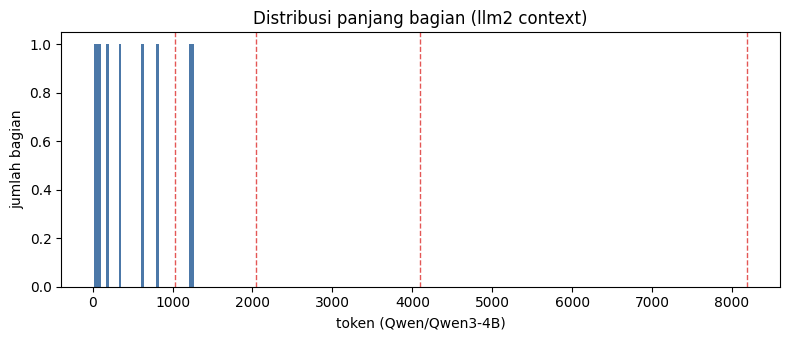

In [36]:
import csv
import numpy as np
TOKENIZER_ID = "Qwen/Qwen3-4B"
BATAS = [1024, 2048, 4096, 8192]
PAKAI_VLM = True

try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(TOKENIZER_ID)
    count = lambda s: len(tok(s, add_special_tokens=False)["input_ids"]); satuan = f"token ({TOKENIZER_ID})"
except Exception as e:
    print("tokenizer tidak bisa dimuat → pakai perkiraan karakter/3,5:", repr(e)[:150])
    count = lambda s: int(round(len(s) / 3.5)); satuan = "token (perkiraan karakter/3,5)"

rows, n_doc = [], 0
for p in PDFS:
    stem = Path(p).stem; f = Path(OUT_DIR) / "llm2" / f"{stem}.json"; fv = Path(OUT_DIR) / "llm2" / f"{stem}_vlm.json"
    f = fv if (PAKAI_VLM and fv.exists()) else f
    if not f.exists(): continue
    n_doc += 1
    for sec in json.loads(f.read_text(encoding="utf-8")):
        ctx = sec["context"]; tbl = "\n".join(l for l in ctx.split("\n") if l.startswith("|"))
        n = count(ctx) if ctx else 0; nt = count(tbl) if tbl else 0
        rows.append({"file": f.name, "section_title": sec["section_title"], "tokens": n, "chars": len(ctx), "table_tokens": nt,
                     "table_share": round(nt / n, 2) if n else 0.0})

if not rows:
    print("Belum ada hasil llm2 — jalankan 24.2 dulu.")
else:
    t = np.array([r["tokens"] for r in rows])
    print(f"Panjang context per bagian, satuan {satuan} — {len(rows)} bagian dari {n_doc} dokumen")
    print(f"  semua bagian: median {int(np.median(t)):,} · p90 {int(np.percentile(t, 90)):,} · p95 {int(np.percentile(t, 95)):,} · maks {t.max():,}"
          f" · kosong (judul ada, isi kosong) {(t == 0).sum()}")
    for b in BATAS: print(f"  > {b:,} token: {(t > b).sum()} bagian ({(t > b).mean():.0%})")
    print("\nPer bagian (dokumen yang judulnya ditemukan · median · p90 · maks):")
    for title in dict.fromkeys(r["section_title"] for r in rows):
        ts = np.array([r["tokens"] for r in rows if r["section_title"] == title])
        print(f"  {title:<34} {len(ts):>4} dok · {int(np.median(ts)):>6,} · {int(np.percentile(ts, 90)):>6,} · {ts.max():>6,}")
    print("\n10 bagian terpanjang (porsi tabel = bagian context berupa tabel markdown):")
    for r in sorted(rows, key=lambda r: -r["tokens"])[:10]:
        print(f"  {r['tokens']:>7,}  tabel {r['table_share']:>4.0%}  {r['section_title']} — {r['file']}")
    with open(Path(OUT_DIR) / "llm2" / "_panjang.csv", "w", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    print("\ntabel lengkap:", os.path.abspath(Path(OUT_DIR) / "llm2" / "_panjang.csv"))
    try:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(8, 3.5)); plt.hist(t, bins=40, color="#4C78A8")
        for b in BATAS: plt.axvline(b, color="#E45756", ls="--", lw=1)
        plt.xlabel(satuan); plt.ylabel("jumlah bagian"); plt.title("Distribusi panjang bagian (llm2 context)"); plt.tight_layout(); plt.show()
    except Exception:
        print("(histogram dilewati — pasang matplotlib)")

### 24.5 Bahan dataset SFT (penilaian kelogisan)
Satu baris per butir I.M.1–I.R per dokumen → `sft/bahan.jsonl` (`export_sft_material`, bagian 20): isi bagian (sama dengan llm2), status aturan
(`present`, `label_found`, `di_dalam_induk`), dan identitas (Kegiatan, Rincian Output, volume, satuan) untuk kriteria "terkait RO".
Unggah berkas ini sebagai dataset Kaggle **Private** untuk notebook `tor_sft_dataset_kaggle.ipynb`. Berisi isi TOR — jangan dibagikan.

In [37]:
info = export_sft_material(OUT_DIR, use_vlm=PAKAI_VLM)
print(f"{info['records']} butir dari {info['documents']} dokumen → {os.path.abspath(info['path'])}")
print(f"  dikirim ke model (judul ada, isi ada; letak di dalam/luar induk tidak berpengaruh): {info['to_model']}")
print(f"  sub-butir di luar bagian induknya (dinilai model; induk I.M.1 / I.O.1 tidak lolos): {info['outside_parent'] or 'tidak ada'}")
for f, e in info["errors"]: print("  gagal:", f, e)

10 butir dari 1 dokumen → d:\AITF 2\output_json\sft\bahan.jsonl
  dikirim ke model (judul ada, isi ada; letak di dalam/luar induk tidak berpengaruh): 9
  sub-butir di luar bagian induknya (dinilai model; induk I.M.1 / I.O.1 tidak lolos): tidak ada


### 24.6 Kemas hasil

In [38]:
import shutil
zip_path = shutil.make_archive("hasil_tor", "zip", OUT_DIR)
print("hasil:", os.path.abspath(OUT_DIR), "| zip:", zip_path)
if os.name == "nt":
    os.startfile(os.path.abspath(OUT_DIR))          # buka di File Explorer

hasil: d:\AITF 2\output_json | zip: d:\AITF 2\hasil_tor.zip
